In [ ]:
# ============================================================
# CELL 1 — SETUP AND REPRODUCIBILITY
# PHEME Final Revision: Strict LOEO Experiment
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import random
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# More deterministic CUDA behaviour
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("Random seed:", SEED)

# ------------------------------------------------------------
# Project directories
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/PHEME"

RESULTS_DIR = os.path.join(BASE_DIR, "Final_Revision_Results")
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Results directory:")
print(RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
PyTorch version: 2.11.0+cu128
Random seed: 42
Results directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 2 — LOAD AND VALIDATE DEFINITIVE CASCADE DATASET
# ============================================================

import os
import pandas as pd

PKL_PATH = os.path.join(BASE_DIR, "filtered_threads_ge5.pkl")

# Load definitive ≥5-node cascade dataset
df = pd.read_pickle(PKL_PATH).copy()

print("=" * 70)
print("PHEME FINAL DATASET INTEGRITY CHECK")
print("=" * 70)

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\nEvent distribution:")
print(df["event"].value_counts())

print("\nEvent × Label distribution:")
event_label_table = pd.crosstab(df["event"], df["label"])
print(event_label_table)

print("\nMinimum / Maximum number of nodes:")
print("Minimum:", df["num_nodes"].min())
print("Maximum:", df["num_nodes"].max())

print("\nMinimum / Maximum number of edges:")
print("Minimum:", df["num_edges"].min())
print("Maximum:", df["num_edges"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate event-thread combinations:")
duplicates = df.duplicated(
    subset=["event", "thread_id"]
).sum()
print(duplicates)

print("\nDuplicate thread IDs irrespective of event:")
duplicate_thread_ids = df["thread_id"].astype(str).duplicated().sum()
print(duplicate_thread_ids)

# ------------------------------------------------------------
# Assertions — stop immediately if the definitive dataset
# differs from the manuscript dataset.
# ------------------------------------------------------------

assert len(df) == 4072, \
    f"Expected 4072 cascades, found {len(df)}"

assert set(df["label"].unique()) == {0, 1}, \
    "Unexpected labels found."

assert (df["num_nodes"] >= 5).all(), \
    "Dataset contains cascades with fewer than 5 nodes."

assert duplicates == 0, \
    "Duplicate event-thread combinations detected."

expected_event_counts = {
    "charliehebdo-all-rnr-threads": 1801,
    "ferguson-all-rnr-threads": 926,
    "germanwings-crash-all-rnr-threads": 264,
    "sydneysiege-all-rnr-threads": 1081
}

actual_event_counts = df["event"].value_counts().to_dict()

assert actual_event_counts == expected_event_counts, \
    f"Event counts do not match expected values: {actual_event_counts}"

expected_label_counts = {
    0: 2851,
    1: 1221
}

actual_label_counts = df["label"].value_counts().to_dict()

assert actual_label_counts == expected_label_counts, \
    f"Label counts do not match expected values: {actual_label_counts}"

print("\n" + "=" * 70)
print("ALL CORE DATASET CHECKS PASSED")
print("=" * 70)

PHEME FINAL DATASET INTEGRITY CHECK

Dataset shape:
(4072, 7)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'nodes', 'edges']

Label distribution:
label
0    2851
1    1221
Name: count, dtype: int64

Event distribution:
event
charliehebdo-all-rnr-threads         1801
sydneysiege-all-rnr-threads          1081
ferguson-all-rnr-threads              926
germanwings-crash-all-rnr-threads     264
Name: count, dtype: int64

Event × Label distribution:
label                                 0    1
event                                       
charliehebdo-all-rnr-threads       1412  389
ferguson-all-rnr-threads            683  243
germanwings-crash-all-rnr-threads   130  134
sydneysiege-all-rnr-threads         626  455

Minimum / Maximum number of nodes:
Minimum: 5
Maximum: 346

Minimum / Maximum number of edges:
Minimum: 3
Maximum: 345

Missing values:
event        0
thread_id    0
label        0
num_nodes    0
num_edges    0
nodes        0
edges        0
dtype: int64

Dup

In [ ]:
# ============================================================
# CELL 3 — COMPUTE TOPOLOGY DESCRIPTORS
# No topology classes are assigned in this cell.
# ============================================================

from collections import defaultdict, deque
import numpy as np
import pandas as pd


def compute_topology_descriptors(row):

    edges = [(str(u), str(v)) for u, v in row["edges"]]
    nodes = {str(n) for n in row["nodes"]}
    root = str(row["thread_id"])

    # Ensure root is represented
    nodes.add(root)

    # --------------------------------------------------------
    # Root-edge dominance
    # --------------------------------------------------------

    num_edges = len(edges)

    root_edges = sum(
        1 for u, v in edges
        if u == root
    )

    rd = root_edges / num_edges if num_edges > 0 else np.nan

    # --------------------------------------------------------
    # Directed adjacency list
    # --------------------------------------------------------

    adjacency = defaultdict(list)

    for u, v in edges:
        adjacency[u].append(v)

    # --------------------------------------------------------
    # Maximum directed depth from root using BFS
    # --------------------------------------------------------

    distances = {root: 0}
    queue = deque([root])

    while queue:
        current = queue.popleft()

        for child in adjacency[current]:
            if child not in distances:
                distances[child] = distances[current] + 1
                queue.append(child)

    max_depth = max(distances.values()) if distances else 0

    reachable_nodes = len(distances)

    return pd.Series({
        "root_edge_dominance": rd,
        "max_depth_recomputed": max_depth,
        "root_edges": root_edges,
        "reachable_nodes": reachable_nodes
    })


topology_descriptors = df.apply(
    compute_topology_descriptors,
    axis=1
)

df = pd.concat(
    [df.reset_index(drop=True),
     topology_descriptors.reset_index(drop=True)],
    axis=1
)

print("=" * 70)
print("TOPOLOGY DESCRIPTOR CHECK")
print("=" * 70)

print("\nRoot-edge dominance summary:")
print(df["root_edge_dominance"].describe())

print("\nMaximum depth summary:")
print(df["max_depth_recomputed"].describe())

print("\nRoot-edge dominance quantiles:")
print(
    df["root_edge_dominance"].quantile(
        [0, .05, .10, .20, .25, .30, .40, .50,
         .60, .70, .75, .80, .90, .95, 1.0]
    )
)

print("\nMaximum-depth frequency:")
print(
    df["max_depth_recomputed"]
    .value_counts()
    .sort_index()
)

print("\nReachability check:")
unreachable = (
    df["reachable_nodes"] != df["num_nodes"]
).sum()

print(
    "Cascades where reachable nodes != recorded nodes:",
    unreachable
)

print("\nRoot-edge dominance missing values:")
print(df["root_edge_dominance"].isna().sum())

print("\nRoot-edge dominance outside [0,1]:")
print(
    (
        (df["root_edge_dominance"] < 0) |
        (df["root_edge_dominance"] > 1)
    ).sum()
)

print("\n" + "=" * 70)
print("TOPOLOGY DESCRIPTORS COMPUTED — NO CLASSES ASSIGNED YET")
print("=" * 70)

TOPOLOGY DESCRIPTOR CHECK

Root-edge dominance summary:
count    4072.000000
mean        0.709754
std         0.270570
min         0.013333
25%         0.533333
50%         0.777778
75%         0.947368
max         1.000000
Name: root_edge_dominance, dtype: float64

Maximum depth summary:
count    4072.000000
mean        4.167485
std         4.181752
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        47.000000
Name: max_depth_recomputed, dtype: float64

Root-edge dominance quantiles:
0.00    0.013333
0.05    0.166667
0.10    0.282650
0.20    0.455303
0.25    0.533333
0.30    0.596585
0.40    0.695652
0.50    0.777778
0.60    0.846154
0.70    0.909091
0.75    0.947368
0.80    1.000000
0.90    1.000000
0.95    1.000000
1.00    1.000000
Name: root_edge_dominance, dtype: float64

Maximum-depth frequency:
max_depth_recomputed
1.0     966
2.0     926
3.0     626
4.0     389
5.0     273
6.0     175
7.0     119
8.0     113
9.0      88
10.0     68
11.

In [ ]:
# ============================================================
# CELL 4 — DIAGNOSE ROOT / REACHABILITY MISMATCHES
# ============================================================

from collections import Counter, defaultdict

problem_df = df[
    df["reachable_nodes"] != df["num_nodes"]
].copy()

print("=" * 75)
print("ROOT / REACHABILITY DIAGNOSTIC")
print("=" * 75)

print("\nNumber of affected cascades:")
print(len(problem_df))

print("\nAffected cascades by event:")
print(problem_df["event"].value_counts())

print("\nAffected cascades by label:")
print(problem_df["label"].value_counts().sort_index())


def inspect_roots(row):

    nodes = {str(n) for n in row["nodes"]}
    edges = [(str(u), str(v)) for u, v in row["edges"]]

    indegree = {n: 0 for n in nodes}

    for u, v in edges:
        indegree.setdefault(u, 0)
        indegree.setdefault(v, 0)
        indegree[v] += 1

    structural_roots = [
        n for n, deg in indegree.items()
        if deg == 0
    ]

    thread_id = str(row["thread_id"])

    return pd.Series({
        "thread_id_is_node": thread_id in nodes,
        "thread_id_is_structural_root": thread_id in structural_roots,
        "n_structural_roots": len(structural_roots),
        "structural_roots": structural_roots
    })


root_diagnostics = problem_df.apply(
    inspect_roots,
    axis=1
)

problem_df = pd.concat(
    [
        problem_df.reset_index(drop=True),
        root_diagnostics.reset_index(drop=True)
    ],
    axis=1
)

print("\nThread ID present as graph node:")
print(problem_df["thread_id_is_node"].value_counts())

print("\nThread ID identified as structural root:")
print(problem_df["thread_id_is_structural_root"].value_counts())

print("\nNumber of structural roots:")
print(
    problem_df["n_structural_roots"]
    .value_counts()
    .sort_index()
)

print("\nFirst 15 affected cascades:")
print(
    problem_df[
        [
            "event",
            "thread_id",
            "label",
            "num_nodes",
            "num_edges",
            "reachable_nodes",
            "root_edge_dominance",
            "max_depth_recomputed",
            "thread_id_is_structural_root",
            "n_structural_roots",
            "structural_roots"
        ]
    ].head(15).to_string(index=False)
)

print("\n" + "=" * 75)
print("DIAGNOSTIC COMPLETE")
print("=" * 75)

ROOT / REACHABILITY DIAGNOSTIC

Number of affected cascades:
74

Affected cascades by event:
event
charliehebdo-all-rnr-threads    43
ferguson-all-rnr-threads        26
sydneysiege-all-rnr-threads      5
Name: count, dtype: int64

Affected cascades by label:
label
0    52
1    22
Name: count, dtype: int64

Thread ID present as graph node:
thread_id_is_node
True    74
Name: count, dtype: int64

Thread ID identified as structural root:
thread_id_is_structural_root
True    74
Name: count, dtype: int64

Number of structural roots:
n_structural_roots
2     32
3     17
4     10
5      4
6      2
7      2
8      2
10     1
13     1
18     2
22     1
Name: count, dtype: int64

First 15 affected cascades:
                       event          thread_id  label  num_nodes  num_edges  reachable_nodes  root_edge_dominance  max_depth_recomputed  thread_id_is_structural_root  n_structural_roots                                                                                                            

In [ ]:
# ============================================================
# CELL 5 — SOURCE-ROOTED COMPONENT AUDIT
# ============================================================

import numpy as np
import pandas as pd

df["reachable_fraction"] = (
    df["reachable_nodes"] / df["num_nodes"]
)

affected = df[
    df["reachable_nodes"] != df["num_nodes"]
].copy()

print("=" * 70)
print("SOURCE-ROOTED COMPONENT AUDIT")
print("=" * 70)

print("\nTotal cascades:", len(df))
print("Fully source-connected:",
      (df["reachable_nodes"] == df["num_nodes"]).sum())
print("Multiple/disconnected components:",
      len(affected))

print("\nPercentage affected:")
print(f"{100 * len(affected) / len(df):.2f}%")

print("\nReachable fraction among affected cascades:")
print(affected["reachable_fraction"].describe())

print("\nAffected cascades with <50% nodes reachable from source:")
print((affected["reachable_fraction"] < 0.50).sum())

print("\nAffected cascades with <75% nodes reachable from source:")
print((affected["reachable_fraction"] < 0.75).sum())

print("\nOverall relationship between Rd and depth:")
print(
    df[
        ["root_edge_dominance", "max_depth_recomputed"]
    ].corr(method="spearman")
)

print("\nMedian depth by Rd range:")

rd_bins = pd.cut(
    df["root_edge_dominance"],
    bins=[-0.001, 0.30, 0.80, 1.001],
    labels=[
        "Rd <= 0.30",
        "0.30 < Rd < 0.80",
        "Rd >= 0.80"
    ],
    include_lowest=True
)

print(
    df.groupby(
        rd_bins,
        observed=True
    )["max_depth_recomputed"].agg(
        ["count", "median", "mean", "min", "max"]
    )
)

print("\n" + "=" * 70)
print("AUDIT COMPLETE")
print("=" * 70)

SOURCE-ROOTED COMPONENT AUDIT

Total cascades: 4072
Fully source-connected: 3998
Multiple/disconnected components: 74

Percentage affected:
1.82%

Reachable fraction among affected cascades:
count    74.000000
mean      0.839742
std       0.187699
min       0.068966
25%       0.827899
50%       0.909091
75%       0.946637
max       0.985915
Name: reachable_fraction, dtype: float64

Affected cascades with <50% nodes reachable from source:
5

Affected cascades with <75% nodes reachable from source:
14

Overall relationship between Rd and depth:
                      root_edge_dominance  max_depth_recomputed
root_edge_dominance              1.000000             -0.932208
max_depth_recomputed            -0.932208              1.000000

Median depth by Rd range:
                     count  median       mean  min   max
root_edge_dominance                                     
Rd <= 0.30             461    11.0  12.303688  1.0  47.0
0.30 < Rd < 0.80      1754     4.0   4.739453  2.0  19.0
Rd >

In [ ]:
# ============================================================
# CELL 6 — VERIFY FINAL Rd THRESHOLD COUNTS
# ============================================================

print("=" * 65)
print("EXPLICIT Rd THRESHOLD CHECK")
print("=" * 65)

n_chain = (df["root_edge_dominance"] <= 0.30).sum()

n_star = (df["root_edge_dominance"] >= 0.80).sum()

n_hybrid = (
    (df["root_edge_dominance"] > 0.30) &
    (df["root_edge_dominance"] < 0.80)
).sum()

n_exact_030 = np.isclose(
    df["root_edge_dominance"], 0.30
).sum()

n_exact_080 = np.isclose(
    df["root_edge_dominance"], 0.80
).sum()

print("\nExplicit classification counts:")
print("Star   :", n_star)
print("Hybrid :", n_hybrid)
print("Chain  :", n_chain)
print("Total  :", n_star + n_hybrid + n_chain)

print("\nBoundary cases:")
print("Exactly Rd = 0.30:", n_exact_030)
print("Exactly Rd = 0.80:", n_exact_080)

assert n_star + n_hybrid + n_chain == len(df)

print("\nCheck complete.")

EXPLICIT Rd THRESHOLD CHECK

Explicit classification counts:
Star   : 1950
Hybrid : 1661
Chain  : 461
Total  : 4072

Boundary cases:
Exactly Rd = 0.30: 7
Exactly Rd = 0.80: 93

Check complete.


In [ ]:
# ============================================================
# CELL 7 — FINAL TOPOLOGY CLASSIFICATION
# ============================================================

def assign_topology(rd):
    if rd >= 0.80:
        return "star"
    elif rd <= 0.30:
        return "chain"
    else:
        return "hybrid"


df["topology"] = df["root_edge_dominance"].apply(assign_topology)

print("=" * 70)
print("FINAL TOPOLOGY DISTRIBUTION")
print("=" * 70)

topology_counts = df["topology"].value_counts()

print("\nCounts:")
print(topology_counts)

print("\nPercentages:")
print((topology_counts / len(df) * 100).round(2))

# Assertions
assert topology_counts["star"] == 1950
assert topology_counts["hybrid"] == 1661
assert topology_counts["chain"] == 461
assert topology_counts.sum() == 4072

# ------------------------------------------------------------
# Structural description of each topology
# ------------------------------------------------------------

topology_characteristics = (
    df.groupby("topology")
      .agg(
          N=("thread_id", "count"),
          Rd_mean=("root_edge_dominance", "mean"),
          Rd_median=("root_edge_dominance", "median"),
          depth_mean=("max_depth_recomputed", "mean"),
          depth_median=("max_depth_recomputed", "median")
      )
      .round(4)
)

print("\nTopology characteristics:")
print(topology_characteristics)

# ------------------------------------------------------------
# Save topology assignments
# ------------------------------------------------------------

topology_save = df[
    [
        "event",
        "thread_id",
        "label",
        "num_nodes",
        "num_edges",
        "root_edge_dominance",
        "max_depth_recomputed",
        "topology"
    ]
].copy()

TOPOLOGY_PATH = os.path.join(
    RESULTS_DIR,
    "final_topology_labels.csv"
)

topology_save.to_csv(TOPOLOGY_PATH, index=False)

print("\nSaved:")
print(TOPOLOGY_PATH)

print("\n" + "=" * 70)
print("FINAL TOPOLOGY CLASSIFICATION VERIFIED")
print("=" * 70)

FINAL TOPOLOGY DISTRIBUTION

Counts:
topology
star      1950
hybrid    1661
chain      461
Name: count, dtype: int64

Percentages:
topology
star      47.89
hybrid    40.79
chain     11.32
Name: count, dtype: float64

Topology characteristics:
             N  Rd_mean  Rd_median  depth_mean  depth_median
topology                                                    
chain      461   0.1790     0.1786     12.3037          11.0
hybrid    1661   0.5906     0.6071      4.8663           4.0
star      1950   0.9367     0.9500      1.6487           2.0

Saved:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_topology_labels.csv

FINAL TOPOLOGY CLASSIFICATION VERIFIED


In [ ]:
# ============================================================
# CELL 8 — LOAD AND VALIDATE EVENT TEXT DATA
# ============================================================

import os
import pandas as pd

TEXT_FILES = {
    "charliehebdo-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_charliehebdo.csv"),

    "ferguson-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_ferguson.csv"),

    "germanwings-crash-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_germanwings.csv"),

    "sydneysiege-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_sydneysiege.csv")
}

text_frames = []

for expected_event, path in TEXT_FILES.items():

    temp = pd.read_csv(path)

    print("\n" + "=" * 70)
    print(expected_event)
    print("=" * 70)

    print("File:", path)
    print("Rows:", len(temp))
    print("Columns:", temp.columns.tolist())

    # Required columns
    required_cols = {"tweet_id", "text"}

    missing_cols = required_cols - set(temp.columns)

    assert not missing_cols, \
        f"Missing columns in {path}: {missing_cols}"

    # Standardise tweet IDs
    temp["tweet_id"] = temp["tweet_id"].astype(str)

    # Preserve event identity explicitly
    temp["source_event"] = expected_event

    print("Missing tweet IDs:", temp["tweet_id"].isna().sum())
    print("Missing text values:", temp["text"].isna().sum())
    print("Duplicate tweet IDs within file:",
          temp["tweet_id"].duplicated().sum())

    text_frames.append(temp)


# ------------------------------------------------------------
# Combine all four event text datasets
# ------------------------------------------------------------

df_text = pd.concat(
    text_frames,
    ignore_index=True
)

print("\n" + "=" * 70)
print("COMBINED TEXT DATA")
print("=" * 70)

print("\nTotal rows:")
print(len(df_text))

print("\nRows by source event:")
print(df_text["source_event"].value_counts())

print("\nDuplicate tweet IDs across combined data:")
print(df_text["tweet_id"].duplicated().sum())

print("\nMissing text values overall:")
print(df_text["text"].isna().sum())

# Fill genuinely missing text with empty string
df_text["text"] = df_text["text"].fillna("")

# ------------------------------------------------------------
# Build lookup
# ------------------------------------------------------------

text_lookup = dict(
    zip(
        df_text["tweet_id"],
        df_text["text"]
    )
)

print("\nUnique tweet IDs in lookup:")
print(len(text_lookup))

print("\n" + "=" * 70)
print("TEXT DATA LOADED SUCCESSFULLY")
print("=" * 70)


charliehebdo-all-rnr-threads
File: /content/drive/MyDrive/PHEME/pheme_event_charliehebdo.csv
Rows: 34790
Columns: ['tweet_id', 'text', 'label', 'event', 'type']
Missing tweet IDs: 0
Missing text values: 0
Duplicate tweet IDs within file: 0

ferguson-all-rnr-threads
File: /content/drive/MyDrive/PHEME/pheme_event_ferguson.csv
Rows: 24185
Columns: ['tweet_id', 'text', 'label', 'event', 'type']
Missing tweet IDs: 0
Missing text values: 0
Duplicate tweet IDs within file: 772

germanwings-crash-all-rnr-threads
File: /content/drive/MyDrive/PHEME/pheme_event_germanwings.csv
Rows: 4489
Columns: ['tweet_id', 'text', 'label', 'event', 'type']
Missing tweet IDs: 0
Missing text values: 0
Duplicate tweet IDs within file: 0

sydneysiege-all-rnr-threads
File: /content/drive/MyDrive/PHEME/pheme_event_sydneysiege.csv
Rows: 23996
Columns: ['tweet_id', 'text', 'label', 'event', 'type']
Missing tweet IDs: 0
Missing text values: 0
Duplicate tweet IDs within file: 0

COMBINED TEXT DATA

Total rows:
87460

R

In [ ]:
# ============================================================
# CELL 9 — AUDIT DUPLICATE TWEET IDs
# ============================================================

duplicate_mask = df_text["tweet_id"].duplicated(
    keep=False
)

df_duplicates = df_text[
    duplicate_mask
].copy()

print("=" * 70)
print("DUPLICATE TWEET-ID AUDIT")
print("=" * 70)

print("\nRows involved in duplicate IDs:")
print(len(df_duplicates))

print("\nNumber of unique duplicated tweet IDs:")
print(df_duplicates["tweet_id"].nunique())

print("\nDuplicates by source event:")
print(
    df_duplicates["source_event"].value_counts()
)

# ------------------------------------------------------------
# Check whether duplicated IDs have conflicting text
# ------------------------------------------------------------

text_variation = (
    df_duplicates
    .groupby("tweet_id")["text"]
    .nunique()
)

conflicting_text_ids = text_variation[
    text_variation > 1
]

print("\nDuplicated tweet IDs with different text:")
print(len(conflicting_text_ids))

# ------------------------------------------------------------
# Check label consistency if label exists
# ------------------------------------------------------------

if "label" in df_duplicates.columns:

    label_variation = (
        df_duplicates
        .groupby("tweet_id")["label"]
        .nunique()
    )

    conflicting_label_ids = label_variation[
        label_variation > 1
    ]

    print("\nDuplicated tweet IDs with different labels:")
    print(len(conflicting_label_ids))

# ------------------------------------------------------------
# Check event/type consistency
# ------------------------------------------------------------

if "event" in df_duplicates.columns:

    event_variation = (
        df_duplicates
        .groupby("tweet_id")["event"]
        .nunique()
    )

    print("\nDuplicated tweet IDs with different event values:")
    print((event_variation > 1).sum())

if "type" in df_duplicates.columns:

    type_variation = (
        df_duplicates
        .groupby("tweet_id")["type"]
        .nunique()
    )

    print("\nDuplicated tweet IDs with different type values:")
    print((type_variation > 1).sum())


# ------------------------------------------------------------
# Show a few duplicate examples
# ------------------------------------------------------------

print("\nExample duplicated records:")

example_ids = (
    df_duplicates["tweet_id"]
    .drop_duplicates()
    .head(5)
)

print(
    df_duplicates[
        df_duplicates["tweet_id"].isin(example_ids)
    ][
        [
            "tweet_id",
            "text",
            "label",
            "event",
            "type",
            "source_event"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("DUPLICATE AUDIT COMPLETE")
print("=" * 70)

DUPLICATE TWEET-ID AUDIT

Rows involved in duplicate IDs:
1544

Number of unique duplicated tweet IDs:
772

Duplicates by source event:
source_event
ferguson-all-rnr-threads    1544
Name: count, dtype: int64

Duplicated tweet IDs with different text:
0

Duplicated tweet IDs with different labels:
0

Duplicated tweet IDs with different event values:
0

Duplicated tweet IDs with different type values:
772

Example duplicated records:
          tweet_id                                                                                                                                        text  label                    event     type             source_event
500404132394459136           MSNBC is literally reporting that Police Chief CLEARLY said it was about jay walking. \n\nThis is a fucking clown show. #Ferguson      1 ferguson-all-rnr-threads   source ferguson-all-rnr-threads
500404132394459136           MSNBC is literally reporting that Police Chief CLEARLY said it was about jay walking.

In [ ]:
# ============================================================
# CELL 10 — MAP AVAILABLE TEXT TO THE 4,072 GRAPH CASCADES
# ============================================================

# ------------------------------------------------------------
# 1. Create deterministic unique tweet-text table
# ------------------------------------------------------------

df_text_unique = (
    df_text[["tweet_id", "text"]]
    .drop_duplicates(subset="tweet_id", keep="first")
    .copy()
)

assert len(df_text_unique) == 86688

text_lookup = dict(
    zip(
        df_text_unique["tweet_id"],
        df_text_unique["text"]
    )
)

print("=" * 70)
print("GRAPH-NODE TEXT COVERAGE AUDIT")
print("=" * 70)

print("\nUnique text records available:")
print(len(text_lookup))


# ------------------------------------------------------------
# 2. Audit every node in every retained cascade
# ------------------------------------------------------------

coverage_records = []

total_graph_nodes = 0
nodes_with_text = 0
nodes_without_text = 0

for idx, row in df.iterrows():

    # Deterministic node representation
    node_ids = [str(node) for node in row["nodes"]]

    n_total = len(node_ids)

    available = sum(
        node_id in text_lookup
        for node_id in node_ids
    )

    missing = n_total - available

    total_graph_nodes += n_total
    nodes_with_text += available
    nodes_without_text += missing

    coverage_records.append({
        "event": row["event"],
        "thread_id": str(row["thread_id"]),
        "label": row["label"],
        "num_nodes": n_total,
        "nodes_with_text": available,
        "nodes_without_text": missing,
        "text_coverage":
            available / n_total if n_total > 0 else 0
    })


coverage_df = pd.DataFrame(coverage_records)


# ------------------------------------------------------------
# 3. Overall coverage
# ------------------------------------------------------------

print("\nTotal graph-node occurrences:")
print(total_graph_nodes)

print("\nGraph-node occurrences WITH text:")
print(nodes_with_text)

print("\nGraph-node occurrences WITHOUT text:")
print(nodes_without_text)

print("\nOverall text coverage (%):")
print(
    round(
        100 * nodes_with_text / total_graph_nodes,
        4
    )
)


# ------------------------------------------------------------
# 4. Cascade-level coverage
# ------------------------------------------------------------

print("\nCascades with complete text coverage:")
print(
    (coverage_df["nodes_without_text"] == 0).sum()
)

print("\nCascades with at least one missing text node:")
print(
    (coverage_df["nodes_without_text"] > 0).sum()
)

print("\nMean cascade-level text coverage:")
print(
    round(
        coverage_df["text_coverage"].mean(),
        6
    )
)


# ------------------------------------------------------------
# 5. Event-wise coverage
# ------------------------------------------------------------

event_coverage = (
    coverage_df
    .groupby("event")
    .agg(
        cascades=("thread_id", "count"),
        graph_nodes=("num_nodes", "sum"),
        nodes_with_text=("nodes_with_text", "sum"),
        nodes_without_text=("nodes_without_text", "sum"),
        mean_cascade_coverage=("text_coverage", "mean")
    )
)

event_coverage["node_text_coverage_pct"] = (
    100
    * event_coverage["nodes_with_text"]
    / event_coverage["graph_nodes"]
)

print("\n" + "=" * 70)
print("EVENT-WISE TEXT COVERAGE")
print("=" * 70)

print(
    event_coverage.round(4)
)


# ------------------------------------------------------------
# 6. Distribution of missing text
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MISSING-TEXT DISTRIBUTION")
print("=" * 70)

print("\nCascades by number of missing-text nodes:")

print(
    coverage_df["nodes_without_text"]
    .value_counts()
    .sort_index()
    .head(20)
)


# ------------------------------------------------------------
# 7. Save audit
# ------------------------------------------------------------

COVERAGE_PATH = os.path.join(
    RESULTS_DIR,
    "graph_node_text_coverage.csv"
)

coverage_df.to_csv(
    COVERAGE_PATH,
    index=False
)

print("\nSaved:")
print(COVERAGE_PATH)

print("\n" + "=" * 70)
print("GRAPH-NODE TEXT COVERAGE AUDIT COMPLETE")
print("=" * 70)

GRAPH-NODE TEXT COVERAGE AUDIT

Unique text records available:
86688

Total graph-node occurrences:
85749

Graph-node occurrences WITH text:
82446

Graph-node occurrences WITHOUT text:
3303

Overall text coverage (%):
96.1481

Cascades with complete text coverage:
3861

Cascades with at least one missing text node:
211

Mean cascade-level text coverage:
0.948183

EVENT-WISE TEXT COVERAGE
                                   cascades  graph_nodes  nodes_with_text  \
event                                                                       
charliehebdo-all-rnr-threads           1801        36629            33326   
ferguson-all-rnr-threads                926        22028            22028   
germanwings-crash-all-rnr-threads       264         3962             3962   
sydneysiege-all-rnr-threads            1081        23130            23130   

                                   nodes_without_text  mean_cascade_coverage  \
event                                                             

In [ ]:
# ============================================================
# CELL 11 — DEFINE AND VERIFY STRICT LOEO FOLDS
# ============================================================

EVENTS = sorted(df["event"].unique())

print("=" * 70)
print("STRICT LEAVE-ONE-EVENT-OUT (LOEO) FOLDS")
print("=" * 70)

loeo_summary = []

for fold_no, test_event in enumerate(EVENTS, start=1):

    train_mask = df["event"] != test_event
    test_mask  = df["event"] == test_event

    train_df = df.loc[train_mask].copy()
    test_df  = df.loc[test_mask].copy()

    train_events = sorted(train_df["event"].unique())
    test_events  = sorted(test_df["event"].unique())

    # --------------------------------------------------------
    # Safety checks
    # --------------------------------------------------------

    assert len(train_events) == 3
    assert len(test_events) == 1
    assert test_events[0] == test_event

    assert set(train_events).isdisjoint(set(test_events))

    assert len(train_df) + len(test_df) == len(df)

    assert set(train_df["thread_id"]).isdisjoint(
        set(test_df["thread_id"])
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    train_nr = int((train_df["label"] == 0).sum())
    train_r  = int((train_df["label"] == 1).sum())

    test_nr = int((test_df["label"] == 0).sum())
    test_r  = int((test_df["label"] == 1).sum())

    # --------------------------------------------------------
    # Store summary
    # --------------------------------------------------------

    loeo_summary.append({
        "fold": fold_no,
        "test_event": test_event,
        "train_graphs": len(train_df),
        "test_graphs": len(test_df),
        "train_non_rumour": train_nr,
        "train_rumour": train_r,
        "test_non_rumour": test_nr,
        "test_rumour": test_r
    })

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print(f"\nFOLD {fold_no}")
    print("-" * 70)

    print("Training events:")
    for event in train_events:
        print("  ", event)

    print("\nHeld-out test event:")
    print("  ", test_event)

    print("\nGraphs:")
    print("  Train:", len(train_df))
    print("  Test :", len(test_df))

    print("\nTraining labels:")
    print("  Non-rumour:", train_nr)
    print("  Rumour    :", train_r)

    print("\nTest labels:")
    print("  Non-rumour:", test_nr)
    print("  Rumour    :", test_r)


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

loeo_summary_df = pd.DataFrame(loeo_summary)

print("\n" + "=" * 70)
print("LOEO SUMMARY")
print("=" * 70)

print(
    loeo_summary_df.to_string(index=False)
)


# ------------------------------------------------------------
# Save split summary
# ------------------------------------------------------------

LOEO_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "strict_loeo_split_summary.csv"
)

loeo_summary_df.to_csv(
    LOEO_SUMMARY_PATH,
    index=False
)

print("\nSaved:")
print(LOEO_SUMMARY_PATH)

print("\n" + "=" * 70)
print("STRICT LOEO SPLITS VERIFIED")
print("=" * 70)

STRICT LEAVE-ONE-EVENT-OUT (LOEO) FOLDS

FOLD 1
----------------------------------------------------------------------
Training events:
   ferguson-all-rnr-threads
   germanwings-crash-all-rnr-threads
   sydneysiege-all-rnr-threads

Held-out test event:
   charliehebdo-all-rnr-threads

Graphs:
  Train: 2271
  Test : 1801

Training labels:
  Non-rumour: 1439
  Rumour    : 832

Test labels:
  Non-rumour: 1412
  Rumour    : 389

FOLD 2
----------------------------------------------------------------------
Training events:
   charliehebdo-all-rnr-threads
   germanwings-crash-all-rnr-threads
   sydneysiege-all-rnr-threads

Held-out test event:
   ferguson-all-rnr-threads

Graphs:
  Train: 3146
  Test : 926

Training labels:
  Non-rumour: 2168
  Rumour    : 978

Test labels:
  Non-rumour: 683
  Rumour    : 243

FOLD 3
----------------------------------------------------------------------
Training events:
   charliehebdo-all-rnr-threads
   ferguson-all-rnr-threads
   sydneysiege-all-rnr-threa

In [ ]:
# ============================================================
# CELL 12 — STRICT FOLD-SPECIFIC TF-IDF FITTING
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
import joblib
import os

print("=" * 75)
print("STRICT LOEO TF-IDF FITTING")
print("=" * 75)

# ------------------------------------------------------------
# Directory for fold-specific vectorizers
# ------------------------------------------------------------

VECTORIZER_DIR = os.path.join(
    RESULTS_DIR,
    "tfidf_vectorizers"
)

os.makedirs(
    VECTORIZER_DIR,
    exist_ok=True
)

# Store fitted vectorizers in memory
fold_vectorizers = {}

tfidf_summary = []


# ------------------------------------------------------------
# Fit ONE vectorizer per LOEO fold
# ------------------------------------------------------------

for fold_no, test_event in enumerate(EVENTS, start=1):

    train_events = [
        event
        for event in EVENTS
        if event != test_event
    ]

    print("\n" + "=" * 75)
    print(f"FOLD {fold_no}")
    print("=" * 75)

    print("Held-out event:")
    print(" ", test_event)

    print("\nTF-IDF fitting events:")
    for event in train_events:
        print(" ", event)

    # --------------------------------------------------------
    # IMPORTANT:
    # Select text ONLY from the three training events.
    # The held-out event contributes NOTHING to fit().
    # --------------------------------------------------------

    train_text_df = df_text[
        df_text["source_event"].isin(train_events)
    ][
        ["tweet_id", "text"]
    ].copy()

    # Duplicate Ferguson source/reaction records contain
    # identical text, so keep one text per tweet ID.
    train_text_df = (
        train_text_df
        .drop_duplicates(
            subset="tweet_id",
            keep="first"
        )
        .reset_index(drop=True)
    )

    train_texts = (
        train_text_df["text"]
        .fillna("")
        .astype(str)
        .tolist()
    )

    # --------------------------------------------------------
    # Safety check:
    # no held-out-event row is used in fitting
    # --------------------------------------------------------

    heldout_ids = set(
        df_text.loc[
            df_text["source_event"] == test_event,
            "tweet_id"
        ].astype(str)
    )

    training_ids = set(
        train_text_df["tweet_id"].astype(str)
    )

    overlapping_ids = (
        training_ids.intersection(heldout_ids)
    )

    print("\nUnique training-event text records:")
    print(len(train_text_df))

    print("Tweet IDs shared with held-out event:")
    print(len(overlapping_ids))

    # --------------------------------------------------------
    # Fit vectorizer ONLY on training-event text
    # --------------------------------------------------------

    vectorizer = TfidfVectorizer(
        max_features=5000,
        stop_words="english",
        norm="l2"
    )

    vectorizer.fit(train_texts)

    vocabulary_size = len(
        vectorizer.vocabulary_
    )

    feature_names = (
        vectorizer.get_feature_names_out()
    )

    print("\nVocabulary size:")
    print(vocabulary_size)

    print("\nFirst 20 vocabulary terms:")
    print(feature_names[:20])

    # --------------------------------------------------------
    # Store in memory
    # --------------------------------------------------------

    fold_vectorizers[test_event] = vectorizer

    # --------------------------------------------------------
    # Save fitted vectorizer
    # --------------------------------------------------------

    safe_event_name = (
        test_event
        .replace("-all-rnr-threads", "")
        .replace("-crash", "")
    )

    vectorizer_path = os.path.join(
        VECTORIZER_DIR,
        f"tfidf_train_without_{safe_event_name}.joblib"
    )

    joblib.dump(
        vectorizer,
        vectorizer_path
    )

    # --------------------------------------------------------
    # Save vocabulary for reproducibility
    # --------------------------------------------------------

    vocabulary_df = pd.DataFrame({
        "feature_index":
            range(vocabulary_size),

        "term":
            feature_names
    })

    vocabulary_path = os.path.join(
        VECTORIZER_DIR,
        f"vocabulary_without_{safe_event_name}.csv"
    )

    vocabulary_df.to_csv(
        vocabulary_path,
        index=False
    )

    # --------------------------------------------------------
    # Record summary
    # --------------------------------------------------------

    tfidf_summary.append({
        "fold": fold_no,
        "held_out_event": test_event,
        "training_events":
            " | ".join(train_events),
        "unique_training_texts":
            len(train_text_df),
        "shared_tweet_ids_with_test":
            len(overlapping_ids),
        "vocabulary_size":
            vocabulary_size,
        "max_features":
            5000
    })

    print("\nVectorizer saved:")
    print(vectorizer_path)

    print("Vocabulary saved:")
    print(vocabulary_path)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

tfidf_summary_df = pd.DataFrame(
    tfidf_summary
)

print("\n" + "=" * 75)
print("STRICT TF-IDF SUMMARY")
print("=" * 75)

print(
    tfidf_summary_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

TFIDF_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "strict_loeo_tfidf_summary.csv"
)

tfidf_summary_df.to_csv(
    TFIDF_SUMMARY_PATH,
    index=False
)

print("\nSaved:")
print(TFIDF_SUMMARY_PATH)

print("\n" + "=" * 75)
print("STRICT FOLD-SPECIFIC TF-IDF FITTING COMPLETE")
print("=" * 75)

STRICT LOEO TF-IDF FITTING

FOLD 1
Held-out event:
  charliehebdo-all-rnr-threads

TF-IDF fitting events:
  ferguson-all-rnr-threads
  germanwings-crash-all-rnr-threads
  sydneysiege-all-rnr-threads

Unique training-event text records:
51898
Tweet IDs shared with held-out event:
0

Vocabulary size:
5000

First 20 vocabulary terms:
['00' '000' '024601' '05jaylee' '09' '10' '100' '1000' '100m' '11' '12'
 '13' '1300' '135' '14' '140' '140elect' '142' '144' '148']

Vectorizer saved:
/content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/tfidf_train_without_charliehebdo.joblib
Vocabulary saved:
/content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/vocabulary_without_charliehebdo.csv

FOLD 2
Held-out event:
  ferguson-all-rnr-threads

TF-IDF fitting events:
  charliehebdo-all-rnr-threads
  germanwings-crash-all-rnr-threads
  sydneysiege-all-rnr-threads

Unique training-event text records:
63275
Tweet IDs shared with held-out event:
0

Vocabulary size:
5000

Fir

In [ ]:
# ============================================================
# INSTALL PYTORCH GEOMETRIC
# Run once in this Colab runtime
# ============================================================

!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 79.7 MB/s eta 0:00:00


In [ ]:
import torch
import torch_geometric

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

print("PyTorch version:", torch.__version__)
print("PyG version:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nPyTorch Geometric installation successful.")

PyTorch version: 2.11.0+cu128
PyG version: 2.8.0.post1
CUDA available: True
GPU: NVIDIA L4

PyTorch Geometric installation successful.


In [ ]:
# ============================================================
# CELL 13 — BUILD STRICT LOEO PYTORCH GEOMETRIC DATASETS
# ============================================================

from torch_geometric.data import Data
import torch
import os

print("=" * 75)
print("BUILDING STRICT LOEO PYTORCH GEOMETRIC DATASETS")
print("=" * 75)

# ------------------------------------------------------------
# Helper: deterministic sorting of tweet/node IDs
# ------------------------------------------------------------

def node_sort_key(node_id):
    node_id = str(node_id)

    try:
        return (0, int(node_id))
    except ValueError:
        return (1, node_id)


# ------------------------------------------------------------
# Helper: construct one PyG graph
# ------------------------------------------------------------

def build_pyg_graph(row, vectorizer):

    # Deterministic node ordering
    node_ids = sorted(
        [str(n) for n in row["nodes"]],
        key=node_sort_key
    )

    node_to_idx = {
        node_id: idx
        for idx, node_id in enumerate(node_ids)
    }

    # --------------------------------------------------------
    # Text in EXACTLY the same order as node_ids
    # Missing text -> empty string -> zero TF-IDF vector
    # --------------------------------------------------------

    node_texts = [
        text_lookup.get(node_id, "")
        for node_id in node_ids
    ]

    X_sparse = vectorizer.transform(node_texts)

    X = torch.tensor(
        X_sparse.toarray(),
        dtype=torch.float32
    )

    # --------------------------------------------------------
    # Edges mapped to deterministic node indices
    # --------------------------------------------------------

    mapped_edges = []

    for u, v in row["edges"]:

        u = str(u)
        v = str(v)

        if u in node_to_idx and v in node_to_idx:
            mapped_edges.append(
                [
                    node_to_idx[u],
                    node_to_idx[v]
                ]
            )

    if len(mapped_edges) > 0:

        edge_index = torch.tensor(
            mapped_edges,
            dtype=torch.long
        ).t().contiguous()

    else:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    # --------------------------------------------------------
    # Label
    # --------------------------------------------------------

    y = torch.tensor(
        [int(row["label"])],
        dtype=torch.long
    )

    # --------------------------------------------------------
    # PyG object
    # --------------------------------------------------------

    graph = Data(
        x=X,
        edge_index=edge_index,
        y=y
    )

    # Metadata
    graph.event = str(row["event"])
    graph.thread_id = str(row["thread_id"])
    graph.topology = str(row["topology"])
    graph.root_edge_dominance = float(
        row["root_edge_dominance"]
    )
    graph.max_depth = int(
        row["max_depth_recomputed"]
    )

    return graph


# ------------------------------------------------------------
# Build all four folds
# ------------------------------------------------------------

strict_loeo_graphs = {}

build_summary = []

for fold_no, test_event in enumerate(EVENTS, start=1):

    print("\n" + "=" * 75)
    print(f"FOLD {fold_no}: HELD OUT = {test_event}")
    print("=" * 75)

    vectorizer = fold_vectorizers[test_event]

    train_rows = df[
        df["event"] != test_event
    ]

    test_rows = df[
        df["event"] == test_event
    ]

    train_graphs = []
    test_graphs = []

    # --------------------------------------------------------
    # Training graphs
    # --------------------------------------------------------

    print("\nBuilding training graphs...")

    for _, row in train_rows.iterrows():

        graph = build_pyg_graph(
            row,
            vectorizer
        )

        train_graphs.append(graph)

    # --------------------------------------------------------
    # Test graphs
    # --------------------------------------------------------

    print("Building held-out test graphs...")

    for _, row in test_rows.iterrows():

        graph = build_pyg_graph(
            row,
            vectorizer
        )

        test_graphs.append(graph)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    assert len(train_graphs) == len(train_rows)
    assert len(test_graphs) == len(test_rows)

    assert all(
        g.x.shape[1] == 5000
        for g in train_graphs
    )

    assert all(
        g.x.shape[1] == 5000
        for g in test_graphs
    )

    # Verify node counts
    assert all(
        g.x.shape[0] == int(row["num_nodes"])
        for g, (_, row) in zip(
            train_graphs,
            train_rows.iterrows()
        )
    )

    assert all(
        g.x.shape[0] == int(row["num_nodes"])
        for g, (_, row) in zip(
            test_graphs,
            test_rows.iterrows()
        )
    )

    # --------------------------------------------------------
    # Store fold
    # --------------------------------------------------------

    strict_loeo_graphs[test_event] = {
        "train": train_graphs,
        "test": test_graphs
    }

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------

    train_nodes = sum(
        g.num_nodes
        for g in train_graphs
    )

    test_nodes = sum(
        g.num_nodes
        for g in test_graphs
    )

    train_edges = sum(
        g.num_edges
        for g in train_graphs
    )

    test_edges = sum(
        g.num_edges
        for g in test_graphs
    )

    train_zero_feature_nodes = sum(
        int((g.x.abs().sum(dim=1) == 0).sum())
        for g in train_graphs
    )

    test_zero_feature_nodes = sum(
        int((g.x.abs().sum(dim=1) == 0).sum())
        for g in test_graphs
    )

    print("\nTrain graphs :", len(train_graphs))
    print("Test graphs  :", len(test_graphs))

    print("\nTrain nodes  :", train_nodes)
    print("Test nodes   :", test_nodes)

    print("\nTrain edges  :", train_edges)
    print("Test edges   :", test_edges)

    print(
        "\nTrain zero-feature nodes:",
        train_zero_feature_nodes
    )

    print(
        "Test zero-feature nodes :",
        test_zero_feature_nodes
    )

    build_summary.append({
        "fold": fold_no,
        "held_out_event": test_event,
        "train_graphs": len(train_graphs),
        "test_graphs": len(test_graphs),
        "train_nodes": train_nodes,
        "test_nodes": test_nodes,
        "train_edges": train_edges,
        "test_edges": test_edges,
        "train_zero_feature_nodes":
            train_zero_feature_nodes,
        "test_zero_feature_nodes":
            test_zero_feature_nodes
    })


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

build_summary_df = pd.DataFrame(
    build_summary
)

print("\n" + "=" * 75)
print("STRICT LOEO GRAPH-BUILD SUMMARY")
print("=" * 75)

print(
    build_summary_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

GRAPH_BUILD_PATH = os.path.join(
    RESULTS_DIR,
    "strict_loeo_graph_build_summary.csv"
)

build_summary_df.to_csv(
    GRAPH_BUILD_PATH,
    index=False
)

print("\nSaved:")
print(GRAPH_BUILD_PATH)

print("\n" + "=" * 75)
print("STRICT LOEO GRAPH CONSTRUCTION COMPLETE")
print("=" * 75)

BUILDING STRICT LOEO PYTORCH GEOMETRIC DATASETS

FOLD 1: HELD OUT = charliehebdo-all-rnr-threads

Building training graphs...
Building held-out test graphs...

Train graphs : 2271
Test graphs  : 1801

Train nodes  : 49120
Test nodes   : 36629

Train edges  : 46770
Test edges   : 34683

Train zero-feature nodes: 250
Test zero-feature nodes : 4400

FOLD 2: HELD OUT = ferguson-all-rnr-threads

Building training graphs...
Building held-out test graphs...

Train graphs : 3146
Test graphs  : 926

Train nodes  : 63721
Test nodes   : 22028

Train edges  : 60416
Test edges   : 21037

Train zero-feature nodes: 3788
Test zero-feature nodes : 553

FOLD 3: HELD OUT = germanwings-crash-all-rnr-threads

Building training graphs...
Building held-out test graphs...

Train graphs : 3808
Test graphs  : 264

Train nodes  : 81787
Test nodes   : 3962

Train edges  : 77755
Test edges   : 3698

Train zero-feature nodes: 4091
Test zero-feature nodes : 187

FOLD 4: HELD OUT = sydneysiege-all-rnr-threads

Buildi

In [ ]:
# ============================================================
# CELL 14 — DEFINE THE FIVE GNN MODELS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import (
    GCNConv,
    GATConv,
    SAGEConv,
    global_mean_pool
)

INPUT_DIM = 5000
NUM_CLASSES = 2
DROPOUT = 0.5


# ============================================================
# 1. GCN
# ============================================================

class GCNModel(nn.Module):

    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 2. GAT
# ============================================================

class GATModel(nn.Module):

    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=64,
        heads=4,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ):
        super().__init__()

        self.gat1 = GATConv(
            input_dim,
            hidden_dim,
            heads=heads,
            concat=True,
            dropout=dropout
        )

        self.gat2 = GATConv(
            hidden_dim * heads,
            hidden_dim,
            heads=1,
            concat=False,
            dropout=dropout
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        x = self.gat1(
            x,
            edge_index
        )

        x = F.elu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.gat2(
            x,
            edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 3. GraphSAGE
# ============================================================

class GraphSAGEModel(nn.Module):

    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ):
        super().__init__()

        self.sage1 = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.sage2 = SAGEConv(
            hidden_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        x = self.sage1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.sage2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 4. HYBRID GCN + GAT
# Sequential architecture:
# GCN -> GAT -> graph pooling -> classifier
# ============================================================

class HybridGCNGAT(nn.Module):

    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=128,
        heads=4,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ):
        super().__init__()

        self.gcn = GCNConv(
            input_dim,
            hidden_dim
        )

        self.gat = GATConv(
            hidden_dim,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        x = self.gcn(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.gat(
            x,
            edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 5. HYBRID GCN + GRAPHSAGE
# Parallel architecture:
# GCN branch + GraphSAGE branch -> concatenate -> classifier
# ============================================================

class HybridGCNSAGE(nn.Module):

    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=128,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ):
        super().__init__()

        # GCN branch
        self.gcn = GCNConv(
            input_dim,
            hidden_dim
        )

        # GraphSAGE branch
        self.sage = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        # GCN branch
        x_gcn = self.gcn(
            x,
            edge_index
        )

        x_gcn = F.relu(x_gcn)

        # GraphSAGE branch
        x_sage = self.sage(
            x,
            edge_index
        )

        x_sage = F.relu(x_sage)

        # Concatenate node representations
        x = torch.cat(
            [x_gcn, x_sage],
            dim=1
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Graph-level representation
        x = global_mean_pool(
            x,
            batch
        )

        return self.classifier(x)


# ============================================================
# MODEL REGISTRY
# ============================================================

MODEL_CLASSES = {
    "GCN": GCNModel,
    "GAT": GATModel,
    "GraphSAGE": GraphSAGEModel,
    "Hybrid_GCN_GAT": HybridGCNGAT,
    "Hybrid_GCN_GraphSAGE": HybridGCNSAGE
}


# ============================================================
# QUICK INSTANTIATION CHECK
# ============================================================

print("=" * 75)
print("MODEL DEFINITION CHECK")
print("=" * 75)

for model_name, model_class in MODEL_CLASSES.items():

    model = model_class()

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(
        f"{model_name:24s} "
        f"Total parameters = {total_params:,} | "
        f"Trainable = {trainable_params:,}"
    )

print("\nAll five model architectures defined successfully.")

MODEL DEFINITION CHECK
GCN                      Total parameters = 656,898 | Trainable = 656,898
GAT                      Total parameters = 1,297,474 | Trainable = 1,297,474
GraphSAGE                Total parameters = 1,313,282 | Trainable = 1,313,282
Hybrid_GCN_GAT           Total parameters = 707,074 | Trainable = 707,074
Hybrid_GCN_GraphSAGE     Total parameters = 1,920,770 | Trainable = 1,920,770

All five model architectures defined successfully.


In [ ]:
# ============================================================
# CELL 15 — TRAINING AND EVALUATION FUNCTIONS
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# FINAL TRAINING CONFIGURATION
# ============================================================

EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.005
WEIGHT_DECAY = 5e-4
BASE_SEED = 42


# ============================================================
# REPRODUCIBILITY
# ============================================================

def reset_seed(seed=BASE_SEED):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


# ============================================================
# CREATE SEEDED DATALOADER
# ============================================================

def make_train_loader(
    graphs,
    batch_size=BATCH_SIZE,
    seed=BASE_SEED
):

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        graphs,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )


def make_test_loader(
    graphs,
    batch_size=BATCH_SIZE
):

    return DataLoader(
        graphs,
        batch_size=batch_size,
        shuffle=False
    )


# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    total_loss = 0.0
    total_graphs = 0

    for batch in loader:

        batch = batch.to(device)

        optimizer.zero_grad()

        logits = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        y = batch.y.view(-1)

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        batch_size = y.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_graphs += batch_size

    return (
        total_loss / total_graphs
    )


# ============================================================
# PREDICT ON A DATASET
# ============================================================

@torch.no_grad()
def predict(
    model,
    loader,
    device
):

    model.eval()

    y_true = []
    y_pred = []

    for batch in loader:

        batch = batch.to(device)

        logits = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        predictions = (
            logits.argmax(dim=1)
        )

        y_true.extend(
            batch.y
            .view(-1)
            .cpu()
            .numpy()
            .tolist()
        )

        y_pred.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

    return (
        np.asarray(y_true),
        np.asarray(y_pred)
    )


# ============================================================
# METRIC CALCULATION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# ============================================================
# COMPLETE TRAIN + TEST FUNCTION
# ============================================================

def train_and_evaluate_model(
    model_class,
    model_name,
    train_graphs,
    test_graphs,
    test_event,
    fold_no,
    device,
    seed=BASE_SEED,
    epochs=EPOCHS
):

    # --------------------------------------------------------
    # Reset random state BEFORE every independent experiment
    # --------------------------------------------------------

    reset_seed(seed)

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = model_class().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()

    # --------------------------------------------------------
    # Loaders
    # --------------------------------------------------------

    train_loader = make_train_loader(
        train_graphs,
        seed=seed
    )

    test_loader = make_test_loader(
        test_graphs
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    losses = []

    for epoch in range(1, epochs + 1):

        loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        losses.append(loss)

        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == epochs
        ):

            print(
                f"{model_name:24s} | "
                f"Fold {fold_no} | "
                f"Epoch {epoch:02d}/{epochs} | "
                f"Loss = {loss:.6f}"
            )

    # --------------------------------------------------------
    # Held-out-event prediction
    # --------------------------------------------------------

    y_true, y_pred = predict(
        model,
        test_loader,
        device
    )

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Sanity checks
    # --------------------------------------------------------

    assert len(y_true) == len(test_graphs)
    assert len(y_pred) == len(test_graphs)

    expected_labels = np.asarray([
        int(g.y.item())
        for g in test_graphs
    ])

    assert np.array_equal(
        y_true,
        expected_labels
    )

    # --------------------------------------------------------
    # Prediction-level dataframe
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "fold": fold_no,

        "model": model_name,

        "event": [
            g.event
            for g in test_graphs
        ],

        "thread_id": [
            g.thread_id
            for g in test_graphs
        ],

        "topology": [
            g.topology
            for g in test_graphs
        ],

        "true_label":
            y_true.astype(int),

        "predicted_label":
            y_pred.astype(int)
    })

    # --------------------------------------------------------
    # Result row
    # --------------------------------------------------------

    result = {
        "fold": fold_no,
        "model": model_name,
        "test_event": test_event,
        "seed": seed,
        "epochs": epochs,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "test_n": len(test_graphs),
        **metrics
    }

    return (
        model,
        result,
        prediction_df,
        losses
    )


# ============================================================
# DISPLAY CONFIGURATION
# ============================================================

print("=" * 75)
print("FINAL TRAINING PROTOCOL")
print("=" * 75)

print("Device             :", device)
print("Epochs             :", EPOCHS)
print("Batch size         :", BATCH_SIZE)
print("Learning rate      :", LEARNING_RATE)
print("Weight decay       :", WEIGHT_DECAY)
print("Loss               : Unweighted CrossEntropyLoss")
print("Base seed          :", BASE_SEED)

print("\nReported held-out metrics:")
print("  Accuracy")
print("  Macro-F1")
print("  Weighted-F1")
print("  Balanced Accuracy")
print("  Confusion Matrix (TN, FP, FN, TP)")

print("\nPrediction-level metadata:")
print("  event")
print("  thread_id")
print("  topology")
print("  true_label")
print("  predicted_label")

print("\nTraining/evaluation functions defined successfully.")

FINAL TRAINING PROTOCOL
Device             : cuda
Epochs             : 50
Batch size         : 32
Learning rate      : 0.005
Weight decay       : 0.0005
Loss               : Unweighted CrossEntropyLoss
Base seed          : 42

Reported held-out metrics:
  Accuracy
  Macro-F1
  Weighted-F1
  Balanced Accuracy
  Confusion Matrix (TN, FP, FN, TP)

Prediction-level metadata:
  event
  thread_id
  topology
  true_label
  predicted_label

Training/evaluation functions defined successfully.


In [ ]:
# ============================================================
# CELL 16 — SMOKE TEST
# GCN with Germanwings as the held-out event
# ============================================================

SMOKE_TEST_EVENT = "germanwings-crash-all-rnr-threads"
SMOKE_TEST_FOLD = 3

print("=" * 75)
print("SMOKE TEST: GCN — HELD-OUT GERMANWINGS")
print("=" * 75)

smoke_train_graphs = strict_loeo_graphs[
    SMOKE_TEST_EVENT
]["train"]

smoke_test_graphs = strict_loeo_graphs[
    SMOKE_TEST_EVENT
]["test"]

print("\nTraining graphs:", len(smoke_train_graphs))
print("Test graphs    :", len(smoke_test_graphs))
print("Device         :", device)

smoke_model, smoke_result, smoke_predictions, smoke_losses = (
    train_and_evaluate_model(
        model_class=GCNModel,
        model_name="GCN",
        train_graphs=smoke_train_graphs,
        test_graphs=smoke_test_graphs,
        test_event=SMOKE_TEST_EVENT,
        fold_no=SMOKE_TEST_FOLD,
        device=device,
        seed=BASE_SEED,
        epochs=EPOCHS
    )
)

print("\n" + "=" * 75)
print("SMOKE TEST RESULT")
print("=" * 75)

for key, value in smoke_result.items():

    if isinstance(value, float):
        print(f"{key:22s}: {value:.6f}")
    else:
        print(f"{key:22s}: {value}")

print("\nConfusion matrix interpretation:")
print(
    f"TN={smoke_result['TN']}  "
    f"FP={smoke_result['FP']}  "
    f"FN={smoke_result['FN']}  "
    f"TP={smoke_result['TP']}"
)

print("\nPrediction rows:", len(smoke_predictions))

print("\nFirst 10 predictions:")
print(
    smoke_predictions.head(10).to_string(index=False)
)

print("\nFinal training loss:")
print(f"{smoke_losses[-1]:.6f}")

print("\nMinimum training loss:")
print(f"{min(smoke_losses):.6f}")

print("\n" + "=" * 75)
print("SMOKE TEST COMPLETE")
print("=" * 75)

SMOKE TEST: GCN — HELD-OUT GERMANWINGS

Training graphs: 3808
Test graphs    : 264
Device         : cuda
GCN                      | Fold 3 | Epoch 01/50 | Loss = 0.400734
GCN                      | Fold 3 | Epoch 10/50 | Loss = 0.062329
GCN                      | Fold 3 | Epoch 20/50 | Loss = 0.038525
GCN                      | Fold 3 | Epoch 30/50 | Loss = 0.040038
GCN                      | Fold 3 | Epoch 40/50 | Loss = 0.043897
GCN                      | Fold 3 | Epoch 50/50 | Loss = 0.040421

SMOKE TEST RESULT
fold                  : 3
model                 : GCN
test_event            : germanwings-crash-all-rnr-threads
seed                  : 42
epochs                : 50
batch_size            : 32
learning_rate         : 0.005000
weight_decay          : 0.000500
test_n                : 264
accuracy              : 0.606061
macro_f1              : 0.579798
weighted_f1           : 0.578206
balanced_accuracy     : 0.609989
TN                    : 113
FP                    : 17
FN    

In [ ]:
# ============================================================
# CELL 17 — FULL STRICT LOEO EXPERIMENT
# 4 held-out events × 5 models = 20 runs
# Saves results after EVERY run
# ============================================================

import os
import pandas as pd
import numpy as np
import torch
import gc
import time

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

FULL_RESULTS_DIR = os.path.join(
    RESULTS_DIR,
    "full_loeo_experiment"
)

PREDICTIONS_DIR = os.path.join(
    FULL_RESULTS_DIR,
    "predictions"
)

LOSSES_DIR = os.path.join(
    FULL_RESULTS_DIR,
    "losses"
)

MODELS_DIR = os.path.join(
    FULL_RESULTS_DIR,
    "models"
)

os.makedirs(FULL_RESULTS_DIR, exist_ok=True)
os.makedirs(PREDICTIONS_DIR, exist_ok=True)
os.makedirs(LOSSES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MASTER_RESULTS_PATH = os.path.join(
    FULL_RESULTS_DIR,
    "strict_loeo_all_results.csv"
)


# ------------------------------------------------------------
# Friendly event names
# ------------------------------------------------------------

EVENT_SHORT_NAMES = {
    "charliehebdo-all-rnr-threads": "CH",
    "ferguson-all-rnr-threads": "FE",
    "germanwings-crash-all-rnr-threads": "GW",
    "sydneysiege-all-rnr-threads": "SS"
}


# ------------------------------------------------------------
# Fixed LOEO numbering
# ------------------------------------------------------------

EVENT_TO_FOLD = {
    "charliehebdo-all-rnr-threads": 1,
    "ferguson-all-rnr-threads": 2,
    "germanwings-crash-all-rnr-threads": 3,
    "sydneysiege-all-rnr-threads": 4
}


# ------------------------------------------------------------
# Containers
# ------------------------------------------------------------

all_results = []
all_predictions = []

total_runs = len(EVENTS) * len(MODEL_CLASSES)
current_run = 0

experiment_start = time.time()


print("=" * 80)
print("FULL STRICT LOEO EXPERIMENT")
print("=" * 80)

print("\nTotal runs:", total_runs)
print("Models    :", list(MODEL_CLASSES.keys()))
print("Device    :", device)
print("Seed      :", BASE_SEED)
print("Epochs    :", EPOCHS)


# ============================================================
# OUTER LOOP — HELD-OUT EVENT
# ============================================================

for test_event in EVENTS:

    fold_no = EVENT_TO_FOLD[test_event]
    event_short = EVENT_SHORT_NAMES[test_event]

    train_graphs = strict_loeo_graphs[
        test_event
    ]["train"]

    test_graphs = strict_loeo_graphs[
        test_event
    ]["test"]

    print("\n\n" + "#" * 80)
    print(
        f"LOEO-{event_short}: "
        f"HELD-OUT EVENT = {test_event}"
    )
    print("#" * 80)

    print(
        f"Training graphs = {len(train_graphs)} | "
        f"Test graphs = {len(test_graphs)}"
    )


    # ========================================================
    # INNER LOOP — MODEL
    # ========================================================

    for model_name, model_class in MODEL_CLASSES.items():

        current_run += 1

        print("\n" + "=" * 80)
        print(
            f"RUN {current_run}/{total_runs} | "
            f"LOEO-{event_short} | "
            f"{model_name}"
        )
        print("=" * 80)

        run_start = time.time()

        # ----------------------------------------------------
        # Train and evaluate
        # ----------------------------------------------------

        model, result, prediction_df, losses = (
            train_and_evaluate_model(
                model_class=model_class,
                model_name=model_name,
                train_graphs=train_graphs,
                test_graphs=test_graphs,
                test_event=test_event,
                fold_no=fold_no,
                device=device,
                seed=BASE_SEED,
                epochs=EPOCHS
            )
        )

        # Add readable LOEO name
        result["loeo"] = f"LOEO-{event_short}"

        prediction_df["loeo"] = (
            f"LOEO-{event_short}"
        )

        # ----------------------------------------------------
        # Runtime
        # ----------------------------------------------------

        run_minutes = (
            time.time() - run_start
        ) / 60.0

        result["runtime_minutes"] = run_minutes

        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        all_results.append(result)
        all_predictions.append(prediction_df)

        # ----------------------------------------------------
        # SAVE INDIVIDUAL PREDICTIONS
        # ----------------------------------------------------

        prediction_path = os.path.join(
            PREDICTIONS_DIR,
            f"{event_short}_{model_name}_predictions.csv"
        )

        prediction_df.to_csv(
            prediction_path,
            index=False
        )

        # ----------------------------------------------------
        # SAVE TRAINING LOSS HISTORY
        # ----------------------------------------------------

        loss_df = pd.DataFrame({
            "epoch": np.arange(
                1,
                len(losses) + 1
            ),
            "loss": losses
        })

        loss_path = os.path.join(
            LOSSES_DIR,
            f"{event_short}_{model_name}_loss.csv"
        )

        loss_df.to_csv(
            loss_path,
            index=False
        )

        # ----------------------------------------------------
        # SAVE MODEL STATE
        # ----------------------------------------------------

        model_path = os.path.join(
            MODELS_DIR,
            f"{event_short}_{model_name}_seed42.pt"
        )

        torch.save(
            model.state_dict(),
            model_path
        )

        # ----------------------------------------------------
        # UPDATE MASTER RESULTS AFTER EVERY RUN
        # ----------------------------------------------------

        current_results_df = pd.DataFrame(
            all_results
        )

        current_results_df.to_csv(
            MASTER_RESULTS_PATH,
            index=False
        )

        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print("\nRESULT")

        print(
            f"Accuracy          = "
            f"{result['accuracy']:.4f}"
        )

        print(
            f"Macro-F1          = "
            f"{result['macro_f1']:.4f}"
        )

        print(
            f"Weighted-F1       = "
            f"{result['weighted_f1']:.4f}"
        )

        print(
            f"Balanced Accuracy = "
            f"{result['balanced_accuracy']:.4f}"
        )

        print(
            f"Confusion Matrix  = "
            f"TN {result['TN']} | "
            f"FP {result['FP']} | "
            f"FN {result['FN']} | "
            f"TP {result['TP']}"
        )

        print(
            f"Runtime            = "
            f"{run_minutes:.2f} minutes"
        )

        print("\nSaved:")
        print(" ", prediction_path)
        print(" ", loss_path)
        print(" ", model_path)
        print(" ", MASTER_RESULTS_PATH)

        # ----------------------------------------------------
        # Free GPU memory before next model
        # ----------------------------------------------------

        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL COMBINED FILES
# ============================================================

results_df = pd.DataFrame(
    all_results
)

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)


ALL_PREDICTIONS_PATH = os.path.join(
    FULL_RESULTS_DIR,
    "strict_loeo_all_predictions.csv"
)

predictions_df.to_csv(
    ALL_PREDICTIONS_PATH,
    index=False
)

results_df.to_csv(
    MASTER_RESULTS_PATH,
    index=False
)


# ------------------------------------------------------------
# Basic completeness checks
# ------------------------------------------------------------

assert len(results_df) == 20

assert (
    results_df
    .groupby("model")
    .size()
    .eq(4)
    .all()
)

assert (
    results_df
    .groupby("test_event")
    .size()
    .eq(5)
    .all()
)

# Each model should predict every one of the 4,072 cascades once
prediction_counts = (
    predictions_df
    .groupby("model")
    .size()
)

assert (
    prediction_counts == 4072
).all()


# ------------------------------------------------------------
# Total runtime
# ------------------------------------------------------------

total_minutes = (
    time.time() - experiment_start
) / 60.0


print("\n\n" + "=" * 80)
print("FULL STRICT LOEO EXPERIMENT COMPLETE")
print("=" * 80)

print("\nTotal completed runs:")
print(len(results_df))

print("\nPredictions per model:")
print(prediction_counts)

print(
    "\nTotal runtime: "
    f"{total_minutes:.2f} minutes"
)

print("\nMaster results:")
print(MASTER_RESULTS_PATH)

print("\nCombined predictions:")
print(ALL_PREDICTIONS_PATH)


# ------------------------------------------------------------
# Compact final result table
# ------------------------------------------------------------

display_columns = [
    "loeo",
    "model",
    "test_n",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "TN",
    "FP",
    "FN",
    "TP"
]

print("\n" + "=" * 80)
print("FINAL EVENT-WISE RESULTS")
print("=" * 80)

print(
    results_df[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

FULL STRICT LOEO EXPERIMENT

Total runs: 20
Models    : ['GCN', 'GAT', 'GraphSAGE', 'Hybrid_GCN_GAT', 'Hybrid_GCN_GraphSAGE']
Device    : cuda
Seed      : 42
Epochs    : 50


################################################################################
LOEO-CH: HELD-OUT EVENT = charliehebdo-all-rnr-threads
################################################################################
Training graphs = 2271 | Test graphs = 1801

RUN 1/20 | LOEO-CH | GCN
GCN                      | Fold 1 | Epoch 01/50 | Loss = 0.482726
GCN                      | Fold 1 | Epoch 10/50 | Loss = 0.052148
GCN                      | Fold 1 | Epoch 20/50 | Loss = 0.034661
GCN                      | Fold 1 | Epoch 30/50 | Loss = 0.021409
GCN                      | Fold 1 | Epoch 40/50 | Loss = 0.035069
GCN                      | Fold 1 | Epoch 50/50 | Loss = 0.042578

RESULT
Accuracy          = 0.6891
Macro-F1          = 0.4913
Weighted-F1       = 0.6714
Balanced Accuracy = 0.4944
Confusion Matrix  = TN 118

In [ ]:
# ============================================================
# CELL 18 — REPRODUCIBILITY DIAGNOSTIC
# Germanwings held out | GCN | Two identical runs
# ============================================================

import numpy as np
import pandas as pd
import torch
import gc

TEST_EVENT = "germanwings-crash-all-rnr-threads"

train_graphs = strict_loeo_graphs[TEST_EVENT]["train"]
test_graphs  = strict_loeo_graphs[TEST_EVENT]["test"]

print("=" * 75)
print("REPRODUCIBILITY TEST")
print("LOEO-GW | GCN | Seed = 42")
print("=" * 75)

print(f"Training graphs : {len(train_graphs)}")
print(f"Test graphs     : {len(test_graphs)}")


# ------------------------------------------------------------
# RUN A
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RUN A")
print("=" * 75)

model_A, result_A, pred_A, losses_A = train_and_evaluate_model(
    model_class=MODEL_CLASSES["GCN"],
    model_name="GCN_REPRO_A",
    train_graphs=train_graphs,
    test_graphs=test_graphs,
    test_event=TEST_EVENT,
    fold_no=3,
    device=device,
    seed=BASE_SEED,
    epochs=EPOCHS
)

# Copy predictions before deleting model
pred_A_values = pred_A["predicted_label"].to_numpy().copy()

del model_A
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# RUN B
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RUN B")
print("=" * 75)

model_B, result_B, pred_B, losses_B = train_and_evaluate_model(
    model_class=MODEL_CLASSES["GCN"],
    model_name="GCN_REPRO_B",
    train_graphs=train_graphs,
    test_graphs=test_graphs,
    test_event=TEST_EVENT,
    fold_no=3,
    device=device,
    seed=BASE_SEED,
    epochs=EPOCHS
)

pred_B_values = pred_B["predicted_label"].to_numpy().copy()


# ------------------------------------------------------------
# COMPARE
# ------------------------------------------------------------

same_predictions = np.array_equal(
    pred_A_values,
    pred_B_values
)

prediction_differences = np.sum(
    pred_A_values != pred_B_values
)

same_losses = np.array_equal(
    np.asarray(losses_A),
    np.asarray(losses_B)
)

max_loss_difference = np.max(
    np.abs(
        np.asarray(losses_A) -
        np.asarray(losses_B)
    )
)


print("\n" + "=" * 75)
print("REPRODUCIBILITY COMPARISON")
print("=" * 75)

print("\nRUN A:")
print(f"Accuracy          = {result_A['accuracy']:.6f}")
print(f"Macro-F1          = {result_A['macro_f1']:.6f}")
print(f"Weighted-F1       = {result_A['weighted_f1']:.6f}")
print(f"Balanced Accuracy = {result_A['balanced_accuracy']:.6f}")

print("\nRUN B:")
print(f"Accuracy          = {result_B['accuracy']:.6f}")
print(f"Macro-F1          = {result_B['macro_f1']:.6f}")
print(f"Weighted-F1       = {result_B['weighted_f1']:.6f}")
print(f"Balanced Accuracy = {result_B['balanced_accuracy']:.6f}")

print("\nPrediction comparison:")
print("Identical predictions :", same_predictions)
print("Different predictions :", prediction_differences)
print("Total predictions     :", len(pred_A_values))

print("\nLoss comparison:")
print("Exactly identical losses :", same_losses)
print(
    "Maximum loss difference  :",
    max_loss_difference
)


# ------------------------------------------------------------
# Compare against saved Cell 17 result
# ------------------------------------------------------------

saved_results = pd.read_csv(
    MASTER_RESULTS_PATH
)

saved_gw_gcn = saved_results[
    (saved_results["loeo"] == "LOEO-GW") &
    (saved_results["model"] == "GCN")
].iloc[0]

print("\n" + "=" * 75)
print("COMPARISON WITH SAVED CELL 17 RESULT")
print("=" * 75)

print(
    f"Saved Macro-F1 : "
    f"{saved_gw_gcn['macro_f1']:.6f}"
)

print(
    f"Run A Macro-F1 : "
    f"{result_A['macro_f1']:.6f}"
)

print(
    f"Run B Macro-F1 : "
    f"{result_B['macro_f1']:.6f}"
)


# ------------------------------------------------------------
# Clean GPU
# ------------------------------------------------------------

del model_B
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nDiagnostic complete.")

REPRODUCIBILITY TEST
LOEO-GW | GCN | Seed = 42
Training graphs : 3808
Test graphs     : 264

RUN A
GCN_REPRO_A              | Fold 3 | Epoch 01/50 | Loss = 0.400734
GCN_REPRO_A              | Fold 3 | Epoch 10/50 | Loss = 0.056508
GCN_REPRO_A              | Fold 3 | Epoch 20/50 | Loss = 0.035697
GCN_REPRO_A              | Fold 3 | Epoch 30/50 | Loss = 0.040785
GCN_REPRO_A              | Fold 3 | Epoch 40/50 | Loss = 0.035715
GCN_REPRO_A              | Fold 3 | Epoch 50/50 | Loss = 0.038927

RUN B
GCN_REPRO_B              | Fold 3 | Epoch 01/50 | Loss = 0.400734
GCN_REPRO_B              | Fold 3 | Epoch 10/50 | Loss = 0.061887
GCN_REPRO_B              | Fold 3 | Epoch 20/50 | Loss = 0.041632
GCN_REPRO_B              | Fold 3 | Epoch 30/50 | Loss = 0.036944
GCN_REPRO_B              | Fold 3 | Epoch 40/50 | Loss = 0.034939
GCN_REPRO_B              | Fold 3 | Epoch 50/50 | Loss = 0.035079

REPRODUCIBILITY COMPARISON

RUN A:
Accuracy          = 0.609848
Macro-F1          = 0.587844
Weighted

In [ ]:
# ============================================================
# CELL 19 — STRICT DETERMINISTIC SETTINGS
# ============================================================

import os
import random
import numpy as np
import torch

BASE_SEED = 42

# CUDA deterministic workspace
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

def set_strict_determinism(seed=42):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # cuDNN settings
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Require deterministic algorithms where available
    torch.use_deterministic_algorithms(True)

    print("Strict deterministic mode enabled")
    print("Seed:", seed)
    print(
        "Deterministic algorithms:",
        torch.are_deterministic_algorithms_enabled()
    )
    print(
        "cuDNN deterministic:",
        torch.backends.cudnn.deterministic
    )
    print(
        "cuDNN benchmark:",
        torch.backends.cudnn.benchmark
    )
    print(
        "CUBLAS_WORKSPACE_CONFIG:",
        os.environ.get("CUBLAS_WORKSPACE_CONFIG")
    )


set_strict_determinism(BASE_SEED)

Strict deterministic mode enabled
Seed: 42
Deterministic algorithms: True
cuDNN deterministic: True
cuDNN benchmark: False
CUBLAS_WORKSPACE_CONFIG: :4096:8


In [ ]:
# ============================================================
# FIRST CELL AFTER RUNTIME RESTART
# Reproducibility configuration BEFORE CUDA initialisation
# ============================================================

import os

# Must be set before CUDA operations
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["PYTHONHASHSEED"] = "42"

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

torch.use_deterministic_algorithms(True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Seed:", SEED)
print(
    "Deterministic algorithms:",
    torch.are_deterministic_algorithms_enabled()
)
print(
    "CUBLAS_WORKSPACE_CONFIG:",
    os.environ["CUBLAS_WORKSPACE_CONFIG"]
)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA L4
Seed: 42
Deterministic algorithms: True
CUBLAS_WORKSPACE_CONFIG: :4096:8


In [ ]:
# ============================================================
# CELL 20 — RECONNECT GOOGLE DRIVE
# ============================================================

from google.colab import drive
import os

drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/PHEME"

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "Final_Revision_Results"
)

FULL_RESULTS_DIR = os.path.join(
    RESULTS_DIR,
    "full_loeo_experiment"
)

TFIDF_DIR = os.path.join(
    RESULTS_DIR,
    "tfidf_vectorizers"
)

print("\nBASE_DIR:")
print(BASE_DIR)

print("\nRESULTS_DIR:")
print(RESULTS_DIR)

print("\nChecking important folders...")

print(
    "PHEME folder:",
    os.path.exists(BASE_DIR)
)

print(
    "Final revision results:",
    os.path.exists(RESULTS_DIR)
)

print(
    "TF-IDF vectorizers:",
    os.path.exists(TFIDF_DIR)
)

print(
    "Previous full experiment:",
    os.path.exists(FULL_RESULTS_DIR)
)


print("\nFiles currently in TF-IDF directory:")

if os.path.exists(TFIDF_DIR):
    for f in sorted(os.listdir(TFIDF_DIR)):
        print("  ", f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

BASE_DIR:
/content/drive/MyDrive/PHEME

RESULTS_DIR:
/content/drive/MyDrive/PHEME/Final_Revision_Results

Checking important folders...
PHEME folder: True
Final revision results: True
TF-IDF vectorizers: True
Previous full experiment: True

Files currently in TF-IDF directory:
   tfidf_train_without_charliehebdo.joblib
   tfidf_train_without_ferguson.joblib
   tfidf_train_without_germanwings.joblib
   tfidf_train_without_sydneysiege.joblib
   vocabulary_without_charliehebdo.csv
   vocabulary_without_ferguson.csv
   vocabulary_without_germanwings.csv
   vocabulary_without_sydneysiege.csv


In [ ]:
# ============================================================
# CELL 21 — RELOAD DEFINITIVE 4,072-CASCADE DATASET
# ============================================================

import os
import pickle
import pandas as pd
import numpy as np
import random

DATA_PATH = os.path.join(
    BASE_DIR,
    "filtered_threads_ge5.pkl"
)

print("Loading:")
print(DATA_PATH)

with open(DATA_PATH, "rb") as f:
    loaded_data = pickle.load(f)


# ------------------------------------------------------------
# Restore dataframe
# ------------------------------------------------------------

if isinstance(loaded_data, pd.DataFrame):
    df = loaded_data.copy()
else:
    df = pd.DataFrame(loaded_data)


print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nEvents:")
print(df["event"].value_counts())

print("\nLabels:")
print(df["label"].value_counts().sort_index())


# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------

assert len(df) == 4072, \
    f"Expected 4072 cascades, found {len(df)}"

assert set(df["label"].unique()).issubset({0, 1}), \
    "Unexpected label detected"

assert df["thread_id"].notna().all(), \
    "Missing thread_id detected"

assert df["nodes"].notna().all(), \
    "Missing nodes detected"

assert df["edges"].notna().all(), \
    "Missing edges detected"


# ------------------------------------------------------------
# Check expected event totals
# ------------------------------------------------------------

expected_event_counts = {
    "charliehebdo-all-rnr-threads": 1801,
    "ferguson-all-rnr-threads": 926,
    "germanwings-crash-all-rnr-threads": 264,
    "sydneysiege-all-rnr-threads": 1081
}

actual_event_counts = (
    df["event"]
    .value_counts()
    .to_dict()
)

assert actual_event_counts == expected_event_counts, \
    "Event counts do not match definitive dataset"


print("\n" + "=" * 70)
print("DATASET RESTORED SUCCESSFULLY")
print("=" * 70)

print("Total cascades :", len(df))
print("Non-rumour     :", (df["label"] == 0).sum())
print("Rumour         :", (df["label"] == 1).sum())

print("\nIntegrity checks: PASSED")

Loading:
/content/drive/MyDrive/PHEME/filtered_threads_ge5.pkl

Dataset shape:
(4072, 7)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'nodes', 'edges']

Events:
event
charliehebdo-all-rnr-threads         1801
sydneysiege-all-rnr-threads          1081
ferguson-all-rnr-threads              926
germanwings-crash-all-rnr-threads     264
Name: count, dtype: int64

Labels:
label
0    2851
1    1221
Name: count, dtype: int64

DATASET RESTORED SUCCESSFULLY
Total cascades : 4072
Non-rumour     : 2851
Rumour         : 1221

Integrity checks: PASSED


In [ ]:
# ============================================================
# CELL 22 — RELOAD ORIGINAL PHEME TEXT FILES
# ============================================================

import os
import pandas as pd

TEXT_FILES = {
    "charliehebdo-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_charliehebdo.csv"),

    "ferguson-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_ferguson.csv"),

    "germanwings-crash-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_germanwings.csv"),

    "sydneysiege-all-rnr-threads":
        os.path.join(BASE_DIR, "pheme_event_sydneysiege.csv")
}

all_text_frames = []

print("=" * 75)
print("RELOADING ORIGINAL PHEME TEXT FILES")
print("=" * 75)

for event_name, file_path in TEXT_FILES.items():

    print("\nEvent:", event_name)
    print("File :", file_path)

    assert os.path.exists(file_path), \
        f"File not found: {file_path}"

    temp = pd.read_csv(file_path)

    print("Rows:", len(temp))
    print("Columns:", temp.columns.tolist())

    all_text_frames.append(temp)


# ------------------------------------------------------------
# Combine all four events
# ------------------------------------------------------------

text_df = pd.concat(
    all_text_frames,
    ignore_index=True
)

text_df["tweet_id"] = (
    text_df["tweet_id"]
    .astype(str)
    .str.strip()
)

print("\n" + "=" * 75)
print("COMBINED TEXT DATA")
print("=" * 75)

print("Total rows:", len(text_df))


# ------------------------------------------------------------
# Duplicate audit
# ------------------------------------------------------------

duplicate_mask = text_df.duplicated(
    subset=["tweet_id"],
    keep=False
)

duplicate_rows = text_df[duplicate_mask]

print(
    "Rows involving duplicate IDs:",
    len(duplicate_rows)
)

print(
    "Unique duplicated IDs:",
    duplicate_rows["tweet_id"].nunique()
)


# ------------------------------------------------------------
# One text record per unique tweet ID
# ------------------------------------------------------------

unique_text_df = (
    text_df
    .drop_duplicates(
        subset=["tweet_id"],
        keep="first"
    )
    .copy()
)

print(
    "Unique tweet IDs:",
    len(unique_text_df)
)


# ------------------------------------------------------------
# Build tweet-ID → text lookup
# ------------------------------------------------------------

text_lookup = dict(
    zip(
        unique_text_df["tweet_id"],
        unique_text_df["text"].fillna("")
    )
)


# ------------------------------------------------------------
# Graph-node text coverage
# ------------------------------------------------------------

total_node_occurrences = 0
with_text = 0
without_text = 0

event_coverage = []

for event_name in df["event"].unique():

    event_df = df[
        df["event"] == event_name
    ]

    event_nodes = 0
    event_with_text = 0

    for nodes in event_df["nodes"]:

        for node in nodes:

            node_id = str(node).strip()

            event_nodes += 1

            if node_id in text_lookup:
                event_with_text += 1

    event_missing = (
        event_nodes - event_with_text
    )

    coverage = (
        event_with_text / event_nodes
        if event_nodes > 0
        else 0
    )

    total_node_occurrences += event_nodes
    with_text += event_with_text
    without_text += event_missing

    event_coverage.append({
        "event": event_name,
        "graph_nodes": event_nodes,
        "with_text": event_with_text,
        "without_text": event_missing,
        "coverage": coverage
    })


coverage_df = pd.DataFrame(event_coverage)

print("\n" + "=" * 75)
print("GRAPH-NODE TEXT COVERAGE")
print("=" * 75)

print(
    coverage_df.to_string(index=False)
)

print("\nOverall:")
print("Graph-node occurrences :", total_node_occurrences)
print("With text              :", with_text)
print("Without text           :", without_text)

print(
    "Coverage               :",
    f"{with_text / total_node_occurrences:.4%}"
)


# ------------------------------------------------------------
# Reproduce previous audited values
# ------------------------------------------------------------

assert len(text_df) == 87460, \
    f"Expected 87460 text rows, found {len(text_df)}"

assert len(unique_text_df) == 86688, \
    f"Expected 86688 unique tweet IDs, found {len(unique_text_df)}"

assert total_node_occurrences == 85749, \
    f"Expected 85749 node occurrences, found {total_node_occurrences}"

assert without_text == 3303, \
    f"Expected 3303 missing-text occurrences, found {without_text}"


print("\n" + "=" * 75)
print("TEXT DATA RESTORED SUCCESSFULLY")
print("=" * 75)

print("Text rows              :", len(text_df))
print("Unique tweet IDs       :", len(unique_text_df))
print("Graph-node occurrences :", total_node_occurrences)
print("Missing text           :", without_text)

print("\nALL CONSISTENCY CHECKS PASSED")

RELOADING ORIGINAL PHEME TEXT FILES

Event: charliehebdo-all-rnr-threads
File : /content/drive/MyDrive/PHEME/pheme_event_charliehebdo.csv
Rows: 34790
Columns: ['tweet_id', 'text', 'label', 'event', 'type']

Event: ferguson-all-rnr-threads
File : /content/drive/MyDrive/PHEME/pheme_event_ferguson.csv
Rows: 24185
Columns: ['tweet_id', 'text', 'label', 'event', 'type']

Event: germanwings-crash-all-rnr-threads
File : /content/drive/MyDrive/PHEME/pheme_event_germanwings.csv
Rows: 4489
Columns: ['tweet_id', 'text', 'label', 'event', 'type']

Event: sydneysiege-all-rnr-threads
File : /content/drive/MyDrive/PHEME/pheme_event_sydneysiege.csv
Rows: 23996
Columns: ['tweet_id', 'text', 'label', 'event', 'type']

COMBINED TEXT DATA
Total rows: 87460
Rows involving duplicate IDs: 1544
Unique duplicated IDs: 772
Unique tweet IDs: 86688

GRAPH-NODE TEXT COVERAGE
                            event  graph_nodes  with_text  without_text  coverage
     charliehebdo-all-rnr-threads        36629      33326  

In [ ]:
# ============================================================
# CELL 23 — LOAD SAVED STRICT-LOEO TF-IDF VECTORIZERS
# ============================================================

import os
import joblib

TFIDF_DIR = os.path.join(
    RESULTS_DIR,
    "tfidf_vectorizers"
)

print("=" * 75)
print("LOADING SAVED STRICT-LOEO TF-IDF VECTORIZERS")
print("=" * 75)

assert os.path.isdir(TFIDF_DIR), \
    f"TF-IDF directory not found: {TFIDF_DIR}"


VECTORIZER_FILES = {
    "charliehebdo-all-rnr-threads":
        "tfidf_train_without_charliehebdo.joblib",

    "ferguson-all-rnr-threads":
        "tfidf_train_without_ferguson.joblib",

    "germanwings-crash-all-rnr-threads":
        "tfidf_train_without_germanwings.joblib",

    "sydneysiege-all-rnr-threads":
        "tfidf_train_without_sydneysiege.joblib"
}


fold_vectorizers = {}


for heldout_event, filename in VECTORIZER_FILES.items():

    path = os.path.join(
        TFIDF_DIR,
        filename
    )

    print("\nHeld-out event:", heldout_event)
    print("Loading:", path)

    assert os.path.exists(path), \
        f"Vectorizer not found: {path}"

    vectorizer = joblib.load(path)

    fold_vectorizers[heldout_event] = vectorizer

    vocab_size = len(
        vectorizer.vocabulary_
    )

    print("Vocabulary size:", vocab_size)
    print("max_features   :", vectorizer.max_features)
    print("norm           :", vectorizer.norm)
    print("stop_words     :", vectorizer.stop_words)

    assert vocab_size == 5000, \
        f"Expected 5000 features, found {vocab_size}"


print("\n" + "=" * 75)
print("VECTORIZER RESTORATION SUMMARY")
print("=" * 75)

print(
    "Vectorizers loaded:",
    len(fold_vectorizers)
)

for event_name, vec in fold_vectorizers.items():
    print(
        f"{event_name:40s} -> "
        f"{len(vec.vocabulary_)} features"
    )


assert len(fold_vectorizers) == 4

print("\nALL FOUR STRICT-LOEO VECTORIZERS RESTORED SUCCESSFULLY")

LOADING SAVED STRICT-LOEO TF-IDF VECTORIZERS

Held-out event: charliehebdo-all-rnr-threads
Loading: /content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/tfidf_train_without_charliehebdo.joblib
Vocabulary size: 5000
max_features   : 5000
norm           : l2
stop_words     : english

Held-out event: ferguson-all-rnr-threads
Loading: /content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/tfidf_train_without_ferguson.joblib
Vocabulary size: 5000
max_features   : 5000
norm           : l2
stop_words     : english

Held-out event: germanwings-crash-all-rnr-threads
Loading: /content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/tfidf_train_without_germanwings.joblib
Vocabulary size: 5000
max_features   : 5000
norm           : l2
stop_words     : english

Held-out event: sydneysiege-all-rnr-threads
Loading: /content/drive/MyDrive/PHEME/Final_Revision_Results/tfidf_vectorizers/tfidf_train_without_sydneysiege.joblib
Vocabulary size: 5000
max_features

In [ ]:
# ============================================================
# CELL 24 — REBUILD STRICT-LOEO PYTORCH GEOMETRIC GRAPHS
# ============================================================

import torch
from torch_geometric.data import Data

print("=" * 78)
print("REBUILDING STRICT-LOEO PyG GRAPH DATASETS")
print("=" * 78)


# ------------------------------------------------------------
# Deterministic node ordering
# ------------------------------------------------------------

def node_sort_key(node):
    """
    Sort numeric tweet IDs numerically where possible.
    Fall back to string ordering otherwise.
    """
    s = str(node).strip()

    try:
        return (0, int(s))
    except ValueError:
        return (1, s)


# ------------------------------------------------------------
# Build a single PyG graph
# ------------------------------------------------------------

def build_pyg_graph(row, vectorizer):

    # Deterministic ordering of graph nodes
    node_list = sorted(
        [str(n).strip() for n in row["nodes"]],
        key=node_sort_key
    )

    node_to_idx = {
        node_id: idx
        for idx, node_id in enumerate(node_list)
    }

    # --------------------------------------------------------
    # Retrieve text in exactly the same node order
    # Missing tweet text -> empty string
    # --------------------------------------------------------

    texts = [
        text_lookup.get(node_id, "")
        for node_id in node_list
    ]

    # --------------------------------------------------------
    # Apply the SAVED fold-specific TF-IDF vectorizer
    # --------------------------------------------------------

    x_sparse = vectorizer.transform(texts)

    x = torch.tensor(
        x_sparse.toarray(),
        dtype=torch.float32
    )

    # --------------------------------------------------------
    # Map original parent-child edges to node indices
    # --------------------------------------------------------

    edge_pairs = []

    for edge in row["edges"]:

        parent = str(edge[0]).strip()
        child  = str(edge[1]).strip()

        if (
            parent in node_to_idx and
            child in node_to_idx
        ):
            edge_pairs.append([
                node_to_idx[parent],
                node_to_idx[child]
            ])

    if len(edge_pairs) > 0:

        edge_index = torch.tensor(
            edge_pairs,
            dtype=torch.long
        ).t().contiguous()

    else:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    # --------------------------------------------------------
    # Label
    # --------------------------------------------------------

    y = torch.tensor(
        [int(row["label"])],
        dtype=torch.long
    )

    # --------------------------------------------------------
    # PyG object
    # --------------------------------------------------------

    data = Data(
        x=x,
        edge_index=edge_index,
        y=y
    )

    # Keep metadata for later prediction/topology analysis
    data.event = row["event"]
    data.thread_id = str(row["thread_id"])

    if "topology" in row.index:
        data.topology = row["topology"]

    return data


# ------------------------------------------------------------
# Build the four LOEO train/test datasets
# ------------------------------------------------------------

strict_loeo_graphs = {}

build_summary = []


for heldout_event in df["event"].unique():

    print("\n" + "-" * 78)
    print("HELD-OUT EVENT:", heldout_event)
    print("-" * 78)

    vectorizer = fold_vectorizers[
        heldout_event
    ]

    train_df = df[
        df["event"] != heldout_event
    ].copy()

    test_df = df[
        df["event"] == heldout_event
    ].copy()

    train_graphs = []
    test_graphs = []


    # --------------------------------------------------------
    # Training graphs
    # --------------------------------------------------------

    print(
        "Building training graphs:",
        len(train_df)
    )

    for _, row in train_df.iterrows():
        train_graphs.append(
            build_pyg_graph(
                row,
                vectorizer
            )
        )


    # --------------------------------------------------------
    # Test graphs
    # --------------------------------------------------------

    print(
        "Building test graphs:",
        len(test_df)
    )

    for _, row in test_df.iterrows():
        test_graphs.append(
            build_pyg_graph(
                row,
                vectorizer
            )
        )


    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------

    train_nodes = sum(
        g.num_nodes
        for g in train_graphs
    )

    test_nodes = sum(
        g.num_nodes
        for g in test_graphs
    )

    train_edges = sum(
        g.num_edges
        for g in train_graphs
    )

    test_edges = sum(
        g.num_edges
        for g in test_graphs
    )

    # Number of nodes whose complete 5000-dimensional
    # TF-IDF vector is zero.
    train_zero_feature_nodes = sum(
        int((g.x.abs().sum(dim=1) == 0).sum().item())
        for g in train_graphs
    )

    test_zero_feature_nodes = sum(
        int((g.x.abs().sum(dim=1) == 0).sum().item())
        for g in test_graphs
    )


    strict_loeo_graphs[heldout_event] = {
        "train": train_graphs,
        "test": test_graphs
    }


    build_summary.append({
        "heldout_event": heldout_event,

        "train_graphs": len(train_graphs),
        "test_graphs": len(test_graphs),

        "train_nodes": train_nodes,
        "test_nodes": test_nodes,

        "train_edges": train_edges,
        "test_edges": test_edges,

        "train_zero_feature_nodes":
            train_zero_feature_nodes,

        "test_zero_feature_nodes":
            test_zero_feature_nodes
    })


    print(
        f"Train graphs : {len(train_graphs)}"
    )
    print(
        f"Test graphs  : {len(test_graphs)}"
    )

    print(
        f"Train nodes  : {train_nodes}"
    )
    print(
        f"Test nodes   : {test_nodes}"
    )

    print(
        f"Train edges  : {train_edges}"
    )
    print(
        f"Test edges   : {test_edges}"
    )

    print(
        "Train zero-feature nodes:",
        train_zero_feature_nodes
    )

    print(
        "Test zero-feature nodes :",
        test_zero_feature_nodes
    )


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

graph_build_summary = pd.DataFrame(
    build_summary
)

print("\n" + "=" * 78)
print("STRICT-LOEO GRAPH BUILD SUMMARY")
print("=" * 78)

print(
    graph_build_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Critical consistency checks against the pre-restart build
# ------------------------------------------------------------

expected = {
    "charliehebdo-all-rnr-threads":
        (2271, 1801, 49120, 36629, 46770, 34683, 250, 4400),

    "ferguson-all-rnr-threads":
        (3146, 926, 63721, 22028, 60416, 21037, 3788, 553),

    "germanwings-crash-all-rnr-threads":
        (3808, 264, 81787, 3962, 77755, 3698, 4091, 187),

    "sydneysiege-all-rnr-threads":
        (2991, 1081, 62619, 23130, 59418, 22035, 3735, 793)
}


for _, row in graph_build_summary.iterrows():

    event = row["heldout_event"]

    actual = (
        int(row["train_graphs"]),
        int(row["test_graphs"]),
        int(row["train_nodes"]),
        int(row["test_nodes"]),
        int(row["train_edges"]),
        int(row["test_edges"]),
        int(row["train_zero_feature_nodes"]),
        int(row["test_zero_feature_nodes"])
    )

    assert actual == expected[event], (
        f"\nMismatch for {event}\n"
        f"Expected: {expected[event]}\n"
        f"Actual  : {actual}"
    )


print("\n" + "=" * 78)
print("STRICT-LOEO GRAPHS RESTORED SUCCESSFULLY")
print("=" * 78)

print("All four event-specific graph datasets rebuilt.")
print("All pre-restart consistency checks: PASSED")

REBUILDING STRICT-LOEO PyG GRAPH DATASETS

------------------------------------------------------------------------------
HELD-OUT EVENT: charliehebdo-all-rnr-threads
------------------------------------------------------------------------------
Building training graphs: 2271
Building test graphs: 1801
Train graphs : 2271
Test graphs  : 1801
Train nodes  : 49120
Test nodes   : 36629
Train edges  : 46770
Test edges   : 34683
Train zero-feature nodes: 250
Test zero-feature nodes : 4400

------------------------------------------------------------------------------
HELD-OUT EVENT: ferguson-all-rnr-threads
------------------------------------------------------------------------------
Building training graphs: 3146
Building test graphs: 926
Train graphs : 3146
Test graphs  : 926
Train nodes  : 63721
Test nodes   : 22028
Train edges  : 60416
Test edges   : 21037
Train zero-feature nodes: 3788
Test zero-feature nodes : 553

---------------------------------------------------------------------

In [ ]:
# ============================================================
# CELL 25 — DEFINE THE FIVE GNN MODEL ARCHITECTURES
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import (
    GCNConv,
    GATConv,
    SAGEConv,
    global_mean_pool
)


# ============================================================
# 1. GCN
# ============================================================

class GCN(nn.Module):

    def __init__(
        self,
        input_dim=5000,
        hidden_dim=128,
        num_classes=2,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(self, x, edge_index, batch):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 2. GAT
#
# Standalone GAT:
# hidden = 64
# heads  = 4
# ============================================================

class GAT(nn.Module):

    def __init__(
        self,
        input_dim=5000,
        hidden_dim=64,
        heads=4,
        num_classes=2,
        dropout=0.5
    ):
        super().__init__()

        self.gat1 = GATConv(
            input_dim,
            hidden_dim,
            heads=heads,
            concat=True,
            dropout=dropout
        )

        self.gat2 = GATConv(
            hidden_dim * heads,
            hidden_dim,
            heads=1,
            concat=False,
            dropout=dropout
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(self, x, edge_index, batch):

        x = self.gat1(
            x,
            edge_index
        )

        x = F.elu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.gat2(
            x,
            edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 3. GraphSAGE
# ============================================================

class GraphSAGE(nn.Module):

    def __init__(
        self,
        input_dim=5000,
        hidden_dim=128,
        num_classes=2,
        dropout=0.5
    ):
        super().__init__()

        self.sage1 = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.sage2 = SAGEConv(
            hidden_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(self, x, edge_index, batch):

        x = self.sage1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.sage2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 4. HYBRID GCN + GAT
#
# Sequential:
# TF-IDF -> GCN -> GAT -> pooling -> classifier
# ============================================================

class HybridGCNGAT(nn.Module):

    def __init__(
        self,
        input_dim=5000,
        hidden_dim=128,
        heads=4,
        num_classes=2,
        dropout=0.5
    ):
        super().__init__()

        self.gcn = GCNConv(
            input_dim,
            hidden_dim
        )

        self.gat = GATConv(
            hidden_dim,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

        self.dropout = dropout


    def forward(self, x, edge_index, batch):

        x = self.gcn(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = self.gat(
            x,
            edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# 5. HYBRID GCN + GRAPHSAGE
#
# Parallel:
#        -> GCN ----\
# TF-IDF             -> concatenate -> pooling -> classifier
#        -> SAGE ---/
# ============================================================

class HybridGCNSAGE(nn.Module):

    def __init__(
        self,
        input_dim=5000,
        hidden_dim=128,
        num_classes=2,
        dropout=0.5
    ):
        super().__init__()

        self.gcn = GCNConv(
            input_dim,
            hidden_dim
        )

        self.sage = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

        self.dropout = dropout


    def forward(self, x, edge_index, batch):

        # GCN branch
        x_gcn = self.gcn(
            x,
            edge_index
        )

        x_gcn = F.relu(x_gcn)

        # GraphSAGE branch
        x_sage = self.sage(
            x,
            edge_index
        )

        x_sage = F.relu(x_sage)

        # Concatenate node representations
        x = torch.cat(
            [x_gcn, x_sage],
            dim=1
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        x = global_mean_pool(
            x,
            batch
        )

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        return self.classifier(x)


# ============================================================
# MODEL REGISTRY
# ============================================================

MODEL_CLASSES = {
    "GCN": GCN,
    "GAT": GAT,
    "GraphSAGE": GraphSAGE,
    "Hybrid GCN-GAT": HybridGCNGAT,
    "Hybrid GCN-GraphSAGE": HybridGCNSAGE
}


# ============================================================
# PARAMETER COUNT CHECK
# ============================================================

print("=" * 72)
print("MODEL ARCHITECTURES RESTORED")
print("=" * 72)

expected_params = {
    "GCN": 656898,
    "GAT": 1297474,
    "GraphSAGE": 1313282,
    "Hybrid GCN-GAT": 707074,
    "Hybrid GCN-GraphSAGE": 1920770
}


for model_name, model_class in MODEL_CLASSES.items():

    model = model_class()

    n_params = sum(
        p.numel()
        for p in model.parameters()
    )

    print(
        f"{model_name:25s}: "
        f"{n_params:,} parameters"
    )

    assert n_params == expected_params[model_name], (
        f"Parameter-count mismatch for {model_name}: "
        f"expected {expected_params[model_name]}, "
        f"found {n_params}"
    )


print("\nAll model parameter counts: PASSED")

MODEL ARCHITECTURES RESTORED
GCN                      : 656,898 parameters
GAT                      : 1,297,474 parameters
GraphSAGE                : 1,313,282 parameters
Hybrid GCN-GAT           : 707,074 parameters
Hybrid GCN-GraphSAGE     : 1,920,770 parameters

All model parameter counts: PASSED


In [ ]:
# ============================================================
# CELL 26 — STRICT DETERMINISTIC TRAINING / EVALUATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

BASE_SEED = 42
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.005
WEIGHT_DECAY = 5e-4

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# STRICT SEED RESET
# ============================================================

def reset_seed(seed=BASE_SEED):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(True)


# ============================================================
# TRAIN ONE MODEL
# ============================================================

def train_model(
    model,
    train_graphs,
    seed=BASE_SEED,
    verbose=True
):

    # Reset random state immediately before training
    reset_seed(seed)

    # Seeded DataLoader generator
    loader_generator = torch.Generator()
    loader_generator.manual_seed(seed)

    train_loader = DataLoader(
        train_graphs,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator,
        num_workers=0
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = torch.nn.CrossEntropyLoss()

    losses = []

    for epoch in range(1, EPOCHS + 1):

        model.train()

        total_loss = 0.0
        total_graphs = 0

        for batch in train_loader:

            batch = batch.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            loss = criterion(
                output,
                batch.y.view(-1)
            )

            loss.backward()

            optimizer.step()

            batch_size_actual = batch.num_graphs

            total_loss += (
                loss.item()
                * batch_size_actual
            )

            total_graphs += batch_size_actual


        epoch_loss = (
            total_loss / total_graphs
        )

        losses.append(epoch_loss)


        if verbose and (
            epoch == 1 or
            epoch % 10 == 0 or
            epoch == EPOCHS
        ):

            print(
                f"Epoch {epoch:02d}/{EPOCHS} "
                f"- Loss: {epoch_loss:.6f}"
            )


    return model, losses


# ============================================================
# EVALUATE ONE MODEL
# ============================================================

@torch.no_grad()
def evaluate_model(
    model,
    test_graphs
):

    test_loader = DataLoader(
        test_graphs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model.eval()

    y_true = []
    y_pred = []
    thread_ids = []
    events = []


    for batch in test_loader:

        batch = batch.to(device)

        output = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        predictions = (
            output.argmax(dim=1)
        )

        y_true.extend(
            batch.y.view(-1)
            .cpu()
            .numpy()
            .tolist()
        )

        y_pred.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        # PyG keeps string metadata as lists
        thread_ids.extend(
            list(batch.thread_id)
        )

        events.extend(
            list(batch.event)
        )


    y_true = np.array(
        y_true,
        dtype=int
    )

    y_pred = np.array(
        y_pred,
        dtype=int
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )


    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    metrics = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy":
            balanced_accuracy,

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


    predictions_df = pd.DataFrame({
        "event": events,
        "thread_id": thread_ids,
        "true_label": y_true,
        "predicted_label": y_pred
    })


    return metrics, predictions_df


# ============================================================
# ENVIRONMENT CHECK
# ============================================================

reset_seed(BASE_SEED)

print("=" * 72)
print("STRICT TRAINING ENVIRONMENT")
print("=" * 72)

print("Device                   :", device)

if torch.cuda.is_available():
    print(
        "GPU                      :",
        torch.cuda.get_device_name(0)
    )

print("Seed                     :", BASE_SEED)
print("Epochs                   :", EPOCHS)
print("Batch size               :", BATCH_SIZE)
print("Learning rate            :", LEARNING_RATE)
print("Weight decay             :", WEIGHT_DECAY)

print(
    "Deterministic algorithms :",
    torch.are_deterministic_algorithms_enabled()
)

print(
    "cuDNN deterministic      :",
    torch.backends.cudnn.deterministic
)

print(
    "cuDNN benchmark          :",
    torch.backends.cudnn.benchmark
)

print(
    "CUBLAS_WORKSPACE_CONFIG  :",
    os.environ.get(
        "CUBLAS_WORKSPACE_CONFIG"
    )
)

print("\nTraining/evaluation functions restored successfully.")

STRICT TRAINING ENVIRONMENT
Device                   : cuda
GPU                      : NVIDIA L4
Seed                     : 42
Epochs                   : 50
Batch size               : 32
Learning rate            : 0.005
Weight decay             : 0.0005
Deterministic algorithms : True
cuDNN deterministic      : True
cuDNN benchmark          : False
CUBLAS_WORKSPACE_CONFIG  : :4096:8

Training/evaluation functions restored successfully.


In [ ]:
# ============================================================
# CELL 27 — DETERMINISTIC REPRODUCIBILITY TEST
# Germanwings held out, GCN, Seed = 42
# ============================================================

import numpy as np
import torch
import gc

GERMANWINGS = "germanwings-crash-all-rnr-threads"

train_graphs_gw = strict_loeo_graphs[GERMANWINGS]["train"]
test_graphs_gw  = strict_loeo_graphs[GERMANWINGS]["test"]

print("=" * 76)
print("DETERMINISTIC REPRODUCIBILITY TEST")
print("Held-out event : Germanwings")
print("Model          : GCN")
print("Seed           :", BASE_SEED)
print("Training graphs:", len(train_graphs_gw))
print("Test graphs    :", len(test_graphs_gw))
print("=" * 76)


# ============================================================
# RUN A
# IMPORTANT: seed is reset BEFORE model construction
# ============================================================

print("\nRUN A")
print("-" * 76)

reset_seed(BASE_SEED)

model_A = GCN()

model_A, losses_A = train_model(
    model_A,
    train_graphs_gw,
    seed=BASE_SEED,
    verbose=True
)

metrics_A, predictions_A = evaluate_model(
    model_A,
    test_graphs_gw
)

# Copy state to CPU for exact parameter comparison later
state_A = {
    key: value.detach().cpu().clone()
    for key, value in model_A.state_dict().items()
}

print("\nRUN A METRICS")

for key, value in metrics_A.items():
    if isinstance(value, float):
        print(f"{key:20s}: {value:.10f}")
    else:
        print(f"{key:20s}: {value}")


# Remove first GPU model before independent second run
del model_A
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# RUN B
# Again reset seed BEFORE model construction
# ============================================================

print("\n" + "=" * 76)
print("RUN B")
print("-" * 76)

reset_seed(BASE_SEED)

model_B = GCN()

model_B, losses_B = train_model(
    model_B,
    train_graphs_gw,
    seed=BASE_SEED,
    verbose=True
)

metrics_B, predictions_B = evaluate_model(
    model_B,
    test_graphs_gw
)

state_B = {
    key: value.detach().cpu().clone()
    for key, value in model_B.state_dict().items()
}

print("\nRUN B METRICS")

for key, value in metrics_B.items():
    if isinstance(value, float):
        print(f"{key:20s}: {value:.10f}")
    else:
        print(f"{key:20s}: {value}")


# ============================================================
# EXACT REPRODUCIBILITY COMPARISON
# ============================================================

losses_A_array = np.asarray(
    losses_A,
    dtype=np.float64
)

losses_B_array = np.asarray(
    losses_B,
    dtype=np.float64
)

losses_identical = np.array_equal(
    losses_A_array,
    losses_B_array
)

max_loss_difference = np.max(
    np.abs(
        losses_A_array -
        losses_B_array
    )
)


pred_A = predictions_A[
    "predicted_label"
].to_numpy()

pred_B = predictions_B[
    "predicted_label"
].to_numpy()

predictions_identical = np.array_equal(
    pred_A,
    pred_B
)

prediction_differences = int(
    np.sum(pred_A != pred_B)
)


true_labels_identical = np.array_equal(
    predictions_A["true_label"].to_numpy(),
    predictions_B["true_label"].to_numpy()
)


# Exact model-parameter comparison
parameters_identical = all(
    torch.equal(
        state_A[key],
        state_B[key]
    )
    for key in state_A
)


# Exact metric comparison
metrics_identical = all(
    metrics_A[key] == metrics_B[key]
    for key in metrics_A
)


print("\n" + "=" * 76)
print("REPRODUCIBILITY COMPARISON")
print("=" * 76)

print(
    "Losses identical        :",
    losses_identical
)

print(
    "Maximum loss difference :",
    f"{max_loss_difference:.15f}"
)

print(
    "Predictions identical   :",
    predictions_identical
)

print(
    "Prediction differences  :",
    prediction_differences,
    "/",
    len(pred_A)
)

print(
    "True labels identical   :",
    true_labels_identical
)

print(
    "Final parameters identical:",
    parameters_identical
)

print(
    "Metrics identical       :",
    metrics_identical
)


# ============================================================
# FINAL PASS / FAIL
# ============================================================

strict_pass = (
    losses_identical
    and predictions_identical
    and true_labels_identical
    and parameters_identical
    and metrics_identical
)

print("\n" + "=" * 76)

if strict_pass:

    print("STRICT DETERMINISM TEST: PASSED")
    print("The two independent runs are exactly reproducible.")

else:

    print("STRICT DETERMINISM TEST: FAILED")
    print("Do NOT start the full LOEO experiment yet.")

print("=" * 76)

DETERMINISTIC REPRODUCIBILITY TEST
Held-out event : Germanwings
Model          : GCN
Seed           : 42
Training graphs: 3808
Test graphs    : 264

RUN A
----------------------------------------------------------------------------
Epoch 01/50 - Loss: 0.400734
Epoch 10/50 - Loss: 0.056381
Epoch 20/50 - Loss: 0.039622
Epoch 30/50 - Loss: 0.045016
Epoch 40/50 - Loss: 0.051604
Epoch 50/50 - Loss: 0.034410

RUN A METRICS
accuracy            : 0.5984848485
macro_f1            : 0.5781221733
weighted_f1         : 0.5767178509
balanced_accuracy   : 0.6019517796
TN                  : 108
FP                  : 22
FN                  : 84
TP                  : 50

RUN B
----------------------------------------------------------------------------
Epoch 01/50 - Loss: 0.400734
Epoch 10/50 - Loss: 0.056381
Epoch 20/50 - Loss: 0.039622
Epoch 30/50 - Loss: 0.045016
Epoch 40/50 - Loss: 0.051604
Epoch 50/50 - Loss: 0.034410

RUN B METRICS
accuracy            : 0.5984848485
macro_f1            : 0.578122

In [ ]:
# ============================================================
# CELL 28 — DEFINITIVE DETERMINISTIC STRICT-LOEO EXPERIMENT
# 4 held-out events × 5 models = 20 runs
# ============================================================

import os
import gc
import time
import pandas as pd
import numpy as np
import torch


# ============================================================
# NEW FINAL DIRECTORY
# Do NOT overwrite the earlier non-deterministic experiment
# ============================================================

FINAL_EXP_DIR = os.path.join(
    RESULTS_DIR,
    "full_loeo_experiment_deterministic"
)

PRED_DIR = os.path.join(
    FINAL_EXP_DIR,
    "predictions"
)

LOSS_DIR = os.path.join(
    FINAL_EXP_DIR,
    "losses"
)

MODEL_DIR = os.path.join(
    FINAL_EXP_DIR,
    "models"
)

os.makedirs(FINAL_EXP_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(LOSS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)


print("=" * 80)
print("DEFINITIVE DETERMINISTIC STRICT-LOEO EXPERIMENT")
print("=" * 80)

print("Results directory:")
print(FINAL_EXP_DIR)

print("\nSeed       :", BASE_SEED)
print("Epochs     :", EPOCHS)
print("Batch size :", BATCH_SIZE)
print("Device     :", device)

print(
    "Deterministic algorithms:",
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# EVENT LABELS
# ============================================================

EVENT_SHORT = {
    "charliehebdo-all-rnr-threads":
        "CH",

    "ferguson-all-rnr-threads":
        "FE",

    "germanwings-crash-all-rnr-threads":
        "GW",

    "sydneysiege-all-rnr-threads":
        "SS"
}


# ============================================================
# FIXED EXPERIMENT ORDER
# ============================================================

EVENT_ORDER = [
    "charliehebdo-all-rnr-threads",
    "ferguson-all-rnr-threads",
    "germanwings-crash-all-rnr-threads",
    "sydneysiege-all-rnr-threads"
]

MODEL_ORDER = [
    "GCN",
    "GAT",
    "GraphSAGE",
    "Hybrid GCN-GAT",
    "Hybrid GCN-GraphSAGE"
]


# ============================================================
# STORAGE
# ============================================================

all_results = []
all_predictions = []

experiment_number = 0
total_experiments = (
    len(EVENT_ORDER)
    * len(MODEL_ORDER)
)

overall_start = time.time()


# ============================================================
# MAIN LOOP
# ============================================================

for heldout_event in EVENT_ORDER:

    train_graphs = strict_loeo_graphs[
        heldout_event
    ]["train"]

    test_graphs = strict_loeo_graphs[
        heldout_event
    ]["test"]

    event_short = EVENT_SHORT[
        heldout_event
    ]


    for model_name in MODEL_ORDER:

        experiment_number += 1

        print("\n" + "=" * 80)

        print(
            f"EXPERIMENT "
            f"{experiment_number}/{total_experiments}"
        )

        print(
            f"LOEO-{event_short} | "
            f"{model_name}"
        )

        print(
            f"Train graphs: {len(train_graphs)} | "
            f"Test graphs: {len(test_graphs)}"
        )

        print("=" * 80)


        run_start = time.time()


        # ----------------------------------------------------
        # Critical:
        # reset seed BEFORE model construction
        # ----------------------------------------------------

        reset_seed(BASE_SEED)


        model_class = MODEL_CLASSES[
            model_name
        ]

        model = model_class()


        # ----------------------------------------------------
        # Train
        # ----------------------------------------------------

        model, losses = train_model(
            model,
            train_graphs,
            seed=BASE_SEED,
            verbose=True
        )


        # ----------------------------------------------------
        # Evaluate
        # ----------------------------------------------------

        metrics, pred_df = evaluate_model(
            model,
            test_graphs
        )


        # ----------------------------------------------------
        # Result record
        # ----------------------------------------------------

        result_row = {
            "fold":
                f"LOEO-{event_short}",

            "heldout_event":
                heldout_event,

            "model":
                model_name,

            "seed":
                BASE_SEED,

            "epochs":
                EPOCHS,

            "accuracy":
                metrics["accuracy"],

            "macro_f1":
                metrics["macro_f1"],

            "weighted_f1":
                metrics["weighted_f1"],

            "balanced_accuracy":
                metrics["balanced_accuracy"],

            "TN":
                metrics["TN"],

            "FP":
                metrics["FP"],

            "FN":
                metrics["FN"],

            "TP":
                metrics["TP"]
        }

        all_results.append(
            result_row
        )


        # ----------------------------------------------------
        # Prediction metadata
        # ----------------------------------------------------

        pred_df.insert(
            0,
            "fold",
            f"LOEO-{event_short}"
        )

        pred_df.insert(
            1,
            "model",
            model_name
        )

        pred_df.insert(
            2,
            "seed",
            BASE_SEED
        )

        all_predictions.append(
            pred_df.copy()
        )


        # ----------------------------------------------------
        # Safe filename
        # ----------------------------------------------------

        safe_model_name = (
            model_name
            .replace(" ", "_")
            .replace("+", "plus")
            .replace("-", "_")
        )


        # ----------------------------------------------------
        # Save individual predictions
        # ----------------------------------------------------

        pred_path = os.path.join(
            PRED_DIR,
            f"LOEO_{event_short}_{safe_model_name}_predictions.csv"
        )

        pred_df.to_csv(
            pred_path,
            index=False
        )


        # ----------------------------------------------------
        # Save training losses
        # ----------------------------------------------------

        loss_df = pd.DataFrame({
            "epoch":
                np.arange(
                    1,
                    EPOCHS + 1
                ),

            "loss":
                losses
        })

        loss_path = os.path.join(
            LOSS_DIR,
            f"LOEO_{event_short}_{safe_model_name}_loss.csv"
        )

        loss_df.to_csv(
            loss_path,
            index=False
        )


        # ----------------------------------------------------
        # Save model weights
        # ----------------------------------------------------

        model_path = os.path.join(
            MODEL_DIR,
            f"LOEO_{event_short}_{safe_model_name}_seed42.pt"
        )

        torch.save(
            {
                "model_name":
                    model_name,

                "heldout_event":
                    heldout_event,

                "fold":
                    f"LOEO-{event_short}",

                "seed":
                    BASE_SEED,

                "epochs":
                    EPOCHS,

                "input_dim":
                    5000,

                "state_dict":
                    {
                        k:
                        v.detach().cpu()
                        for k, v
                        in model.state_dict().items()
                    }
            },
            model_path
        )


        # ----------------------------------------------------
        # Save cumulative master files AFTER EVERY RUN
        # ----------------------------------------------------

        results_master = pd.DataFrame(
            all_results
        )

        results_master.to_csv(
            os.path.join(
                FINAL_EXP_DIR,
                "strict_loeo_deterministic_results.csv"
            ),
            index=False
        )


        predictions_master = pd.concat(
            all_predictions,
            ignore_index=True
        )

        predictions_master.to_csv(
            os.path.join(
                FINAL_EXP_DIR,
                "strict_loeo_deterministic_predictions.csv"
            ),
            index=False
        )


        # ----------------------------------------------------
        # Display metrics
        # ----------------------------------------------------

        elapsed = (
            time.time()
            - run_start
        )

        print("\nRESULT")

        print(
            f"Accuracy          : "
            f"{metrics['accuracy']:.4f}"
        )

        print(
            f"Macro-F1          : "
            f"{metrics['macro_f1']:.4f}"
        )

        print(
            f"Weighted-F1       : "
            f"{metrics['weighted_f1']:.4f}"
        )

        print(
            f"Balanced Accuracy : "
            f"{metrics['balanced_accuracy']:.4f}"
        )

        print(
            "Confusion matrix  : "
            f"TN={metrics['TN']} "
            f"FP={metrics['FP']} "
            f"FN={metrics['FN']} "
            f"TP={metrics['TP']}"
        )

        print(
            f"Runtime            : "
            f"{elapsed / 60:.2f} min"
        )

        print("Saved model       :", model_path)


        # ----------------------------------------------------
        # Clean GPU memory
        # ----------------------------------------------------

        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL MASTER TABLES
# ============================================================

final_results = pd.DataFrame(
    all_results
)

final_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)


final_results.to_csv(
    os.path.join(
        FINAL_EXP_DIR,
        "strict_loeo_deterministic_results.csv"
    ),
    index=False
)

final_predictions.to_csv(
    os.path.join(
        FINAL_EXP_DIR,
        "strict_loeo_deterministic_predictions.csv"
    ),
    index=False
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(final_results) == 20, \
    "Expected 20 model/event results."

assert len(final_predictions) == (
    4072 * 5
), (
    "Expected one prediction per cascade "
    "for each of the five models."
)

assert (
    final_results[
        ["fold", "model"]
    ]
    .duplicated()
    .sum()
    == 0
), "Duplicate fold/model result detected."


# Each model must predict every cascade exactly once
for model_name in MODEL_ORDER:

    model_preds = final_predictions[
        final_predictions["model"]
        == model_name
    ]

    assert len(model_preds) == 4072, (
        f"{model_name}: expected "
        f"4072 predictions, "
        f"found {len(model_preds)}"
    )


overall_elapsed = (
    time.time()
    - overall_start
)


# ============================================================
# DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 80)
print("ALL 20 DETERMINISTIC LOEO EXPERIMENTS COMPLETED")
print("=" * 80)

display_columns = [
    "fold",
    "model",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]

print(
    final_results[
        display_columns
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 80)
print("FINAL INTEGRITY CHECK")
print("=" * 80)

print(
    "Model/event results :",
    len(final_results)
)

print(
    "Total predictions   :",
    len(final_predictions)
)

print(
    "Predictions/model   :",
    4072
)

print(
    "Overall runtime     :",
    f"{overall_elapsed / 60:.2f} min"
)

print(
    "\nFINAL DIRECTORY:"
)

print(
    FINAL_EXP_DIR
)

print(
    "\nALL FINAL EXPERIMENT INTEGRITY CHECKS PASSED"
)

DEFINITIVE DETERMINISTIC STRICT-LOEO EXPERIMENT
Results directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results/full_loeo_experiment_deterministic

Seed       : 42
Epochs     : 50
Batch size : 32
Device     : cuda
Deterministic algorithms: True

EXPERIMENT 1/20
LOEO-CH | GCN
Train graphs: 2271 | Test graphs: 1801
Epoch 01/50 - Loss: 0.482726
Epoch 10/50 - Loss: 0.052146
Epoch 20/50 - Loss: 0.025295
Epoch 30/50 - Loss: 0.025281
Epoch 40/50 - Loss: 0.041849
Epoch 50/50 - Loss: 0.025737

RESULT
Accuracy          : 0.6552
Macro-F1          : 0.5024
Weighted-F1       : 0.6590
Balanced Accuracy : 0.5026
Confusion matrix  : TN=1089 FP=323 FN=298 TP=91
Runtime            : 0.75 min
Saved model       : /content/drive/MyDrive/PHEME/Final_Revision_Results/full_loeo_experiment_deterministic/models/LOEO_CH_GCN_seed42.pt

EXPERIMENT 2/20
LOEO-CH | GAT
Train graphs: 2271 | Test graphs: 1801
Epoch 01/50 - Loss: 0.475162
Epoch 10/50 - Loss: 0.111322
Epoch 20/50 - Loss: 0.101069
Epoch 30/50 - Los

In [ ]:
# ============================================================
# CELL 29 — ACROSS-EVENT PERFORMANCE SUMMARY
# Mean ± SD over the four LOEO held-out events
# ============================================================

import os
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Load the definitive deterministic results from disk
# rather than relying only on variables in memory
# ------------------------------------------------------------

FINAL_RESULTS_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_deterministic_results.csv"
)

assert os.path.exists(FINAL_RESULTS_PATH), \
    f"Results file not found: {FINAL_RESULTS_PATH}"

results_df = pd.read_csv(
    FINAL_RESULTS_PATH
)

print("=" * 82)
print("DEFINITIVE STRICT-LOEO RESULTS LOADED")
print("=" * 82)

print("Rows:", len(results_df))
print("Models:", results_df["model"].nunique())
print("LOEO events:", results_df["fold"].nunique())

assert len(results_df) == 20
assert results_df["model"].nunique() == 5
assert results_df["fold"].nunique() == 4


# ============================================================
# METRICS
# ============================================================

METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]


# ============================================================
# MEAN AND SAMPLE STANDARD DEVIATION
# ============================================================

summary_rows = []

for model_name in MODEL_ORDER:

    model_df = results_df[
        results_df["model"] == model_name
    ]

    assert len(model_df) == 4

    row = {
        "model": model_name
    }

    for metric in METRICS:

        values = model_df[
            metric
        ].to_numpy()

        row[f"{metric}_mean"] = np.mean(
            values
        )

        # Sample SD across the four held-out events
        row[f"{metric}_sd"] = np.std(
            values,
            ddof=1
        )

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# SAVE NUMERIC SUMMARY
# ============================================================

NUMERIC_SUMMARY_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_across_event_mean_sd.csv"
)

summary_df.to_csv(
    NUMERIC_SUMMARY_PATH,
    index=False
)


# ============================================================
# HUMAN-READABLE MEAN ± SD TABLE
# ============================================================

formatted_rows = []

for _, row in summary_df.iterrows():

    formatted_rows.append({

        "Model":
            row["model"],

        "Accuracy":
            f"{row['accuracy_mean']:.4f} ± "
            f"{row['accuracy_sd']:.4f}",

        "Macro-F1":
            f"{row['macro_f1_mean']:.4f} ± "
            f"{row['macro_f1_sd']:.4f}",

        "Weighted-F1":
            f"{row['weighted_f1_mean']:.4f} ± "
            f"{row['weighted_f1_sd']:.4f}",

        "Balanced Accuracy":
            f"{row['balanced_accuracy_mean']:.4f} ± "
            f"{row['balanced_accuracy_sd']:.4f}"
    })


formatted_summary_df = pd.DataFrame(
    formatted_rows
)


FORMATTED_SUMMARY_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_across_event_mean_sd_formatted.csv"
)

formatted_summary_df.to_csv(
    FORMATTED_SUMMARY_PATH,
    index=False
)


print("\n" + "=" * 82)
print("ACROSS-EVENT MEAN ± SD")
print("=" * 82)

print(
    formatted_summary_df.to_string(
        index=False
    )
)


# ============================================================
# MACRO-F1 EVENT RANGE
# Useful for assessing cross-event consistency
# ============================================================

range_rows = []

for model_name in MODEL_ORDER:

    model_df = results_df[
        results_df["model"] == model_name
    ]

    values = model_df[
        "macro_f1"
    ].to_numpy()

    range_rows.append({

        "model":
            model_name,

        "macro_f1_min":
            np.min(values),

        "macro_f1_max":
            np.max(values),

        "macro_f1_range":
            np.max(values) - np.min(values)
    })


range_df = pd.DataFrame(
    range_rows
)

RANGE_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_macro_f1_ranges.csv"
)

range_df.to_csv(
    RANGE_PATH,
    index=False
)


print("\n" + "=" * 82)
print("MACRO-F1 CROSS-EVENT RANGE")
print("=" * 82)

print(
    range_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# EVENT-WISE BEST MACRO-F1
# Descriptive only — no statistical significance claim
# ============================================================

print("\n" + "=" * 82)
print("HIGHEST OBSERVED MACRO-F1 WITHIN EACH HELD-OUT EVENT")
print("=" * 82)

for fold in [
    "LOEO-CH",
    "LOEO-FE",
    "LOEO-GW",
    "LOEO-SS"
]:

    fold_df = results_df[
        results_df["fold"] == fold
    ]

    best_row = fold_df.loc[
        fold_df["macro_f1"].idxmax()
    ]

    print(
        f"{fold}: "
        f"{best_row['model']} "
        f"(Macro-F1 = "
        f"{best_row['macro_f1']:.4f})"
    )


print("\n" + "=" * 82)
print("SUMMARY FILES SAVED")
print("=" * 82)

print(NUMERIC_SUMMARY_PATH)
print(FORMATTED_SUMMARY_PATH)
print(RANGE_PATH)

print(
    "\nNo models were retrained. "
    "This cell analysed only the frozen deterministic LOEO results."
)

DEFINITIVE STRICT-LOEO RESULTS LOADED
Rows: 20
Models: 5
LOEO events: 4

ACROSS-EVENT MEAN ± SD
               Model        Accuracy        Macro-F1     Weighted-F1 Balanced Accuracy
                 GCN 0.6357 ± 0.0709 0.5264 ± 0.0546 0.6060 ± 0.0863   0.5438 ± 0.0477
                 GAT 0.6488 ± 0.0951 0.5772 ± 0.0923 0.6300 ± 0.1237   0.6049 ± 0.0961
           GraphSAGE 0.6427 ± 0.0696 0.5182 ± 0.0532 0.6005 ± 0.0985   0.5457 ± 0.0346
      Hybrid GCN-GAT 0.6132 ± 0.0419 0.5230 ± 0.0690 0.5971 ± 0.0716   0.5391 ± 0.0623
Hybrid GCN-GraphSAGE 0.6423 ± 0.0711 0.5318 ± 0.0611 0.6088 ± 0.0968   0.5543 ± 0.0494

MACRO-F1 CROSS-EVENT RANGE
               model  macro_f1_min  macro_f1_max  macro_f1_range
                 GCN      0.461053      0.578122        0.117069
                 GAT      0.470504      0.689035        0.218531
           GraphSAGE      0.452049      0.577540        0.125491
      Hybrid GCN-GAT      0.462412      0.584492        0.122080
Hybrid GCN-GraphSAGE      0.4

In [ ]:
# ============================================================
# CELL 30 — RESTORE AND VALIDATE FROZEN TOPOLOGY LABELS
# ============================================================

import os
import pandas as pd

TOPOLOGY_PATH = os.path.join(
    RESULTS_DIR,
    "final_topology_labels.csv"
)

print("=" * 78)
print("LOADING FROZEN TOPOLOGY LABELS")
print("=" * 78)

print("File:")
print(TOPOLOGY_PATH)

assert os.path.exists(TOPOLOGY_PATH), \
    f"Topology file not found: {TOPOLOGY_PATH}"

topology_df = pd.read_csv(
    TOPOLOGY_PATH
)

print("\nShape:")
print(topology_df.shape)

print("\nColumns:")
print(topology_df.columns.tolist())

print("\nFirst five rows:")
print(
    topology_df.head().to_string(
        index=False
    )
)

print("\n" + "=" * 78)
print("TOPOLOGY DISTRIBUTION")
print("=" * 78)

print(
    topology_df["topology"]
    .value_counts()
)

print("\nPercentages:")

print(
    (
        topology_df["topology"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)


# ------------------------------------------------------------
# Normalise IDs before later merge
# ------------------------------------------------------------

topology_df["thread_id"] = (
    topology_df["thread_id"]
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(topology_df) == 4072, \
    f"Expected 4072 rows, found {len(topology_df)}"

assert topology_df["thread_id"].nunique() == 4072, \
    "Thread IDs are not unique in topology file."


counts = (
    topology_df["topology"]
    .value_counts()
    .to_dict()
)

expected_counts = {
    "Star": 1950,
    "Hybrid": 1661,
    "Chain": 461
}

assert counts == expected_counts, (
    f"Topology counts differ.\n"
    f"Expected: {expected_counts}\n"
    f"Actual:   {counts}"
)


# ------------------------------------------------------------
# Check Rd thresholds directly, if Rd is present
# ------------------------------------------------------------

if "R_d" in topology_df.columns:

    star_bad = topology_df[
        (topology_df["topology"] == "Star")
        & (topology_df["R_d"] < 0.80)
    ]

    chain_bad = topology_df[
        (topology_df["topology"] == "Chain")
        & (topology_df["R_d"] > 0.30)
    ]

    hybrid_bad = topology_df[
        (topology_df["topology"] == "Hybrid")
        & (
            (topology_df["R_d"] <= 0.30)
            | (topology_df["R_d"] >= 0.80)
        )
    ]

    assert len(star_bad) == 0
    assert len(chain_bad) == 0
    assert len(hybrid_bad) == 0

    print(
        "\nR_d threshold validation: PASSED"
    )

else:

    print(
        "\nR_d column not present in saved file."
    )

    print(
        "Topology-count validation is still available."
    )


print("\n" + "=" * 78)
print("FROZEN TOPOLOGY LABELS VALIDATED")
print("=" * 78)

print("Total cascades :", len(topology_df))
print("Star-like      :", counts["Star"])
print("Hybrid         :", counts["Hybrid"])
print("Chain-like     :", counts["Chain"])

print(
    "\nNo topology labels were recalculated or changed."
)

LOADING FROZEN TOPOLOGY LABELS
File:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_topology_labels.csv

Shape:
(4072, 8)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'root_edge_dominance', 'max_depth_recomputed', 'topology']

First five rows:
                       event          thread_id  label  num_nodes  num_edges  root_edge_dominance  max_depth_recomputed topology
charliehebdo-all-rnr-threads 553173371043995648      0         12         11             0.909091                   2.0     star
charliehebdo-all-rnr-threads 553171877464920064      0         14         12             0.833333                   2.0     star
charliehebdo-all-rnr-threads 553171841913602048      0         22         21             0.619048                   8.0   hybrid
charliehebdo-all-rnr-threads 553168792017457154      0         11         10             0.900000                   2.0     star
charliehebdo-all-rnr-threads 553169622762262529      0         21         20 

AssertionError: Topology counts differ.
Expected: {'Star': 1950, 'Hybrid': 1661, 'Chain': 461}
Actual:   {'star': 1950, 'hybrid': 1661, 'chain': 461}

In [ ]:
# ============================================================
# CELL 30A — CORRECTED VALIDATION OF FROZEN TOPOLOGY LABELS
# ============================================================

import os
import pandas as pd
import numpy as np

TOPOLOGY_PATH = os.path.join(
    RESULTS_DIR,
    "final_topology_labels.csv"
)

topology_df = pd.read_csv(TOPOLOGY_PATH)

# ------------------------------------------------------------
# Standardise types ONLY in memory
# Saved CSV is not modified
# ------------------------------------------------------------

topology_df["thread_id"] = (
    topology_df["thread_id"]
    .astype(str)
    .str.strip()
)

topology_df["topology"] = (
    topology_df["topology"]
    .astype(str)
    .str.strip()
    .str.lower()
)


print("=" * 78)
print("FROZEN TOPOLOGY VALIDATION")
print("=" * 78)

print("Shape:", topology_df.shape)

print("\nTopology distribution:")
print(
    topology_df["topology"]
    .value_counts()
)

print("\nTopology percentages:")
print(
    (
        topology_df["topology"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)


# ============================================================
# BASIC INTEGRITY
# ============================================================

assert len(topology_df) == 4072, \
    f"Expected 4072 rows, found {len(topology_df)}"

assert topology_df["thread_id"].nunique() == 4072, \
    "Thread IDs are not unique."


counts = (
    topology_df["topology"]
    .value_counts()
    .to_dict()
)

expected_counts = {
    "star": 1950,
    "hybrid": 1661,
    "chain": 461
}

assert counts == expected_counts, (
    f"Topology counts differ.\n"
    f"Expected: {expected_counts}\n"
    f"Actual:   {counts}"
)


# ============================================================
# VERIFY Rd VALUES AND CLASSIFICATION THRESHOLDS
# ============================================================

RD_COL = "root_edge_dominance"

assert RD_COL in topology_df.columns, \
    f"{RD_COL} column not found."

assert topology_df[RD_COL].notna().all(), \
    "Missing root-edge-dominance values found."


star_bad = topology_df[
    (topology_df["topology"] == "star")
    &
    (topology_df[RD_COL] < 0.80)
]

chain_bad = topology_df[
    (topology_df["topology"] == "chain")
    &
    (topology_df[RD_COL] > 0.30)
]

hybrid_bad = topology_df[
    (topology_df["topology"] == "hybrid")
    &
    (
        (topology_df[RD_COL] <= 0.30)
        |
        (topology_df[RD_COL] >= 0.80)
    )
]


print("\n" + "=" * 78)
print("THRESHOLD VALIDATION")
print("=" * 78)

print(
    "Star violations   :",
    len(star_bad)
)

print(
    "Hybrid violations :",
    len(hybrid_bad)
)

print(
    "Chain violations  :",
    len(chain_bad)
)


assert len(star_bad) == 0, \
    "Invalid star topology assignments detected."

assert len(hybrid_bad) == 0, \
    "Invalid hybrid topology assignments detected."

assert len(chain_bad) == 0, \
    "Invalid chain topology assignments detected."


# ============================================================
# Rd RANGE BY TOPOLOGY
# ============================================================

print("\n" + "=" * 78)
print("ROOT-EDGE DOMINANCE RANGE BY TOPOLOGY")
print("=" * 78)

rd_summary = (
    topology_df
    .groupby("topology")[RD_COL]
    .agg(
        ["count", "min", "mean", "median", "max"]
    )
)

print(
    rd_summary.to_string(
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# DEPTH SUMMARY
# ============================================================

DEPTH_COL = "max_depth_recomputed"

print("\n" + "=" * 78)
print("DEPTH SUMMARY BY TOPOLOGY")
print("=" * 78)

depth_summary = (
    topology_df
    .groupby("topology")[DEPTH_COL]
    .agg(
        ["count", "min", "mean", "median", "max"]
    )
)

print(
    depth_summary.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# Rd–DEPTH ASSOCIATION
# ============================================================

spearman_corr = (
    topology_df[
        [RD_COL, DEPTH_COL]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

print("\n" + "=" * 78)
print("Rd–DEPTH ASSOCIATION")
print("=" * 78)

print(
    f"Spearman correlation = "
    f"{spearman_corr:.6f}"
)


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 78)
print("ALL FROZEN TOPOLOGY CHECKS PASSED")
print("=" * 78)

print("Total cascades :", len(topology_df))
print("Star-like      :", counts["star"])
print("Hybrid         :", counts["hybrid"])
print("Chain-like     :", counts["chain"])

print(
    "\nOperational classification rule:"
)

print(
    "Star-like : Rd >= 0.80"
)

print(
    "Hybrid    : 0.30 < Rd < 0.80"
)

print(
    "Chain-like: Rd <= 0.30"
)

print(
    "\nThe saved topology labels were NOT changed."
)

FROZEN TOPOLOGY VALIDATION
Shape: (4072, 8)

Topology distribution:
topology
star      1950
hybrid    1661
chain      461
Name: count, dtype: int64

Topology percentages:
topology
star      47.89
hybrid    40.79
chain     11.32
Name: proportion, dtype: float64

THRESHOLD VALIDATION
Star violations   : 0
Hybrid violations : 0
Chain violations  : 0

ROOT-EDGE DOMINANCE RANGE BY TOPOLOGY
          count      min     mean   median      max
topology                                           
chain       461 0.013333 0.179020 0.178571 0.300000
hybrid     1661 0.303030 0.590635 0.607143 0.791667
star       1950 0.800000 0.936689 0.950000 1.000000

DEPTH SUMMARY BY TOPOLOGY
          count    min    mean  median     max
topology                                      
chain       461 1.0000 12.3037 11.0000 47.0000
hybrid     1661 2.0000  4.8663  4.0000 19.0000
star       1950 1.0000  1.6487  2.0000  5.0000

Rd–DEPTH ASSOCIATION
Spearman correlation = -0.932208

ALL FROZEN TOPOLOGY CHECKS PASSED


In [ ]:
# ============================================================
# CELL 31 — MERGE DEFINITIVE LOEO PREDICTIONS WITH TOPOLOGY
# No training and no metric calculation
# ============================================================

import os
import pandas as pd

PREDICTIONS_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_deterministic_predictions.csv"
)

assert os.path.exists(PREDICTIONS_PATH), \
    f"Prediction file not found: {PREDICTIONS_PATH}"

pred_df = pd.read_csv(PREDICTIONS_PATH)

print("=" * 82)
print("DEFINITIVE PREDICTIONS LOADED")
print("=" * 82)

print("Shape:", pred_df.shape)
print("\nColumns:")
print(pred_df.columns.tolist())

print("\nFirst five rows:")
print(pred_df.head().to_string(index=False))


# ============================================================
# NORMALISE JOIN KEYS IN MEMORY
# ============================================================

pred_df["thread_id"] = (
    pred_df["thread_id"]
    .astype(str)
    .str.strip()
)

topology_df["thread_id"] = (
    topology_df["thread_id"]
    .astype(str)
    .str.strip()
)


# ============================================================
# PRE-MERGE INTEGRITY
# ============================================================

print("\n" + "=" * 82)
print("PRE-MERGE INTEGRITY")
print("=" * 82)

print("Prediction rows      :", len(pred_df))
print("Unique models        :", pred_df["model"].nunique())
print("Unique folds         :", pred_df["fold"].nunique())
print("Unique thread IDs    :", pred_df["thread_id"].nunique())
print("Topology rows        :", len(topology_df))
print("Topology thread IDs  :", topology_df["thread_id"].nunique())

assert len(pred_df) == 20360, \
    f"Expected 20360 predictions, found {len(pred_df)}"

assert pred_df["model"].nunique() == 5
assert pred_df["fold"].nunique() == 4
assert pred_df["thread_id"].nunique() == 4072

assert len(topology_df) == 4072
assert topology_df["thread_id"].nunique() == 4072


# ============================================================
# CHECK WHETHER THREAD_ID ALONE IS SAFE AS JOIN KEY
# ============================================================

topology_key_check = (
    topology_df
    .groupby("thread_id")
    .size()
)

assert topology_key_check.max() == 1, \
    "A thread_id appears more than once in topology file."


# ============================================================
# MERGE
# ============================================================

topology_for_merge = topology_df[
    [
        "thread_id",
        "event",
        "label",
        "root_edge_dominance",
        "max_depth_recomputed",
        "topology"
    ]
].copy()

merged_pred_topology = pred_df.merge(
    topology_for_merge,
    on="thread_id",
    how="left",
    validate="many_to_one",
    suffixes=("_pred", "_topology"),
    indicator=True
)


# ============================================================
# POST-MERGE CHECKS
# ============================================================

print("\n" + "=" * 82)
print("POST-MERGE INTEGRITY")
print("=" * 82)

print(
    merged_pred_topology["_merge"]
    .value_counts()
)

missing_topology = merged_pred_topology[
    merged_pred_topology["_merge"] != "both"
]

print(
    "\nRows without matched topology:",
    len(missing_topology)
)

assert len(merged_pred_topology) == 20360, \
    "Merge changed prediction row count."

assert len(missing_topology) == 0, \
    "Some predictions did not match a topology."


# ============================================================
# VERIFY LABEL CONSISTENCY
# ============================================================

# Detect prediction-label column automatically
possible_true_cols = [
    "y_true",
    "true_label",
    "label_pred",
    "label"
]

true_col = None

for col in possible_true_cols:
    if col in merged_pred_topology.columns:
        true_col = col
        break

print("\nPrediction true-label column detected:", true_col)

if true_col is not None:

    label_mismatch = (
        merged_pred_topology[true_col].astype(int)
        !=
        merged_pred_topology["label_topology"].astype(int)
    )

    print(
        "True-label mismatches:",
        int(label_mismatch.sum())
    )

    assert label_mismatch.sum() == 0, \
        "Prediction and topology labels disagree."

else:
    print(
        "No true-label column automatically detected; "
        "we will inspect columns before metric calculation."
    )


# ============================================================
# CHECK EXPECTED TOPOLOGY COUNTS PER MODEL
# ============================================================

print("\n" + "=" * 82)
print("TOPOLOGY COUNTS PER MODEL")
print("=" * 82)

model_topology_counts = pd.crosstab(
    merged_pred_topology["model"],
    merged_pred_topology["topology"]
)

print(model_topology_counts)


for model_name in MODEL_ORDER:

    row = model_topology_counts.loc[model_name]

    assert row["star"] == 1950
    assert row["hybrid"] == 1661
    assert row["chain"] == 461


# ============================================================
# CHECK EACH CASCADE APPEARS ONCE PER MODEL
# ============================================================

dup_check = (
    merged_pred_topology
    .groupby(
        ["model", "thread_id"]
    )
    .size()
)

print(
    "\nMaximum predictions for same model/thread:",
    dup_check.max()
)

print(
    "Minimum predictions for same model/thread:",
    dup_check.min()
)

assert dup_check.max() == 1
assert dup_check.min() == 1


# ============================================================
# SAVE MERGED FILE
# ============================================================

MERGED_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_deterministic_predictions_with_topology.csv"
)

merged_pred_topology.drop(
    columns=["_merge"]
).to_csv(
    MERGED_PATH,
    index=False
)


print("\n" + "=" * 82)
print("MERGE VALIDATION PASSED")
print("=" * 82)

print("Merged rows:", len(merged_pred_topology))
print("Expected   : 20360")

print("\nSaved:")
print(MERGED_PATH)

print(
    "\nNo models were retrained and "
    "no topology labels were changed."
)

DEFINITIVE PREDICTIONS LOADED
Shape: (20360, 7)

Columns:
['fold', 'model', 'seed', 'event', 'thread_id', 'true_label', 'predicted_label']

First five rows:
   fold model  seed                        event          thread_id  true_label  predicted_label
LOEO-CH   GCN    42 charliehebdo-all-rnr-threads 553173371043995648           0                1
LOEO-CH   GCN    42 charliehebdo-all-rnr-threads 553171877464920064           0                1
LOEO-CH   GCN    42 charliehebdo-all-rnr-threads 553171841913602048           0                0
LOEO-CH   GCN    42 charliehebdo-all-rnr-threads 553168792017457154           0                0
LOEO-CH   GCN    42 charliehebdo-all-rnr-threads 553169622762262529           0                0

PRE-MERGE INTEGRITY
Prediction rows      : 20360
Unique models        : 5
Unique folds         : 4
Unique thread IDs    : 4072
Topology rows        : 4072
Topology thread IDs  : 4072

POST-MERGE INTEGRITY
_merge
both          20360
left_only         0
right_on

KeyError: 'label_topology'

In [ ]:
# ============================================================
# CELL 31A — COMPLETE VALIDATION OF EXISTING TOPOLOGY MERGE
# No re-training, no reclassification
# ============================================================

import os
import pandas as pd

print("=" * 82)
print("CONTINUING VALIDATION OF EXISTING MERGE")
print("=" * 82)

print("Merged shape:", merged_pred_topology.shape)

print("\nMerged columns:")
print(merged_pred_topology.columns.tolist())


# ============================================================
# 1. LABEL CONSISTENCY
# ============================================================

assert "true_label" in merged_pred_topology.columns, \
    "true_label column missing."

assert "label" in merged_pred_topology.columns, \
    "Topology label column 'label' missing."

label_mismatch = (
    merged_pred_topology["true_label"].astype(int)
    !=
    merged_pred_topology["label"].astype(int)
)

print("\n" + "=" * 82)
print("LABEL CONSISTENCY")
print("=" * 82)

print(
    "True-label mismatches:",
    int(label_mismatch.sum())
)

assert label_mismatch.sum() == 0, \
    "Prediction true labels and topology-file labels disagree."


# ============================================================
# 2. EVENT CONSISTENCY
# ============================================================

# Because both tables contained 'event',
# pandas should have produced event_pred and event_topology.

print("\n" + "=" * 82)
print("EVENT CONSISTENCY")
print("=" * 82)

if (
    "event_pred" in merged_pred_topology.columns
    and
    "event_topology" in merged_pred_topology.columns
):

    event_mismatch = (
        merged_pred_topology["event_pred"].astype(str)
        !=
        merged_pred_topology["event_topology"].astype(str)
    )

    print(
        "Event mismatches:",
        int(event_mismatch.sum())
    )

    assert event_mismatch.sum() == 0, \
        "Prediction and topology event names disagree."

else:

    print(
        "Separate event columns not found; "
        "displayed columns above should be inspected."
    )


# ============================================================
# 3. TOPOLOGY COUNTS PER MODEL
# ============================================================

print("\n" + "=" * 82)
print("TOPOLOGY COUNTS PER MODEL")
print("=" * 82)

model_topology_counts = pd.crosstab(
    merged_pred_topology["model"],
    merged_pred_topology["topology"]
)

print(model_topology_counts)


for model_name in MODEL_ORDER:

    row = model_topology_counts.loc[
        model_name
    ]

    assert int(row["star"]) == 1950
    assert int(row["hybrid"]) == 1661
    assert int(row["chain"]) == 461


# ============================================================
# 4. EACH CASCADE MUST APPEAR EXACTLY ONCE PER MODEL
# ============================================================

dup_check = (
    merged_pred_topology
    .groupby(
        ["model", "thread_id"]
    )
    .size()
)

print("\n" + "=" * 82)
print("MODEL × CASCADE UNIQUENESS")
print("=" * 82)

print(
    "Minimum predictions/model/thread:",
    int(dup_check.min())
)

print(
    "Maximum predictions/model/thread:",
    int(dup_check.max())
)

print(
    "Unique model-thread combinations:",
    len(dup_check)
)

assert dup_check.min() == 1
assert dup_check.max() == 1
assert len(dup_check) == 20360


# ============================================================
# 5. FINAL ROW/MATCH CHECK
# ============================================================

assert len(merged_pred_topology) == 20360

assert (
    merged_pred_topology["_merge"]
    == "both"
).all()


# ============================================================
# 6. SAVE CLEAN MERGED DATA
# ============================================================

MERGED_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_deterministic_predictions_with_topology.csv"
)

merged_clean = (
    merged_pred_topology
    .drop(columns=["_merge"])
    .copy()
)

merged_clean.to_csv(
    MERGED_PATH,
    index=False
)


# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 82)
print("MERGE VALIDATION PASSED")
print("=" * 82)

print("Merged predictions :", len(merged_clean))
print("Models             :", merged_clean["model"].nunique())
print("Unique cascades    :", merged_clean["thread_id"].nunique())
print("Label mismatches   :", int(label_mismatch.sum()))

if (
    "event_pred" in merged_clean.columns
    and
    "event_topology" in merged_clean.columns
):
    print(
        "Event mismatches   :",
        int(event_mismatch.sum())
    )

print("\nSaved:")
print(MERGED_PATH)

print(
    "\nNo model was retrained."
)

print(
    "No prediction was changed."
)

print(
    "No topology assignment was changed."
)

CONTINUING VALIDATION OF EXISTING MERGE
Merged shape: (20360, 13)

Merged columns:
['fold', 'model', 'seed', 'event_pred', 'thread_id', 'true_label', 'predicted_label', 'event_topology', 'label', 'root_edge_dominance', 'max_depth_recomputed', 'topology', '_merge']

LABEL CONSISTENCY
True-label mismatches: 0

EVENT CONSISTENCY
Event mismatches: 0

TOPOLOGY COUNTS PER MODEL
topology              chain  hybrid  star
model                                    
GAT                     461    1661  1950
GCN                     461    1661  1950
GraphSAGE               461    1661  1950
Hybrid GCN-GAT          461    1661  1950
Hybrid GCN-GraphSAGE    461    1661  1950

MODEL × CASCADE UNIQUENESS
Minimum predictions/model/thread: 1
Maximum predictions/model/thread: 1
Unique model-thread combinations: 20360

MERGE VALIDATION PASSED
Merged predictions : 20360
Models             : 5
Unique cascades    : 4072
Label mismatches   : 0
Event mismatches   : 0

Saved:
/content/drive/MyDrive/PHEME/Final_R

In [ ]:
# ============================================================
# CELL 32 — DEFINITIVE TOPOLOGY-WISE PERFORMANCE
# Derived from SAME frozen deterministic LOEO predictions
# NO RETRAINING
# ============================================================

import os
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# USE VALIDATED MERGED DATA
# ============================================================

analysis_df = merged_clean.copy()

print("=" * 88)
print("DEFINITIVE TOPOLOGY-WISE EVALUATION")
print("=" * 88)

print("Prediction rows :", len(analysis_df))
print("Models          :", analysis_df["model"].nunique())
print("Cascades/model  :", analysis_df["thread_id"].nunique())

assert len(analysis_df) == 20360
assert analysis_df["model"].nunique() == 5
assert analysis_df["thread_id"].nunique() == 4072


# ============================================================
# TOPOLOGY AND CLASS DISTRIBUTION
# Count once at cascade level, not five times
# ============================================================

cascade_level = (
    analysis_df[
        [
            "thread_id",
            "true_label",
            "topology"
        ]
    ]
    .drop_duplicates(
        subset=["thread_id"]
    )
)

assert len(cascade_level) == 4072


print("\n" + "=" * 88)
print("CASCADE DISTRIBUTION BY TOPOLOGY AND CLASS")
print("=" * 88)

class_distribution = pd.crosstab(
    cascade_level["topology"],
    cascade_level["true_label"]
)

class_distribution = class_distribution.rename(
    columns={
        0: "non_rumour",
        1: "rumour"
    }
)

class_distribution["total"] = (
    class_distribution.sum(axis=1)
)

print(class_distribution)


# ============================================================
# CALCULATE METRICS
# ============================================================

TOPOLOGY_ORDER = [
    "star",
    "hybrid",
    "chain"
]

topology_results = []


for model_name in MODEL_ORDER:

    model_df = analysis_df[
        analysis_df["model"] == model_name
    ].copy()

    assert len(model_df) == 4072

    for topology_name in TOPOLOGY_ORDER:

        subset = model_df[
            model_df["topology"] == topology_name
        ].copy()

        y_true = (
            subset["true_label"]
            .astype(int)
            .to_numpy()
        )

        y_pred = (
            subset["predicted_label"]
            .astype(int)
            .to_numpy()
        )

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(
            y_true,
            y_pred
        )

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()

        topology_results.append(
            {
                "model": model_name,
                "topology": topology_name,
                "n": len(subset),
                "non_rumour_n": int((y_true == 0).sum()),
                "rumour_n": int((y_true == 1).sum()),
                "accuracy": accuracy,
                "macro_f1": macro_f1,
                "weighted_f1": weighted_f1,
                "balanced_accuracy": balanced_acc,
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp)
            }
        )


topology_results_df = pd.DataFrame(
    topology_results
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(topology_results_df) == 15

expected_n = {
    "star": 1950,
    "hybrid": 1661,
    "chain": 461
}

for model_name in MODEL_ORDER:

    model_rows = topology_results_df[
        topology_results_df["model"] == model_name
    ]

    assert len(model_rows) == 3

    for topology_name, expected_count in expected_n.items():

        actual_count = int(
            model_rows.loc[
                model_rows["topology"] == topology_name,
                "n"
            ].iloc[0]
        )

        assert actual_count == expected_count


# ============================================================
# SAVE FULL NUMERIC RESULTS
# ============================================================

TOPOLOGY_RESULTS_PATH = os.path.join(
    FINAL_EXP_DIR,
    "strict_loeo_topology_performance.csv"
)

topology_results_df.to_csv(
    TOPOLOGY_RESULTS_PATH,
    index=False
)


# ============================================================
# DISPLAY MAIN TABLE
# ============================================================

print("\n" + "=" * 88)
print("TOPOLOGY-WISE PERFORMANCE")
print("=" * 88)

display_cols = [
    "model",
    "topology",
    "n",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]

print(
    topology_results_df[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# MACRO-F1 PIVOT TABLE
# ============================================================

macro_pivot = (
    topology_results_df
    .pivot(
        index="model",
        columns="topology",
        values="macro_f1"
    )
    .reindex(
        index=MODEL_ORDER,
        columns=TOPOLOGY_ORDER
    )
)


print("\n" + "=" * 88)
print("MACRO-F1 BY TOPOLOGY")
print("=" * 88)

print(
    macro_pivot.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# BALANCED ACCURACY PIVOT
# ============================================================

balanced_pivot = (
    topology_results_df
    .pivot(
        index="model",
        columns="topology",
        values="balanced_accuracy"
    )
    .reindex(
        index=MODEL_ORDER,
        columns=TOPOLOGY_ORDER
    )
)


print("\n" + "=" * 88)
print("BALANCED ACCURACY BY TOPOLOGY")
print("=" * 88)

print(
    balanced_pivot.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# DESCRIPTIVE HIGHEST OBSERVED MACRO-F1 PER TOPOLOGY
# ============================================================

print("\n" + "=" * 88)
print("HIGHEST OBSERVED MACRO-F1 WITHIN EACH TOPOLOGY")
print("DESCRIPTIVE ONLY — NO SIGNIFICANCE CLAIM")
print("=" * 88)

for topology_name in TOPOLOGY_ORDER:

    subset = topology_results_df[
        topology_results_df["topology"]
        == topology_name
    ]

    best = subset.loc[
        subset["macro_f1"].idxmax()
    ]

    print(
        f"{topology_name.capitalize():7s}: "
        f"{best['model']} "
        f"(Macro-F1 = {best['macro_f1']:.4f})"
    )


# ============================================================
# SAVE PIVOT TABLES
# ============================================================

macro_pivot.to_csv(
    os.path.join(
        FINAL_EXP_DIR,
        "strict_loeo_topology_macro_f1_pivot.csv"
    )
)

balanced_pivot.to_csv(
    os.path.join(
        FINAL_EXP_DIR,
        "strict_loeo_topology_balanced_accuracy_pivot.csv"
    )
)


print("\n" + "=" * 88)
print("TOPOLOGY ANALYSIS COMPLETE")
print("=" * 88)

print("Saved:")
print(TOPOLOGY_RESULTS_PATH)

print(
    "\nAll topology metrics were derived from the SAME "
    "20,360 frozen deterministic LOEO predictions."
)

print("No model was retrained.")

DEFINITIVE TOPOLOGY-WISE EVALUATION
Prediction rows : 20360
Models          : 5
Cascades/model  : 4072

CASCADE DISTRIBUTION BY TOPOLOGY AND CLASS
true_label  non_rumour  rumour  total
topology                             
chain              360     101    461
hybrid            1153     508   1661
star              1338     612   1950

TOPOLOGY-WISE PERFORMANCE
               model topology    n  accuracy  macro_f1  weighted_f1  balanced_accuracy
                 GCN     star 1950    0.6231    0.5190       0.6023             0.5223
                 GCN   hybrid 1661    0.6309    0.4940       0.5962             0.5051
                 GCN    chain  461    0.7722    0.5604       0.7319             0.5586
                 GAT     star 1950    0.6785    0.6225       0.6766             0.6212
                 GAT   hybrid 1661    0.6598    0.5698       0.6462             0.5678
                 GAT    chain  461    0.7722    0.6360       0.7611             0.6262
           GraphSAGE     st

In [ ]:
# ============================================================
# CELL 33 — EVENT × TOPOLOGY DIAGNOSTIC
# Uses ONLY frozen deterministic LOEO predictions
# NO RETRAINING
# ============================================================

import os
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# USE VALIDATED MERGED PREDICTIONS
# ============================================================

analysis_df = merged_clean.copy()

assert len(analysis_df) == 20360
assert analysis_df["thread_id"].nunique() == 4072
assert analysis_df["model"].nunique() == 5


# ============================================================
# EVENT LABELS
# ============================================================

EVENT_NAME_MAP = {
    "charliehebdo-all-rnr-threads": "Charlie Hebdo",
    "ferguson-all-rnr-threads": "Ferguson",
    "germanwings-crash-all-rnr-threads": "Germanwings",
    "sydneysiege-all-rnr-threads": "Sydney Siege"
}

analysis_df["event_name"] = (
    analysis_df["event_pred"]
    .map(EVENT_NAME_MAP)
)

# If exact stored event strings differ, retain original name
analysis_df["event_name"] = (
    analysis_df["event_name"]
    .fillna(analysis_df["event_pred"])
)


EVENT_ORDER_FULL = [
    "Charlie Hebdo",
    "Ferguson",
    "Germanwings",
    "Sydney Siege"
]

TOPOLOGY_ORDER = [
    "star",
    "hybrid",
    "chain"
]


# ============================================================
# CASCADE-LEVEL EVENT × TOPOLOGY DISTRIBUTION
# Count each cascade only once
# ============================================================

cascade_df = (
    analysis_df[
        [
            "thread_id",
            "event_name",
            "true_label",
            "topology",
            "root_edge_dominance",
            "max_depth_recomputed"
        ]
    ]
    .drop_duplicates(
        subset=["thread_id"]
    )
    .copy()
)

assert len(cascade_df) == 4072


print("=" * 100)
print("EVENT × TOPOLOGY CASCADE COUNTS")
print("=" * 100)

event_topology_counts = pd.crosstab(
    cascade_df["event_name"],
    cascade_df["topology"]
).reindex(
    index=EVENT_ORDER_FULL,
    columns=TOPOLOGY_ORDER,
    fill_value=0
)

event_topology_counts["total"] = (
    event_topology_counts.sum(axis=1)
)

print(event_topology_counts)


# ============================================================
# WITHIN-EVENT TOPOLOGY PERCENTAGES
# ============================================================

event_topology_pct = (
    event_topology_counts[
        TOPOLOGY_ORDER
    ]
    .div(
        event_topology_counts["total"],
        axis=0
    )
    * 100
)


print("\n" + "=" * 100)
print("WITHIN-EVENT TOPOLOGY PERCENTAGES")
print("=" * 100)

print(
    event_topology_pct.to_string(
        float_format=lambda x: f"{x:.2f}%"
    )
)


# ============================================================
# EVENT × TOPOLOGY × CLASS COUNTS
# ============================================================

print("\n" + "=" * 100)
print("EVENT × TOPOLOGY × CLASS COUNTS")
print("=" * 100)

event_topology_class = (
    cascade_df
    .groupby(
        [
            "event_name",
            "topology",
            "true_label"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .rename(
        columns={
            0: "non_rumour",
            1: "rumour"
        }
    )
    .reset_index()
)

if "non_rumour" not in event_topology_class.columns:
    event_topology_class["non_rumour"] = 0

if "rumour" not in event_topology_class.columns:
    event_topology_class["rumour"] = 0

event_topology_class["total"] = (
    event_topology_class["non_rumour"]
    +
    event_topology_class["rumour"]
)

event_topology_class["rumour_pct"] = (
    100
    *
    event_topology_class["rumour"]
    /
    event_topology_class["total"]
)

event_topology_class["event_name"] = pd.Categorical(
    event_topology_class["event_name"],
    categories=EVENT_ORDER_FULL,
    ordered=True
)

event_topology_class["topology"] = pd.Categorical(
    event_topology_class["topology"],
    categories=TOPOLOGY_ORDER,
    ordered=True
)

event_topology_class = (
    event_topology_class
    .sort_values(
        ["event_name", "topology"]
    )
)

print(
    event_topology_class.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# PERFORMANCE BY EVENT × MODEL × TOPOLOGY
# ============================================================

rows = []

for event_name in EVENT_ORDER_FULL:

    for model_name in MODEL_ORDER:

        for topology_name in TOPOLOGY_ORDER:

            subset = analysis_df[
                (analysis_df["event_name"] == event_name)
                &
                (analysis_df["model"] == model_name)
                &
                (analysis_df["topology"] == topology_name)
            ].copy()

            if len(subset) == 0:
                continue

            y_true = (
                subset["true_label"]
                .astype(int)
                .to_numpy()
            )

            y_pred = (
                subset["predicted_label"]
                .astype(int)
                .to_numpy()
            )

            accuracy = accuracy_score(
                y_true,
                y_pred
            )

            macro_f1 = f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )

            weighted_f1 = f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )

            # Balanced accuracy is meaningful when
            # both classes are represented.
            unique_classes = np.unique(y_true)

            if len(unique_classes) == 2:
                balanced_acc = balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            else:
                balanced_acc = np.nan

            cm = confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1]
            )

            tn, fp, fn, tp = cm.ravel()

            rows.append(
                {
                    "event": event_name,
                    "model": model_name,
                    "topology": topology_name,

                    "n": len(subset),

                    "non_rumour_n":
                        int((y_true == 0).sum()),

                    "rumour_n":
                        int((y_true == 1).sum()),

                    "accuracy":
                        accuracy,

                    "macro_f1":
                        macro_f1,

                    "weighted_f1":
                        weighted_f1,

                    "balanced_accuracy":
                        balanced_acc,

                    "TN": int(tn),
                    "FP": int(fp),
                    "FN": int(fn),
                    "TP": int(tp)
                }
            )


event_topology_perf_df = pd.DataFrame(rows)


# ============================================================
# INTEGRITY CHECK
# Normally 4 events × 5 models × 3 topologies = 60 rows
# ============================================================

print("\n" + "=" * 100)
print("EVENT × MODEL × TOPOLOGY PERFORMANCE")
print("=" * 100)

print(
    "Number of performance rows:",
    len(event_topology_perf_df)
)

print(
    event_topology_perf_df[
        [
            "event",
            "model",
            "topology",
            "n",
            "macro_f1",
            "balanced_accuracy"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# MACRO-F1 PIVOTS FOR EACH EVENT
# ============================================================

for event_name in EVENT_ORDER_FULL:

    event_subset = event_topology_perf_df[
        event_topology_perf_df["event"]
        == event_name
    ]

    pivot = (
        event_subset
        .pivot(
            index="model",
            columns="topology",
            values="macro_f1"
        )
        .reindex(
            index=MODEL_ORDER,
            columns=TOPOLOGY_ORDER
        )
    )

    print("\n" + "=" * 100)
    print(
        f"MACRO-F1 BY TOPOLOGY — {event_name}"
    )
    print("=" * 100)

    print(
        pivot.to_string(
            float_format=lambda x: f"{x:.4f}"
        )
    )


# ============================================================
# SAMPLE-SIZE WARNING CHECK
# ============================================================

small_groups = (
    event_topology_class[
        event_topology_class["total"] < 50
    ]
    .copy()
)

print("\n" + "=" * 100)
print("SMALL EVENT × TOPOLOGY GROUPS (<50 CASCADES)")
print("=" * 100)

if len(small_groups) == 0:

    print(
        "None."
    )

else:

    print(
        small_groups.to_string(
            index=False,
            float_format=lambda x: f"{x:.2f}"
        )
    )


# ============================================================
# SAVE ALL DIAGNOSTIC TABLES
# ============================================================

COUNTS_PATH = os.path.join(
    FINAL_EXP_DIR,
    "event_topology_counts.csv"
)

PCT_PATH = os.path.join(
    FINAL_EXP_DIR,
    "event_topology_percentages.csv"
)

CLASS_PATH = os.path.join(
    FINAL_EXP_DIR,
    "event_topology_class_distribution.csv"
)

PERF_PATH = os.path.join(
    FINAL_EXP_DIR,
    "event_model_topology_performance.csv"
)

event_topology_counts.to_csv(
    COUNTS_PATH
)

event_topology_pct.to_csv(
    PCT_PATH
)

event_topology_class.to_csv(
    CLASS_PATH,
    index=False
)

event_topology_perf_df.to_csv(
    PERF_PATH,
    index=False
)


print("\n" + "=" * 100)
print("CELL 33 COMPLETE")
print("=" * 100)

print("Saved:")
print(COUNTS_PATH)
print(PCT_PATH)
print(CLASS_PATH)
print(PERF_PATH)

print(
    "\nThese are diagnostic decompositions of the "
    "existing frozen predictions."
)

print(
    "No model was trained or retrained."
)

EVENT × TOPOLOGY CASCADE COUNTS
topology       star  hybrid  chain  total
event_name                               
Charlie Hebdo   890     691    220   1801
Ferguson        436     398     92    926
Germanwings     146      99     19    264
Sydney Siege    478     473    130   1081

WITHIN-EVENT TOPOLOGY PERCENTAGES
topology        star  hybrid  chain
event_name                         
Charlie Hebdo 49.42%  38.37% 12.22%
Ferguson      47.08%  42.98%  9.94%
Germanwings   55.30%  37.50%  7.20%
Sydney Siege  44.22%  43.76% 12.03%

EVENT × TOPOLOGY × CLASS COUNTS
   event_name topology  non_rumour  rumour  total  rumour_pct
Charlie Hebdo     star         668     222    890       24.94
Charlie Hebdo   hybrid         552     139    691       20.12
Charlie Hebdo    chain         192      28    220       12.73
     Ferguson     star         328     108    436       24.77
     Ferguson   hybrid         286     112    398       28.14
     Ferguson    chain          69      23     92       25.0

In [ ]:
# ============================================================
# CELL 34 — Bi-GCN DEFINITION + SANITY CHECK
# No training yet
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.loader import DataLoader


class BiGCN(nn.Module):
    """
    Bidirectional GCN for cascade classification.

    TD branch:
        parent -> child propagation edges

    BU branch:
        reversed child -> parent edges

    Each branch:
        GCNConv -> ReLU -> Dropout -> GCNConv -> ReLU
        -> global mean pooling

    Final:
        concatenate TD and BU graph representations
        -> linear binary classifier
    """

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        dropout=0.5,
        num_classes=2
    ):
        super().__init__()

        self.dropout = dropout

        # -----------------------------
        # Top-down branch
        # -----------------------------
        self.td_conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.td_conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        # -----------------------------
        # Bottom-up branch
        # -----------------------------
        self.bu_conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.bu_conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        # TD + BU concatenation
        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        # ====================================================
        # TOP-DOWN
        # original parent -> child direction
        # ====================================================

        td = self.td_conv1(
            x,
            edge_index
        )

        td = F.relu(td)

        td = F.dropout(
            td,
            p=self.dropout,
            training=self.training
        )

        td = self.td_conv2(
            td,
            edge_index
        )

        td = F.relu(td)

        td_graph = global_mean_pool(
            td,
            batch
        )


        # ====================================================
        # BOTTOM-UP
        # reverse every directed propagation edge
        # ====================================================

        bu_edge_index = edge_index.flip(0)

        bu = self.bu_conv1(
            x,
            bu_edge_index
        )

        bu = F.relu(bu)

        bu = F.dropout(
            bu,
            p=self.dropout,
            training=self.training
        )

        bu = self.bu_conv2(
            bu,
            bu_edge_index
        )

        bu = F.relu(bu)

        bu_graph = global_mean_pool(
            bu,
            batch
        )


        # ====================================================
        # BIDIRECTIONAL GRAPH REPRESENTATION
        # ====================================================

        graph_embedding = torch.cat(
            [td_graph, bu_graph],
            dim=1
        )

        logits = self.classifier(
            graph_embedding
        )

        return logits


# ============================================================
# MODEL SANITY CHECK
# Use one existing strict-LOEO training fold
# ============================================================

TEST_EVENT = "germanwings-crash-all-rnr-threads"

train_graphs = loeo_graphs[
    TEST_EVENT
]["train"]

assert len(train_graphs) > 0

input_dim = train_graphs[0].x.shape[1]

print("=" * 82)
print("Bi-GCN ARCHITECTURE SANITY CHECK")
print("=" * 82)

print("Input dimension :", input_dim)
print("Hidden dimension:", 128)
print("Dropout         :", 0.5)


# Reset before model construction
reset_seed(BASE_SEED)

bigcn_test = BiGCN(
    input_dim=input_dim,
    hidden_dim=128,
    dropout=0.5,
    num_classes=2
).to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

bigcn_params = sum(
    p.numel()
    for p in bigcn_test.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:")
print(f"{bigcn_params:,}")


# ============================================================
# ONE-BATCH FORWARD PASS
# ============================================================

generator = torch.Generator()
generator.manual_seed(BASE_SEED)

test_loader = DataLoader(
    train_graphs,
    batch_size=32,
    shuffle=False,
    generator=generator
)

batch = next(iter(test_loader))
batch = batch.to(device)

bigcn_test.eval()

with torch.no_grad():

    logits = bigcn_test(
        batch.x,
        batch.edge_index,
        batch.batch
    )


print("\nBatch graphs :", batch.num_graphs)
print("Input x shape:", tuple(batch.x.shape))
print("Edge shape   :", tuple(batch.edge_index.shape))
print("Output shape :", tuple(logits.shape))


# ============================================================
# BASIC ASSERTIONS
# ============================================================

assert logits.shape[0] == batch.num_graphs
assert logits.shape[1] == 2

assert torch.isfinite(logits).all(), \
    "Bi-GCN produced NaN or infinite logits."


print("\nSample logits:")
print(
    logits[:5].detach().cpu()
)


print("\n" + "=" * 82)
print("Bi-GCN SANITY CHECK PASSED")
print("=" * 82)

print(
    "No Bi-GCN training has been performed yet."
)

NameError: name 'loeo_graphs' is not defined

In [ ]:
# ============================================================
# CELL 34A — FIND EXISTING LOEO GRAPH OBJECT
# Diagnostic only
# ============================================================

print("=" * 82)
print("SEARCHING FOR EXISTING LOEO GRAPH VARIABLES")
print("=" * 82)

candidate_names = []

for name, obj in list(globals().items()):

    # Look for dictionaries that may contain LOEO graph data
    if isinstance(obj, dict):

        try:
            keys_preview = list(obj.keys())[:10]

            # Check whether dictionary appears to contain
            # train/test graph collections
            has_train_test = False

            for value in obj.values():

                if isinstance(value, dict):

                    if (
                        "train" in value
                        and
                        "test" in value
                    ):
                        has_train_test = True
                        break

            if has_train_test:

                candidate_names.append(name)

                print(f"\nCandidate variable: {name}")
                print("Top-level keys:")
                print(keys_preview)

                first_key = next(iter(obj))

                print(
                    "First entry keys:",
                    list(obj[first_key].keys())
                )

                try:
                    print(
                        "Train graphs:",
                        len(obj[first_key]["train"])
                    )

                    print(
                        "Test graphs :",
                        len(obj[first_key]["test"])
                    )

                except Exception:
                    pass

        except Exception:
            pass


print("\n" + "=" * 82)

if candidate_names:

    print("Candidate graph variables found:")
    print(candidate_names)

else:

    print("No train/test graph dictionary found.")

print("=" * 82)

SEARCHING FOR EXISTING LOEO GRAPH VARIABLES

Candidate variable: strict_loeo_graphs
Top-level keys:
['charliehebdo-all-rnr-threads', 'ferguson-all-rnr-threads', 'germanwings-crash-all-rnr-threads', 'sydneysiege-all-rnr-threads']
First entry keys: ['train', 'test']
Train graphs: 2271
Test graphs : 1801

Candidate graph variables found:
['strict_loeo_graphs']


In [ ]:
# ============================================================
# CELL 34B — Bi-GCN DEFINITION + SANITY CHECK
# Uses existing strict_loeo_graphs
# NO TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.loader import DataLoader


# ============================================================
# 1. DEFINE BIDIRECTIONAL GCN
# ============================================================

class BiGCN(nn.Module):
    """
    Controlled bidirectional GCN for cascade classification.

    TD branch:
        original parent -> child propagation direction

    BU branch:
        reversed child -> parent propagation direction

    Both branches:
        GCNConv -> ReLU -> Dropout
        -> GCNConv -> ReLU
        -> global mean pooling

    The TD and BU graph representations are concatenated
    and passed to a binary classifier.
    """

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        dropout=0.5,
        num_classes=2
    ):
        super().__init__()

        self.dropout = dropout

        # ----------------------------------------------------
        # Top-down branch
        # ----------------------------------------------------

        self.td_conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.td_conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        # ----------------------------------------------------
        # Bottom-up branch
        # ----------------------------------------------------

        self.bu_conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        self.bu_conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )

        # ----------------------------------------------------
        # Final classifier
        # 128 TD + 128 BU = 256
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )


    def forward(
        self,
        x,
        edge_index,
        batch
    ):

        # ====================================================
        # TOP-DOWN BRANCH
        # parent -> child
        # ====================================================

        td = self.td_conv1(
            x,
            edge_index
        )

        td = F.relu(td)

        td = F.dropout(
            td,
            p=self.dropout,
            training=self.training
        )

        td = self.td_conv2(
            td,
            edge_index
        )

        td = F.relu(td)

        td_graph = global_mean_pool(
            td,
            batch
        )


        # ====================================================
        # BOTTOM-UP BRANCH
        # child -> parent
        # ====================================================

        bu_edge_index = edge_index.flip(0)

        bu = self.bu_conv1(
            x,
            bu_edge_index
        )

        bu = F.relu(bu)

        bu = F.dropout(
            bu,
            p=self.dropout,
            training=self.training
        )

        bu = self.bu_conv2(
            bu,
            bu_edge_index
        )

        bu = F.relu(bu)

        bu_graph = global_mean_pool(
            bu,
            batch
        )


        # ====================================================
        # CONCATENATE BIDIRECTIONAL REPRESENTATIONS
        # ====================================================

        graph_embedding = torch.cat(
            [td_graph, bu_graph],
            dim=1
        )

        logits = self.classifier(
            graph_embedding
        )

        return logits


# ============================================================
# 2. USE EXISTING STRICT LOEO GRAPH DATA
# ============================================================

TEST_EVENT = "germanwings-crash-all-rnr-threads"

assert TEST_EVENT in strict_loeo_graphs

train_graphs = strict_loeo_graphs[
    TEST_EVENT
]["train"]

test_graphs = strict_loeo_graphs[
    TEST_EVENT
]["test"]


print("=" * 84)
print("Bi-GCN ARCHITECTURE SANITY CHECK")
print("=" * 84)

print(
    "Sanity-check held-out event :",
    TEST_EVENT
)

print(
    "Training cascades           :",
    len(train_graphs)
)

print(
    "Test cascades               :",
    len(test_graphs)
)


# ============================================================
# 3. VERIFY INPUT DIMENSION
# ============================================================

input_dim = train_graphs[0].x.shape[1]

print(
    "Input feature dimension     :",
    input_dim
)

assert input_dim == 5000, \
    f"Expected 5000 TF-IDF features, found {input_dim}"


# ============================================================
# 4. RESET SEED BEFORE MODEL CONSTRUCTION
# ============================================================

reset_seed(BASE_SEED)


# ============================================================
# 5. CREATE Bi-GCN
# ============================================================

bigcn_test = BiGCN(
    input_dim=input_dim,
    hidden_dim=128,
    dropout=0.5,
    num_classes=2
).to(device)


# ============================================================
# 6. PARAMETER COUNT
# ============================================================

bigcn_params = sum(
    p.numel()
    for p in bigcn_test.parameters()
    if p.requires_grad
)


print("\n" + "-" * 84)
print("MODEL INFORMATION")
print("-" * 84)

print(
    "Hidden dimension            :",
    128
)

print(
    "Dropout                     :",
    0.5
)

print(
    "Trainable parameters        :",
    f"{bigcn_params:,}"
)


# ============================================================
# 7. CREATE ONE NON-SHUFFLED BATCH
# ============================================================

generator = torch.Generator()
generator.manual_seed(BASE_SEED)

sanity_loader = DataLoader(
    train_graphs,
    batch_size=32,
    shuffle=False,
    generator=generator
)

batch = next(iter(sanity_loader))
batch = batch.to(device)


# ============================================================
# 8. FORWARD PASS ONLY
# ============================================================

bigcn_test.eval()

with torch.no_grad():

    logits = bigcn_test(
        batch.x,
        batch.edge_index,
        batch.batch
    )


# ============================================================
# 9. DISPLAY SHAPES
# ============================================================

print("\n" + "-" * 84)
print("FORWARD-PASS CHECK")
print("-" * 84)

print(
    "Graphs in batch             :",
    batch.num_graphs
)

print(
    "Node-feature tensor shape   :",
    tuple(batch.x.shape)
)

print(
    "Edge-index shape            :",
    tuple(batch.edge_index.shape)
)

print(
    "Output logits shape         :",
    tuple(logits.shape)
)


# ============================================================
# 10. VALIDATE OUTPUT
# ============================================================

assert logits.shape == (
    batch.num_graphs,
    2
), (
    f"Unexpected output shape: "
    f"{tuple(logits.shape)}"
)

assert torch.isfinite(logits).all(), \
    "Bi-GCN generated NaN or infinite values."


# ============================================================
# 11. VERIFY EDGE REVERSAL
# ============================================================

original_edges = batch.edge_index[:, :5].detach().cpu()

reversed_edges = (
    batch.edge_index
    .flip(0)[:, :5]
    .detach()
    .cpu()
)


print("\n" + "-" * 84)
print("DIRECTION CHECK — FIRST FIVE EDGES")
print("-" * 84)

print("\nTop-down edges:")
print(original_edges)

print("\nBottom-up reversed edges:")
print(reversed_edges)

assert torch.equal(
    original_edges[0],
    reversed_edges[1]
)

assert torch.equal(
    original_edges[1],
    reversed_edges[0]
)


# ============================================================
# 12. SAMPLE OUTPUT
# ============================================================

print("\n" + "-" * 84)
print("SAMPLE LOGITS")
print("-" * 84)

print(
    logits[:5]
    .detach()
    .cpu()
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 84)
print("Bi-GCN SANITY CHECK PASSED")
print("=" * 84)

print(
    "Original parent→child edges are used by the TD branch."
)

print(
    "Reversed child→parent edges are used by the BU branch."
)

print(
    "No Bi-GCN training has been performed."
)

Bi-GCN ARCHITECTURE SANITY CHECK
Sanity-check held-out event : germanwings-crash-all-rnr-threads
Training cascades           : 3808
Test cascades               : 264
Input feature dimension     : 5000

------------------------------------------------------------------------------------
MODEL INFORMATION
------------------------------------------------------------------------------------
Hidden dimension            : 128
Dropout                     : 0.5
Trainable parameters        : 1,313,794

------------------------------------------------------------------------------------
FORWARD-PASS CHECK
------------------------------------------------------------------------------------
Graphs in batch             : 32
Node-feature tensor shape   : (672, 5000)
Edge-index shape            : (2, 638)
Output logits shape         : (32, 2)

------------------------------------------------------------------------------------
DIRECTION CHECK — FIRST FIVE EDGES
---------------------------------------

In [ ]:
# ============================================================
# CELL 35 — Bi-GCN DETERMINISTIC REPRODUCIBILITY TEST
# Germanwings fold only
# Two completely independent runs with seed 42
# ============================================================

import copy
import numpy as np
import torch
import torch.nn as nn

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# SETTINGS — SAME AS DEFINITIVE LOEO EXPERIMENT
# ============================================================

TEST_EVENT = "germanwings-crash-all-rnr-threads"

EPOCHS_BIGCN = 50
BATCH_SIZE_BIGCN = 32
LR_BIGCN = 0.005
WEIGHT_DECAY_BIGCN = 5e-4
HIDDEN_BIGCN = 128
DROPOUT_BIGCN = 0.5


train_graphs_bigcn = strict_loeo_graphs[
    TEST_EVENT
]["train"]

test_graphs_bigcn = strict_loeo_graphs[
    TEST_EVENT
]["test"]

input_dim_bigcn = train_graphs_bigcn[0].x.shape[1]


print("=" * 90)
print("Bi-GCN DETERMINISTIC REPRODUCIBILITY TEST")
print("=" * 90)

print("Held-out event     : Germanwings")
print("Training cascades  :", len(train_graphs_bigcn))
print("Test cascades      :", len(test_graphs_bigcn))
print("Seed               :", BASE_SEED)
print("Epochs             :", EPOCHS_BIGCN)
print("Batch size         :", BATCH_SIZE_BIGCN)
print("Learning rate      :", LR_BIGCN)
print("Weight decay       :", WEIGHT_DECAY_BIGCN)
print("Hidden dimension   :", HIDDEN_BIGCN)
print("Dropout            :", DROPOUT_BIGCN)
print("Device             :", device)

print(
    "Deterministic alg. :",
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# ONE COMPLETE Bi-GCN TRAINING RUN
# ============================================================

def run_bigcn_reproducibility_test(run_number):

    # --------------------------------------------------------
    # IMPORTANT:
    # reset seed BEFORE model construction and DataLoader
    # --------------------------------------------------------

    reset_seed(BASE_SEED)

    train_generator = torch.Generator()
    train_generator.manual_seed(BASE_SEED)

    train_loader = DataLoader(
        train_graphs_bigcn,
        batch_size=BATCH_SIZE_BIGCN,
        shuffle=True,
        generator=train_generator
    )

    test_loader = DataLoader(
        test_graphs_bigcn,
        batch_size=BATCH_SIZE_BIGCN,
        shuffle=False
    )

    # --------------------------------------------------------
    # Fresh model
    # --------------------------------------------------------

    model = BiGCN(
        input_dim=input_dim_bigcn,
        hidden_dim=HIDDEN_BIGCN,
        dropout=DROPOUT_BIGCN,
        num_classes=2
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR_BIGCN,
        weight_decay=WEIGHT_DECAY_BIGCN
    )

    criterion = nn.CrossEntropyLoss()

    losses = []

    print("\n" + "-" * 90)
    print(f"RUN {run_number}")
    print("-" * 90)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    for epoch in range(1, EPOCHS_BIGCN + 1):

        model.train()

        running_loss = 0.0
        total_graphs = 0

        for batch in train_loader:

            batch = batch.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            loss = criterion(
                logits,
                batch.y.view(-1).long()
            )

            loss.backward()

            optimizer.step()

            batch_graphs = batch.num_graphs

            running_loss += (
                loss.item() * batch_graphs
            )

            total_graphs += batch_graphs

        epoch_loss = (
            running_loss / total_graphs
        )

        losses.append(epoch_loss)

        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == EPOCHS_BIGCN
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Loss = {epoch_loss:.6f}"
            )


    # --------------------------------------------------------
    # EVALUATION
    # --------------------------------------------------------

    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(device)

            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            predictions = (
                logits.argmax(dim=1)
            )

            all_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )

            all_pred.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    y_true = np.asarray(
        all_true,
        dtype=int
    )

    y_pred = np.asarray(
        all_pred,
        dtype=int
    )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    print("\nMetrics:")

    print(
        f"Accuracy          = {accuracy:.10f}"
    )

    print(
        f"Macro-F1          = {macro_f1:.10f}"
    )

    print(
        f"Weighted-F1       = {weighted_f1:.10f}"
    )

    print(
        f"Balanced Accuracy = {balanced_acc:.10f}"
    )

    print(
        f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
    )


    # --------------------------------------------------------
    # COPY FINAL PARAMETERS TO CPU
    # --------------------------------------------------------

    final_state = {
        key:
            value.detach().cpu().clone()

        for key, value
        in model.state_dict().items()
    }


    return {
        "losses": np.asarray(
            losses,
            dtype=np.float64
        ),

        "y_true": y_true,

        "y_pred": y_pred,

        "state_dict": final_state,

        "accuracy": accuracy,

        "macro_f1": macro_f1,

        "weighted_f1": weighted_f1,

        "balanced_accuracy": balanced_acc,

        "confusion_matrix": (
            int(tn),
            int(fp),
            int(fn),
            int(tp)
        )
    }


# ============================================================
# RUN 1
# ============================================================

result_bigcn_1 = (
    run_bigcn_reproducibility_test(1)
)


# ============================================================
# RUN 2
# ============================================================

result_bigcn_2 = (
    run_bigcn_reproducibility_test(2)
)


# ============================================================
# COMPARE THE TWO RUNS
# ============================================================

print("\n" + "=" * 90)
print("DETERMINISM COMPARISON")
print("=" * 90)


losses_identical = np.array_equal(
    result_bigcn_1["losses"],
    result_bigcn_2["losses"]
)

max_loss_difference = np.max(
    np.abs(
        result_bigcn_1["losses"]
        -
        result_bigcn_2["losses"]
    )
)

predictions_identical = np.array_equal(
    result_bigcn_1["y_pred"],
    result_bigcn_2["y_pred"]
)

prediction_differences = np.sum(
    result_bigcn_1["y_pred"]
    !=
    result_bigcn_2["y_pred"]
)

true_labels_identical = np.array_equal(
    result_bigcn_1["y_true"],
    result_bigcn_2["y_true"]
)


# ------------------------------------------------------------
# PARAMETER COMPARISON
# ------------------------------------------------------------

parameter_comparisons = []

for key in result_bigcn_1["state_dict"]:

    same = torch.equal(
        result_bigcn_1["state_dict"][key],
        result_bigcn_2["state_dict"][key]
    )

    parameter_comparisons.append(same)

parameters_identical = all(
    parameter_comparisons
)


# ------------------------------------------------------------
# METRIC COMPARISON
# ------------------------------------------------------------

metrics_identical = (
    result_bigcn_1["accuracy"]
    ==
    result_bigcn_2["accuracy"]
    and
    result_bigcn_1["macro_f1"]
    ==
    result_bigcn_2["macro_f1"]
    and
    result_bigcn_1["weighted_f1"]
    ==
    result_bigcn_2["weighted_f1"]
    and
    result_bigcn_1["balanced_accuracy"]
    ==
    result_bigcn_2["balanced_accuracy"]
)


print(
    "Losses identical          :",
    losses_identical
)

print(
    "Maximum loss difference   :",
    max_loss_difference
)

print(
    "Predictions identical     :",
    predictions_identical
)

print(
    "Prediction differences    :",
    f"{prediction_differences}/{len(result_bigcn_1['y_pred'])}"
)

print(
    "True labels identical     :",
    true_labels_identical
)

print(
    "Final parameters identical:",
    parameters_identical
)

print(
    "Metrics identical         :",
    metrics_identical
)


# ============================================================
# STRICT ASSERTIONS
# ============================================================

assert losses_identical, \
    "Bi-GCN losses differ between identical seeded runs."

assert max_loss_difference == 0.0, \
    "Bi-GCN loss difference is not zero."

assert predictions_identical, \
    "Bi-GCN predictions differ."

assert prediction_differences == 0, \
    "Bi-GCN prediction mismatch detected."

assert true_labels_identical, \
    "Test labels differ between runs."

assert parameters_identical, \
    "Final Bi-GCN parameters differ."

assert metrics_identical, \
    "Bi-GCN metrics differ."


print("\n" + "=" * 90)
print("STRICT Bi-GCN DETERMINISM TEST PASSED")
print("=" * 90)

print(
    "Bi-GCN is reproducible under the current "
    "software/hardware configuration."
)

print(
    "\nNo definitive Bi-GCN result has been saved yet."
)

Bi-GCN DETERMINISTIC REPRODUCIBILITY TEST
Held-out event     : Germanwings
Training cascades  : 3808
Test cascades      : 264
Seed               : 42
Epochs             : 50
Batch size         : 32
Learning rate      : 0.005
Weight decay       : 0.0005
Hidden dimension   : 128
Dropout            : 0.5
Device             : cuda
Deterministic alg. : True

------------------------------------------------------------------------------------------
RUN 1
------------------------------------------------------------------------------------------
Epoch 01 | Loss = 0.397618
Epoch 10 | Loss = 0.063820
Epoch 20 | Loss = 0.036772
Epoch 30 | Loss = 0.030443
Epoch 40 | Loss = 0.037479
Epoch 50 | Loss = 0.027554

Metrics:
Accuracy          = 0.5757575758
Macro-F1          = 0.5279693487
Weighted-F1       = 0.5256937188
Balanced Accuracy = 0.5807118255
TN=118, FP=12, FN=100, TP=34

------------------------------------------------------------------------------------------
RUN 2
-------------------------

In [ ]:
# ============================================================
# CELL 36 — DEFINITIVE Bi-GCN STRICT LOEO EXPERIMENT
#
# 4 held-out events × 1 deterministic seed
# Uses existing fold-specific TF-IDF PyG graphs
#
# NO existing result files are modified.
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

BIGCN_DIR = os.path.join(
    RESULTS_DIR,
    "bigcn_strict_loeo_deterministic"
)

os.makedirs(
    BIGCN_DIR,
    exist_ok=True
)

print("=" * 92)
print("DEFINITIVE Bi-GCN STRICT LOEO EXPERIMENT")
print("=" * 92)

print("Output directory:")
print(BIGCN_DIR)


# ============================================================
# 2. FROZEN SETTINGS
# ============================================================

BIGCN_SEED = 42
BIGCN_EPOCHS = 50
BIGCN_BATCH_SIZE = 32
BIGCN_LR = 0.005
BIGCN_WEIGHT_DECAY = 5e-4
BIGCN_HIDDEN = 128
BIGCN_DROPOUT = 0.5


EVENT_TO_FOLD = {
    "charliehebdo-all-rnr-threads": "LOEO-CH",
    "ferguson-all-rnr-threads": "LOEO-FE",
    "germanwings-crash-all-rnr-threads": "LOEO-GW",
    "sydneysiege-all-rnr-threads": "LOEO-SS"
}

EVENT_DISPLAY = {
    "charliehebdo-all-rnr-threads": "Charlie Hebdo",
    "ferguson-all-rnr-threads": "Ferguson",
    "germanwings-crash-all-rnr-threads": "Germanwings",
    "sydneysiege-all-rnr-threads": "Sydney Siege"
}


print("\nFrozen configuration:")
print("Seed              :", BIGCN_SEED)
print("Epochs            :", BIGCN_EPOCHS)
print("Batch size        :", BIGCN_BATCH_SIZE)
print("Learning rate     :", BIGCN_LR)
print("Weight decay      :", BIGCN_WEIGHT_DECAY)
print("Hidden dimension  :", BIGCN_HIDDEN)
print("Dropout           :", BIGCN_DROPOUT)
print("Device            :", device)
print(
    "Deterministic     :",
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# 3. TRAIN + EVALUATE ONE FOLD
# ============================================================

def run_definitive_bigcn_fold(
    heldout_event,
    fold_name
):

    train_graphs = strict_loeo_graphs[
        heldout_event
    ]["train"]

    test_graphs = strict_loeo_graphs[
        heldout_event
    ]["test"]

    input_dim = train_graphs[0].x.shape[1]

    assert input_dim == 5000


    # --------------------------------------------------------
    # Reset seed BEFORE DataLoader and model construction
    # --------------------------------------------------------

    reset_seed(BIGCN_SEED)

    train_generator = torch.Generator()
    train_generator.manual_seed(
        BIGCN_SEED
    )


    train_loader = DataLoader(
        train_graphs,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )

    test_loader = DataLoader(
        test_graphs,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=False
    )


    # --------------------------------------------------------
    # Fresh Bi-GCN
    # --------------------------------------------------------

    model = BiGCN(
        input_dim=input_dim,
        hidden_dim=BIGCN_HIDDEN,
        dropout=BIGCN_DROPOUT,
        num_classes=2
    ).to(device)


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=BIGCN_LR,
        weight_decay=BIGCN_WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    losses = []

    start_time = time.time()

    for epoch in range(
        1,
        BIGCN_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        total_graphs = 0

        for batch in train_loader:

            batch = batch.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            loss = criterion(
                logits,
                batch.y.view(-1).long()
            )

            loss.backward()

            optimizer.step()

            n_graphs = batch.num_graphs

            running_loss += (
                loss.item() * n_graphs
            )

            total_graphs += n_graphs


        epoch_loss = (
            running_loss / total_graphs
        )

        losses.append(epoch_loss)


        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == BIGCN_EPOCHS
        ):

            print(
                f"{fold_name} | "
                f"Epoch {epoch:02d} | "
                f"Loss = {epoch_loss:.6f}"
            )


    runtime_seconds = (
        time.time() - start_time
    )


    # --------------------------------------------------------
    # EVALUATE
    # --------------------------------------------------------

    model.eval()

    y_true = []
    y_pred = []
    thread_ids = []

    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(device)

            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )

            preds = logits.argmax(
                dim=1
            )

            y_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )

            y_pred.extend(
                preds
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int
    )


    # --------------------------------------------------------
    # THREAD IDs
    #
    # Use original test graph order.
    # Each graph should contain thread_id.
    # --------------------------------------------------------

    for graph in test_graphs:

        if hasattr(graph, "thread_id"):

            tid = graph.thread_id

            # Handle one-element lists/tuples if necessary
            if isinstance(
                tid,
                (list, tuple)
            ) and len(tid) == 1:
                tid = tid[0]

            thread_ids.append(
                str(tid)
            )

        else:

            raise AttributeError(
                "A test graph does not contain thread_id."
            )


    assert len(y_true) == len(test_graphs)
    assert len(y_pred) == len(test_graphs)
    assert len(thread_ids) == len(test_graphs)


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # SAVE MODEL
    # --------------------------------------------------------

    model_path = os.path.join(
        BIGCN_DIR,
        f"{fold_name}_BiGCN_seed{BIGCN_SEED}.pt"
    )

    torch.save(
        model.state_dict(),
        model_path
    )


    # --------------------------------------------------------
    # SAVE LOSS HISTORY
    # --------------------------------------------------------

    loss_df = pd.DataFrame(
        {
            "epoch": np.arange(
                1,
                BIGCN_EPOCHS + 1
            ),
            "loss": losses
        }
    )

    loss_path = os.path.join(
        BIGCN_DIR,
        f"{fold_name}_BiGCN_loss.csv"
    )

    loss_df.to_csv(
        loss_path,
        index=False
    )


    # --------------------------------------------------------
    # PREDICTION DATAFRAME
    # --------------------------------------------------------

    prediction_df = pd.DataFrame(
        {
            "fold": fold_name,
            "model": "Bi-GCN",
            "seed": BIGCN_SEED,
            "event": heldout_event,
            "thread_id": thread_ids,
            "true_label": y_true,
            "predicted_label": y_pred
        }
    )


    result = {
        "fold": fold_name,
        "event": EVENT_DISPLAY[
            heldout_event
        ],
        "model": "Bi-GCN",
        "seed": BIGCN_SEED,
        "train_n": len(train_graphs),
        "test_n": len(test_graphs),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_acc,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "runtime_seconds": runtime_seconds
    }


    return (
        result,
        prediction_df
    )


# ============================================================
# 4. RUN ALL FOUR STRICT LOEO FOLDS
# ============================================================

all_bigcn_results = []
all_bigcn_predictions = []

overall_start = time.time()


for heldout_event, fold_name in EVENT_TO_FOLD.items():

    print("\n" + "=" * 92)

    print(
        f"{fold_name} — "
        f"held out: "
        f"{EVENT_DISPLAY[heldout_event]}"
    )

    print("=" * 92)

    result, prediction_df = (
        run_definitive_bigcn_fold(
            heldout_event,
            fold_name
        )
    )

    all_bigcn_results.append(
        result
    )

    all_bigcn_predictions.append(
        prediction_df
    )

    print("\nFinal metrics:")

    print(
        f"Accuracy          = "
        f"{result['accuracy']:.6f}"
    )

    print(
        f"Macro-F1          = "
        f"{result['macro_f1']:.6f}"
    )

    print(
        f"Weighted-F1       = "
        f"{result['weighted_f1']:.6f}"
    )

    print(
        f"Balanced Accuracy = "
        f"{result['balanced_accuracy']:.6f}"
    )

    print(
        f"TN={result['TN']}, "
        f"FP={result['FP']}, "
        f"FN={result['FN']}, "
        f"TP={result['TP']}"
    )

    print(
        f"Runtime = "
        f"{result['runtime_seconds'] / 60:.2f} min"
    )


overall_runtime = (
    time.time() - overall_start
)


# ============================================================
# 5. COMBINE RESULTS
# ============================================================

bigcn_results_df = pd.DataFrame(
    all_bigcn_results
)

bigcn_predictions_df = pd.concat(
    all_bigcn_predictions,
    ignore_index=True
)


# ============================================================
# 6. STRICT INTEGRITY CHECKS
# ============================================================

print("\n" + "=" * 92)
print("INTEGRITY CHECKS")
print("=" * 92)

print(
    "Result rows       :",
    len(bigcn_results_df)
)

print(
    "Prediction rows   :",
    len(bigcn_predictions_df)
)

print(
    "Unique folds      :",
    bigcn_predictions_df["fold"].nunique()
)

print(
    "Unique cascades   :",
    bigcn_predictions_df["thread_id"].nunique()
)

print(
    "Duplicate threads :",
    bigcn_predictions_df[
        "thread_id"
    ].duplicated().sum()
)


assert len(bigcn_results_df) == 4

assert len(bigcn_predictions_df) == 4072

assert (
    bigcn_predictions_df["fold"].nunique()
    == 4
)

assert (
    bigcn_predictions_df["thread_id"].nunique()
    == 4072
)

assert (
    bigcn_predictions_df[
        "thread_id"
    ].duplicated().sum()
    == 0
)


# ============================================================
# 7. VERIFY EXPECTED TEST COUNTS
# ============================================================

expected_fold_counts = {
    "LOEO-CH": 1801,
    "LOEO-FE": 926,
    "LOEO-GW": 264,
    "LOEO-SS": 1081
}

actual_fold_counts = (
    bigcn_predictions_df[
        "fold"
    ]
    .value_counts()
    .to_dict()
)

print("\nFold prediction counts:")
print(actual_fold_counts)

assert actual_fold_counts == expected_fold_counts


# ============================================================
# 8. GERMANWINGS REPRODUCIBILITY CROSS-CHECK
#
# Definitive GW run must equal Cell 35 prediction vector.
# ============================================================

gw_definitive = (
    bigcn_predictions_df[
        bigcn_predictions_df["fold"]
        == "LOEO-GW"
    ]["predicted_label"]
    .to_numpy(dtype=int)
)

gw_repro = result_bigcn_1[
    "y_pred"
]

gw_same = np.array_equal(
    gw_definitive,
    gw_repro
)

print(
    "\nGermanwings predictions match Cell 35:",
    gw_same
)

assert gw_same, (
    "Definitive Germanwings predictions "
    "do not match reproducibility test."
)


# ============================================================
# 9. SAVE DEFINITIVE RESULTS
# ============================================================

RESULTS_PATH = os.path.join(
    BIGCN_DIR,
    "bigcn_strict_loeo_results.csv"
)

PREDICTIONS_PATH = os.path.join(
    BIGCN_DIR,
    "bigcn_strict_loeo_predictions.csv"
)

bigcn_results_df.to_csv(
    RESULTS_PATH,
    index=False
)

bigcn_predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 10. ACROSS-EVENT MEAN ± SAMPLE SD
# SD IS ACROSS THE FOUR HELD-OUT EVENTS
# ============================================================

metric_columns = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]

summary_rows = []

for metric in metric_columns:

    values = bigcn_results_df[
        metric
    ].to_numpy()

    summary_rows.append(
        {
            "metric": metric,
            "mean": np.mean(values),
            "sd_across_events": np.std(
                values,
                ddof=1
            ),
            "min": np.min(values),
            "max": np.max(values)
        }
    )

bigcn_summary_df = pd.DataFrame(
    summary_rows
)

SUMMARY_PATH = os.path.join(
    BIGCN_DIR,
    "bigcn_across_event_summary.csv"
)

bigcn_summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# 11. DISPLAY DEFINITIVE TABLE
# ============================================================

print("\n" + "=" * 92)
print("DEFINITIVE Bi-GCN STRICT LOEO RESULTS")
print("=" * 92)

print(
    bigcn_results_df[
        [
            "fold",
            "event",
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "balanced_accuracy"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


print("\n" + "=" * 92)
print("Bi-GCN ACROSS-EVENT SUMMARY")
print("=" * 92)

print(
    bigcn_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


print("\n" + "=" * 92)
print("DEFINITIVE Bi-GCN EXPERIMENT COMPLETE")
print("=" * 92)

print(
    f"Total runtime: "
    f"{overall_runtime / 60:.2f} minutes"
)

print("\nSaved:")
print(RESULTS_PATH)
print(PREDICTIONS_PATH)
print(SUMMARY_PATH)

print(
    "\nThe SD above is the sample SD across "
    "the four held-out events, not across random seeds."
)

DEFINITIVE Bi-GCN STRICT LOEO EXPERIMENT
Output directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results/bigcn_strict_loeo_deterministic

Frozen configuration:
Seed              : 42
Epochs            : 50
Batch size        : 32
Learning rate     : 0.005
Weight decay      : 0.0005
Hidden dimension  : 128
Dropout           : 0.5
Device            : cuda
Deterministic     : True

LOEO-CH — held out: Charlie Hebdo
LOEO-CH | Epoch 01 | Loss = 0.473325
LOEO-CH | Epoch 10 | Loss = 0.056343
LOEO-CH | Epoch 20 | Loss = 0.041419
LOEO-CH | Epoch 30 | Loss = 0.021056
LOEO-CH | Epoch 40 | Loss = 0.019942
LOEO-CH | Epoch 50 | Loss = 0.021543

Final metrics:
Accuracy          = 0.667407
Macro-F1          = 0.489085
Weighted-F1       = 0.660536
Balanced Accuracy = 0.489893
TN=1133, FP=279, FN=320, TP=69
Runtime = 1.03 min

LOEO-FE — held out: Ferguson
LOEO-FE | Epoch 01 | Loss = 0.419739
LOEO-FE | Epoch 10 | Loss = 0.048219
LOEO-FE | Epoch 20 | Loss = 0.034552
LOEO-FE | Epoch 30 | Loss = 0.0312

In [ ]:
# ============================================================
# CELL 37 — AUDIT ROOT-NODE INFORMATION FOR Bi-GCN
# Diagnostic only — NO TRAINING, NO MODIFICATION
# ============================================================

import torch
from collections import Counter

print("=" * 90)
print("Bi-GCN ROOT-NODE AUDIT")
print("=" * 90)


# ============================================================
# 1. INSPECT ONE REPRESENTATIVE GRAPH
# ============================================================

TEST_EVENT = "germanwings-crash-all-rnr-threads"

sample_graph = strict_loeo_graphs[
    TEST_EVENT
]["train"][0]


print("\nRepresentative graph:")
print(sample_graph)

print("\nAvailable Data attributes:")

try:
    print(sample_graph.keys())
except Exception:
    print(
        [
            name for name in dir(sample_graph)
            if not name.startswith("_")
        ]
    )


# ============================================================
# 2. DISPLAY IMPORTANT POSSIBLE IDENTIFIERS
# ============================================================

possible_attributes = [
    "thread_id",
    "node_ids",
    "nodes",
    "root",
    "root_id",
    "root_index",
    "source_id",
    "source_index"
]

print("\n" + "-" * 90)
print("POSSIBLE ROOT/NODE IDENTIFIER ATTRIBUTES")
print("-" * 90)

for attr in possible_attributes:

    if hasattr(sample_graph, attr):

        value = getattr(
            sample_graph,
            attr
        )

        print(
            f"{attr:15s}:",
            value
        )


# ============================================================
# 3. STRUCTURAL ROOT FUNCTION
#
# Root = node with zero incoming parent->child edges
# ============================================================

def get_zero_indegree_nodes(data):

    num_nodes = data.num_nodes

    edge_index = (
        data.edge_index
        .detach()
        .cpu()
    )

    indegree = torch.zeros(
        num_nodes,
        dtype=torch.long
    )

    if edge_index.numel() > 0:

        targets = edge_index[1]

        indegree.scatter_add_(
            0,
            targets,
            torch.ones_like(targets)
        )

    roots = torch.where(
        indegree == 0
    )[0]

    return roots


# ============================================================
# 4. AUDIT ALL UNIQUE CASCADES
#
# Each cascade appears in one test fold exactly once.
# Therefore use the test set of each LOEO fold to cover
# all 4,072 cascades without duplication.
# ============================================================

root_count_distribution = Counter()

total_graphs = 0

single_root_graphs = 0
multi_root_graphs = 0
zero_root_graphs = 0

root_is_node_zero = 0
root_not_node_zero = 0

multi_root_examples = []
nonzero_root_examples = []


for event_name, fold_data in strict_loeo_graphs.items():

    test_graphs = fold_data["test"]

    for graph in test_graphs:

        total_graphs += 1

        roots = get_zero_indegree_nodes(
            graph
        )

        n_roots = len(roots)

        root_count_distribution[
            n_roots
        ] += 1


        # ----------------------------------------------------
        # Number of structural roots
        # ----------------------------------------------------

        if n_roots == 0:

            zero_root_graphs += 1

        elif n_roots == 1:

            single_root_graphs += 1

            root_idx = int(
                roots[0].item()
            )

            if root_idx == 0:

                root_is_node_zero += 1

            else:

                root_not_node_zero += 1

                if len(
                    nonzero_root_examples
                ) < 10:

                    nonzero_root_examples.append(
                        (
                            event_name,
                            getattr(
                                graph,
                                "thread_id",
                                "UNKNOWN"
                            ),
                            root_idx
                        )
                    )

        else:

            multi_root_graphs += 1

            if len(
                multi_root_examples
            ) < 10:

                multi_root_examples.append(
                    (
                        event_name,
                        getattr(
                            graph,
                            "thread_id",
                            "UNKNOWN"
                        ),
                        roots.tolist()
                    )
                )


# ============================================================
# 5. REPORT
# ============================================================

print("\n" + "=" * 90)
print("ROOT AUDIT RESULTS")
print("=" * 90)

print(
    "Total unique cascades      :",
    total_graphs
)

print(
    "Exactly one zero-indegree  :",
    single_root_graphs
)

print(
    "Multiple zero-indegree     :",
    multi_root_graphs
)

print(
    "No zero-indegree root      :",
    zero_root_graphs
)

print(
    "\nRoot-count distribution:"
)

for n_roots in sorted(
    root_count_distribution
):

    print(
        f"  {n_roots} root(s): "
        f"{root_count_distribution[n_roots]}"
    )


print(
    "\nAmong single-root cascades:"
)

print(
    "Root is PyG node index 0   :",
    root_is_node_zero
)

print(
    "Root is NOT node index 0   :",
    root_not_node_zero
)


# ============================================================
# 6. MULTI-ROOT EXAMPLES
# ============================================================

if multi_root_examples:

    print("\n" + "-" * 90)
    print("FIRST MULTI-ROOT EXAMPLES")
    print("-" * 90)

    for item in multi_root_examples:

        print(item)


# ============================================================
# 7. NON-ZERO ROOT EXAMPLES
# ============================================================

if nonzero_root_examples:

    print("\n" + "-" * 90)
    print("FIRST ROOTS NOT AT NODE INDEX 0")
    print("-" * 90)

    for item in nonzero_root_examples:

        print(item)


# ============================================================
# 8. BASIC INTEGRITY
# ============================================================

assert total_graphs == 4072, (
    f"Expected 4072 unique cascades, "
    f"found {total_graphs}"
)


print("\n" + "=" * 90)
print("ROOT AUDIT COMPLETE")
print("=" * 90)

print(
    "No graph or model has been modified."
)

Bi-GCN ROOT-NODE AUDIT

Representative graph:
Data(x=[12, 5000], edge_index=[2, 11], y=[1], event='charliehebdo-all-rnr-threads', thread_id='553173371043995648')

Available Data attributes:
['x', 'event', 'edge_index', 'thread_id', 'y']

------------------------------------------------------------------------------------------
POSSIBLE ROOT/NODE IDENTIFIER ATTRIBUTES
------------------------------------------------------------------------------------------
thread_id      : 553173371043995648

ROOT AUDIT RESULTS
Total unique cascades      : 4072
Exactly one zero-indegree  : 3998
Multiple zero-indegree     : 74
No zero-indegree root      : 0

Root-count distribution:
  1 root(s): 3998
  2 root(s): 32
  3 root(s): 17
  4 root(s): 10
  5 root(s): 4
  6 root(s): 2
  7 root(s): 2
  8 root(s): 2
  10 root(s): 1
  13 root(s): 1
  18 root(s): 2
  22 root(s): 1

Among single-root cascades:
Root is PyG node index 0   : 3998
Root is NOT node index 0   : 0

-----------------------------------------

In [ ]:
# ============================================================
# CELL 38 — Bi-GCN WITH ROOT-FEATURE ENHANCEMENT
# Architecture definition + forward-pass sanity check
# NO TRAINING
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.loader import DataLoader


# ============================================================
# 1. HELPER:
# EXTRACT ROOT FEATURE FOR EVERY GRAPH IN A BATCH
#
# Our audit established:
#   - source/root is node index 0 in each individual cascade
#
# After PyG batching, the first node of each graph is obtained
# from batch.ptr[:-1].
# ============================================================

def get_root_features(x, batch_obj):

    root_indices = batch_obj.ptr[:-1]

    root_features = x[
        root_indices
    ]

    return root_features


# ============================================================
# 2. HELPER:
# EXPAND ONE ROOT FEATURE TO ALL NODES OF ITS GRAPH
# ============================================================

def expand_root_features(
    root_features,
    batch_vector
):

    return root_features[
        batch_vector
    ]


# ============================================================
# 3. DROPEDGE
#
# Randomly removes directed edges during TRAINING only.
# Evaluation uses the complete graph.
# ============================================================

def apply_dropedge(
    edge_index,
    drop_rate=0.2,
    training=True
):

    if (
        not training
        or drop_rate <= 0.0
        or edge_index.numel() == 0
    ):
        return edge_index

    num_edges = edge_index.size(1)

    keep_mask = (
        torch.rand(
            num_edges,
            device=edge_index.device
        )
        >= drop_rate
    )

    # Extremely defensive safeguard:
    # never return an empty edge set solely because of DropEdge
    if keep_mask.sum() == 0:

        random_edge = torch.randint(
            0,
            num_edges,
            (1,),
            device=edge_index.device
        )

        keep_mask[
            random_edge
        ] = True

    return edge_index[
        :,
        keep_mask
    ]


# ============================================================
# 4. ONE DIRECTIONAL Bi-GCN BRANCH
#
# Root enhancement:
#
# Layer 1:
#   original node TF-IDF features
#       -> GCN
#
# Then concatenate source/root TF-IDF feature
#
# Layer 2:
#   [GCN hidden representation || root TF-IDF]
#       -> GCN
#
# Then concatenate first-layer root hidden representation
# before graph pooling.
# ============================================================

class BiGCNBranch(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        dropout=0.5
    ):

        super().__init__()

        self.dropout = dropout

        # First GCN layer
        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )

        # Second layer receives:
        # hidden node representation
        # +
        # original root feature
        self.conv2 = GCNConv(
            hidden_dim + input_dim,
            hidden_dim
        )


    def forward(
        self,
        x,
        edge_index,
        batch_vector,
        ptr
    ):

        # ----------------------------------------------------
        # ORIGINAL ROOT FEATURE
        # ----------------------------------------------------

        root_indices = ptr[:-1]

        root_x = x[
            root_indices
        ]

        root_x_expanded = root_x[
            batch_vector
        ]


        # ----------------------------------------------------
        # FIRST GCN
        # ----------------------------------------------------

        h1 = self.conv1(
            x,
            edge_index
        )

        h1 = F.relu(h1)

        h1 = F.dropout(
            h1,
            p=self.dropout,
            training=self.training
        )


        # ----------------------------------------------------
        # FIRST-LAYER ROOT REPRESENTATION
        # ----------------------------------------------------

        root_h1 = h1[
            root_indices
        ]

        root_h1_expanded = root_h1[
            batch_vector
        ]


        # ----------------------------------------------------
        # ROOT ENHANCEMENT BEFORE SECOND GCN
        # ----------------------------------------------------

        h1_root = torch.cat(
            [
                h1,
                root_x_expanded
            ],
            dim=1
        )


        # ----------------------------------------------------
        # SECOND GCN
        # ----------------------------------------------------

        h2 = self.conv2(
            h1_root,
            edge_index
        )

        h2 = F.relu(h2)


        # ----------------------------------------------------
        # ROOT ENHANCEMENT BEFORE POOLING
        # ----------------------------------------------------

        h2_root = torch.cat(
            [
                h2,
                root_h1_expanded
            ],
            dim=1
        )


        # ----------------------------------------------------
        # GRAPH REPRESENTATION
        #
        # hidden_dim + hidden_dim
        # ----------------------------------------------------

        graph_embedding = global_mean_pool(
            h2_root,
            batch_vector
        )

        return graph_embedding


# ============================================================
# 5. COMPLETE Bi-GCN
#
# TD = parent -> child
# BU = child -> parent
# ============================================================

class CanonicalBiGCN(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        dropout=0.5,
        dropedge_rate=0.2,
        num_classes=2
    ):

        super().__init__()

        self.dropedge_rate = (
            dropedge_rate
        )

        self.hidden_dim = (
            hidden_dim
        )


        # ----------------------------------------------------
        # TOP-DOWN BRANCH
        # ----------------------------------------------------

        self.td_branch = BiGCNBranch(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            dropout=dropout
        )


        # ----------------------------------------------------
        # BOTTOM-UP BRANCH
        # ----------------------------------------------------

        self.bu_branch = BiGCNBranch(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            dropout=dropout
        )


        # ----------------------------------------------------
        # Each branch returns:
        #
        # hidden_dim + hidden_dim
        #
        # TD + BU therefore:
        #
        # 4 × hidden_dim
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            hidden_dim * 4,
            num_classes
        )


    def forward(
        self,
        x,
        edge_index,
        batch,
        ptr
    ):

        # ====================================================
        # TOP-DOWN EDGE SET
        # ====================================================

        td_edge_index = apply_dropedge(
            edge_index,
            drop_rate=self.dropedge_rate,
            training=self.training
        )


        # ====================================================
        # BOTTOM-UP EDGE SET
        #
        # Reverse parent -> child into child -> parent.
        # Apply DropEdge independently.
        # ====================================================

        bu_full_edge_index = (
            edge_index.flip(0)
        )

        bu_edge_index = apply_dropedge(
            bu_full_edge_index,
            drop_rate=self.dropedge_rate,
            training=self.training
        )


        # ====================================================
        # TD BRANCH
        # ====================================================

        td_graph = self.td_branch(
            x,
            td_edge_index,
            batch,
            ptr
        )


        # ====================================================
        # BU BRANCH
        # ====================================================

        bu_graph = self.bu_branch(
            x,
            bu_edge_index,
            batch,
            ptr
        )


        # ====================================================
        # BIDIRECTIONAL GRAPH REPRESENTATION
        # ====================================================

        graph_embedding = torch.cat(
            [
                td_graph,
                bu_graph
            ],
            dim=1
        )


        logits = self.classifier(
            graph_embedding
        )

        return logits


# ============================================================
# 6. SANITY-CHECK DATA
# ============================================================

TEST_EVENT = (
    "germanwings-crash-all-rnr-threads"
)

train_graphs = strict_loeo_graphs[
    TEST_EVENT
]["train"]


input_dim = (
    train_graphs[0]
    .x
    .shape[1]
)


assert input_dim == 5000


# ============================================================
# 7. CONSTRUCT MODEL
# ============================================================

reset_seed(42)

canonical_bigcn_test = CanonicalBiGCN(
    input_dim=input_dim,
    hidden_dim=64,
    dropout=0.5,
    dropedge_rate=0.2,
    num_classes=2
).to(device)


parameter_count = sum(
    p.numel()
    for p in canonical_bigcn_test.parameters()
    if p.requires_grad
)


# ============================================================
# 8. ONE BATCH
# ============================================================

sanity_loader = DataLoader(
    train_graphs,
    batch_size=32,
    shuffle=False
)

batch = next(
    iter(sanity_loader)
)

batch = batch.to(device)


# ============================================================
# 9. ROOT INDEX CHECK
# ============================================================

root_indices = (
    batch.ptr[:-1]
)

print("=" * 90)
print("CANONICAL-STYLE Bi-GCN SANITY CHECK")
print("=" * 90)

print(
    "Graphs in batch              :",
    batch.num_graphs
)

print(
    "Total nodes                  :",
    batch.num_nodes
)

print(
    "Total edges                  :",
    batch.edge_index.size(1)
)

print(
    "Input dimension              :",
    input_dim
)

print(
    "Hidden dimension             :",
    64
)

print(
    "Dropout                      :",
    0.5
)

print(
    "DropEdge rate                :",
    0.2
)

print(
    "Trainable parameters         :",
    f"{parameter_count:,}"
)

print(
    "\nRoot indices in batched graph:"
)

print(
    root_indices[:10]
)


assert len(
    root_indices
) == batch.num_graphs


# ============================================================
# 10. EVALUATION-MODE FORWARD PASS
#
# DropEdge must be disabled automatically.
# ============================================================

canonical_bigcn_test.eval()

with torch.no_grad():

    logits_eval_1 = (
        canonical_bigcn_test(
            batch.x,
            batch.edge_index,
            batch.batch,
            batch.ptr
        )
    )

    logits_eval_2 = (
        canonical_bigcn_test(
            batch.x,
            batch.edge_index,
            batch.batch,
            batch.ptr
        )
    )


print("\n" + "-" * 90)
print("EVALUATION-MODE CHECK")
print("-" * 90)

print(
    "Output shape:",
    tuple(
        logits_eval_1.shape
    )
)

print(
    "Repeated eval outputs identical:",
    torch.equal(
        logits_eval_1,
        logits_eval_2
    )
)


assert logits_eval_1.shape == (
    batch.num_graphs,
    2
)

assert torch.isfinite(
    logits_eval_1
).all()

assert torch.equal(
    logits_eval_1,
    logits_eval_2
)


# ============================================================
# 11. VERIFY TD/BU DIRECTION
# ============================================================

print("\n" + "-" * 90)
print("EDGE-DIRECTION CHECK")
print("-" * 90)

print(
    "First five TD edges:"
)

print(
    batch.edge_index[
        :,
        :5
    ]
    .detach()
    .cpu()
)

print(
    "\nFirst five BU edges:"
)

print(
    batch.edge_index
    .flip(0)[
        :,
        :5
    ]
    .detach()
    .cpu()
)


assert torch.equal(
    batch.edge_index[0, :5],
    batch.edge_index.flip(0)[1, :5]
)

assert torch.equal(
    batch.edge_index[1, :5],
    batch.edge_index.flip(0)[0, :5]
)


# ============================================================
# 12. DIRECT DROPEDGE TEST
# ============================================================

reset_seed(42)

dropped_edges = apply_dropedge(
    batch.edge_index,
    drop_rate=0.2,
    training=True
)

original_edge_count = (
    batch.edge_index.size(1)
)

dropped_edge_count = (
    dropped_edges.size(1)
)

drop_fraction = (
    1.0
    -
    dropped_edge_count
    /
    original_edge_count
)


print("\n" + "-" * 90)
print("DROPEDGE CHECK")
print("-" * 90)

print(
    "Original edges :",
    original_edge_count
)

print(
    "Retained edges :",
    dropped_edge_count
)

print(
    "Dropped edges  :",
    original_edge_count
    -
    dropped_edge_count
)

print(
    "Observed drop fraction:",
    f"{drop_fraction:.4f}"
)


assert (
    dropped_edge_count
    <
    original_edge_count
)


# ============================================================
# 13. ROOT-FEATURE DIMENSION CHECK
# ============================================================

root_x = batch.x[
    batch.ptr[:-1]
]

expanded_root_x = root_x[
    batch.batch
]

assert root_x.shape == (
    batch.num_graphs,
    5000
)

assert expanded_root_x.shape == (
    batch.num_nodes,
    5000
)


print("\n" + "-" * 90)
print("ROOT-FEATURE CHECK")
print("-" * 90)

print(
    "Root feature shape          :",
    tuple(
        root_x.shape
    )
)

print(
    "Expanded root feature shape :",
    tuple(
        expanded_root_x.shape
    )
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 90)
print("Bi-GCN ARCHITECTURE SANITY CHECK PASSED")
print("=" * 90)

print(
    "TD propagation              : parent -> child"
)

print(
    "BU propagation              : child -> parent"
)

print(
    "Root/source node            : node 0 of each cascade"
)

print(
    "Root-feature enhancement    : enabled"
)

print(
    "DropEdge                    : training only"
)

print(
    "No model training performed."
)

CANONICAL-STYLE Bi-GCN SANITY CHECK
Graphs in batch              : 32
Total nodes                  : 672
Total edges                  : 638
Input dimension              : 5000
Hidden dimension             : 64
Dropout                      : 0.5
DropEdge rate                : 0.2
Trainable parameters         : 1,288,962

Root indices in batched graph:
tensor([  0,  12,  26,  48,  59,  80,  88, 113, 130, 149], device='cuda:0')

------------------------------------------------------------------------------------------
EVALUATION-MODE CHECK
------------------------------------------------------------------------------------------
Output shape: (32, 2)
Repeated eval outputs identical: True

------------------------------------------------------------------------------------------
EDGE-DIRECTION CHECK
------------------------------------------------------------------------------------------
First five TD edges:
tensor([[0, 1, 0, 0, 0],
        [1, 2, 3, 4, 5]])

First five BU edges:
tensor([

In [ ]:
# ============================================================
# CELL 39 — CORRECTED Bi-GCN DETERMINISM TEST
# Germanwings fold
# Two independent runs, seed = 42
# ============================================================

import numpy as np
import torch
import torch.nn as nn

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# 1. FROZEN SETTINGS
# ============================================================

BIGCN_SEED = 42

TEST_EVENT = "germanwings-crash-all-rnr-threads"

BIGCN_EPOCHS = 50
BIGCN_BATCH_SIZE = 32
BIGCN_LR = 0.005
BIGCN_WEIGHT_DECAY = 5e-4

BIGCN_HIDDEN = 64
BIGCN_DROPOUT = 0.5
BIGCN_DROPEDGE = 0.2


train_graphs_bigcn = strict_loeo_graphs[
    TEST_EVENT
]["train"]

test_graphs_bigcn = strict_loeo_graphs[
    TEST_EVENT
]["test"]

input_dim_bigcn = (
    train_graphs_bigcn[0]
    .x
    .shape[1]
)


print("=" * 92)
print("CORRECTED Bi-GCN DETERMINISTIC REPRODUCIBILITY TEST")
print("=" * 92)

print("Held-out event     : Germanwings")
print("Training cascades  :", len(train_graphs_bigcn))
print("Test cascades      :", len(test_graphs_bigcn))
print("Input dimension    :", input_dim_bigcn)
print("Seed               :", BIGCN_SEED)
print("Epochs             :", BIGCN_EPOCHS)
print("Batch size         :", BIGCN_BATCH_SIZE)
print("Learning rate      :", BIGCN_LR)
print("Weight decay       :", BIGCN_WEIGHT_DECAY)
print("Hidden dimension   :", BIGCN_HIDDEN)
print("Dropout            :", BIGCN_DROPOUT)
print("DropEdge           :", BIGCN_DROPEDGE)
print("Device             :", device)

print(
    "Deterministic alg. :",
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# 2. ONE COMPLETE TRAINING RUN
# ============================================================

def run_corrected_bigcn_repro_test(
    run_number
):

    # --------------------------------------------------------
    # Reset all random states BEFORE creating loader/model
    # --------------------------------------------------------

    reset_seed(
        BIGCN_SEED
    )


    # --------------------------------------------------------
    # Deterministic training shuffle
    # --------------------------------------------------------

    train_generator = (
        torch.Generator()
    )

    train_generator.manual_seed(
        BIGCN_SEED
    )


    train_loader = DataLoader(
        train_graphs_bigcn,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )


    test_loader = DataLoader(
        test_graphs_bigcn,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=False
    )


    # --------------------------------------------------------
    # Fresh corrected Bi-GCN
    # --------------------------------------------------------

    model = CanonicalBiGCN(
        input_dim=input_dim_bigcn,
        hidden_dim=BIGCN_HIDDEN,
        dropout=BIGCN_DROPOUT,
        dropedge_rate=BIGCN_DROPEDGE,
        num_classes=2
    ).to(device)


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=BIGCN_LR,
        weight_decay=BIGCN_WEIGHT_DECAY
    )


    criterion = (
        nn.CrossEntropyLoss()
    )


    losses = []


    print("\n" + "-" * 92)
    print(f"RUN {run_number}")
    print("-" * 92)


    # ========================================================
    # TRAINING
    # ========================================================

    for epoch in range(
        1,
        BIGCN_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        total_graphs = 0


        for batch in train_loader:

            batch = batch.to(
                device
            )

            optimizer.zero_grad(
                set_to_none=True
            )


            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch,
                batch.ptr
            )


            loss = criterion(
                logits,
                batch.y
                .view(-1)
                .long()
            )


            loss.backward()

            optimizer.step()


            n_graphs = (
                batch.num_graphs
            )

            running_loss += (
                loss.item()
                *
                n_graphs
            )

            total_graphs += (
                n_graphs
            )


        epoch_loss = (
            running_loss
            /
            total_graphs
        )

        losses.append(
            epoch_loss
        )


        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == BIGCN_EPOCHS
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Loss = {epoch_loss:.6f}"
            )


    # ========================================================
    # EVALUATION
    # ========================================================

    model.eval()

    all_true = []
    all_pred = []


    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(
                device
            )


            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch,
                batch.ptr
            )


            predictions = (
                logits.argmax(
                    dim=1
                )
            )


            all_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_pred.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    y_true = np.asarray(
        all_true,
        dtype=int
    )

    y_pred = np.asarray(
        all_pred,
        dtype=int
    )


    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    balanced_acc = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()
    )


    print("\nMetrics:")

    print(
        f"Accuracy          = "
        f"{accuracy:.10f}"
    )

    print(
        f"Macro-F1          = "
        f"{macro_f1:.10f}"
    )

    print(
        f"Weighted-F1       = "
        f"{weighted_f1:.10f}"
    )

    print(
        f"Balanced Accuracy = "
        f"{balanced_acc:.10f}"
    )

    print(
        f"TN={tn}, FP={fp}, "
        f"FN={fn}, TP={tp}"
    )


    # ========================================================
    # COPY FINAL PARAMETERS TO CPU
    # ========================================================

    final_state = {

        key:
            value
            .detach()
            .cpu()
            .clone()

        for key, value
        in model.state_dict().items()

    }


    return {

        "losses":
            np.asarray(
                losses,
                dtype=np.float64
            ),

        "y_true":
            y_true,

        "y_pred":
            y_pred,

        "state_dict":
            final_state,

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "balanced_accuracy":
            balanced_acc,

        "confusion_matrix":
            (
                int(tn),
                int(fp),
                int(fn),
                int(tp)
            )
    }


# ============================================================
# 3. RUN TWICE
# ============================================================

corrected_bigcn_run1 = (
    run_corrected_bigcn_repro_test(
        1
    )
)

corrected_bigcn_run2 = (
    run_corrected_bigcn_repro_test(
        2
    )
)


# ============================================================
# 4. COMPARE LOSSES
# ============================================================

losses_identical = (
    np.array_equal(
        corrected_bigcn_run1[
            "losses"
        ],
        corrected_bigcn_run2[
            "losses"
        ]
    )
)


max_loss_difference = (
    np.max(
        np.abs(
            corrected_bigcn_run1[
                "losses"
            ]
            -
            corrected_bigcn_run2[
                "losses"
            ]
        )
    )
)


# ============================================================
# 5. COMPARE PREDICTIONS
# ============================================================

predictions_identical = (
    np.array_equal(
        corrected_bigcn_run1[
            "y_pred"
        ],
        corrected_bigcn_run2[
            "y_pred"
        ]
    )
)


prediction_differences = (
    np.sum(
        corrected_bigcn_run1[
            "y_pred"
        ]
        !=
        corrected_bigcn_run2[
            "y_pred"
        ]
    )
)


true_labels_identical = (
    np.array_equal(
        corrected_bigcn_run1[
            "y_true"
        ],
        corrected_bigcn_run2[
            "y_true"
        ]
    )
)


# ============================================================
# 6. COMPARE FINAL PARAMETERS
# ============================================================

parameter_checks = []

for key in corrected_bigcn_run1[
    "state_dict"
]:

    same = torch.equal(
        corrected_bigcn_run1[
            "state_dict"
        ][key],

        corrected_bigcn_run2[
            "state_dict"
        ][key]
    )

    parameter_checks.append(
        same
    )


parameters_identical = all(
    parameter_checks
)


# ============================================================
# 7. COMPARE METRICS
# ============================================================

metrics_identical = (

    corrected_bigcn_run1[
        "accuracy"
    ]
    ==
    corrected_bigcn_run2[
        "accuracy"
    ]

    and

    corrected_bigcn_run1[
        "macro_f1"
    ]
    ==
    corrected_bigcn_run2[
        "macro_f1"
    ]

    and

    corrected_bigcn_run1[
        "weighted_f1"
    ]
    ==
    corrected_bigcn_run2[
        "weighted_f1"
    ]

    and

    corrected_bigcn_run1[
        "balanced_accuracy"
    ]
    ==
    corrected_bigcn_run2[
        "balanced_accuracy"
    ]
)


# ============================================================
# 8. REPORT
# ============================================================

print("\n" + "=" * 92)
print("DETERMINISM COMPARISON")
print("=" * 92)

print(
    "Losses identical           :",
    losses_identical
)

print(
    "Maximum loss difference    :",
    max_loss_difference
)

print(
    "Predictions identical      :",
    predictions_identical
)

print(
    "Prediction differences     :",
    f"{prediction_differences}/"
    f"{len(corrected_bigcn_run1['y_pred'])}"
)

print(
    "True labels identical      :",
    true_labels_identical
)

print(
    "Final parameters identical :",
    parameters_identical
)

print(
    "Metrics identical          :",
    metrics_identical
)


# ============================================================
# 9. STRICT ASSERTIONS
# ============================================================

assert losses_identical

assert max_loss_difference == 0.0

assert predictions_identical

assert prediction_differences == 0

assert true_labels_identical

assert parameters_identical

assert metrics_identical


print("\n" + "=" * 92)
print("STRICT CORRECTED Bi-GCN DETERMINISM TEST PASSED")
print("=" * 92)

print(
    "Dropout, DropEdge, batch shuffling and model "
    "initialisation are reproducible with seed 42."
)

print(
    "\nNo definitive corrected Bi-GCN result "
    "has been saved yet."
)

CORRECTED Bi-GCN DETERMINISTIC REPRODUCIBILITY TEST
Held-out event     : Germanwings
Training cascades  : 3808
Test cascades      : 264
Input dimension    : 5000
Seed               : 42
Epochs             : 50
Batch size         : 32
Learning rate      : 0.005
Weight decay       : 0.0005
Hidden dimension   : 64
Dropout            : 0.5
DropEdge           : 0.2
Device             : cuda
Deterministic alg. : True

--------------------------------------------------------------------------------------------
RUN 1
--------------------------------------------------------------------------------------------
Epoch 01 | Loss = 0.359240
Epoch 10 | Loss = 0.062593
Epoch 20 | Loss = 0.042868
Epoch 30 | Loss = 0.042637
Epoch 40 | Loss = 0.041767
Epoch 50 | Loss = 0.033740

Metrics:
Accuracy          = 0.6060606061
Macro-F1          = 0.5888589398
Weighted-F1       = 0.5875847423
Balanced Accuracy = 0.6092996556
TN=107, FP=23, FN=81, TP=53

-----------------------------------------------------------

In [ ]:
# ============================================================
# CELL 40 — DEFINITIVE CORRECTED Bi-GCN STRICT LOEO
#
# Architecture:
#   TD-GCN + BU-GCN
#   Root-feature enhancement
#   DropEdge = 0.2
#
# Protocol:
#   Strict LOEO
#   Fold-specific TF-IDF
#   Seed = 42
#   50 epochs
#
# Existing five-model results are NOT modified.
# Earlier simplified bidirectional experiment is NOT modified.
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

CORRECT_BIGCN_DIR = os.path.join(
    RESULTS_DIR,
    "corrected_bigcn_strict_loeo_deterministic"
)

os.makedirs(
    CORRECT_BIGCN_DIR,
    exist_ok=True
)


print("=" * 94)
print("DEFINITIVE CORRECTED Bi-GCN STRICT LOEO EXPERIMENT")
print("=" * 94)

print("\nOutput directory:")
print(CORRECT_BIGCN_DIR)


# ============================================================
# 2. FROZEN SETTINGS
# ============================================================

BIGCN_SEED = 42
BIGCN_EPOCHS = 50
BIGCN_BATCH_SIZE = 32
BIGCN_LR = 0.005
BIGCN_WEIGHT_DECAY = 5e-4

BIGCN_HIDDEN = 64
BIGCN_DROPOUT = 0.5
BIGCN_DROPEDGE = 0.2


EVENT_TO_FOLD_BIGCN = {

    "charliehebdo-all-rnr-threads":
        "LOEO-CH",

    "ferguson-all-rnr-threads":
        "LOEO-FE",

    "germanwings-crash-all-rnr-threads":
        "LOEO-GW",

    "sydneysiege-all-rnr-threads":
        "LOEO-SS"
}


EVENT_DISPLAY_BIGCN = {

    "charliehebdo-all-rnr-threads":
        "Charlie Hebdo",

    "ferguson-all-rnr-threads":
        "Ferguson",

    "germanwings-crash-all-rnr-threads":
        "Germanwings",

    "sydneysiege-all-rnr-threads":
        "Sydney Siege"
}


print("\nFrozen configuration:")

print("Seed              :", BIGCN_SEED)
print("Epochs            :", BIGCN_EPOCHS)
print("Batch size        :", BIGCN_BATCH_SIZE)
print("Learning rate     :", BIGCN_LR)
print("Weight decay      :", BIGCN_WEIGHT_DECAY)
print("Hidden dimension  :", BIGCN_HIDDEN)
print("Dropout           :", BIGCN_DROPOUT)
print("DropEdge          :", BIGCN_DROPEDGE)
print("Device            :", device)

print(
    "Deterministic     :",
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# 3. PARAMETER COUNT
# ============================================================

reset_seed(BIGCN_SEED)

parameter_check_model = CanonicalBiGCN(
    input_dim=5000,
    hidden_dim=BIGCN_HIDDEN,
    dropout=BIGCN_DROPOUT,
    dropedge_rate=BIGCN_DROPEDGE,
    num_classes=2
).to(device)


bigcn_parameter_count = sum(
    p.numel()
    for p in parameter_check_model.parameters()
    if p.requires_grad
)

print(
    "Trainable params  :",
    f"{bigcn_parameter_count:,}"
)

del parameter_check_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 4. TRAIN ONE LOEO FOLD
# ============================================================

def run_corrected_bigcn_fold(
    heldout_event,
    fold_name
):

    train_graphs = strict_loeo_graphs[
        heldout_event
    ]["train"]

    test_graphs = strict_loeo_graphs[
        heldout_event
    ]["test"]


    input_dim = (
        train_graphs[0]
        .x
        .shape[1]
    )

    assert input_dim == 5000


    # --------------------------------------------------------
    # RESET RANDOM STATE
    # --------------------------------------------------------

    reset_seed(
        BIGCN_SEED
    )


    # --------------------------------------------------------
    # DETERMINISTIC SHUFFLE
    # --------------------------------------------------------

    train_generator = (
        torch.Generator()
    )

    train_generator.manual_seed(
        BIGCN_SEED
    )


    train_loader = DataLoader(
        train_graphs,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )


    test_loader = DataLoader(
        test_graphs,
        batch_size=BIGCN_BATCH_SIZE,
        shuffle=False
    )


    # --------------------------------------------------------
    # FRESH MODEL
    # --------------------------------------------------------

    model = CanonicalBiGCN(
        input_dim=input_dim,
        hidden_dim=BIGCN_HIDDEN,
        dropout=BIGCN_DROPOUT,
        dropedge_rate=BIGCN_DROPEDGE,
        num_classes=2
    ).to(device)


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=BIGCN_LR,
        weight_decay=BIGCN_WEIGHT_DECAY
    )


    criterion = (
        nn.CrossEntropyLoss()
    )


    losses = []

    start_time = time.time()


    # ========================================================
    # TRAINING
    # ========================================================

    for epoch in range(
        1,
        BIGCN_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        total_graphs = 0


        for batch in train_loader:

            batch = batch.to(
                device
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch,
                batch.ptr
            )


            loss = criterion(
                logits,
                batch.y
                .view(-1)
                .long()
            )


            loss.backward()

            optimizer.step()


            n_graphs = (
                batch.num_graphs
            )

            running_loss += (
                loss.item()
                *
                n_graphs
            )

            total_graphs += (
                n_graphs
            )


        epoch_loss = (
            running_loss
            /
            total_graphs
        )

        losses.append(
            epoch_loss
        )


        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == BIGCN_EPOCHS
        ):

            print(
                f"{fold_name} | "
                f"Epoch {epoch:02d} | "
                f"Loss = {epoch_loss:.6f}"
            )


    runtime_seconds = (
        time.time()
        -
        start_time
    )


    # ========================================================
    # EVALUATION
    # ========================================================

    model.eval()

    y_true = []
    y_pred = []
    thread_ids = []


    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(
                device
            )


            logits = model(
                batch.x,
                batch.edge_index,
                batch.batch,
                batch.ptr
            )


            predictions = (
                logits.argmax(
                    dim=1
                )
            )


            y_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            y_pred.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int
    )


    # ========================================================
    # THREAD IDS IN TEST ORDER
    # ========================================================

    for graph in test_graphs:

        if not hasattr(
            graph,
            "thread_id"
        ):
            raise AttributeError(
                "Test graph missing thread_id."
            )

        tid = graph.thread_id

        if isinstance(
            tid,
            (list, tuple)
        ) and len(tid) == 1:

            tid = tid[0]

        thread_ids.append(
            str(tid)
        )


    assert len(y_true) == len(test_graphs)
    assert len(y_pred) == len(test_graphs)
    assert len(thread_ids) == len(test_graphs)


    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    balanced_acc = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    model_path = os.path.join(
        CORRECT_BIGCN_DIR,
        f"{fold_name}_CanonicalBiGCN_seed42.pt"
    )


    torch.save(
        model.state_dict(),
        model_path
    )


    # ========================================================
    # SAVE LOSS HISTORY
    # ========================================================

    loss_df = pd.DataFrame(
        {
            "epoch":
                np.arange(
                    1,
                    BIGCN_EPOCHS + 1
                ),

            "loss":
                losses
        }
    )


    loss_path = os.path.join(
        CORRECT_BIGCN_DIR,
        f"{fold_name}_CanonicalBiGCN_loss.csv"
    )


    loss_df.to_csv(
        loss_path,
        index=False
    )


    # ========================================================
    # PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame(
        {
            "fold":
                fold_name,

            "model":
                "Bi-GCN",

            "seed":
                BIGCN_SEED,

            "event":
                heldout_event,

            "thread_id":
                thread_ids,

            "true_label":
                y_true,

            "predicted_label":
                y_pred
        }
    )


    # ========================================================
    # RESULT ROW
    # ========================================================

    result = {

        "fold":
            fold_name,

        "event":
            EVENT_DISPLAY_BIGCN[
                heldout_event
            ],

        "model":
            "Bi-GCN",

        "seed":
            BIGCN_SEED,

        "train_n":
            len(train_graphs),

        "test_n":
            len(test_graphs),

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "balanced_accuracy":
            balanced_acc,

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp),

        "runtime_seconds":
            runtime_seconds
    }


    return (
        result,
        prediction_df
    )


# ============================================================
# 5. RUN ALL FOUR FOLDS
# ============================================================

correct_bigcn_results = []
correct_bigcn_predictions = []


overall_start = (
    time.time()
)


for heldout_event, fold_name \
        in EVENT_TO_FOLD_BIGCN.items():

    print("\n" + "=" * 94)

    print(
        f"{fold_name} — held out: "
        f"{EVENT_DISPLAY_BIGCN[heldout_event]}"
    )

    print("=" * 94)


    result, prediction_df = (
        run_corrected_bigcn_fold(
            heldout_event,
            fold_name
        )
    )


    correct_bigcn_results.append(
        result
    )

    correct_bigcn_predictions.append(
        prediction_df
    )


    print("\nFinal metrics:")

    print(
        f"Accuracy          = "
        f"{result['accuracy']:.6f}"
    )

    print(
        f"Macro-F1          = "
        f"{result['macro_f1']:.6f}"
    )

    print(
        f"Weighted-F1       = "
        f"{result['weighted_f1']:.6f}"
    )

    print(
        f"Balanced Accuracy = "
        f"{result['balanced_accuracy']:.6f}"
    )

    print(
        f"TN={result['TN']}, "
        f"FP={result['FP']}, "
        f"FN={result['FN']}, "
        f"TP={result['TP']}"
    )

    print(
        f"Runtime = "
        f"{result['runtime_seconds']/60:.2f} min"
    )


overall_runtime = (
    time.time()
    -
    overall_start
)


# ============================================================
# 6. COMBINE
# ============================================================

correct_bigcn_results_df = (
    pd.DataFrame(
        correct_bigcn_results
    )
)


correct_bigcn_predictions_df = (
    pd.concat(
        correct_bigcn_predictions,
        ignore_index=True
    )
)


# ============================================================
# 7. INTEGRITY CHECKS
# ============================================================

print("\n" + "=" * 94)
print("INTEGRITY CHECKS")
print("=" * 94)


print(
    "Result rows       :",
    len(
        correct_bigcn_results_df
    )
)

print(
    "Prediction rows   :",
    len(
        correct_bigcn_predictions_df
    )
)

print(
    "Unique folds      :",
    correct_bigcn_predictions_df[
        "fold"
    ].nunique()
)

print(
    "Unique cascades   :",
    correct_bigcn_predictions_df[
        "thread_id"
    ].nunique()
)

print(
    "Duplicate threads :",
    correct_bigcn_predictions_df[
        "thread_id"
    ].duplicated().sum()
)


assert len(
    correct_bigcn_results_df
) == 4

assert len(
    correct_bigcn_predictions_df
) == 4072

assert (
    correct_bigcn_predictions_df[
        "fold"
    ].nunique()
    == 4
)

assert (
    correct_bigcn_predictions_df[
        "thread_id"
    ].nunique()
    == 4072
)

assert (
    correct_bigcn_predictions_df[
        "thread_id"
    ].duplicated().sum()
    == 0
)


# ============================================================
# 8. EXPECTED FOLD COUNTS
# ============================================================

expected_counts = {

    "LOEO-CH": 1801,
    "LOEO-FE": 926,
    "LOEO-GW": 264,
    "LOEO-SS": 1081

}


actual_counts = (

    correct_bigcn_predictions_df[
        "fold"
    ]
    .value_counts()
    .to_dict()

)


print(
    "\nFold prediction counts:"
)

print(
    actual_counts
)


assert actual_counts == expected_counts


# ============================================================
# 9. GERMANWINGS MUST MATCH CELL 39
# ============================================================

gw_definitive = (

    correct_bigcn_predictions_df[
        correct_bigcn_predictions_df[
            "fold"
        ]
        ==
        "LOEO-GW"
    ][
        "predicted_label"
    ]
    .to_numpy(
        dtype=int
    )

)


gw_repro = (
    corrected_bigcn_run1[
        "y_pred"
    ]
)


gw_same = (
    np.array_equal(
        gw_definitive,
        gw_repro
    )
)


print(
    "\nGermanwings predictions "
    "match Cell 39:",
    gw_same
)


assert gw_same


# ============================================================
# 10. SAVE RESULTS
# ============================================================

RESULTS_PATH = os.path.join(
    CORRECT_BIGCN_DIR,
    "corrected_bigcn_strict_loeo_results.csv"
)


PREDICTIONS_PATH = os.path.join(
    CORRECT_BIGCN_DIR,
    "corrected_bigcn_strict_loeo_predictions.csv"
)


correct_bigcn_results_df.to_csv(
    RESULTS_PATH,
    index=False
)


correct_bigcn_predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 11. ACROSS-EVENT SUMMARY
# ============================================================

metric_columns = [

    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"

]


summary_rows = []


for metric in metric_columns:

    values = (
        correct_bigcn_results_df[
            metric
        ]
        .to_numpy()
    )


    summary_rows.append(
        {
            "metric":
                metric,

            "mean":
                np.mean(
                    values
                ),

            "sd_across_events":
                np.std(
                    values,
                    ddof=1
                ),

            "min":
                np.min(
                    values
                ),

            "max":
                np.max(
                    values
                )
        }
    )


correct_bigcn_summary_df = (
    pd.DataFrame(
        summary_rows
    )
)


SUMMARY_PATH = os.path.join(
    CORRECT_BIGCN_DIR,
    "corrected_bigcn_across_event_summary.csv"
)


correct_bigcn_summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# 12. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 94)
print("DEFINITIVE CORRECTED Bi-GCN RESULTS")
print("=" * 94)


print(

    correct_bigcn_results_df[
        [
            "fold",
            "event",
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "balanced_accuracy"
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )

)


print("\n" + "=" * 94)
print("ACROSS-EVENT SUMMARY")
print("=" * 94)


print(

    correct_bigcn_summary_df
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )

)


print("\n" + "=" * 94)
print("CORRECTED Bi-GCN STRICT LOEO COMPLETE")
print("=" * 94)


print(
    f"Total runtime: "
    f"{overall_runtime/60:.2f} minutes"
)


print("\nSaved:")
print(RESULTS_PATH)
print(PREDICTIONS_PATH)
print(SUMMARY_PATH)


print(
    "\nSD = sample standard deviation across "
    "the four held-out events."
)

DEFINITIVE CORRECTED Bi-GCN STRICT LOEO EXPERIMENT

Output directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results/corrected_bigcn_strict_loeo_deterministic

Frozen configuration:
Seed              : 42
Epochs            : 50
Batch size        : 32
Learning rate     : 0.005
Weight decay      : 0.0005
Hidden dimension  : 64
Dropout           : 0.5
DropEdge          : 0.2
Device            : cuda
Deterministic     : True
Trainable params  : 1,288,962

LOEO-CH — held out: Charlie Hebdo
LOEO-CH | Epoch 01 | Loss = 0.444590
LOEO-CH | Epoch 10 | Loss = 0.049610
LOEO-CH | Epoch 20 | Loss = 0.033304
LOEO-CH | Epoch 30 | Loss = 0.043334
LOEO-CH | Epoch 40 | Loss = 0.030994
LOEO-CH | Epoch 50 | Loss = 0.027668

Final metrics:
Accuracy          = 0.694614
Macro-F1          = 0.482523
Weighted-F1       = 0.670701
Balanced Accuracy = 0.488619
TN=1202, FP=210, FN=340, TP=49
Runtime = 1.13 min

LOEO-FE — held out: Ferguson
LOEO-FE | Epoch 01 | Loss = 0.377560
LOEO-FE | Epoch 10 | Loss = 0.0483

In [ ]:
# ============================================================
# CELL 41 — BERT ENVIRONMENT + EMBEDDING DIAGNOSTIC
#
# Purpose:
#   1. Verify transformers installation
#   2. Load bert-base-uncased
#   3. Freeze BERT
#   4. Test tokenisation
#   5. Test masked mean pooling
#   6. Confirm 768-D output
#   7. Measure small-batch GPU memory/time
#
# NO FULL EMBEDDING GENERATION
# NO GCN TRAINING
# ============================================================

import sys
import time
import subprocess
import importlib.util
import torch
import numpy as np


# ============================================================
# 1. INSTALL TRANSFORMERS ONLY IF NEEDED
# ============================================================

if importlib.util.find_spec("transformers") is None:

    print("transformers not found — installing...")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "transformers"
        ]
    )

else:

    print("transformers already installed.")


# ============================================================
# 2. IMPORT
# ============================================================

import transformers

from transformers import (
    AutoTokenizer,
    AutoModel
)


print("\n" + "=" * 90)
print("BERT ENVIRONMENT CHECK")
print("=" * 90)

print(
    "Transformers version :",
    transformers.__version__
)

print(
    "PyTorch version      :",
    torch.__version__
)

print(
    "CUDA available       :",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU                  :",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 3. FROZEN MODEL SPECIFICATION
# ============================================================

BERT_MODEL_NAME = (
    "bert-base-uncased"
)

BERT_MAX_LENGTH = 128

BERT_DIAGNOSTIC_BATCH_SIZE = 8


print("\n" + "=" * 90)
print("BERT CONFIGURATION")
print("=" * 90)

print(
    "Model                :",
    BERT_MODEL_NAME
)

print(
    "Maximum tokens       :",
    BERT_MAX_LENGTH
)

print(
    "Pooling              :",
    "attention-mask mean pooling"
)

print(
    "Fine-tuning          :",
    "No — frozen encoder"
)


# ============================================================
# 4. LOAD TOKENIZER + MODEL
# ============================================================

print("\nLoading tokenizer...")

bert_tokenizer = (
    AutoTokenizer.from_pretrained(
        BERT_MODEL_NAME
    )
)


print("Loading pretrained BERT...")

bert_encoder = (
    AutoModel.from_pretrained(
        BERT_MODEL_NAME
    )
)


bert_encoder = (
    bert_encoder.to(device)
)


bert_encoder.eval()


# ============================================================
# 5. FREEZE EVERY BERT PARAMETER
# ============================================================

for parameter in bert_encoder.parameters():

    parameter.requires_grad = False


total_bert_parameters = sum(
    p.numel()
    for p in bert_encoder.parameters()
)


trainable_bert_parameters = sum(
    p.numel()
    for p in bert_encoder.parameters()
    if p.requires_grad
)


print("\nBERT parameters:")

print(
    "Total parameters     :",
    f"{total_bert_parameters:,}"
)

print(
    "Trainable parameters :",
    f"{trainable_bert_parameters:,}"
)


assert (
    trainable_bert_parameters
    == 0
)


# ============================================================
# 6. CHECK HIDDEN DIMENSION
# ============================================================

BERT_DIM = (
    bert_encoder.config.hidden_size
)


print(
    "Hidden dimension     :",
    BERT_DIM
)


assert BERT_DIM == 768


# ============================================================
# 7. SMALL DIAGNOSTIC TEXT SET
#
# We deliberately include:
#   - normal tweet
#   - short tweet
#   - URL-like text
#   - hashtag
#   - empty text
#   - punctuation
#   - longer sentence
# ============================================================

diagnostic_texts = [

    "Breaking news reports are still developing.",

    "Is this true?",

    "More information at https://example.com/news",

    "#BreakingNews people are discussing the incident.",

    "",

    "Really??? I cannot believe this!",

    (
        "Several users are responding to the original "
        "message while additional information continues "
        "to emerge from different sources."
    ),

    "The report has not yet been independently verified."
]


print(
    "\nDiagnostic texts:",
    len(diagnostic_texts)
)


# ============================================================
# 8. TOKENISE
# ============================================================

encoded = bert_tokenizer(

    diagnostic_texts,

    padding=True,

    truncation=True,

    max_length=BERT_MAX_LENGTH,

    return_tensors="pt"
)


encoded = {

    key:
        value.to(device)

    for key, value
    in encoded.items()

}


print("\n" + "=" * 90)
print("TOKENISATION CHECK")
print("=" * 90)


print(
    "input_ids shape      :",
    tuple(
        encoded[
            "input_ids"
        ].shape
    )
)


print(
    "attention_mask shape :",
    tuple(
        encoded[
            "attention_mask"
        ].shape
    )
)


print(
    "\nToken counts per text:"
)


token_counts = (
    encoded[
        "attention_mask"
    ]
    .sum(dim=1)
    .detach()
    .cpu()
    .tolist()
)


for i, count in enumerate(
    token_counts
):

    print(
        f"Text {i+1:02d}: "
        f"{int(count)} tokens"
    )


# ============================================================
# 9. MASKED MEAN POOLING FUNCTION
# ============================================================

def bert_masked_mean_pool(
    last_hidden_state,
    attention_mask
):

    mask = (
        attention_mask
        .unsqueeze(-1)
        .expand(
            last_hidden_state.size()
        )
        .float()
    )


    summed_embeddings = (
        torch.sum(
            last_hidden_state
            *
            mask,
            dim=1
        )
    )


    summed_mask = (
        mask.sum(
            dim=1
        )
        .clamp(
            min=1e-9
        )
    )


    mean_embeddings = (
        summed_embeddings
        /
        summed_mask
    )


    return mean_embeddings


# ============================================================
# 10. CLEAR GPU PEAK-MEMORY STATISTICS
# ============================================================

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()


# ============================================================
# 11. SMALL FORWARD PASS
# ============================================================

if torch.cuda.is_available():

    torch.cuda.synchronize()


start_time = time.time()


with torch.inference_mode():

    outputs = bert_encoder(
        **encoded
    )


    diagnostic_embeddings = (
        bert_masked_mean_pool(
            outputs.last_hidden_state,
            encoded[
                "attention_mask"
            ]
        )
    )


if torch.cuda.is_available():

    torch.cuda.synchronize()


elapsed_time = (
    time.time()
    -
    start_time
)


# ============================================================
# 12. CHECK EMBEDDINGS
# ============================================================

print("\n" + "=" * 90)
print("EMBEDDING CHECK")
print("=" * 90)


print(
    "Last hidden state    :",
    tuple(
        outputs
        .last_hidden_state
        .shape
    )
)


print(
    "Pooled embeddings    :",
    tuple(
        diagnostic_embeddings
        .shape
    )
)


print(
    "Embedding dimension  :",
    diagnostic_embeddings
    .shape[1]
)


print(
    "All finite           :",
    bool(
        torch.isfinite(
            diagnostic_embeddings
        ).all()
    )
)


assert (
    diagnostic_embeddings.shape
    ==
    (
        len(diagnostic_texts),
        768
    )
)


assert torch.isfinite(
    diagnostic_embeddings
).all()


# ============================================================
# 13. EMBEDDING NORMS
# ============================================================

embedding_norms = (

    torch.linalg.vector_norm(
        diagnostic_embeddings,
        dim=1
    )
    .detach()
    .cpu()
    .numpy()

)


print("\nEmbedding L2 norms:")

for i, norm in enumerate(
    embedding_norms
):

    print(
        f"Text {i+1:02d}: "
        f"{norm:.6f}"
    )


# ============================================================
# 14. GPU MEMORY
# ============================================================

if torch.cuda.is_available():

    peak_allocated = (
        torch.cuda
        .max_memory_allocated()
        /
        (1024 ** 2)
    )

    peak_reserved = (
        torch.cuda
        .max_memory_reserved()
        /
        (1024 ** 2)
    )


    print("\n" + "=" * 90)
    print("COMPUTATIONAL DIAGNOSTIC")
    print("=" * 90)


    print(
        f"Batch size           : "
        f"{len(diagnostic_texts)}"
    )

    print(
        f"Forward-pass time    : "
        f"{elapsed_time:.4f} s"
    )

    print(
        f"Peak allocated GPU   : "
        f"{peak_allocated:.2f} MB"
    )

    print(
        f"Peak reserved GPU    : "
        f"{peak_reserved:.2f} MB"
    )

else:

    print(
        "\nForward-pass time    :",
        f"{elapsed_time:.4f} s"
    )


# ============================================================
# 15. DETERMINISTIC EVALUATION CHECK
# ============================================================

with torch.inference_mode():

    outputs_second = bert_encoder(
        **encoded
    )


    embeddings_second = (
        bert_masked_mean_pool(
            outputs_second.last_hidden_state,
            encoded[
                "attention_mask"
            ]
        )
    )


bert_repeat_identical = (
    torch.equal(
        diagnostic_embeddings,
        embeddings_second
    )
)


max_embedding_difference = (

    torch.max(
        torch.abs(
            diagnostic_embeddings
            -
            embeddings_second
        )
    )
    .item()

)


print("\n" + "=" * 90)
print("REPEATABILITY CHECK")
print("=" * 90)


print(
    "Repeated embeddings identical :",
    bert_repeat_identical
)


print(
    "Maximum absolute difference   :",
    max_embedding_difference
)


assert bert_repeat_identical

assert (
    max_embedding_difference
    == 0.0
)


# ============================================================
# 16. FINAL STATUS
# ============================================================

print("\n" + "=" * 90)
print("BERT DIAGNOSTIC PASSED")
print("=" * 90)


print(
    "Encoder              :",
    BERT_MODEL_NAME
)

print(
    "Encoder status       : frozen"
)

print(
    "Pooling              : masked mean"
)

print(
    "Output/node dimension:",
    BERT_DIM
)

print(
    "Maximum token length :",
    BERT_MAX_LENGTH
)

print(
    "\nNo full PHEME embeddings generated."
)

print(
    "No GCN training performed."
)


transformers already installed.

BERT ENVIRONMENT CHECK
Transformers version : 5.16.1
PyTorch version      : 2.11.0+cu128
CUDA available       : True
GPU                  : NVIDIA L4

BERT CONFIGURATION
Model                : bert-base-uncased
Maximum tokens       : 128
Pooling              : attention-mask mean pooling
Fine-tuning          : No — frozen encoder

Loading tokenizer...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Loading pretrained BERT...


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



BERT parameters:
Total parameters     : 109,482,240
Trainable parameters : 0
Hidden dimension     : 768

Diagnostic texts: 8

TOKENISATION CHECK
input_ids shape      : (8, 20)
attention_mask shape : (8, 20)

Token counts per text:
Text 01: 9 tokens
Text 02: 6 tokens
Text 03: 14 tokens
Text 04: 12 tokens
Text 05: 2 tokens
Text 06: 11 tokens
Text 07: 20 tokens
Text 08: 11 tokens

EMBEDDING CHECK
Last hidden state    : (8, 20, 768)
Pooled embeddings    : (8, 768)
Embedding dimension  : 768
All finite           : True

Embedding L2 norms:
Text 01: 8.937526
Text 02: 9.425658
Text 03: 10.584024
Text 04: 9.479547
Text 05: 11.228807
Text 06: 10.526751
Text 07: 9.618873
Text 08: 9.183337

COMPUTATIONAL DIAGNOSTIC
Batch size           : 8
Forward-pass time    : 0.1120 s
Peak allocated GPU   : 533.80 MB
Peak reserved GPU    : 568.00 MB

REPEATABILITY CHECK
Repeated embeddings identical : True
Maximum absolute difference   : 0.0

BERT DIAGNOSTIC PASSED
Encoder              : bert-base-uncased
Enc

In [ ]:
# ============================================================
# CELL 42 — PHEME TOKEN-LENGTH AUDIT + BERT BATCH BENCHMARK
#
# NO full embedding generation
# NO GCN training
# ============================================================

import time
import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. LOCATE THE TEXT COLUMN IN OUR ALREADY-LOADED TEXT TABLE
# ============================================================

print("=" * 92)
print("PHEME BERT TOKEN-LENGTH AUDIT")
print("=" * 92)


# Show available dataframe-like objects that may contain
# our combined PHEME tweet text.
candidate_dfs = []

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        cols_lower = [
            str(c).lower()
            for c in obj.columns
        ]

        if any(
            c in cols_lower
            for c in [
                "text",
                "tweet_text",
                "content"
            ]
        ):

            candidate_dfs.append(
                (
                    name,
                    obj.shape,
                    list(obj.columns)
                )
            )


print("\nCandidate text DataFrames:")

for item in candidate_dfs:

    print(item)


# ============================================================
# 2. AUTOMATICALLY FIND THE COMBINED TEXT DATAFRAME
#
# We expect approximately 87,460 text rows from Cell 22.
# ============================================================

text_df_name = None
text_df_bert = None


for name, obj in list(globals().items()):

    if not isinstance(
        obj,
        pd.DataFrame
    ):
        continue

    if len(obj) != 87460:
        continue

    lower_map = {
        str(c).lower(): c
        for c in obj.columns
    }

    for possible_text_col in [
        "text",
        "tweet_text",
        "content"
    ]:

        if possible_text_col in lower_map:

            text_df_name = name
            text_df_bert = obj

            break

    if text_df_bert is not None:
        break


if text_df_bert is None:

    raise RuntimeError(
        "Could not automatically locate the "
        "87,460-row combined PHEME text dataframe. "
        "Please paste the Candidate text DataFrames "
        "printed above."
    )


print(
    "\nSelected dataframe :",
    text_df_name
)

print(
    "Shape              :",
    text_df_bert.shape
)


# ============================================================
# 3. IDENTIFY TEXT COLUMN
# ============================================================

lower_map = {
    str(c).lower(): c
    for c in text_df_bert.columns
}


TEXT_COL = None


for possible in [
    "text",
    "tweet_text",
    "content"
]:

    if possible in lower_map:

        TEXT_COL = lower_map[
            possible
        ]

        break


assert TEXT_COL is not None


print(
    "Text column        :",
    TEXT_COL
)


# ============================================================
# 4. PREPARE TEXTS
# ============================================================

audit_texts = (

    text_df_bert[
        TEXT_COL
    ]
    .fillna("")
    .astype(str)
    .tolist()

)


print(
    "Texts audited      :",
    len(audit_texts)
)


assert len(audit_texts) == 87460


# ============================================================
# 5. TOKEN LENGTHS WITHOUT TRUNCATION
#
# Tokenizer includes BERT special tokens.
# ============================================================

print(
    "\nTokenising all PHEME texts "
    "for length statistics..."
)


token_lengths = []


TOKEN_AUDIT_BATCH = 1024


for start in range(
    0,
    len(audit_texts),
    TOKEN_AUDIT_BATCH
):

    batch_texts = audit_texts[
        start:
        start + TOKEN_AUDIT_BATCH
    ]


    batch_tokens = bert_tokenizer(
        batch_texts,
        padding=False,
        truncation=False,
        add_special_tokens=True
    )


    token_lengths.extend(
        [
            len(ids)
            for ids
            in batch_tokens[
                "input_ids"
            ]
        ]
    )


token_lengths = np.asarray(
    token_lengths,
    dtype=np.int32
)


assert len(token_lengths) == 87460


# ============================================================
# 6. TOKEN-LENGTH STATISTICS
# ============================================================

print("\n" + "=" * 92)
print("TOKEN-LENGTH DISTRIBUTION")
print("=" * 92)


print(
    "Minimum       :",
    int(
        token_lengths.min()
    )
)

print(
    "Median        :",
    float(
        np.median(
            token_lengths
        )
    )
)

print(
    "Mean          :",
    float(
        token_lengths.mean()
    )
)

print(
    "90th percentile:",
    float(
        np.percentile(
            token_lengths,
            90
        )
    )
)

print(
    "95th percentile:",
    float(
        np.percentile(
            token_lengths,
            95
        )
    )
)

print(
    "99th percentile:",
    float(
        np.percentile(
            token_lengths,
            99
        )
    )
)

print(
    "Maximum       :",
    int(
        token_lengths.max()
    )
)


# ============================================================
# 7. TRUNCATION COUNTS
# ============================================================

for threshold in [
    64,
    128,
    256,
    512
]:

    count = int(
        np.sum(
            token_lengths
            >
            threshold
        )
    )

    percentage = (
        100.0
        *
        count
        /
        len(
            token_lengths
        )
    )


    print(
        f"\nTexts > {threshold:3d} tokens : "
        f"{count:6d} "
        f"({percentage:.4f}%)"
    )


# ============================================================
# 8. EMPTY-TEXT COUNT
# ============================================================

empty_text_count = sum(
    1
    for text in audit_texts
    if not text.strip()
)


print(
    "\nEmpty text rows :",
    empty_text_count
)


# ============================================================
# 9. SELECT REPRESENTATIVE REAL TEXTS FOR BENCHMARK
#
# Use up to 512 non-empty PHEME texts.
# ============================================================

benchmark_texts = [
    text
    for text in audit_texts
    if text.strip()
][
    :512
]


print(
    "Benchmark texts:",
    len(
        benchmark_texts
    )
)


# ============================================================
# 10. BATCH-SIZE BENCHMARK
# ============================================================

print("\n" + "=" * 92)
print("BERT BATCH-SIZE BENCHMARK")
print("=" * 92)


batch_sizes_to_test = [
    16,
    32,
    64,
    128
]


benchmark_results = []


for batch_size in (
    batch_sizes_to_test
):

    print(
        f"\nTesting batch size "
        f"{batch_size}..."
    )


    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()


    sample_texts = (
        benchmark_texts[
            :batch_size
        ]
    )


    encoded_batch = (
        bert_tokenizer(

            sample_texts,

            padding=True,

            truncation=True,

            max_length=128,

            return_tensors="pt"

        )
    )


    encoded_batch = {

        key:
            value.to(device)

        for key, value
        in encoded_batch.items()

    }


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    start_time = time.time()


    try:

        with torch.inference_mode():

            batch_output = (
                bert_encoder(
                    **encoded_batch
                )
            )


            batch_embedding = (
                bert_masked_mean_pool(
                    batch_output
                    .last_hidden_state,

                    encoded_batch[
                        "attention_mask"
                    ]
                )
            )


        if torch.cuda.is_available():

            torch.cuda.synchronize()


        elapsed = (
            time.time()
            -
            start_time
        )


        if torch.cuda.is_available():

            peak_allocated = (
                torch.cuda
                .max_memory_allocated()
                /
                (1024 ** 2)
            )

            peak_reserved = (
                torch.cuda
                .max_memory_reserved()
                /
                (1024 ** 2)
            )

        else:

            peak_allocated = np.nan
            peak_reserved = np.nan


        benchmark_results.append(
            {
                "batch_size":
                    batch_size,

                "status":
                    "PASS",

                "time_seconds":
                    elapsed,

                "texts_per_second":
                    batch_size
                    /
                    elapsed,

                "peak_allocated_mb":
                    peak_allocated,

                "peak_reserved_mb":
                    peak_reserved,

                "max_tokens_in_batch":
                    int(
                        encoded_batch[
                            "attention_mask"
                        ]
                        .sum(dim=1)
                        .max()
                        .item()
                    )
            }
        )


        print(
            "PASS"
        )

        print(
            f"  Time              : "
            f"{elapsed:.4f} s"
        )

        print(
            f"  Throughput        : "
            f"{batch_size/elapsed:.2f} "
            f"texts/s"
        )

        print(
            f"  Peak allocated    : "
            f"{peak_allocated:.2f} MB"
        )

        print(
            f"  Peak reserved     : "
            f"{peak_reserved:.2f} MB"
        )

        print(
            "  Embedding shape   :",
            tuple(
                batch_embedding.shape
            )
        )


    except RuntimeError as error:

        if (
            "out of memory"
            in str(error).lower()
        ):

            print(
                "CUDA OOM"
            )

            benchmark_results.append(
                {
                    "batch_size":
                        batch_size,

                    "status":
                        "OOM",

                    "time_seconds":
                        np.nan,

                    "texts_per_second":
                        np.nan,

                    "peak_allocated_mb":
                        np.nan,

                    "peak_reserved_mb":
                        np.nan,

                    "max_tokens_in_batch":
                        np.nan
                }
            )


            if torch.cuda.is_available():

                torch.cuda.empty_cache()

        else:

            raise


# ============================================================
# 11. DISPLAY BENCHMARK TABLE
# ============================================================

benchmark_df = pd.DataFrame(
    benchmark_results
)


print("\n" + "=" * 92)
print("BATCH BENCHMARK SUMMARY")
print("=" * 92)


print(
    benchmark_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)


# ============================================================
# 12. NO DATA SAVED YET
# ============================================================

print("\n" + "=" * 92)
print("CELL 42 COMPLETE")
print("=" * 92)

print(
    "No full BERT embeddings have been generated."
)

print(
    "No graph features have been changed."
)

print(
    "No GCN has been trained."
)

PHEME BERT TOKEN-LENGTH AUDIT

Candidate text DataFrames:
('temp', (23996, 5), ['tweet_id', 'text', 'label', 'event', 'type'])
('text_df', (87460, 5), ['tweet_id', 'text', 'label', 'event', 'type'])
('duplicate_rows', (1544, 5), ['tweet_id', 'text', 'label', 'event', 'type'])
('unique_text_df', (86688, 5), ['tweet_id', 'text', 'label', 'event', 'type'])

Selected dataframe : text_df
Shape              : (87460, 5)
Text column        : text
Texts audited      : 87460

Tokenising all PHEME texts for length statistics...

TOKEN-LENGTH DISTRIBUTION
Minimum       : 4
Median        : 32.0
Mean          : 31.0357763549051
90th percentile: 45.0
95th percentile: 50.0
99th percentile: 59.0
Maximum       : 126

Texts >  64 tokens :    346 (0.3956%)

Texts > 128 tokens :      0 (0.0000%)

Texts > 256 tokens :      0 (0.0000%)

Texts > 512 tokens :      0 (0.0000%)

Empty text rows : 0
Benchmark texts: 512

BERT BATCH-SIZE BENCHMARK

Testing batch size 16...
PASS
  Time              : 0.0250 s
  Th

In [ ]:
# ============================================================
# CELL 43 — GENERATE DEFINITIVE FROZEN BERT EMBEDDING CACHE
#
# Encoder:
#   bert-base-uncased
#
# Protocol:
#   frozen encoder
#   max_length = 128
#   masked mean pooling
#   batch size = 32
#   output dimension = 768
#
# One embedding per UNIQUE tweet ID.
#
# NO GCN TRAINING
# NO EXISTING GRAPH MODIFICATION
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. FROZEN BERT SETTINGS
# ============================================================

BERT_MODEL_NAME = "bert-base-uncased"

BERT_MAX_LENGTH = 128

BERT_BATCH_SIZE = 32

BERT_EMBED_DIM = 768


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

BERT_CACHE_DIR = os.path.join(
    RESULTS_DIR,
    "bert_embedding_cache"
)

os.makedirs(
    BERT_CACHE_DIR,
    exist_ok=True
)


EMBEDDING_PATH = os.path.join(
    BERT_CACHE_DIR,
    "pheme_unique_tweet_bert_embeddings.npy"
)


METADATA_PATH = os.path.join(
    BERT_CACHE_DIR,
    "pheme_unique_tweet_bert_metadata.csv"
)


CONFIG_PATH = os.path.join(
    BERT_CACHE_DIR,
    "bert_embedding_config.json"
)


print("=" * 94)
print("DEFINITIVE PHEME BERT EMBEDDING GENERATION")
print("=" * 94)

print(
    "\nOutput directory:"
)

print(
    BERT_CACHE_DIR
)


# ============================================================
# 3. VERIFY UNIQUE TEXT DATAFRAME
# ============================================================

assert "unique_text_df" in globals(), (
    "unique_text_df is not available."
)


bert_source_df = (
    unique_text_df
    .copy()
    .reset_index(
        drop=True
    )
)


print("\nSource dataframe:")

print(
    "Rows             :",
    len(
        bert_source_df
    )
)

print(
    "Columns          :",
    list(
        bert_source_df.columns
    )
)


required_columns = [
    "tweet_id",
    "text",
    "label",
    "event"
]


for column in required_columns:

    assert column in (
        bert_source_df.columns
    ), (
        f"Missing column: {column}"
    )


# ============================================================
# 4. NORMALISE TWEET IDS
# ============================================================

bert_source_df[
    "tweet_id"
] = (

    bert_source_df[
        "tweet_id"
    ]
    .astype(str)

)


duplicate_unique_ids = (

    bert_source_df[
        "tweet_id"
    ]
    .duplicated()
    .sum()

)


print(
    "Duplicate tweet IDs:",
    duplicate_unique_ids
)


assert (
    duplicate_unique_ids
    == 0
)


assert (
    len(
        bert_source_df
    )
    == 86688
), (
    "Expected 86,688 unique tweet IDs."
)


# ============================================================
# 5. PREPARE TEXTS
# ============================================================

bert_texts = (

    bert_source_df[
        "text"
    ]
    .fillna("")
    .astype(str)
    .tolist()

)


empty_rows = sum(
    1
    for text in bert_texts
    if not text.strip()
)


print(
    "Empty stored texts :",
    empty_rows
)


# Cell 42 established no empty rows.
assert empty_rows == 0


# ============================================================
# 6. VERIFY BERT MODEL STATE
# ============================================================

bert_encoder.eval()


for parameter in (
    bert_encoder.parameters()
):

    parameter.requires_grad = False


assert (
    bert_encoder.config.hidden_size
    ==
    BERT_EMBED_DIM
)


assert (
    sum(
        p.numel()
        for p
        in bert_encoder.parameters()
        if p.requires_grad
    )
    == 0
)


print("\nFrozen BERT configuration:")

print(
    "Model            :",
    BERT_MODEL_NAME
)

print(
    "Max length       :",
    BERT_MAX_LENGTH
)

print(
    "Batch size       :",
    BERT_BATCH_SIZE
)

print(
    "Pooling          :",
    "attention-mask mean"
)

print(
    "Embedding dim    :",
    BERT_EMBED_DIM
)

print(
    "Unique texts     :",
    len(
        bert_texts
    )
)


# ============================================================
# 7. PREALLOCATE CPU ARRAY
#
# float32 preserves the native BERT output precision.
# ============================================================

all_bert_embeddings = np.empty(
    (
        len(
            bert_texts
        ),
        BERT_EMBED_DIM
    ),
    dtype=np.float32
)


# ============================================================
# 8. RESET GPU MEMORY STATISTICS
# ============================================================

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()

    torch.cuda.synchronize()


# ============================================================
# 9. GENERATE EMBEDDINGS
# ============================================================

print("\n" + "=" * 94)
print("GENERATING EMBEDDINGS")
print("=" * 94)


generation_start = (
    time.time()
)


num_texts = len(
    bert_texts
)


num_batches = (
    num_texts
    +
    BERT_BATCH_SIZE
    -
    1
) // BERT_BATCH_SIZE


with torch.inference_mode():

    for batch_number, start in enumerate(
        range(
            0,
            num_texts,
            BERT_BATCH_SIZE
        ),
        start=1
    ):

        end = min(
            start
            +
            BERT_BATCH_SIZE,

            num_texts
        )


        batch_texts = (
            bert_texts[
                start:end
            ]
        )


        encoded_batch = (
            bert_tokenizer(

                batch_texts,

                padding=True,

                truncation=True,

                max_length=BERT_MAX_LENGTH,

                return_tensors="pt"

            )
        )


        encoded_batch = {

            key:
                value.to(
                    device
                )

            for key, value
            in encoded_batch.items()

        }


        output = bert_encoder(
            **encoded_batch
        )


        pooled = (
            bert_masked_mean_pool(

                output.last_hidden_state,

                encoded_batch[
                    "attention_mask"
                ]

            )
        )


        batch_numpy = (

            pooled
            .detach()
            .cpu()
            .numpy()
            .astype(
                np.float32,
                copy=False
            )

        )


        assert (
            batch_numpy.shape
            ==
            (
                end - start,
                BERT_EMBED_DIM
            )
        )


        all_bert_embeddings[
            start:end
        ] = batch_numpy


        # ----------------------------------------------------
        # Progress every 250 batches
        # ----------------------------------------------------

        if (
            batch_number == 1
            or
            batch_number % 250 == 0
            or
            batch_number == num_batches
        ):

            elapsed = (
                time.time()
                -
                generation_start
            )


            processed = end


            rate = (
                processed
                /
                elapsed
            )


            print(
                f"Batch "
                f"{batch_number:4d}/"
                f"{num_batches:4d} | "
                f"Tweets "
                f"{processed:6d}/"
                f"{num_texts:6d} | "
                f"{rate:8.2f} texts/s"
            )


if torch.cuda.is_available():

    torch.cuda.synchronize()


generation_seconds = (
    time.time()
    -
    generation_start
)


# ============================================================
# 10. BASIC EMBEDDING VALIDATION
# ============================================================

print("\n" + "=" * 94)
print("EMBEDDING VALIDATION")
print("=" * 94)


print(
    "Embedding matrix shape:",
    all_bert_embeddings.shape
)

print(
    "dtype                 :",
    all_bert_embeddings.dtype
)

print(
    "All finite            :",
    bool(
        np.isfinite(
            all_bert_embeddings
        ).all()
    )
)


assert (
    all_bert_embeddings.shape
    ==
    (
        86688,
        768
    )
)


assert (
    all_bert_embeddings.dtype
    ==
    np.float32
)


assert np.isfinite(
    all_bert_embeddings
).all()


# ============================================================
# 11. NORM DIAGNOSTIC
# ============================================================

bert_norms = (
    np.linalg.norm(
        all_bert_embeddings,
        axis=1
    )
)


print(
    "\nEmbedding norm:"
)

print(
    "  minimum :",
    float(
        bert_norms.min()
    )
)

print(
    "  mean    :",
    float(
        bert_norms.mean()
    )
)

print(
    "  maximum :",
    float(
        bert_norms.max()
    )
)


assert np.all(
    bert_norms > 0
)


# ============================================================
# 12. COMPUTATIONAL COST
# ============================================================

texts_per_second = (
    num_texts
    /
    generation_seconds
)


if torch.cuda.is_available():

    peak_allocated_mb = (
        torch.cuda
        .max_memory_allocated()
        /
        (1024 ** 2)
    )

    peak_reserved_mb = (
        torch.cuda
        .max_memory_reserved()
        /
        (1024 ** 2)
    )

else:

    peak_allocated_mb = None
    peak_reserved_mb = None


print("\n" + "=" * 94)
print("BERT EMBEDDING COMPUTATIONAL COST")
print("=" * 94)


print(
    f"Unique tweets encoded : "
    f"{num_texts}"
)

print(
    f"Generation time       : "
    f"{generation_seconds:.2f} s"
)

print(
    f"Generation time       : "
    f"{generation_seconds/60:.2f} min"
)

print(
    f"Overall throughput     : "
    f"{texts_per_second:.2f} texts/s"
)


if torch.cuda.is_available():

    print(
        f"Peak GPU allocated    : "
        f"{peak_allocated_mb:.2f} MB"
    )

    print(
        f"Peak GPU reserved     : "
        f"{peak_reserved_mb:.2f} MB"
    )


# ============================================================
# 13. SAVE EMBEDDING MATRIX
# ============================================================

np.save(
    EMBEDDING_PATH,
    all_bert_embeddings
)


# ============================================================
# 14. SAVE METADATA IN EXACT ROW ORDER
# ============================================================

metadata_columns = [
    column
    for column in [
        "tweet_id",
        "event",
        "label",
        "type"
    ]
    if column
    in bert_source_df.columns
]


bert_metadata_df = (

    bert_source_df[
        metadata_columns
    ]
    .copy()

)


bert_metadata_df[
    "embedding_row"
] = np.arange(
    len(
        bert_metadata_df
    )
)


bert_metadata_df.to_csv(
    METADATA_PATH,
    index=False
)


# ============================================================
# 15. SAVE CONFIGURATION / COST INFORMATION
# ============================================================

bert_config_record = {

    "encoder":
        BERT_MODEL_NAME,

    "encoder_frozen":
        True,

    "pooling":
        "attention-mask mean pooling",

    "max_length":
        BERT_MAX_LENGTH,

    "truncated_texts":
        0,

    "embedding_dimension":
        BERT_EMBED_DIM,

    "batch_size":
        BERT_BATCH_SIZE,

    "unique_tweets":
        int(
            num_texts
        ),

    "source_text_rows":
        87460,

    "generation_seconds":
        float(
            generation_seconds
        ),

    "texts_per_second":
        float(
            texts_per_second
        ),

    "peak_gpu_allocated_mb":
        (
            float(
                peak_allocated_mb
            )
            if peak_allocated_mb
            is not None
            else None
        ),

    "peak_gpu_reserved_mb":
        (
            float(
                peak_reserved_mb
            )
            if peak_reserved_mb
            is not None
            else None
        ),

    "transformers_version":
        transformers.__version__,

    "torch_version":
        torch.__version__,

    "device":
        (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else "CPU"
        )
}


with open(
    CONFIG_PATH,
    "w"
) as file:

    json.dump(
        bert_config_record,
        file,
        indent=2
    )


# ============================================================
# 16. RELOAD FROM DISK
# ============================================================

reloaded_embeddings = np.load(
    EMBEDDING_PATH
)


reloaded_metadata = pd.read_csv(
    METADATA_PATH,
    dtype={
        "tweet_id": str
    }
)


print("\n" + "=" * 94)
print("DISK RELOAD CHECK")
print("=" * 94)


print(
    "Reloaded embeddings:",
    reloaded_embeddings.shape
)

print(
    "Reloaded metadata  :",
    reloaded_metadata.shape
)


assert (
    reloaded_embeddings.shape
    ==
    (
        86688,
        768
    )
)


assert (
    len(
        reloaded_metadata
    )
    ==
    86688
)


assert (
    reloaded_metadata[
        "tweet_id"
    ]
    .duplicated()
    .sum()
    ==
    0
)


# ============================================================
# 17. VERIFY SAVED VALUES EXACTLY
# ============================================================

sample_rows = [
    0,
    100,
    1000,
    10000,
    50000,
    86687
]


for row in sample_rows:

    assert np.array_equal(
        reloaded_embeddings[
            row
        ],
        all_bert_embeddings[
            row
        ]
    )


print(
    "Sample embedding reloads identical: True"
)


# ============================================================
# 18. FILE SIZES
# ============================================================

embedding_file_mb = (
    os.path.getsize(
        EMBEDDING_PATH
    )
    /
    (1024 ** 2)
)


metadata_file_mb = (
    os.path.getsize(
        METADATA_PATH
    )
    /
    (1024 ** 2)
)


print(
    f"\nEmbedding file size : "
    f"{embedding_file_mb:.2f} MB"
)

print(
    f"Metadata file size  : "
    f"{metadata_file_mb:.2f} MB"
)


# ============================================================
# 19. FINAL STATUS
# ============================================================

print("\n" + "=" * 94)
print("BERT EMBEDDING CACHE COMPLETE")
print("=" * 94)


print(
    "Unique tweet embeddings:",
    len(
        reloaded_metadata
    )
)

print(
    "Embedding dimension     :",
    reloaded_embeddings.shape[
        1
    ]
)

print(
    "Truncated tweets        : 0"
)

print(
    "Missing graph-node text : "
    "NOT encoded here; will receive "
    "explicit zero vectors during graph construction."
)


print("\nSaved:")
print(EMBEDDING_PATH)
print(METADATA_PATH)
print(CONFIG_PATH)


print(
    "\nNo GCN has been trained."
)

DEFINITIVE PHEME BERT EMBEDDING GENERATION

Output directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results/bert_embedding_cache

Source dataframe:
Rows             : 86688
Columns          : ['tweet_id', 'text', 'label', 'event', 'type']
Duplicate tweet IDs: 0
Empty stored texts : 0

Frozen BERT configuration:
Model            : bert-base-uncased
Max length       : 128
Batch size       : 32
Pooling          : attention-mask mean
Embedding dim    : 768
Unique texts     : 86688

GENERATING EMBEDDINGS
Batch    1/2709 | Tweets     32/ 86688 |   875.12 texts/s
Batch  250/2709 | Tweets   8000/ 86688 |   634.78 texts/s
Batch  500/2709 | Tweets  16000/ 86688 |   649.18 texts/s
Batch  750/2709 | Tweets  24000/ 86688 |   656.60 texts/s
Batch 1000/2709 | Tweets  32000/ 86688 |   670.26 texts/s
Batch 1250/2709 | Tweets  40000/ 86688 |   684.90 texts/s
Batch 1500/2709 | Tweets  48000/ 86688 |   693.33 texts/s
Batch 1750/2709 | Tweets  56000/ 86688 |   699.63 texts/s
Batch 2000/2709 | Tweets 

In [ ]:
# ============================================================
# CELL 44 — BUILD STRICT-LOEO GRAPHS WITH BERT NODE FEATURES
#
# IMPORTANT:
#   Same 4,072 cascades
#   Same node order
#   Same edges
#   Same labels
#   Same LOEO folds
#
# ONLY CHANGE:
#   TF-IDF 5000-D  -->  BERT 768-D
#
# Missing graph-node text:
#   explicit 768-D zero vector
#
# NO TRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from torch_geometric.data import Data


# ============================================================
# 1. LOAD DEFINITIVE BERT CACHE
# ============================================================

BERT_CACHE_DIR = os.path.join(
    RESULTS_DIR,
    "bert_embedding_cache"
)

EMBEDDING_PATH = os.path.join(
    BERT_CACHE_DIR,
    "pheme_unique_tweet_bert_embeddings.npy"
)

METADATA_PATH = os.path.join(
    BERT_CACHE_DIR,
    "pheme_unique_tweet_bert_metadata.csv"
)


bert_embeddings = np.load(
    EMBEDDING_PATH
)

bert_metadata = pd.read_csv(
    METADATA_PATH,
    dtype={
        "tweet_id": str
    }
)


print("=" * 94)
print("BERT CACHE RELOAD")
print("=" * 94)

print(
    "Embeddings :",
    bert_embeddings.shape
)

print(
    "Metadata   :",
    bert_metadata.shape
)


assert bert_embeddings.shape == (
    86688,
    768
)

assert len(bert_metadata) == 86688

assert (
    bert_metadata["tweet_id"]
    .duplicated()
    .sum()
    == 0
)


# ============================================================
# 2. CREATE TWEET-ID --> EMBEDDING-ROW LOOKUP
# ============================================================

tweet_to_bert_row = dict(
    zip(
        bert_metadata["tweet_id"],
        bert_metadata["embedding_row"]
    )
)


assert len(tweet_to_bert_row) == 86688


print(
    "Embedding lookup entries:",
    len(tweet_to_bert_row)
)


# ============================================================
# 3. EVENT ORDER — SAME AS DEFINITIVE LOEO EXPERIMENT
# ============================================================

EVENTS = [
    "charliehebdo-all-rnr-threads",
    "ferguson-all-rnr-threads",
    "germanwings-crash-all-rnr-threads",
    "sydneysiege-all-rnr-threads"
]


print("\nEvents:")

for event in EVENTS:
    print(" ", event)


# ============================================================
# 4. VERIFY DEFINITIVE DATAFRAME
# ============================================================

assert len(df) == 4072

assert set(df["event"].unique()) == set(EVENTS)


print(
    "\nDefinitive cascades:",
    len(df)
)


# ============================================================
# 5. HELPER — NORMALISE NODE ID
# ============================================================

def normalise_node_id(node_id):
    return str(node_id)


# ============================================================
# 6. BUILD ONE BERT-FEATURED GRAPH
# ============================================================

def build_bert_graph(row):

    nodes = list(row["nodes"])

    edges = list(row["edges"])

    num_nodes = len(nodes)


    # --------------------------------------------------------
    # Node features
    # --------------------------------------------------------

    x = np.zeros(
        (
            num_nodes,
            768
        ),
        dtype=np.float32
    )


    missing_count = 0


    for i, node_id in enumerate(nodes):

        node_key = normalise_node_id(
            node_id
        )


        embedding_row = (
            tweet_to_bert_row.get(
                node_key
            )
        )


        if embedding_row is None:

            missing_count += 1

        else:

            x[i] = bert_embeddings[
                embedding_row
            ]


    # --------------------------------------------------------
    # Node-ID --> local PyG index
    # --------------------------------------------------------

    node_to_index = {
        normalise_node_id(node_id): i
        for i, node_id
        in enumerate(nodes)
    }


    # --------------------------------------------------------
    # Edge index
    # --------------------------------------------------------

    edge_pairs = []


    for parent, child in edges:

        parent_key = normalise_node_id(
            parent
        )

        child_key = normalise_node_id(
            child
        )


        if (
            parent_key
            not in node_to_index
            or
            child_key
            not in node_to_index
        ):

            raise RuntimeError(
                "Edge references node not "
                "present in cascade node list."
            )


        edge_pairs.append(
            [
                node_to_index[
                    parent_key
                ],
                node_to_index[
                    child_key
                ]
            ]
        )


    if len(edge_pairs) > 0:

        edge_index = torch.tensor(
            edge_pairs,
            dtype=torch.long
        ).t().contiguous()

    else:

        edge_index = torch.empty(
            (
                2,
                0
            ),
            dtype=torch.long
        )


    # --------------------------------------------------------
    # PyG Data
    # --------------------------------------------------------

    data = Data(
        x=torch.from_numpy(x),
        edge_index=edge_index,
        y=torch.tensor(
            [int(row["label"])],
            dtype=torch.long
        )
    )


    data.event = row["event"]

    data.thread_id = str(
        row["thread_id"]
    )


    return (
        data,
        missing_count
    )


# ============================================================
# 7. BUILD ALL 4,072 BERT GRAPHS ONCE
# ============================================================

print("\n" + "=" * 94)
print("BUILDING 4,072 BERT-FEATURED CASCADE GRAPHS")
print("=" * 94)


bert_graph_by_key = {}

event_graph_stats = []


for event in EVENTS:

    event_df = (
        df[
            df["event"]
            ==
            event
        ]
        .reset_index(
            drop=True
        )
    )


    event_nodes = 0

    event_edges = 0

    event_missing = 0

    event_zero_feature = 0


    for _, row in event_df.iterrows():

        graph, missing_count = (
            build_bert_graph(
                row
            )
        )


        key = (
            event,
            str(
                row["thread_id"]
            )
        )


        if key in bert_graph_by_key:

            raise RuntimeError(
                f"Duplicate graph key: {key}"
            )


        bert_graph_by_key[
            key
        ] = graph


        event_nodes += (
            graph.num_nodes
        )

        event_edges += (
            graph.num_edges
        )

        event_missing += (
            missing_count
        )


        zero_rows = (
            torch.linalg.vector_norm(
                graph.x,
                dim=1
            )
            ==
            0
        ).sum().item()


        event_zero_feature += int(
            zero_rows
        )


    event_graph_stats.append(
        {
            "event":
                event,

            "graphs":
                len(event_df),

            "nodes":
                event_nodes,

            "edges":
                event_edges,

            "missing_text_nodes":
                event_missing,

            "zero_feature_nodes":
                event_zero_feature
        }
    )


assert len(
    bert_graph_by_key
) == 4072


bert_graph_stats_df = pd.DataFrame(
    event_graph_stats
)


print(
    "\n",
    bert_graph_stats_df.to_string(
        index=False
    )
)


# ============================================================
# 8. CRITICAL MISSING-TEXT VALIDATION
#
# We previously established:
#
# Charlie      3303 missing
# Ferguson        0
# Germanwings     0
# Sydney          0
#
# Total        3303
#
# Unlike TF-IDF, a valid BERT text should never become an
# all-zero feature vector.
# Therefore zero BERT vectors should equal missing text nodes.
# ============================================================

expected_missing = {
    "charliehebdo-all-rnr-threads":
        3303,

    "ferguson-all-rnr-threads":
        0,

    "germanwings-crash-all-rnr-threads":
        0,

    "sydneysiege-all-rnr-threads":
        0
}


for _, stat_row in (
    bert_graph_stats_df.iterrows()
):

    event = stat_row["event"]

    assert (
        int(
            stat_row[
                "missing_text_nodes"
            ]
        )
        ==
        expected_missing[event]
    )


    assert (
        int(
            stat_row[
                "zero_feature_nodes"
            ]
        )
        ==
        expected_missing[event]
    )


print(
    "\nMissing-text / zero-vector "
    "validation: PASSED"
)


# ============================================================
# 9. EXPECTED GLOBAL GRAPH TOTALS
# ============================================================

total_nodes = int(
    bert_graph_stats_df[
        "nodes"
    ].sum()
)

total_edges = int(
    bert_graph_stats_df[
        "edges"
    ].sum()
)

total_missing = int(
    bert_graph_stats_df[
        "missing_text_nodes"
    ].sum()
)


print("\nGlobal totals:")

print(
    "Graphs       :",
    len(
        bert_graph_by_key
    )
)

print(
    "Nodes        :",
    total_nodes
)

print(
    "Edges        :",
    total_edges
)

print(
    "Missing text :",
    total_missing
)


assert total_nodes == 85749

assert total_missing == 3303


# ============================================================
# 10. CREATE STRICT LOEO BERT SPLITS
#
# IMPORTANT:
# Complete cascades only.
# Held-out event = test.
# Other three events = train.
# ============================================================

strict_loeo_bert_graphs = {}


for held_out_event in EVENTS:

    train_graphs = []

    test_graphs = []


    for _, row in df.iterrows():

        key = (
            row["event"],
            str(
                row["thread_id"]
            )
        )


        graph = bert_graph_by_key[
            key
        ]


        if (
            row["event"]
            ==
            held_out_event
        ):

            test_graphs.append(
                graph
            )

        else:

            train_graphs.append(
                graph
            )


    strict_loeo_bert_graphs[
        held_out_event
    ] = {
        "train":
            train_graphs,

        "test":
            test_graphs
    }


# ============================================================
# 11. EXPECTED FOLD COUNTS
# ============================================================

expected_fold_counts = {

    "charliehebdo-all-rnr-threads":
        (
            2271,
            1801
        ),

    "ferguson-all-rnr-threads":
        (
            3146,
            926
        ),

    "germanwings-crash-all-rnr-threads":
        (
            3808,
            264
        ),

    "sydneysiege-all-rnr-threads":
        (
            2991,
            1081
        )
}


print("\n" + "=" * 94)
print("STRICT LOEO BERT SPLITS")
print("=" * 94)


for held_out_event in EVENTS:

    train_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["train"]
    )

    test_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["test"]
    )


    expected_train, expected_test = (
        expected_fold_counts[
            held_out_event
        ]
    )


    print(
        f"\nHoldout: "
        f"{held_out_event}"
    )

    print(
        "  Train graphs:",
        len(
            train_graphs
        )
    )

    print(
        "  Test graphs :",
        len(
            test_graphs
        )
    )


    assert (
        len(
            train_graphs
        )
        ==
        expected_train
    )

    assert (
        len(
            test_graphs
        )
        ==
        expected_test
    )


# ============================================================
# 12. CRITICAL COMPARISON AGAINST TF-IDF GRAPHS
#
# Nothing except x is allowed to differ.
# ============================================================

print("\n" + "=" * 94)
print("BERT vs TF-IDF GRAPH-INTEGRITY AUDIT")
print("=" * 94)


comparison_count = 0


for held_out_event in EVENTS:

    for split in [
        "train",
        "test"
    ]:

        tfidf_graphs = (
            strict_loeo_graphs[
                held_out_event
            ][split]
        )

        bert_graphs = (
            strict_loeo_bert_graphs[
                held_out_event
            ][split]
        )


        assert (
            len(tfidf_graphs)
            ==
            len(bert_graphs)
        )


        for tfidf_graph, bert_graph in zip(
            tfidf_graphs,
            bert_graphs
        ):

            # Same cascade identity
            assert (
                str(
                    tfidf_graph.thread_id
                )
                ==
                str(
                    bert_graph.thread_id
                )
            )

            assert (
                tfidf_graph.event
                ==
                bert_graph.event
            )


            # Same label
            assert torch.equal(
                tfidf_graph.y,
                bert_graph.y
            )


            # Same number of nodes
            assert (
                tfidf_graph.num_nodes
                ==
                bert_graph.num_nodes
            )


            # Same edges EXACTLY
            assert torch.equal(
                tfidf_graph.edge_index,
                bert_graph.edge_index
            )


            # Feature dimensions differ as intended
            assert (
                tfidf_graph.x.shape[1]
                ==
                5000
            )

            assert (
                bert_graph.x.shape[1]
                ==
                768
            )


            comparison_count += 1


print(
    "Graph comparisons performed:",
    comparison_count
)


# Because each cascade appears once as test and
# three times as training across the four LOEO folds,
# total comparisons = 4 × 4072.
assert comparison_count == (
    4 * 4072
)


print(
    "Thread identity       : PASSED"
)

print(
    "Event identity        : PASSED"
)

print(
    "Labels                : PASSED"
)

print(
    "Node counts           : PASSED"
)

print(
    "Edge indices          : PASSED"
)

print(
    "TF-IDF dimension      : 5000"
)

print(
    "BERT dimension        : 768"
)


# ============================================================
# 13. LABEL DISTRIBUTION CHECK
# ============================================================

print("\n" + "=" * 94)
print("LOEO LABEL DISTRIBUTION CHECK")
print("=" * 94)


for held_out_event in EVENTS:

    train_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["train"]
    )

    test_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["test"]
    )


    train_labels = np.array(
        [
            int(
                graph.y.item()
            )
            for graph
            in train_graphs
        ]
    )


    test_labels = np.array(
        [
            int(
                graph.y.item()
            )
            for graph
            in test_graphs
        ]
    )


    train_nr = int(
        np.sum(
            train_labels == 0
        )
    )

    train_r = int(
        np.sum(
            train_labels == 1
        )
    )

    test_nr = int(
        np.sum(
            test_labels == 0
        )
    )

    test_r = int(
        np.sum(
            test_labels == 1
        )
    )


    print(
        f"\n{held_out_event}"
    )

    print(
        f"  Train: "
        f"NR={train_nr}, "
        f"R={train_r}"
    )

    print(
        f"  Test : "
        f"NR={test_nr}, "
        f"R={test_r}"
    )


# ============================================================
# 14. SAVE GRAPH-BUILD AUDIT
# ============================================================

GRAPH_AUDIT_PATH = os.path.join(
    BERT_CACHE_DIR,
    "bert_graph_construction_audit.csv"
)


bert_graph_stats_df.to_csv(
    GRAPH_AUDIT_PATH,
    index=False
)


print("\nSaved audit:")
print(GRAPH_AUDIT_PATH)


# ============================================================
# 15. FINAL STATUS
# ============================================================

print("\n" + "=" * 94)
print("CELL 44 COMPLETE — BERT GRAPH CONSTRUCTION VALIDATED")
print("=" * 94)

print(
    "Cascades              : 4072"
)

print(
    "Total nodes           :",
    total_nodes
)

print(
    "Total edges           :",
    total_edges
)

print(
    "Missing-text nodes    :",
    total_missing
)

print(
    "BERT feature dimension: 768"
)

print(
    "Strict LOEO folds     : 4"
)

print(
    "\nOnly the node-feature representation "
    "has changed from TF-IDF to frozen BERT."
)

print(
    "No GCN training has been performed."
)

BERT CACHE RELOAD
Embeddings : (86688, 768)
Metadata   : (86688, 5)
Embedding lookup entries: 86688

Events:
  charliehebdo-all-rnr-threads
  ferguson-all-rnr-threads
  germanwings-crash-all-rnr-threads
  sydneysiege-all-rnr-threads

Definitive cascades: 4072

BUILDING 4,072 BERT-FEATURED CASCADE GRAPHS

                             event  graphs  nodes  edges  missing_text_nodes  zero_feature_nodes
     charliehebdo-all-rnr-threads    1801  36629  34683                3303                3303
         ferguson-all-rnr-threads     926  22028  21037                   0                   0
germanwings-crash-all-rnr-threads     264   3962   3698                   0                   0
      sydneysiege-all-rnr-threads    1081  23130  22035                   0                   0

Missing-text / zero-vector validation: PASSED

Global totals:
Graphs       : 4072
Nodes        : 85749
Edges        : 81453
Missing text : 3303

STRICT LOEO BERT SPLITS

Holdout: charliehebdo-all-rnr-threads
  Tr

AssertionError: 

In [ ]:
# ============================================================
# CELL 44A — DIAGNOSE BERT vs TF-IDF EDGE-INDEX MISMATCH
#
# READ-ONLY DIAGNOSTIC
# NO GRAPH MODIFICATION
# NO TRAINING
# ============================================================

import torch
import numpy as np


print("=" * 96)
print("CELL 44A — EDGE MISMATCH DIAGNOSTIC")
print("=" * 96)


def edge_columns_as_tuples(edge_index):
    """
    Convert PyG edge_index [2, E] into a list of
    (source, target) integer tuples.
    """
    return [
        (
            int(edge_index[0, i]),
            int(edge_index[1, i])
        )
        for i in range(
            edge_index.shape[1]
        )
    ]


mismatch_found = False


for held_out_event in EVENTS:

    if mismatch_found:
        break

    for split in [
        "train",
        "test"
    ]:

        if mismatch_found:
            break


        tfidf_graphs = (
            strict_loeo_graphs[
                held_out_event
            ][split]
        )

        bert_graphs = (
            strict_loeo_bert_graphs[
                held_out_event
            ][split]
        )


        for graph_position, (
            tfidf_graph,
            bert_graph
        ) in enumerate(
            zip(
                tfidf_graphs,
                bert_graphs
            )
        ):

            if not torch.equal(
                tfidf_graph.edge_index,
                bert_graph.edge_index
            ):

                mismatch_found = True

                print(
                    "\nFIRST EDGE-INDEX MISMATCH FOUND"
                )

                print(
                    "Held-out event :",
                    held_out_event
                )

                print(
                    "Split          :",
                    split
                )

                print(
                    "Graph position :",
                    graph_position
                )

                print(
                    "Thread ID      :",
                    tfidf_graph.thread_id
                )

                print(
                    "Event          :",
                    tfidf_graph.event
                )

                print(
                    "Label          :",
                    int(
                        tfidf_graph.y.item()
                    )
                )

                print(
                    "\nTF-IDF nodes  :",
                    tfidf_graph.num_nodes
                )

                print(
                    "BERT nodes     :",
                    bert_graph.num_nodes
                )

                print(
                    "TF-IDF edges   :",
                    tfidf_graph.num_edges
                )

                print(
                    "BERT edges     :",
                    bert_graph.num_edges
                )


                # --------------------------------------------
                # Exact edge lists
                # --------------------------------------------

                tfidf_edges = (
                    edge_columns_as_tuples(
                        tfidf_graph.edge_index
                    )
                )

                bert_edges = (
                    edge_columns_as_tuples(
                        bert_graph.edge_index
                    )
                )


                print(
                    "\nFirst 20 TF-IDF edges:"
                )

                print(
                    tfidf_edges[:20]
                )


                print(
                    "\nFirst 20 BERT edges:"
                )

                print(
                    bert_edges[:20]
                )


                # --------------------------------------------
                # Same edges ignoring ordering?
                # --------------------------------------------

                same_edge_set = (
                    set(tfidf_edges)
                    ==
                    set(bert_edges)
                )


                print(
                    "\nSame edge SET "
                    "(ignoring column order):",
                    same_edge_set
                )


                # --------------------------------------------
                # Multiset comparison
                #
                # Important in case duplicate edges exist.
                # --------------------------------------------

                from collections import Counter


                tfidf_counter = Counter(
                    tfidf_edges
                )

                bert_counter = Counter(
                    bert_edges
                )


                same_edge_multiset = (
                    tfidf_counter
                    ==
                    bert_counter
                )


                print(
                    "Same edge MULTISET "
                    "(including duplicates):",
                    same_edge_multiset
                )


                # --------------------------------------------
                # Edges unique to each representation
                # --------------------------------------------

                only_tfidf = (
                    tfidf_counter
                    -
                    bert_counter
                )

                only_bert = (
                    bert_counter
                    -
                    tfidf_counter
                )


                print(
                    "\nEdges only/excess in TF-IDF:"
                )

                print(
                    list(
                        only_tfidf.items()
                    )[:20]
                )


                print(
                    "\nEdges only/excess in BERT:"
                )

                print(
                    list(
                        only_bert.items()
                    )[:20]
                )


                # --------------------------------------------
                # Check first positions where columns differ
                # --------------------------------------------

                if (
                    tfidf_graph.edge_index.shape
                    ==
                    bert_graph.edge_index.shape
                ):

                    unequal_columns = (

                        tfidf_graph.edge_index
                        !=
                        bert_graph.edge_index

                    ).any(
                        dim=0
                    )


                    differing_positions = (

                        torch.where(
                            unequal_columns
                        )[0]
                        .cpu()
                        .tolist()

                    )


                    print(
                        "\nNumber of edge-column "
                        "positions differing:",
                        len(
                            differing_positions
                        )
                    )


                    print(
                        "First differing positions:",
                        differing_positions[:20]
                    )


                # --------------------------------------------
                # Locate original dataframe row
                # --------------------------------------------

                matching_rows = df[
                    (
                        df["event"]
                        ==
                        tfidf_graph.event
                    )
                    &
                    (
                        df["thread_id"]
                        .astype(str)
                        ==
                        str(
                            tfidf_graph.thread_id
                        )
                    )
                ]


                print(
                    "\nMatching definitive df rows:",
                    len(
                        matching_rows
                    )
                )


                if len(
                    matching_rows
                ) == 1:

                    original_row = (
                        matching_rows.iloc[0]
                    )


                    print(
                        "df num_nodes :",
                        original_row[
                            "num_nodes"
                        ]
                    )

                    print(
                        "df num_edges :",
                        original_row[
                            "num_edges"
                        ]
                    )


                    original_nodes = list(
                        original_row[
                            "nodes"
                        ]
                    )

                    original_edges = list(
                        original_row[
                            "edges"
                        ]
                    )


                    print(
                        "len(nodes)   :",
                        len(
                            original_nodes
                        )
                    )

                    print(
                        "len(edges)   :",
                        len(
                            original_edges
                        )
                    )


                    print(
                        "\nFirst 10 original node IDs:"
                    )

                    print(
                        original_nodes[:10]
                    )


                    print(
                        "\nFirst 10 original raw edges:"
                    )

                    print(
                        original_edges[:10]
                    )


                break


if not mismatch_found:

    print(
        "\nNo mismatch found."
    )


print("\n" + "=" * 96)
print("CELL 44A COMPLETE")
print("=" * 96)

print(
    "No graph was modified."
)

print(
    "No model was trained."
)

CELL 44A — EDGE MISMATCH DIAGNOSTIC

FIRST EDGE-INDEX MISMATCH FOUND
Held-out event : charliehebdo-all-rnr-threads
Split          : train
Graph position : 0
Thread ID      : 500429525558505473
Event          : ferguson-all-rnr-threads
Label          : 0

TF-IDF nodes  : 33
BERT nodes     : 33
TF-IDF edges   : 32
BERT edges     : 32

First 20 TF-IDF edges:
[(0, 1), (1, 22), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11), (0, 12), (0, 13), (13, 23), (23, 25), (25, 28), (25, 29), (25, 30), (30, 32)]

First 20 BERT edges:
[(12, 8), (8, 4), (12, 0), (12, 7), (12, 5), (12, 17), (12, 28), (12, 1), (12, 22), (12, 11), (12, 32), (12, 2), (12, 29), (12, 6), (6, 31), (31, 19), (19, 18), (19, 21), (19, 24), (24, 15)]

Same edge SET (ignoring column order): False
Same edge MULTISET (including duplicates): False

Edges only/excess in TF-IDF:
[((0, 1), 1), ((1, 22), 1), ((0, 2), 1), ((0, 3), 1), ((0, 4), 1), ((0, 5), 1), ((0, 6), 1), ((0, 7), 1), ((0, 8), 1), ((0, 9)

In [ ]:
# ============================================================
# CELL 44B — RECOVER FROZEN TF-IDF NODE ORDER
#
# Purpose:
#   Infer:
#       PyG node index -> original tweet ID
#
# using:
#   definitive raw tweet-to-tweet edges
#   +
#   frozen TF-IDF integer edge_index
#
# NO GRAPH MODIFICATION
# NO TRAINING
# ============================================================

from collections import defaultdict


print("=" * 100)
print("CELL 44B — RECOVER FROZEN TF-IDF NODE ORDER")
print("=" * 100)


# ============================================================
# 1. USE THE FIRST MISMATCH IDENTIFIED IN CELL 44A
# ============================================================

target_event = (
    "ferguson-all-rnr-threads"
)

target_thread = (
    "500429525558505473"
)


# ============================================================
# 2. GET DEFINITIVE DATAFRAME ROW
# ============================================================

target_rows = df[
    (
        df["event"]
        ==
        target_event
    )
    &
    (
        df["thread_id"]
        .astype(str)
        ==
        target_thread
    )
]


assert len(target_rows) == 1


row = target_rows.iloc[0]


raw_nodes = [
    str(x)
    for x in row["nodes"]
]


raw_edges = [
    (
        str(parent),
        str(child)
    )
    for parent, child
    in row["edges"]
]


print(
    "\nThread ID:",
    target_thread
)

print(
    "Raw nodes:",
    len(raw_nodes)
)

print(
    "Raw edges:",
    len(raw_edges)
)


# ============================================================
# 3. LOCATE FROZEN TF-IDF GRAPH
# ============================================================

tfidf_target = None


for graph in (
    strict_loeo_graphs[
        "charliehebdo-all-rnr-threads"
    ]["train"]
):

    if (
        graph.event
        ==
        target_event
        and
        str(graph.thread_id)
        ==
        target_thread
    ):

        tfidf_target = graph
        break


assert tfidf_target is not None


print(
    "Frozen TF-IDF nodes:",
    tfidf_target.num_nodes
)

print(
    "Frozen TF-IDF edges:",
    tfidf_target.num_edges
)


# ============================================================
# 4. COMPARE RAW EDGE ORDER WITH FROZEN INTEGER EDGE ORDER
#
# If Cell 24 preserved raw edge ordering, then:
#
# raw edge k:
#     tweet_parent -> tweet_child
#
# corresponds to:
#
# frozen edge_index column k:
#     integer_parent -> integer_child
#
# This lets us recover integer index -> tweet ID.
# ============================================================

assert (
    len(raw_edges)
    ==
    tfidf_target.edge_index.shape[1]
)


index_to_tweet_candidates = defaultdict(
    set
)


for edge_position, (
    raw_parent,
    raw_child
) in enumerate(
    raw_edges
):

    frozen_parent = int(
        tfidf_target.edge_index[
            0,
            edge_position
        ]
    )

    frozen_child = int(
        tfidf_target.edge_index[
            1,
            edge_position
        ]
    )


    index_to_tweet_candidates[
        frozen_parent
    ].add(
        raw_parent
    )

    index_to_tweet_candidates[
        frozen_child
    ].add(
        raw_child
    )


# ============================================================
# 5. CHECK FOR CONTRADICTIONS
# ============================================================

contradictions = {
    index:
        values

    for index, values
    in index_to_tweet_candidates.items()

    if len(values) != 1
}


print(
    "\nMapped frozen indices:",
    len(
        index_to_tweet_candidates
    )
)

print(
    "Contradictory mappings:",
    len(
        contradictions
    )
)


if contradictions:

    print(
        "\nFirst contradictions:"
    )

    for index, values in list(
        contradictions.items()
    )[:10]:

        print(
            index,
            values
        )


# ============================================================
# 6. BUILD DEFINITIVE INDEX -> TWEET MAP
# ============================================================

assert len(contradictions) == 0


index_to_tweet = {

    index:
        next(
            iter(values)
        )

    for index, values
    in index_to_tweet_candidates.items()
}


# ============================================================
# 7. CHECK WHETHER EVERY NODE WAS RECOVERED
# ============================================================

all_indices = set(
    range(
        tfidf_target.num_nodes
    )
)


mapped_indices = set(
    index_to_tweet.keys()
)


unmapped_indices = (
    all_indices
    -
    mapped_indices
)


print(
    "Unmapped frozen indices:",
    len(
        unmapped_indices
    )
)


print(
    "Unmapped indices:",
    sorted(
        unmapped_indices
    )[:20]
)


# ============================================================
# 8. CHECK TWEET-ID COVERAGE
# ============================================================

mapped_tweets = set(
    index_to_tweet.values()
)


raw_node_set = set(
    raw_nodes
)


# The thread/source tweet may not be present in the raw
# row["nodes"] ordering exactly as expected, so also include
# thread_id for comparison.

expected_tweet_set = (
    raw_node_set
    |
    {
        target_thread
    }
)


print(
    "\nUnique mapped tweet IDs:",
    len(
        mapped_tweets
    )
)

print(
    "Expected tweet IDs     :",
    len(
        expected_tweet_set
    )
)


print(
    "Mapped IDs missing from expected:",
    len(
        mapped_tweets
        -
        expected_tweet_set
    )
)


print(
    "Expected IDs not mapped:",
    len(
        expected_tweet_set
        -
        mapped_tweets
    )
)


# ============================================================
# 9. DISPLAY RECOVERED FROZEN NODE ORDER
# ============================================================

print("\n" + "=" * 100)
print("RECOVERED FROZEN TF-IDF NODE ORDER")
print("=" * 100)


for index in range(
    min(
        33,
        tfidf_target.num_nodes
    )
):

    print(
        f"PyG index {index:2d} -> "
        f"{index_to_tweet.get(index, 'UNMAPPED')}"
    )


# ============================================================
# 10. ROOT CHECK
# ============================================================

print("\n" + "=" * 100)
print("ROOT CHECK")
print("=" * 100)


print(
    "Thread/source ID:",
    target_thread
)

print(
    "Tweet at PyG index 0:",
    index_to_tweet.get(
        0
    )
)


root_is_zero = (
    index_to_tweet.get(
        0
    )
    ==
    target_thread
)


print(
    "Source/root is PyG node 0:",
    root_is_zero
)


# ============================================================
# 11. RECONSTRUCT RAW EDGES FROM FROZEN EDGE_INDEX
# ============================================================

recovered_raw_edges = []


for edge_position in range(
    tfidf_target.edge_index.shape[1]
):

    source_index = int(
        tfidf_target.edge_index[
            0,
            edge_position
        ]
    )

    target_index = int(
        tfidf_target.edge_index[
            1,
            edge_position
        ]
    )


    recovered_raw_edges.append(
        (
            index_to_tweet[
                source_index
            ],
            index_to_tweet[
                target_index
            ]
        )
    )


exact_raw_edge_match = (
    recovered_raw_edges
    ==
    raw_edges
)


print(
    "\nRecovered raw edges match "
    "original raw edges EXACTLY:",
    exact_raw_edge_match
)


# ============================================================
# 12. FINAL DIAGNOSTIC
# ============================================================

print("\n" + "=" * 100)

if (
    len(contradictions) == 0
    and
    len(unmapped_indices) == 0
    and
    root_is_zero
    and
    exact_raw_edge_match
):

    print(
        "NODE-ORDER RECOVERY TEST PASSED"
    )

else:

    print(
        "NODE-ORDER RECOVERY TEST REQUIRES INVESTIGATION"
    )

print("=" * 100)

print(
    "\nNo graph was modified."
)

print(
    "No BERT-GCN training was performed."
)

CELL 44B — RECOVER FROZEN TF-IDF NODE ORDER

Thread ID: 500429525558505473
Raw nodes: 33
Raw edges: 32
Frozen TF-IDF nodes: 33
Frozen TF-IDF edges: 32

Mapped frozen indices: 33
Contradictory mappings: 0
Unmapped frozen indices: 0
Unmapped indices: []

Unique mapped tweet IDs: 33
Expected tweet IDs     : 33
Mapped IDs missing from expected: 0
Expected IDs not mapped: 0

RECOVERED FROZEN TF-IDF NODE ORDER
PyG index  0 -> 500429525558505473
PyG index  1 -> 500430238317170689
PyG index  2 -> 500430396828311553
PyG index  3 -> 500430488507781120
PyG index  4 -> 500430508472295424
PyG index  5 -> 500432627267284992
PyG index  6 -> 500432784339382274
PyG index  7 -> 500432940845629443
PyG index  8 -> 500433860153606145
PyG index  9 -> 500433893418205184
PyG index 10 -> 500435655823216640
PyG index 11 -> 500436998478245889
PyG index 12 -> 500437246810415105
PyG index 13 -> 500437879441485825
PyG index 14 -> 500438079099133952
PyG index 15 -> 500438688258854912
PyG index 16 -> 5004387092094033

In [ ]:
# ============================================================
# CELL 44C — DEFINITIVE CONTROLLED BERT GRAPH CONSTRUCTION
#
# Structural template:
#     frozen strict-LOEO TF-IDF graphs
#
# Preserved EXACTLY:
#     cascade identity
#     node indexing
#     edge_index
#     labels
#     event
#     thread_id
#     LOEO split
#
# Changed ONLY:
#     x: 5000-D TF-IDF -> 768-D frozen BERT
#
# NO TRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from collections import defaultdict
from torch_geometric.data import Data


print("=" * 100)
print("CELL 44C — DEFINITIVE CONTROLLED BERT GRAPH CONSTRUCTION")
print("=" * 100)


# ============================================================
# 1. CREATE DEFINITIVE DF LOOKUP
# ============================================================

df_lookup = {}


for _, row in df.iterrows():

    key = (
        row["event"],
        str(row["thread_id"])
    )

    assert key not in df_lookup

    df_lookup[key] = row


assert len(df_lookup) == 4072


print(
    "\nDefinitive dataframe lookup:",
    len(df_lookup)
)


# ============================================================
# 2. CREATE ONE UNIQUE FROZEN TF-IDF GRAPH LOOKUP
#
# Every cascade occurs in multiple LOEO folds.
# We need only one structural template per cascade.
# ============================================================

tfidf_template_lookup = {}


for held_out_event in EVENTS:

    for split in [
        "train",
        "test"
    ]:

        for graph in (
            strict_loeo_graphs[
                held_out_event
            ][split]
        ):

            key = (
                graph.event,
                str(graph.thread_id)
            )


            if key not in tfidf_template_lookup:

                tfidf_template_lookup[
                    key
                ] = graph

            else:

                existing = (
                    tfidf_template_lookup[
                        key
                    ]
                )

                # Same graph wherever it occurs
                assert (
                    existing.num_nodes
                    ==
                    graph.num_nodes
                )

                assert torch.equal(
                    existing.edge_index,
                    graph.edge_index
                )

                assert torch.equal(
                    existing.y,
                    graph.y
                )


assert len(
    tfidf_template_lookup
) == 4072


print(
    "Unique frozen TF-IDF templates:",
    len(tfidf_template_lookup)
)


# ============================================================
# 3. RECOVER EXACT FROZEN NODE ORDER
# ============================================================

def recover_frozen_node_order(
    raw_row,
    frozen_graph
):

    raw_edges = [
        (
            str(parent),
            str(child)
        )
        for parent, child
        in raw_row["edges"]
    ]


    if (
        len(raw_edges)
        !=
        frozen_graph.edge_index.shape[1]
    ):

        raise RuntimeError(
            "Raw/frozen edge-count mismatch."
        )


    index_to_candidates = defaultdict(
        set
    )


    # --------------------------------------------------------
    # Map using corresponding raw-edge and frozen-edge columns
    # --------------------------------------------------------

    for edge_position, (
        raw_parent,
        raw_child
    ) in enumerate(
        raw_edges
    ):

        frozen_parent = int(
            frozen_graph.edge_index[
                0,
                edge_position
            ]
        )

        frozen_child = int(
            frozen_graph.edge_index[
                1,
                edge_position
            ]
        )


        index_to_candidates[
            frozen_parent
        ].add(
            raw_parent
        )

        index_to_candidates[
            frozen_child
        ].add(
            raw_child
        )


    # --------------------------------------------------------
    # Contradiction check
    # --------------------------------------------------------

    contradictions = {
        index:
            values
        for index, values
        in index_to_candidates.items()
        if len(values) != 1
    }


    if contradictions:

        raise RuntimeError(
            f"Contradictory node mapping "
            f"for thread "
            f"{raw_row['thread_id']}"
        )


    index_to_tweet = {
        index:
            next(iter(values))
        for index, values
        in index_to_candidates.items()
    }


    # --------------------------------------------------------
    # Cascades have >=5 nodes and at least one edge,
    # but still explicitly verify every frozen node.
    # --------------------------------------------------------

    expected_indices = set(
        range(
            frozen_graph.num_nodes
        )
    )


    if (
        set(index_to_tweet.keys())
        !=
        expected_indices
    ):

        raise RuntimeError(
            f"Incomplete node recovery "
            f"for thread "
            f"{raw_row['thread_id']}"
        )


    # --------------------------------------------------------
    # Verify recovered tweet IDs
    # --------------------------------------------------------

    recovered_tweets = set(
        index_to_tweet.values()
    )


    expected_tweets = (
        set(
            str(x)
            for x
            in raw_row["nodes"]
        )
        |
        {
            str(
                raw_row["thread_id"]
            )
        }
    )


    if (
        recovered_tweets
        !=
        expected_tweets
    ):

        raise RuntimeError(
            f"Tweet-ID set mismatch "
            f"for thread "
            f"{raw_row['thread_id']}"
        )


    # --------------------------------------------------------
    # Verify raw edges EXACTLY
    # --------------------------------------------------------

    recovered_raw_edges = []


    for edge_position in range(
        frozen_graph.edge_index.shape[1]
    ):

        source_index = int(
            frozen_graph.edge_index[
                0,
                edge_position
            ]
        )

        target_index = int(
            frozen_graph.edge_index[
                1,
                edge_position
            ]
        )


        recovered_raw_edges.append(
            (
                index_to_tweet[
                    source_index
                ],
                index_to_tweet[
                    target_index
                ]
            )
        )


    if (
        recovered_raw_edges
        !=
        raw_edges
    ):

        raise RuntimeError(
            f"Recovered edge mismatch "
            f"for thread "
            f"{raw_row['thread_id']}"
        )


    return [
        index_to_tweet[i]
        for i in range(
            frozen_graph.num_nodes
        )
    ]


# ============================================================
# 4. BUILD DEFINITIVE BERT GRAPH FOR EACH CASCADE
# ============================================================

definitive_bert_graph_lookup = {}

node_order_lookup = {}

total_missing_bert_nodes = 0

root_at_zero_count = 0

all_mapping_checks_passed = True


event_stats = {
    event: {
        "graphs": 0,
        "nodes": 0,
        "edges": 0,
        "missing": 0
    }
    for event in EVENTS
}


print(
    "\nRecovering frozen node order "
    "and assigning BERT features..."
)


for graph_number, (
    key,
    frozen_graph
) in enumerate(
    tfidf_template_lookup.items(),
    start=1
):

    event, thread_id = key

    raw_row = df_lookup[
        key
    ]


    # --------------------------------------------------------
    # Recover EXACT frozen PyG node order
    # --------------------------------------------------------

    ordered_tweet_ids = (
        recover_frozen_node_order(
            raw_row,
            frozen_graph
        )
    )


    node_order_lookup[
        key
    ] = ordered_tweet_ids


    # --------------------------------------------------------
    # Root/source validation
    # --------------------------------------------------------

    if (
        ordered_tweet_ids[0]
        ==
        str(thread_id)
    ):

        root_at_zero_count += 1


    # --------------------------------------------------------
    # Build BERT x in EXACT frozen node order
    # --------------------------------------------------------

    bert_x = np.zeros(
        (
            frozen_graph.num_nodes,
            768
        ),
        dtype=np.float32
    )


    missing_count = 0


    for node_index, tweet_id in enumerate(
        ordered_tweet_ids
    ):

        embedding_row = (
            tweet_to_bert_row.get(
                str(tweet_id)
            )
        )


        if embedding_row is None:

            missing_count += 1

        else:

            bert_x[
                node_index
            ] = bert_embeddings[
                embedding_row
            ]


    # --------------------------------------------------------
    # Construct graph using FROZEN structure
    # --------------------------------------------------------

    bert_graph = Data(
        x=torch.from_numpy(
            bert_x
        ),

        edge_index=(
            frozen_graph
            .edge_index
            .clone()
        ),

        y=(
            frozen_graph
            .y
            .clone()
        )
    )


    bert_graph.event = (
        frozen_graph.event
    )

    bert_graph.thread_id = str(
        frozen_graph.thread_id
    )


    definitive_bert_graph_lookup[
        key
    ] = bert_graph


    # --------------------------------------------------------
    # Immediate structural assertions
    # --------------------------------------------------------

    assert (
        bert_graph.num_nodes
        ==
        frozen_graph.num_nodes
    )


    assert torch.equal(
        bert_graph.edge_index,
        frozen_graph.edge_index
    )


    assert torch.equal(
        bert_graph.y,
        frozen_graph.y
    )


    assert (
        bert_graph.event
        ==
        frozen_graph.event
    )


    assert (
        str(
            bert_graph.thread_id
        )
        ==
        str(
            frozen_graph.thread_id
        )
    )


    assert (
        bert_graph.x.shape[1]
        ==
        768
    )


    # --------------------------------------------------------
    # Count zero BERT rows
    # --------------------------------------------------------

    zero_rows = int(
        (
            torch.linalg.vector_norm(
                bert_graph.x,
                dim=1
            )
            ==
            0
        )
        .sum()
        .item()
    )


    assert (
        zero_rows
        ==
        missing_count
    )


    total_missing_bert_nodes += (
        missing_count
    )


    event_stats[
        event
    ]["graphs"] += 1

    event_stats[
        event
    ]["nodes"] += (
        bert_graph.num_nodes
    )

    event_stats[
        event
    ]["edges"] += (
        bert_graph.num_edges
    )

    event_stats[
        event
    ]["missing"] += (
        missing_count
    )


    if (
        graph_number == 1
        or
        graph_number % 500 == 0
        or
        graph_number == 4072
    ):

        print(
            f"Processed "
            f"{graph_number:4d}/4072"
        )


# ============================================================
# 5. GLOBAL RECOVERY VALIDATION
# ============================================================

assert len(
    definitive_bert_graph_lookup
) == 4072


assert len(
    node_order_lookup
) == 4072


assert (
    total_missing_bert_nodes
    ==
    3303
)


print("\n" + "=" * 100)
print("GLOBAL NODE-ORDER RECOVERY")
print("=" * 100)


print(
    "Cascades recovered        :",
    len(
        node_order_lookup
    )
)

print(
    "Root/source at PyG node 0 :",
    root_at_zero_count,
    "/ 4072"
)

print(
    "Missing BERT feature nodes:",
    total_missing_bert_nodes
)


# ============================================================
# 6. EVENT STATISTICS
# ============================================================

event_stats_df = pd.DataFrame(
    [
        {
            "event":
                event,

            **values
        }
        for event, values
        in event_stats.items()
    ]
)


print("\nEvent statistics:")

print(
    event_stats_df.to_string(
        index=False
    )
)


assert (
    event_stats_df["graphs"].sum()
    ==
    4072
)

assert (
    event_stats_df["nodes"].sum()
    ==
    85749
)

assert (
    event_stats_df["edges"].sum()
    ==
    81453
)

assert (
    event_stats_df["missing"].sum()
    ==
    3303
)


# ============================================================
# 7. RECREATE STRICT LOEO USING THE DEFINITIVE BERT GRAPHS
#
# Preserve EXACT ordering of the frozen TF-IDF graph lists.
# ============================================================

strict_loeo_bert_graphs = {}


for held_out_event in EVENTS:

    strict_loeo_bert_graphs[
        held_out_event
    ] = {}


    for split in [
        "train",
        "test"
    ]:

        bert_graph_list = []


        for frozen_graph in (
            strict_loeo_graphs[
                held_out_event
            ][split]
        ):

            key = (
                frozen_graph.event,
                str(
                    frozen_graph.thread_id
                )
            )


            bert_graph_list.append(
                definitive_bert_graph_lookup[
                    key
                ]
            )


        strict_loeo_bert_graphs[
            held_out_event
        ][split] = (
            bert_graph_list
        )


# ============================================================
# 8. EXHAUSTIVE CONTROLLED-COMPARISON AUDIT
#
# 16,288 appearances:
#     4 folds × 4,072 cascades
#
# EVERYTHING except x must be identical.
# ============================================================

print("\n" + "=" * 100)
print("EXHAUSTIVE TF-IDF vs BERT CONTROL AUDIT")
print("=" * 100)


comparison_count = 0

edge_mismatches = 0

label_mismatches = 0

identity_mismatches = 0

node_count_mismatches = 0


for held_out_event in EVENTS:

    for split in [
        "train",
        "test"
    ]:

        tfidf_graphs = (
            strict_loeo_graphs[
                held_out_event
            ][split]
        )

        bert_graphs = (
            strict_loeo_bert_graphs[
                held_out_event
            ][split]
        )


        assert (
            len(tfidf_graphs)
            ==
            len(bert_graphs)
        )


        for tfidf_graph, bert_graph in zip(
            tfidf_graphs,
            bert_graphs
        ):

            comparison_count += 1


            if (
                tfidf_graph.event
                !=
                bert_graph.event
                or
                str(
                    tfidf_graph.thread_id
                )
                !=
                str(
                    bert_graph.thread_id
                )
            ):

                identity_mismatches += 1


            if (
                tfidf_graph.num_nodes
                !=
                bert_graph.num_nodes
            ):

                node_count_mismatches += 1


            if not torch.equal(
                tfidf_graph.edge_index,
                bert_graph.edge_index
            ):

                edge_mismatches += 1


            if not torch.equal(
                tfidf_graph.y,
                bert_graph.y
            ):

                label_mismatches += 1


            assert (
                tfidf_graph.x.shape[1]
                ==
                5000
            )

            assert (
                bert_graph.x.shape[1]
                ==
                768
            )


print(
    "Graph appearances compared:",
    comparison_count
)

print(
    "Identity mismatches        :",
    identity_mismatches
)

print(
    "Node-count mismatches      :",
    node_count_mismatches
)

print(
    "Edge-index mismatches      :",
    edge_mismatches
)

print(
    "Label mismatches           :",
    label_mismatches
)


assert (
    comparison_count
    ==
    16288
)

assert (
    identity_mismatches
    ==
    0
)

assert (
    node_count_mismatches
    ==
    0
)

assert (
    edge_mismatches
    ==
    0
)

assert (
    label_mismatches
    ==
    0
)


# ============================================================
# 9. FOLD COUNTS
# ============================================================

print("\n" + "=" * 100)
print("DEFINITIVE BERT LOEO FOLDS")
print("=" * 100)


for held_out_event in EVENTS:

    train_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["train"]
    )

    test_graphs = (
        strict_loeo_bert_graphs[
            held_out_event
        ]["test"]
    )


    print(
        f"\n{held_out_event}"
    )

    print(
        "  Train:",
        len(
            train_graphs
        )
    )

    print(
        "  Test :",
        len(
            test_graphs
        )
    )


    expected_train, expected_test = (
        expected_fold_counts[
            held_out_event
        ]
    )


    assert (
        len(train_graphs)
        ==
        expected_train
    )

    assert (
        len(test_graphs)
        ==
        expected_test
    )


# ============================================================
# 10. SAVE AUDIT
# ============================================================

BERT_GRAPH_AUDIT_PATH = os.path.join(
    BERT_CACHE_DIR,
    "definitive_bert_graph_audit.csv"
)


event_stats_df.to_csv(
    BERT_GRAPH_AUDIT_PATH,
    index=False
)


# Save exact recovered node order.
# This is valuable for reproducibility.

node_order_records = []


for (
    event,
    thread_id
), ordered_ids in (
    node_order_lookup.items()
):

    for node_index, tweet_id in enumerate(
        ordered_ids
    ):

        node_order_records.append(
            {
                "event":
                    event,

                "thread_id":
                    thread_id,

                "pyg_node_index":
                    node_index,

                "tweet_id":
                    tweet_id
            }
        )


node_order_df = pd.DataFrame(
    node_order_records
)


NODE_ORDER_PATH = os.path.join(
    BERT_CACHE_DIR,
    "frozen_pyg_node_order.csv"
)


node_order_df.to_csv(
    NODE_ORDER_PATH,
    index=False
)


print("\nSaved:")
print(BERT_GRAPH_AUDIT_PATH)
print(NODE_ORDER_PATH)


# ============================================================
# 11. FINAL STATUS
# ============================================================

print("\n" + "=" * 100)
print("CELL 44C PASSED — CONTROLLED BERT GRAPHS ARE DEFINITIVE")
print("=" * 100)


print(
    "Unique cascades            : 4072"
)

print(
    "Graph appearances audited  : 16288"
)

print(
    "Total nodes                : 85749"
)

print(
    "Total edges                : 81453"
)

print(
    "Missing-text BERT vectors  : 3303"
)

print(
    "TF-IDF feature dimension   : 5000"
)

print(
    "BERT feature dimension     : 768"
)

print(
    "\nPreserved exactly:"
)

print(
    "  cascade identity"
)

print(
    "  node indexing"
)

print(
    "  edge_index"
)

print(
    "  labels"
)

print(
    "  LOEO partition"
)

print(
    "\nChanged variable:"
)

print(
    "  textual node representation only"
)

print(
    "\nNo BERT-GCN has been trained."
)

CELL 44C — DEFINITIVE CONTROLLED BERT GRAPH CONSTRUCTION

Definitive dataframe lookup: 4072
Unique frozen TF-IDF templates: 4072

Recovering frozen node order and assigning BERT features...
Processed    1/4072


RuntimeError: Incomplete node recovery for thread 500335927248429056

In [ ]:
# ============================================================
# CELL 44D — DIAGNOSE INCOMPLETE NODE RECOVERY
#
# Target:
#   thread 500335927248429056
#
# READ-ONLY
# NO GRAPH MODIFICATION
# NO TRAINING
# ============================================================

from collections import defaultdict, Counter

print("=" * 100)
print("CELL 44D — INCOMPLETE NODE-RECOVERY DIAGNOSTIC")
print("=" * 100)


# ============================================================
# 1. TARGET CASCADE
# ============================================================

target_thread = "500335927248429056"

target_keys = [
    key
    for key in df_lookup
    if str(key[1]) == target_thread
]

print(
    "\nMatching keys:",
    target_keys
)

assert len(target_keys) == 1

target_key = target_keys[0]

target_event, target_thread = target_key


print(
    "Event     :",
    target_event
)

print(
    "Thread ID :",
    target_thread
)


# ============================================================
# 2. LOAD RAW ROW + FROZEN GRAPH
# ============================================================

raw_row = df_lookup[
    target_key
]

frozen_graph = tfidf_template_lookup[
    target_key
]


raw_nodes = [
    str(x)
    for x in raw_row["nodes"]
]

raw_edges = [
    (
        str(parent),
        str(child)
    )
    for parent, child
    in raw_row["edges"]
]


print("\nRaw/frozen dimensions:")

print(
    "row num_nodes       :",
    raw_row["num_nodes"]
)

print(
    "len(raw_nodes)      :",
    len(raw_nodes)
)

print(
    "frozen num_nodes    :",
    frozen_graph.num_nodes
)

print(
    "row num_edges       :",
    raw_row["num_edges"]
)

print(
    "len(raw_edges)      :",
    len(raw_edges)
)

print(
    "frozen num_edges    :",
    frozen_graph.num_edges
)


# ============================================================
# 3. RECOVER ALL NODE IDENTITIES POSSIBLE FROM EDGES
# ============================================================

index_to_candidates = defaultdict(
    set
)


for edge_position, (
    raw_parent,
    raw_child
) in enumerate(
    raw_edges
):

    frozen_parent = int(
        frozen_graph.edge_index[
            0,
            edge_position
        ]
    )

    frozen_child = int(
        frozen_graph.edge_index[
            1,
            edge_position
        ]
    )


    index_to_candidates[
        frozen_parent
    ].add(
        raw_parent
    )

    index_to_candidates[
        frozen_child
    ].add(
        raw_child
    )


contradictions = {
    index: values
    for index, values
    in index_to_candidates.items()
    if len(values) != 1
}


print(
    "\nContradictory mappings:",
    len(contradictions)
)


if contradictions:

    for index, values in contradictions.items():

        print(
            "  Index",
            index,
            "->",
            values
        )


assert len(contradictions) == 0


index_to_tweet = {
    index:
        next(iter(values))
    for index, values
    in index_to_candidates.items()
}


# ============================================================
# 4. FIND UNMAPPED FROZEN NODE INDICES
# ============================================================

all_frozen_indices = set(
    range(
        frozen_graph.num_nodes
    )
)


mapped_indices = set(
    index_to_tweet.keys()
)


unmapped_indices = sorted(
    all_frozen_indices
    -
    mapped_indices
)


print(
    "\nMapped frozen indices  :",
    len(mapped_indices)
)

print(
    "Unmapped frozen indices:",
    len(unmapped_indices)
)

print(
    "Unmapped indices       :",
    unmapped_indices
)


# ============================================================
# 5. FIND RAW TWEET IDS NOT RECOVERED FROM EDGES
# ============================================================

# Include thread/source explicitly because some stored
# node lists may represent it differently.

expected_tweet_ids = (
    set(raw_nodes)
    |
    {
        str(
            raw_row["thread_id"]
        )
    }
)


mapped_tweet_ids = set(
    index_to_tweet.values()
)


unused_tweet_ids = sorted(
    expected_tweet_ids
    -
    mapped_tweet_ids
)


unexpected_mapped_ids = sorted(
    mapped_tweet_ids
    -
    expected_tweet_ids
)


print(
    "\nExpected unique tweet IDs:",
    len(expected_tweet_ids)
)

print(
    "Mapped tweet IDs         :",
    len(mapped_tweet_ids)
)

print(
    "Unused tweet IDs         :",
    len(unused_tweet_ids)
)

print(
    "Unused IDs:"
)

for tweet_id in unused_tweet_ids:
    print(" ", tweet_id)


print(
    "\nUnexpected mapped IDs:",
    len(unexpected_mapped_ids)
)

for tweet_id in unexpected_mapped_ids:
    print(" ", tweet_id)


# ============================================================
# 6. DEGREE OF EACH FROZEN NODE
# ============================================================

in_degree = torch.zeros(
    frozen_graph.num_nodes,
    dtype=torch.long
)

out_degree = torch.zeros(
    frozen_graph.num_nodes,
    dtype=torch.long
)


for edge_position in range(
    frozen_graph.edge_index.shape[1]
):

    source = int(
        frozen_graph.edge_index[
            0,
            edge_position
        ]
    )

    target = int(
        frozen_graph.edge_index[
            1,
            edge_position
        ]
    )

    out_degree[source] += 1

    in_degree[target] += 1


print("\nUnmapped-node degrees:")


for index in unmapped_indices:

    print(
        f"  PyG index {index}: "
        f"in={int(in_degree[index])}, "
        f"out={int(out_degree[index])}"
    )


isolated_indices = [
    i
    for i in range(
        frozen_graph.num_nodes
    )
    if (
        int(in_degree[i]) == 0
        and
        int(out_degree[i]) == 0
    )
]


print(
    "\nAll isolated frozen indices:",
    isolated_indices
)


# ============================================================
# 7. ROOT INFORMATION
# ============================================================

zero_indegree_indices = [
    i
    for i in range(
        frozen_graph.num_nodes
    )
    if int(in_degree[i]) == 0
]


print(
    "\nZero-indegree indices:",
    zero_indegree_indices
)

print(
    "Number of zero-indegree nodes:",
    len(zero_indegree_indices)
)


print(
    "\nMapped PyG index 0:",
    index_to_tweet.get(
        0,
        "UNMAPPED"
    )
)

print(
    "Expected thread/source:",
    str(
        raw_row["thread_id"]
    )
)


# ============================================================
# 8. CHECK RAW NODE PARTICIPATION IN EDGES
# ============================================================

raw_edge_node_ids = set()


for parent, child in raw_edges:

    raw_edge_node_ids.add(
        parent
    )

    raw_edge_node_ids.add(
        child
    )


raw_non_edge_nodes = sorted(
    expected_tweet_ids
    -
    raw_edge_node_ids
)


print(
    "\nTweet IDs not participating "
    "in any raw edge:",
    len(raw_non_edge_nodes)
)


for tweet_id in raw_non_edge_nodes:

    print(
        " ",
        tweet_id
    )


# ============================================================
# 9. CAN SET-DIFFERENCE COMPLETE THE MAPPING?
# ============================================================

one_to_one_completion = (
    len(unmapped_indices)
    ==
    len(unused_tweet_ids)
    ==
    1
)


print("\n" + "=" * 100)
print("SET-DIFFERENCE COMPLETION CHECK")
print("=" * 100)


print(
    "Exactly one unmapped PyG index :",
    len(unmapped_indices) == 1
)

print(
    "Exactly one unused tweet ID    :",
    len(unused_tweet_ids) == 1
)

print(
    "Unambiguous 1-to-1 completion  :",
    one_to_one_completion
)


if one_to_one_completion:

    print(
        "\nCandidate completion:"
    )

    print(
        "PyG index",
        unmapped_indices[0],
        "-> tweet ID",
        unused_tweet_ids[0]
    )


# ============================================================
# 10. RAW NODES FOR CONTEXT
# ============================================================

print("\n" + "=" * 100)
print("RAW NODE LIST")
print("=" * 100)


for position, tweet_id in enumerate(
    raw_nodes
):

    marker = ""

    if tweet_id in unused_tweet_ids:
        marker = "  <-- UNUSED/UNMAPPED"

    print(
        f"raw position {position:3d}: "
        f"{tweet_id}{marker}"
    )


# ============================================================
# 11. FINAL STATUS
# ============================================================

print("\n" + "=" * 100)
print("CELL 44D COMPLETE")
print("=" * 100)

print(
    "No graph was modified."
)

print(
    "No node mapping was permanently changed."
)

print(
    "No BERT-GCN training was performed."
)

CELL 44D — INCOMPLETE NODE-RECOVERY DIAGNOSTIC

Matching keys: [('ferguson-all-rnr-threads', '500335927248429056')]
Event     : ferguson-all-rnr-threads
Thread ID : 500335927248429056

Raw/frozen dimensions:
row num_nodes       : 13
len(raw_nodes)      : 13
frozen num_nodes    : 13
row num_edges       : 7
len(raw_edges)      : 7
frozen num_edges    : 7

Contradictory mappings: 0

Mapped frozen indices  : 8
Unmapped frozen indices: 5
Unmapped indices       : [2, 4, 5, 9, 12]

Expected unique tweet IDs: 13
Mapped tweet IDs         : 8
Unused tweet IDs         : 5
Unused IDs:
  500343155456081920
  500344937754271746
  500345601649700864
  500346791548559361
  500347772839526402

Unexpected mapped IDs: 0

Unmapped-node degrees:
  PyG index 2: in=0, out=0
  PyG index 4: in=0, out=0
  PyG index 5: in=0, out=0
  PyG index 9: in=0, out=0
  PyG index 12: in=0, out=0

All isolated frozen indices: [2, 4, 5, 9, 12]

Zero-indegree indices: [0, 2, 4, 5, 9, 12]
Number of zero-indegree nodes: 6

Mapp

In [ ]:
# ============================================================
# CELL 44E — INSPECT EXISTING GRAPH-BUILDING FUNCTIONS
#
# Goal:
#   Find the actual function used in Cell 24 to construct
#   the frozen TF-IDF PyG graphs.
#
# READ-ONLY
# NO GRAPH MODIFICATION
# NO TRAINING
# ============================================================

import inspect
import types


print("=" * 100)
print("CELL 44E — SEARCHING RUNTIME FOR GRAPH-BUILDING FUNCTIONS")
print("=" * 100)


# ============================================================
# 1. FIND USER-DEFINED FUNCTIONS
# ============================================================

candidate_functions = []


for name, obj in list(
    globals().items()
):

    if not isinstance(
        obj,
        types.FunctionType
    ):
        continue


    # Skip functions from imported libraries where possible
    module_name = getattr(
        obj,
        "__module__",
        ""
    )


    if module_name not in [
        "__main__",
        None
    ]:
        continue


    try:

        source = inspect.getsource(
            obj
        )

    except Exception:

        source = ""


    source_lower = source.lower()

    name_lower = name.lower()


    # --------------------------------------------------------
    # Look for anything plausibly related to graph creation,
    # TF-IDF, nodes, edges, PyG Data, LOEO, etc.
    # --------------------------------------------------------

    keywords = [
        "graph",
        "pyg",
        "edge_index",
        "tfidf",
        "vectorizer",
        "node",
        "data("
    ]


    relevance = sum(
        keyword in (
            name_lower
            +
            " "
            +
            source_lower
        )
        for keyword in keywords
    )


    if relevance > 0:

        candidate_functions.append(
            (
                relevance,
                name,
                obj,
                source
            )
        )


# Highest relevance first
candidate_functions.sort(
    key=lambda x: (
        -x[0],
        x[1]
    )
)


print(
    "\nCandidate functions found:",
    len(candidate_functions)
)


# ============================================================
# 2. PRINT NAMES FIRST
# ============================================================

print("\nCandidate names:")


for relevance, name, obj, source in (
    candidate_functions
):

    print(
        f"  relevance={relevance:2d}  "
        f"{name}"
    )


# ============================================================
# 3. PRINT SOURCE CODE FOR TOP CANDIDATES
# ============================================================

print("\n" + "=" * 100)
print("SOURCE CODE OF RELEVANT FUNCTIONS")
print("=" * 100)


for relevance, name, obj, source in (
    candidate_functions[:20]
):

    print(
        "\n"
        +
        "-" * 100
    )

    print(
        f"FUNCTION: {name}"
    )

    print(
        f"RELEVANCE: {relevance}"
    )

    print(
        "-" * 100
    )


    if source.strip():

        print(source)

    else:

        print(
            "[Source unavailable through inspect]"
        )


# ============================================================
# 4. SEARCH IMPORTANT GLOBAL VARIABLE NAMES
# ============================================================

print("\n" + "=" * 100)
print("POSSIBLY RELEVANT GLOBAL VARIABLES")
print("=" * 100)


interesting_names = []


search_terms = [
    "node",
    "graph",
    "edge",
    "tfidf",
    "loeo",
    "thread",
    "build"
]


for name in globals().keys():

    lower_name = name.lower()

    if any(
        term in lower_name
        for term in search_terms
    ):

        interesting_names.append(
            name
        )


for name in sorted(
    interesting_names
):

    obj = globals()[name]


    try:

        obj_type = type(
            obj
        ).__name__

    except Exception:

        obj_type = "unknown"


    # Avoid printing huge objects
    description = ""


    if isinstance(
        obj,
        pd.DataFrame
    ):

        description = (
            f"shape={obj.shape}"
        )

    elif isinstance(
        obj,
        dict
    ):

        description = (
            f"dict length={len(obj)}"
        )

    elif isinstance(
        obj,
        (list, tuple)
    ):

        description = (
            f"length={len(obj)}"
        )

    elif isinstance(
        obj,
        types.FunctionType
    ):

        description = "function"


    print(
        f"{name:45s} "
        f"{obj_type:20s} "
        f"{description}"
    )


# ============================================================
# 5. IPYTHON HISTORY SEARCH
#
# This is particularly valuable because even if Cell 24's
# function was later overwritten, the executed source should
# still exist in notebook input history.
# ============================================================

print("\n" + "=" * 100)
print("SEARCHING IPYTHON INPUT HISTORY")
print("=" * 100)


try:

    ip = get_ipython()


    history_matches = []


    for session, line_number, source in (
        ip.history_manager.get_range()
    ):

        source_lower = (
            source.lower()
        )


        score = sum(
            keyword in source_lower
            for keyword in [
                "edge_index",
                "tfidf",
                "data(",
                "strict_loeo_graphs",
                "node_to",
                "nodes",
                "vectorizer"
            ]
        )


        if score >= 3:

            history_matches.append(
                (
                    score,
                    line_number,
                    source
                )
            )


    history_matches.sort(
        key=lambda x: (
            -x[0],
            x[1]
        )
    )


    print(
        "Relevant history cells found:",
        len(history_matches)
    )


    for score, line_number, source in (
        history_matches[:15]
    ):

        print(
            "\n"
            +
            "=" * 100
        )

        print(
            f"INPUT HISTORY CELL "
            f"{line_number} | "
            f"SCORE {score}"
        )

        print(
            "=" * 100
        )

        print(source)


except Exception as error:

    print(
        "History inspection failed:"
    )

    print(error)


# ============================================================
# 6. FINAL STATUS
# ============================================================

print("\n" + "=" * 100)
print("CELL 44E COMPLETE")
print("=" * 100)

print(
    "No graph was modified."
)

print(
    "No BERT feature was assigned."
)

print(
    "No model was trained."
)

CELL 44E — SEARCHING RUNTIME FOR GRAPH-BUILDING FUNCTIONS

Candidate functions found: 14

Candidate names:
  relevance= 6  build_pyg_graph
  relevance= 5  build_bert_graph
  relevance= 3  evaluate_model
  relevance= 3  recover_frozen_node_order
  relevance= 2  edge_columns_as_tuples
  relevance= 2  get_zero_indegree_nodes
  relevance= 2  run_bigcn_reproducibility_test
  relevance= 2  run_corrected_bigcn_fold
  relevance= 2  run_corrected_bigcn_repro_test
  relevance= 2  run_definitive_bigcn_fold
  relevance= 2  train_model
  relevance= 1  apply_dropedge
  relevance= 1  node_sort_key
  relevance= 1  normalise_node_id

SOURCE CODE OF RELEVANT FUNCTIONS

----------------------------------------------------------------------------------------------------
FUNCTION: build_pyg_graph
RELEVANCE: 6
----------------------------------------------------------------------------------------------------
def build_pyg_graph(row, vectorizer):

    # Deterministic ordering of graph nodes
    node_list = 

RuntimeError: dictionary changed size during iteration

In [ ]:
# ============================================================
# CELL 44F — DEFINITIVE CORRECTED BERT GRAPH CONSTRUCTION
#
# Exact node-order rule recovered from original Cell 24:
#
#   sorted([str(n).strip() for n in row["nodes"]],
#          key=node_sort_key)
#
# Thus BERT and TF-IDF graphs differ ONLY in x.
#
# NO MODEL TRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from torch_geometric.data import Data


print("=" * 100)
print("CELL 44F — DEFINITIVE CORRECTED BERT GRAPH CONSTRUCTION")
print("=" * 100)


# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

assert len(df) == 4072
assert len(bert_embeddings) == 86688
assert bert_embeddings.shape[1] == 768

assert callable(node_sort_key)

print("\nDefinitive cascades :", len(df))
print("BERT embeddings     :", bert_embeddings.shape)
print("Node ordering       : original deterministic node_sort_key")


# ============================================================
# 2. BUILD LOOKUP OF DEFINITIVE DATAFRAME ROWS
# ============================================================

df_lookup = {}

for _, row in df.iterrows():

    key = (
        str(row["event"]),
        str(row["thread_id"])
    )

    assert key not in df_lookup

    df_lookup[key] = row


assert len(df_lookup) == 4072

print("Dataframe lookup    :", len(df_lookup))


# ============================================================
# 3. BUILD ONE FROZEN TF-IDF TEMPLATE PER CASCADE
# ============================================================

tfidf_template_lookup = {}


for heldout_event in EVENTS:

    for split in ["train", "test"]:

        for graph in strict_loeo_graphs[
            heldout_event
        ][split]:

            key = (
                str(graph.event),
                str(graph.thread_id)
            )

            if key not in tfidf_template_lookup:

                tfidf_template_lookup[key] = graph

            else:

                existing = tfidf_template_lookup[key]

                assert (
                    existing.num_nodes
                    ==
                    graph.num_nodes
                )

                assert torch.equal(
                    existing.edge_index,
                    graph.edge_index
                )

                assert torch.equal(
                    existing.y,
                    graph.y
                )


assert len(tfidf_template_lookup) == 4072

print(
    "Frozen TF-IDF templates:",
    len(tfidf_template_lookup)
)


# ============================================================
# 4. DEFINITIVE BERT GRAPH BUILDER
#
# IMPORTANT:
# Node-order construction is copied from original
# build_pyg_graph().
# ============================================================

def build_bert_graph_definitive(row):

    # --------------------------------------------------------
    # EXACT ORIGINAL NODE ORDER
    # --------------------------------------------------------

    node_list = sorted(
        [
            str(n).strip()
            for n in row["nodes"]
        ],
        key=node_sort_key
    )


    node_to_idx = {
        node_id: idx
        for idx, node_id
        in enumerate(node_list)
    }


    # --------------------------------------------------------
    # BERT NODE FEATURES
    # --------------------------------------------------------

    x = np.zeros(
        (
            len(node_list),
            768
        ),
        dtype=np.float32
    )


    missing_count = 0


    for idx, node_id in enumerate(
        node_list
    ):

        embedding_row = (
            tweet_to_bert_row.get(
                node_id
            )
        )


        if embedding_row is None:

            missing_count += 1

        else:

            x[idx] = bert_embeddings[
                embedding_row
            ]


    # --------------------------------------------------------
    # EDGE INDEX
    #
    # EXACT SAME MAPPING PROCEDURE AS ORIGINAL TF-IDF BUILDER
    # --------------------------------------------------------

    edge_pairs = []


    for edge in row["edges"]:

        parent = str(
            edge[0]
        ).strip()

        child = str(
            edge[1]
        ).strip()


        if (
            parent in node_to_idx
            and
            child in node_to_idx
        ):

            edge_pairs.append(
                [
                    node_to_idx[parent],
                    node_to_idx[child]
                ]
            )


    if len(edge_pairs) > 0:

        edge_index = torch.tensor(
            edge_pairs,
            dtype=torch.long
        ).t().contiguous()

    else:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )


    # --------------------------------------------------------
    # LABEL
    # --------------------------------------------------------

    y = torch.tensor(
        [int(row["label"])],
        dtype=torch.long
    )


    # --------------------------------------------------------
    # PyG DATA
    # --------------------------------------------------------

    data = Data(
        x=torch.from_numpy(x),
        edge_index=edge_index,
        y=y
    )


    data.event = str(
        row["event"]
    )

    data.thread_id = str(
        row["thread_id"]
    )


    return (
        data,
        missing_count,
        node_list
    )


# ============================================================
# 5. BUILD ALL 4,072 DEFINITIVE BERT GRAPHS
# ============================================================

definitive_bert_graph_lookup = {}

definitive_node_order_lookup = {}

total_missing_nodes = 0


event_stats = {
    event: {
        "graphs": 0,
        "nodes": 0,
        "edges": 0,
        "missing_text_nodes": 0
    }
    for event in EVENTS
}


print(
    "\nBuilding corrected BERT graphs..."
)


for graph_number, (
    key,
    frozen_graph
) in enumerate(
    tfidf_template_lookup.items(),
    start=1
):

    row = df_lookup[key]


    (
        bert_graph,
        missing_count,
        node_list

    ) = build_bert_graph_definitive(
        row
    )


    # --------------------------------------------------------
    # IMMEDIATE EXACT STRUCTURAL COMPARISON
    # --------------------------------------------------------

    assert (
        bert_graph.num_nodes
        ==
        frozen_graph.num_nodes
    ), key


    assert torch.equal(
        bert_graph.edge_index,
        frozen_graph.edge_index
    ), (
        "EDGE MISMATCH",
        key
    )


    assert torch.equal(
        bert_graph.y,
        frozen_graph.y
    ), (
        "LABEL MISMATCH",
        key
    )


    assert (
        bert_graph.event
        ==
        str(frozen_graph.event)
    )


    assert (
        bert_graph.thread_id
        ==
        str(frozen_graph.thread_id)
    )


    assert (
        bert_graph.x.shape
        ==
        (
            frozen_graph.num_nodes,
            768
        )
    )


    # --------------------------------------------------------
    # ZERO-VECTOR CHECK
    # --------------------------------------------------------

    zero_feature_nodes = int(
        (
            torch.linalg.vector_norm(
                bert_graph.x,
                dim=1
            )
            ==
            0
        )
        .sum()
        .item()
    )


    assert (
        zero_feature_nodes
        ==
        missing_count
    )


    # --------------------------------------------------------
    # STORE
    # --------------------------------------------------------

    definitive_bert_graph_lookup[
        key
    ] = bert_graph


    definitive_node_order_lookup[
        key
    ] = node_list


    total_missing_nodes += (
        missing_count
    )


    event = key[0]


    event_stats[event][
        "graphs"
    ] += 1

    event_stats[event][
        "nodes"
    ] += bert_graph.num_nodes

    event_stats[event][
        "edges"
    ] += bert_graph.num_edges

    event_stats[event][
        "missing_text_nodes"
    ] += missing_count


    if (
        graph_number == 1
        or
        graph_number % 500 == 0
        or
        graph_number == 4072
    ):

        print(
            f"Processed "
            f"{graph_number:4d}/4072"
        )


# ============================================================
# 6. GLOBAL STATISTICS
# ============================================================

assert (
    len(definitive_bert_graph_lookup)
    ==
    4072
)


event_stats_df = pd.DataFrame(
    [
        {
            "event": event,
            **stats
        }

        for event, stats
        in event_stats.items()
    ]
)


print("\n" + "=" * 100)
print("EVENT STATISTICS")
print("=" * 100)

print(
    event_stats_df.to_string(
        index=False
    )
)


print(
    "\nGlobal graphs :",
    event_stats_df[
        "graphs"
    ].sum()
)

print(
    "Global nodes  :",
    event_stats_df[
        "nodes"
    ].sum()
)

print(
    "Global edges  :",
    event_stats_df[
        "edges"
    ].sum()
)

print(
    "Missing text  :",
    total_missing_nodes
)


assert (
    event_stats_df["graphs"].sum()
    ==
    4072
)

assert (
    event_stats_df["nodes"].sum()
    ==
    85749
)

assert (
    event_stats_df["edges"].sum()
    ==
    81453
)

assert (
    total_missing_nodes
    ==
    3303
)


# ============================================================
# 7. RECREATE BERT LOEO LISTS IN EXACT TF-IDF LIST ORDER
# ============================================================

strict_loeo_bert_graphs = {}


for heldout_event in EVENTS:

    strict_loeo_bert_graphs[
        heldout_event
    ] = {}


    for split in [
        "train",
        "test"
    ]:

        bert_list = []


        for tfidf_graph in (
            strict_loeo_graphs[
                heldout_event
            ][split]
        ):

            key = (
                str(tfidf_graph.event),
                str(tfidf_graph.thread_id)
            )


            bert_list.append(
                definitive_bert_graph_lookup[
                    key
                ]
            )


        strict_loeo_bert_graphs[
            heldout_event
        ][split] = bert_list


# ============================================================
# 8. EXHAUSTIVE 16,288-APPEARANCE AUDIT
# ============================================================

print("\n" + "=" * 100)
print("EXHAUSTIVE TF-IDF vs BERT STRUCTURAL AUDIT")
print("=" * 100)


comparison_count = 0

identity_mismatches = 0
node_mismatches = 0
edge_mismatches = 0
label_mismatches = 0


for heldout_event in EVENTS:

    for split in [
        "train",
        "test"
    ]:

        tfidf_list = (
            strict_loeo_graphs[
                heldout_event
            ][split]
        )

        bert_list = (
            strict_loeo_bert_graphs[
                heldout_event
            ][split]
        )


        assert (
            len(tfidf_list)
            ==
            len(bert_list)
        )


        for tfidf_graph, bert_graph in zip(
            tfidf_list,
            bert_list
        ):

            comparison_count += 1


            if (
                str(tfidf_graph.event)
                !=
                str(bert_graph.event)
                or
                str(tfidf_graph.thread_id)
                !=
                str(bert_graph.thread_id)
            ):

                identity_mismatches += 1


            if (
                tfidf_graph.num_nodes
                !=
                bert_graph.num_nodes
            ):

                node_mismatches += 1


            if not torch.equal(
                tfidf_graph.edge_index,
                bert_graph.edge_index
            ):

                edge_mismatches += 1


            if not torch.equal(
                tfidf_graph.y,
                bert_graph.y
            ):

                label_mismatches += 1


            assert (
                tfidf_graph.x.shape[1]
                ==
                5000
            )


            assert (
                bert_graph.x.shape[1]
                ==
                768
            )


print(
    "Graph appearances compared:",
    comparison_count
)

print(
    "Identity mismatches        :",
    identity_mismatches
)

print(
    "Node-count mismatches      :",
    node_mismatches
)

print(
    "Edge-index mismatches      :",
    edge_mismatches
)

print(
    "Label mismatches           :",
    label_mismatches
)


assert comparison_count == 16288

assert identity_mismatches == 0
assert node_mismatches == 0
assert edge_mismatches == 0
assert label_mismatches == 0


# ============================================================
# 9. VERIFY EXACT SORTED ORDER ON THE TWO DIAGNOSTIC CASCADES
# ============================================================

print("\n" + "=" * 100)
print("DIAGNOSTIC CASCADE NODE ORDERS")
print("=" * 100)


diagnostic_threads = [
    "500429525558505473",
    "500335927248429056"
]


for diagnostic_thread in diagnostic_threads:

    matching_keys = [
        key
        for key
        in definitive_node_order_lookup
        if key[1] == diagnostic_thread
    ]


    assert len(matching_keys) == 1


    key = matching_keys[0]

    node_list = (
        definitive_node_order_lookup[
            key
        ]
    )


    print(
        f"\nThread {diagnostic_thread}"
    )

    print(
        "Nodes:",
        len(node_list)
    )

    print(
        "First 15 sorted IDs:"
    )


    for idx, tweet_id in enumerate(
        node_list[:15]
    ):

        print(
            f"  {idx:2d} -> "
            f"{tweet_id}"
        )


# ============================================================
# 10. SAVE EXACT NODE ORDER FOR REPRODUCIBILITY
# ============================================================

node_order_records = []


for (
    event,
    thread_id
), node_list in (
    definitive_node_order_lookup.items()
):

    for pyg_index, tweet_id in enumerate(
        node_list
    ):

        node_order_records.append(
            {
                "event":
                    event,

                "thread_id":
                    thread_id,

                "pyg_node_index":
                    pyg_index,

                "tweet_id":
                    tweet_id
            }
        )


node_order_df = pd.DataFrame(
    node_order_records
)


NODE_ORDER_PATH = os.path.join(
    BERT_CACHE_DIR,
    "definitive_sorted_pyg_node_order.csv"
)


node_order_df.to_csv(
    NODE_ORDER_PATH,
    index=False
)


AUDIT_PATH = os.path.join(
    BERT_CACHE_DIR,
    "definitive_bert_graph_audit.csv"
)


event_stats_df.to_csv(
    AUDIT_PATH,
    index=False
)


print("\nSaved:")
print(NODE_ORDER_PATH)
print(AUDIT_PATH)


# ============================================================
# 11. FINAL STATUS
# ============================================================

print("\n" + "=" * 100)
print("CELL 44F PASSED — BERT GRAPH CONSTRUCTION IS LOCKED")
print("=" * 100)

print(
    "Unique cascades           : 4072"
)

print(
    "Graph appearances audited : 16288"
)

print(
    "Nodes                     : 85749"
)

print(
    "Edges                     : 81453"
)

print(
    "Missing-text zero vectors : 3303"
)

print(
    "TF-IDF dimension          : 5000"
)

print(
    "BERT dimension            : 768"
)

print(
    "\nControlled variables preserved:"
)

print(
    "  same cascades"
)

print(
    "  same deterministic node ordering"
)

print(
    "  same edges"
)

print(
    "  same labels"
)

print(
    "  same LOEO folds"
)

print(
    "\nExperimental variable:"
)

print(
    "  node text representation only"
)

print(
    "\nNo BERT-GCN training performed."
)

CELL 44F — DEFINITIVE CORRECTED BERT GRAPH CONSTRUCTION

Definitive cascades : 4072
BERT embeddings     : (86688, 768)
Node ordering       : original deterministic node_sort_key
Dataframe lookup    : 4072
Frozen TF-IDF templates: 4072

Building corrected BERT graphs...
Processed    1/4072
Processed  500/4072
Processed 1000/4072
Processed 1500/4072
Processed 2000/4072
Processed 2500/4072
Processed 3000/4072
Processed 3500/4072
Processed 4000/4072
Processed 4072/4072

EVENT STATISTICS
                            event  graphs  nodes  edges  missing_text_nodes
     charliehebdo-all-rnr-threads    1801  36629  34683                3303
         ferguson-all-rnr-threads     926  22028  21037                   0
germanwings-crash-all-rnr-threads     264   3962   3698                   0
      sydneysiege-all-rnr-threads    1081  23130  22035                   0

Global graphs : 4072
Global nodes  : 85749
Global edges  : 81453
Missing text  : 3303

EXHAUSTIVE TF-IDF vs BERT STRUCTURAL AUDIT
G

In [1]:
# ============================================================
# CELL 45 — BERT-GCN DETERMINISM TEST
#
# Test fold:
#     Germanwings held out
#
# Run:
#     GCN + frozen BERT features
#     TWICE from scratch
#
# Must match exactly:
#     losses
#     predictions
#     labels
#     metrics
#     final parameters
#
# NO definitive four-fold experiment yet.
# ============================================================

import copy
import numpy as np
import torch

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


print("=" * 100)
print("CELL 45 — BERT-GCN DETERMINISM TEST")
print("=" * 100)


# ============================================================
# 1. CONFIGURATION
# ============================================================

BERT_GCN_SEED = 42
BERT_GCN_EPOCHS = 50
BERT_GCN_BATCH_SIZE = 32
BERT_GCN_LR = 0.005
BERT_GCN_WEIGHT_DECAY = 5e-4

BERT_INPUT_DIM = 768


GERMANWINGS_EVENT = (
    "germanwings-crash-all-rnr-threads"
)


train_graphs_bert = (
    strict_loeo_bert_graphs[
        GERMANWINGS_EVENT
    ]["train"]
)

test_graphs_bert = (
    strict_loeo_bert_graphs[
        GERMANWINGS_EVENT
    ]["test"]
)


print("\nConfiguration:")

print(
    "Held-out event      : Germanwings"
)

print(
    "Train cascades      :",
    len(train_graphs_bert)
)

print(
    "Test cascades       :",
    len(test_graphs_bert)
)

print(
    "Input dimension     :",
    train_graphs_bert[0].x.shape[1]
)

print(
    "Seed                :",
    BERT_GCN_SEED
)

print(
    "Epochs              :",
    BERT_GCN_EPOCHS
)

print(
    "Batch size          :",
    BERT_GCN_BATCH_SIZE
)

print(
    "Learning rate       :",
    BERT_GCN_LR
)

print(
    "Weight decay        :",
    BERT_GCN_WEIGHT_DECAY
)

print(
    "Device              :",
    device
)


assert (
    len(train_graphs_bert)
    ==
    3808
)

assert (
    len(test_graphs_bert)
    ==
    264
)

assert (
    train_graphs_bert[0]
    .x.shape[1]
    ==
    768
)


# ============================================================
# 2. CHECK THAT EXISTING GCN CLASS ACCEPTS INPUT_DIM
# ============================================================

print("\nGCN class:")
print(GCN)


# ============================================================
# 3. ONE COMPLETE DETERMINISTIC RUN
# ============================================================

def run_bert_gcn_determinism_test(
    run_number
):

    # --------------------------------------------------------
    # Reset random state BEFORE model + DataLoader creation
    # --------------------------------------------------------

    reset_seed(
        BERT_GCN_SEED
    )


    # --------------------------------------------------------
    # Deterministic DataLoader shuffle
    # --------------------------------------------------------

    train_generator = (
        torch.Generator()
    )

    train_generator.manual_seed(
        BERT_GCN_SEED
    )


    train_loader = DataLoader(
        train_graphs_bert,
        batch_size=(
            BERT_GCN_BATCH_SIZE
        ),
        shuffle=True,
        generator=train_generator,
        num_workers=0
    )


    test_loader = DataLoader(
        test_graphs_bert,
        batch_size=(
            BERT_GCN_BATCH_SIZE
        ),
        shuffle=False,
        num_workers=0
    )


    # --------------------------------------------------------
    # Fresh GCN
    #
    # Same hidden dimension / dropout as definitive TF-IDF GCN.
    # Only input_dim changes from 5000 -> 768.
    # --------------------------------------------------------

    model = GCN(
        input_dim=BERT_INPUT_DIM,
        hidden_dim=128,
        dropout=0.5,
        num_classes=2
    ).to(device)


    # --------------------------------------------------------
    # Parameter count
    # --------------------------------------------------------

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )


    trainable_parameter_count = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


    # --------------------------------------------------------
    # Optimiser / loss
    # --------------------------------------------------------

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=BERT_GCN_LR,
        weight_decay=(
            BERT_GCN_WEIGHT_DECAY
        )
    )


    criterion = (
        torch.nn.CrossEntropyLoss()
    )


    losses = []


    print("\n" + "-" * 90)
    print(
        f"BERT-GCN RUN {run_number}"
    )
    print("-" * 90)

    print(
        "Parameters          :",
        parameter_count
    )

    print(
        "Trainable parameters:",
        trainable_parameter_count
    )


    # ========================================================
    # TRAIN
    # ========================================================

    for epoch in range(
        1,
        BERT_GCN_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        total_graphs = 0


        for batch in train_loader:

            batch = batch.to(
                device
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )


            loss = criterion(
                output,
                batch.y
                .view(-1)
                .long()
            )


            loss.backward()

            optimizer.step()


            batch_graphs = (
                batch.num_graphs
            )


            running_loss += (
                loss.item()
                *
                batch_graphs
            )

            total_graphs += (
                batch_graphs
            )


        epoch_loss = (
            running_loss
            /
            total_graphs
        )


        losses.append(
            epoch_loss
        )


        if (
            epoch == 1
            or
            epoch % 10 == 0
            or
            epoch == BERT_GCN_EPOCHS
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Loss = "
                f"{epoch_loss:.6f}"
            )


    # ========================================================
    # EVALUATE
    # ========================================================

    model.eval()


    y_true = []
    y_pred = []


    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(
                device
            )


            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )


            predictions = (
                output.argmax(
                    dim=1
                )
            )


            y_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            y_pred.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int
    )


    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()
    )


    print("\nMetrics:")

    print(
        f"Accuracy          = "
        f"{accuracy:.10f}"
    )

    print(
        f"Macro-F1          = "
        f"{macro_f1:.10f}"
    )

    print(
        f"Weighted-F1       = "
        f"{weighted_f1:.10f}"
    )

    print(
        f"Balanced Accuracy = "
        f"{balanced_accuracy:.10f}"
    )

    print(
        f"TN={tn}, FP={fp}, "
        f"FN={fn}, TP={tp}"
    )


    # ========================================================
    # COPY FINAL MODEL PARAMETERS TO CPU
    # ========================================================

    final_state = {

        key:
            value
            .detach()
            .cpu()
            .clone()

        for key, value
        in model.state_dict().items()
    }


    return {

        "losses":
            np.asarray(
                losses,
                dtype=np.float64
            ),

        "y_true":
            y_true,

        "y_pred":
            y_pred,

        "state_dict":
            final_state,

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "balanced_accuracy":
            balanced_accuracy,

        "confusion_matrix":
            (
                int(tn),
                int(fp),
                int(fn),
                int(tp)
            ),

        "parameter_count":
            parameter_count
    }


# ============================================================
# 4. RUN TWICE
# ============================================================

run1 = (
    run_bert_gcn_determinism_test(
        1
    )
)


run2 = (
    run_bert_gcn_determinism_test(
        2
    )
)


# ============================================================
# 5. EXACT REPRODUCIBILITY COMPARISON
# ============================================================

print("\n" + "=" * 100)
print("EXACT REPRODUCIBILITY COMPARISON")
print("=" * 100)


losses_identical = np.array_equal(
    run1["losses"],
    run2["losses"]
)


max_loss_difference = float(
    np.max(
        np.abs(
            run1["losses"]
            -
            run2["losses"]
        )
    )
)


predictions_identical = (
    np.array_equal(
        run1["y_pred"],
        run2["y_pred"]
    )
)


prediction_differences = int(
    np.sum(
        run1["y_pred"]
        !=
        run2["y_pred"]
    )
)


labels_identical = (
    np.array_equal(
        run1["y_true"],
        run2["y_true"]
    )
)


parameter_keys_identical = (
    set(
        run1["state_dict"].keys()
    )
    ==
    set(
        run2["state_dict"].keys()
    )
)


parameters_identical = (
    parameter_keys_identical
    and
    all(
        torch.equal(
            run1[
                "state_dict"
            ][key],
            run2[
                "state_dict"
            ][key]
        )
        for key in run1[
            "state_dict"
        ]
    )
)


metrics_identical = all(
    run1[key] == run2[key]
    for key in [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "balanced_accuracy",
        "confusion_matrix",
        "parameter_count"
    ]
)


print(
    "Losses identical          :",
    losses_identical
)

print(
    "Maximum loss difference   :",
    max_loss_difference
)

print(
    "Predictions identical     :",
    predictions_identical
)

print(
    "Prediction differences    :",
    prediction_differences,
    "/",
    len(
        run1["y_pred"]
    )
)

print(
    "True labels identical     :",
    labels_identical
)

print(
    "Final parameters identical:",
    parameters_identical
)

print(
    "Metrics identical         :",
    metrics_identical
)


# ============================================================
# 6. FINAL ASSERTIONS
# ============================================================

assert losses_identical

assert max_loss_difference == 0.0

assert predictions_identical

assert prediction_differences == 0

assert labels_identical

assert parameters_identical

assert metrics_identical


print("\n" + "=" * 100)
print("BERT-GCN STRICT DETERMINISM TEST PASSED")
print("=" * 100)

print(
    "Germanwings was used only as the "
    "reproducibility-test fold."
)

print(
    "No definitive four-fold BERT-GCN "
    "experiment has yet been run."
)

ModuleNotFoundError: No module named 'torch_geometric'

In [ ]:
# ============================================================
# CELL 46 — DEFINITIVE BERT-GCN STRICT LOEO EXPERIMENT
#
# Representation:
#     frozen bert-base-uncased
#     masked-mean pooled
#     768 dimensions
#
# Classifier:
#     same GCN architecture/training protocol as TF-IDF GCN
#
# LOEO:
#     Charlie Hebdo
#     Ferguson
#     Germanwings
#     Sydney Siege
#
# Seed:
#     42
#
# Metrics:
#     Accuracy
#     Macro-F1
#     Weighted-F1
#     Balanced Accuracy
#
# Also records:
#     confusion matrix
#     training runtime
#     inference runtime
#     peak GPU memory
#     parameter count
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch

from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)


print("=" * 104)
print("CELL 46 — DEFINITIVE BERT-GCN STRICT LOEO")
print("=" * 104)


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

BERT_GCN_DIR = os.path.join(
    RESULTS_DIR,
    "bert_gcn_strict_loeo_deterministic"
)

os.makedirs(
    BERT_GCN_DIR,
    exist_ok=True
)


print("\nOutput directory:")
print(BERT_GCN_DIR)


# ============================================================
# 2. CONFIGURATION
# ============================================================

BERT_GCN_SEED = 42

BERT_GCN_EPOCHS = 50

BERT_GCN_BATCH_SIZE = 32

BERT_GCN_LR = 0.005

BERT_GCN_WEIGHT_DECAY = 5e-4

BERT_GCN_HIDDEN = 128

BERT_GCN_DROPOUT = 0.5

BERT_GCN_INPUT_DIM = 768


EVENT_DISPLAY_BERT = {

    "charliehebdo-all-rnr-threads":
        "Charlie Hebdo",

    "ferguson-all-rnr-threads":
        "Ferguson",

    "germanwings-crash-all-rnr-threads":
        "Germanwings",

    "sydneysiege-all-rnr-threads":
        "Sydney Siege"
}


FOLD_NAMES_BERT = {

    "charliehebdo-all-rnr-threads":
        "LOEO-CH",

    "ferguson-all-rnr-threads":
        "LOEO-FE",

    "germanwings-crash-all-rnr-threads":
        "LOEO-GW",

    "sydneysiege-all-rnr-threads":
        "LOEO-SS"
}


# ============================================================
# 3. CONFIGURATION REPORT
# ============================================================

print("\nConfiguration:")

print(
    "Representation       : "
    "Frozen BERT contextual embeddings"
)

print(
    "BERT model           : "
    "bert-base-uncased"
)

print(
    "Pooling              : "
    "attention-mask mean"
)

print(
    "BERT dimension       :",
    BERT_GCN_INPUT_DIM
)

print(
    "GCN hidden dimension :",
    BERT_GCN_HIDDEN
)

print(
    "GCN dropout          :",
    BERT_GCN_DROPOUT
)

print(
    "Epochs               :",
    BERT_GCN_EPOCHS
)

print(
    "Batch size           :",
    BERT_GCN_BATCH_SIZE
)

print(
    "Learning rate        :",
    BERT_GCN_LR
)

print(
    "Weight decay         :",
    BERT_GCN_WEIGHT_DECAY
)

print(
    "Seed                 :",
    BERT_GCN_SEED
)

print(
    "Device               :",
    device
)

print(
    "Deterministic algs   :",
    torch.are_deterministic_algorithms_enabled()
)


assert (
    torch.are_deterministic_algorithms_enabled()
)


# ============================================================
# 4. ONE DEFINITIVE FOLD
# ============================================================

def run_definitive_bert_gcn_fold(
    heldout_event
):

    fold_name = (
        FOLD_NAMES_BERT[
            heldout_event
        ]
    )

    event_name = (
        EVENT_DISPLAY_BERT[
            heldout_event
        ]
    )


    train_graphs = (
        strict_loeo_bert_graphs[
            heldout_event
        ]["train"]
    )

    test_graphs = (
        strict_loeo_bert_graphs[
            heldout_event
        ]["test"]
    )


    # --------------------------------------------------------
    # Basic checks
    # --------------------------------------------------------

    assert (
        train_graphs[0]
        .x.shape[1]
        ==
        BERT_GCN_INPUT_DIM
    )


    # --------------------------------------------------------
    # Reset deterministic state BEFORE loader/model
    # --------------------------------------------------------

    reset_seed(
        BERT_GCN_SEED
    )


    loader_generator = (
        torch.Generator()
    )

    loader_generator.manual_seed(
        BERT_GCN_SEED
    )


    train_loader = DataLoader(
        train_graphs,
        batch_size=(
            BERT_GCN_BATCH_SIZE
        ),
        shuffle=True,
        generator=loader_generator,
        num_workers=0
    )


    test_loader = DataLoader(
        test_graphs,
        batch_size=(
            BERT_GCN_BATCH_SIZE
        ),
        shuffle=False,
        num_workers=0
    )


    # --------------------------------------------------------
    # Fresh GCN
    # --------------------------------------------------------

    model = GCN(
        input_dim=(
            BERT_GCN_INPUT_DIM
        ),
        hidden_dim=(
            BERT_GCN_HIDDEN
        ),
        dropout=(
            BERT_GCN_DROPOUT
        ),
        num_classes=2
    ).to(device)


    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )


    trainable_parameter_count = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=BERT_GCN_LR,
        weight_decay=(
            BERT_GCN_WEIGHT_DECAY
        )
    )


    criterion = (
        torch.nn.CrossEntropyLoss()
    )


    # --------------------------------------------------------
    # GPU memory reset
    # --------------------------------------------------------

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()


    # ========================================================
    # TRAINING
    # ========================================================

    print("\n" + "=" * 104)

    print(
        f"{fold_name} — "
        f"held out {event_name}"
    )

    print("=" * 104)

    print(
        "Train cascades:",
        len(train_graphs)
    )

    print(
        "Test cascades :",
        len(test_graphs)
    )

    print(
        "GCN parameters:",
        parameter_count
    )


    losses = []


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    train_start = time.perf_counter()


    for epoch in range(
        1,
        BERT_GCN_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0

        total_graphs = 0


        for batch in train_loader:

            batch = batch.to(
                device
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )


            loss = criterion(
                output,
                batch.y
                .view(-1)
                .long()
            )


            loss.backward()

            optimizer.step()


            n_graphs = (
                batch.num_graphs
            )


            running_loss += (
                loss.item()
                *
                n_graphs
            )

            total_graphs += (
                n_graphs
            )


        epoch_loss = (
            running_loss
            /
            total_graphs
        )


        losses.append(
            epoch_loss
        )


        if (
            epoch == 1
            or
            epoch % 10 == 0
            or
            epoch == BERT_GCN_EPOCHS
        ):

            print(
                f"Epoch {epoch:02d} | "
                f"Loss = "
                f"{epoch_loss:.6f}"
            )


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    training_seconds = (
        time.perf_counter()
        -
        train_start
    )


    # ========================================================
    # INFERENCE
    # ========================================================

    model.eval()


    y_true = []

    y_pred = []

    thread_ids = []


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    inference_start = (
        time.perf_counter()
    )


    with torch.no_grad():

        for batch in test_loader:

            batch = batch.to(
                device
            )


            output = model(
                batch.x,
                batch.edge_index,
                batch.batch
            )


            predictions = (
                output.argmax(
                    dim=1
                )
            )


            y_true.extend(
                batch.y
                .view(-1)
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            y_pred.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


    if torch.cuda.is_available():
        torch.cuda.synchronize()


    inference_seconds = (
        time.perf_counter()
        -
        inference_start
    )


    # --------------------------------------------------------
    # Thread IDs in exact test-list order
    # --------------------------------------------------------

    for graph in test_graphs:

        thread_ids.append(
            str(
                graph.thread_id
            )
        )


    y_true = np.asarray(
        y_true,
        dtype=int
    )


    y_pred = np.asarray(
        y_pred,
        dtype=int
    )


    assert (
        len(y_true)
        ==
        len(test_graphs)
    )

    assert (
        len(y_pred)
        ==
        len(test_graphs)
    )

    assert (
        len(thread_ids)
        ==
        len(test_graphs)
    )


    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )


    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()
    )


    # --------------------------------------------------------
    # Memory
    # --------------------------------------------------------

    if torch.cuda.is_available():

        peak_allocated_mb = (
            torch.cuda
            .max_memory_allocated()
            /
            (1024 ** 2)
        )

        peak_reserved_mb = (
            torch.cuda
            .max_memory_reserved()
            /
            (1024 ** 2)
        )

    else:

        peak_allocated_mb = np.nan

        peak_reserved_mb = np.nan


    # --------------------------------------------------------
    # Inference latency
    # --------------------------------------------------------

    inference_ms_per_cascade = (
        inference_seconds
        /
        len(test_graphs)
        *
        1000.0
    )


    print("\nMetrics:")

    print(
        f"Accuracy          : "
        f"{accuracy:.6f}"
    )

    print(
        f"Macro-F1          : "
        f"{macro_f1:.6f}"
    )

    print(
        f"Weighted-F1       : "
        f"{weighted_f1:.6f}"
    )

    print(
        f"Balanced Accuracy : "
        f"{balanced_accuracy:.6f}"
    )

    print(
        f"TN={tn}, FP={fp}, "
        f"FN={fn}, TP={tp}"
    )


    print("\nComputational cost:")

    print(
        f"Training time      : "
        f"{training_seconds:.2f} s"
    )

    print(
        f"Inference time     : "
        f"{inference_seconds:.4f} s"
    )

    print(
        f"Inference/cascade  : "
        f"{inference_ms_per_cascade:.4f} ms"
    )

    print(
        f"Peak GPU allocated : "
        f"{peak_allocated_mb:.2f} MB"
    )

    print(
        f"Peak GPU reserved  : "
        f"{peak_reserved_mb:.2f} MB"
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    model_path = os.path.join(
        BERT_GCN_DIR,
        f"{fold_name}_BERT_GCN_seed42.pt"
    )


    torch.save(
        model.state_dict(),
        model_path
    )


    # ========================================================
    # SAVE LOSS HISTORY
    # ========================================================

    loss_df = pd.DataFrame(
        {
            "epoch":
                np.arange(
                    1,
                    BERT_GCN_EPOCHS + 1
                ),

            "loss":
                losses
        }
    )


    loss_path = os.path.join(
        BERT_GCN_DIR,
        f"{fold_name}_BERT_GCN_loss.csv"
    )


    loss_df.to_csv(
        loss_path,
        index=False
    )


    # ========================================================
    # PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame(
        {
            "fold":
                fold_name,

            "model":
                "GCN + frozen BERT",

            "seed":
                BERT_GCN_SEED,

            "event":
                heldout_event,

            "thread_id":
                thread_ids,

            "true_label":
                y_true,

            "predicted_label":
                y_pred
        }
    )


    # ========================================================
    # RESULT ROW
    # ========================================================

    result = {

        "fold":
            fold_name,

        "event":
            event_name,

        "model":
            "GCN + frozen BERT",

        "seed":
            BERT_GCN_SEED,

        "train_n":
            len(train_graphs),

        "test_n":
            len(test_graphs),

        "input_dim":
            BERT_GCN_INPUT_DIM,

        "parameter_count":
            parameter_count,

        "trainable_parameters":
            trainable_parameter_count,

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "balanced_accuracy":
            balanced_accuracy,

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp),

        "training_seconds":
            training_seconds,

        "inference_seconds":
            inference_seconds,

        "inference_ms_per_cascade":
            inference_ms_per_cascade,

        "peak_gpu_allocated_mb":
            peak_allocated_mb,

        "peak_gpu_reserved_mb":
            peak_reserved_mb
    }


    return (
        result,
        prediction_df
    )


# ============================================================
# 5. RUN ALL FOUR LOEO FOLDS
# ============================================================

all_results = []

all_predictions = []


experiment_start = (
    time.perf_counter()
)


for heldout_event in EVENTS:

    result, prediction_df = (
        run_definitive_bert_gcn_fold(
            heldout_event
        )
    )


    all_results.append(
        result
    )


    all_predictions.append(
        prediction_df
    )


experiment_seconds = (
    time.perf_counter()
    -
    experiment_start
)


# ============================================================
# 6. COMBINE RESULTS
# ============================================================

bert_gcn_results_df = (
    pd.DataFrame(
        all_results
    )
)


bert_gcn_predictions_df = (
    pd.concat(
        all_predictions,
        ignore_index=True
    )
)


# ============================================================
# 7. SAVE
# ============================================================

RESULTS_PATH = os.path.join(
    BERT_GCN_DIR,
    "bert_gcn_strict_loeo_results.csv"
)


PREDICTIONS_PATH = os.path.join(
    BERT_GCN_DIR,
    "bert_gcn_strict_loeo_predictions.csv"
)


bert_gcn_results_df.to_csv(
    RESULTS_PATH,
    index=False
)


bert_gcn_predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 8. INTEGRITY CHECKS
# ============================================================

print("\n" + "=" * 104)
print("INTEGRITY CHECKS")
print("=" * 104)


print(
    "Result rows:",
    len(
        bert_gcn_results_df
    )
)


print(
    "Prediction rows:",
    len(
        bert_gcn_predictions_df
    )
)


print(
    "Unique folds:",
    bert_gcn_predictions_df[
        "fold"
    ].nunique()
)


print(
    "Unique test cascades:",
    bert_gcn_predictions_df[
        "thread_id"
    ].nunique()
)


print(
    "Duplicate fold/thread rows:",
    bert_gcn_predictions_df
    .duplicated(
        subset=[
            "fold",
            "thread_id"
        ]
    )
    .sum()
)


assert (
    len(
        bert_gcn_results_df
    )
    ==
    4
)


assert (
    len(
        bert_gcn_predictions_df
    )
    ==
    4072
)


assert (
    bert_gcn_predictions_df[
        "fold"
    ].nunique()
    ==
    4
)


assert (
    bert_gcn_predictions_df[
        "thread_id"
    ].nunique()
    ==
    4072
)


assert (
    bert_gcn_predictions_df
    .duplicated(
        subset=[
            "fold",
            "thread_id"
        ]
    )
    .sum()
    ==
    0
)


# ============================================================
# 9. GERMANWINGS MUST MATCH CELL 45 EXACTLY
# ============================================================

gw_result = (
    bert_gcn_results_df[
        bert_gcn_results_df[
            "fold"
        ]
        ==
        "LOEO-GW"
    ]
    .iloc[0]
)


print("\nGermanwings reproducibility check:")

print(
    "Cell 46 Macro-F1:",
    gw_result[
        "macro_f1"
    ]
)

print(
    "Cell 45 Macro-F1:",
    run1[
        "macro_f1"
    ]
)


assert (
    gw_result[
        "accuracy"
    ]
    ==
    run1[
        "accuracy"
    ]
)


assert (
    gw_result[
        "macro_f1"
    ]
    ==
    run1[
        "macro_f1"
    ]
)


assert (
    gw_result[
        "weighted_f1"
    ]
    ==
    run1[
        "weighted_f1"
    ]
)


assert (
    gw_result[
        "balanced_accuracy"
    ]
    ==
    run1[
        "balanced_accuracy"
    ]
)


print(
    "Germanwings metrics match "
    "Cell 45 EXACTLY: PASSED"
)


# ============================================================
# 10. ACROSS-EVENT SUMMARY
#
# Sample SD across four held-out events.
# ============================================================

metric_columns = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]


summary_records = []


for metric in metric_columns:

    values = (
        bert_gcn_results_df[
            metric
        ]
        .to_numpy(
            dtype=float
        )
    )


    summary_records.append(
        {
            "metric":
                metric,

            "mean":
                np.mean(
                    values
                ),

            "sample_sd":
                np.std(
                    values,
                    ddof=1
                ),

            "minimum":
                np.min(
                    values
                ),

            "maximum":
                np.max(
                    values
                )
        }
    )


bert_gcn_summary_df = (
    pd.DataFrame(
        summary_records
    )
)


SUMMARY_PATH = os.path.join(
    BERT_GCN_DIR,
    "bert_gcn_across_event_summary.csv"
)


bert_gcn_summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# 11. PRINT FINAL TABLE
# ============================================================

print("\n" + "=" * 104)
print("DEFINITIVE BERT-GCN STRICT LOEO RESULTS")
print("=" * 104)


display_columns = [
    "fold",
    "event",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "TN",
    "FP",
    "FN",
    "TP",
    "training_seconds",
    "inference_ms_per_cascade",
    "peak_gpu_allocated_mb"
]


print(
    bert_gcn_results_df[
        display_columns
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 104)
print("ACROSS-EVENT MEAN ± SAMPLE SD")
print("=" * 104)


for _, row in (
    bert_gcn_summary_df.iterrows()
):

    print(
        f"{row['metric']:20s} "
        f"{row['mean']:.4f} "
        f"± "
        f"{row['sample_sd']:.4f}"
    )


# ============================================================
# 12. TOTAL EXPERIMENT COST
# ============================================================

print("\n" + "=" * 104)
print("EXPERIMENT COST")
print("=" * 104)


print(
    f"Four-fold GCN training/evaluation "
    f"wall time: "
    f"{experiment_seconds:.2f} s"
)

print(
    f"Four-fold wall time: "
    f"{experiment_seconds / 60:.2f} min"
)


print(
    "Separate BERT embedding generation "
    "time from Cell 43: 124.17 s"
)


print(
    "BERT embedding cache size: "
    "253.97 MB"
)


# ============================================================
# 13. SAVE CONFIGURATION
# ============================================================

config = {

    "representation":
        "frozen bert-base-uncased",

    "bert_pooling":
        "attention-mask mean",

    "bert_max_length":
        128,

    "bert_embedding_dimension":
        768,

    "bert_embedding_generation_seconds":
        124.17,

    "bert_embedding_cache_mb":
        253.97,

    "gcn_hidden_dimension":
        BERT_GCN_HIDDEN,

    "gcn_dropout":
        BERT_GCN_DROPOUT,

    "epochs":
        BERT_GCN_EPOCHS,

    "batch_size":
        BERT_GCN_BATCH_SIZE,

    "learning_rate":
        BERT_GCN_LR,

    "weight_decay":
        BERT_GCN_WEIGHT_DECAY,

    "seed":
        BERT_GCN_SEED,

    "strict_loeo":
        True,

    "num_cascades":
        4072,

    "missing_text_zero_vectors":
        3303,

    "deterministic_algorithms":
        bool(
            torch.are_deterministic_algorithms_enabled()
        )
}


CONFIG_PATH = os.path.join(
    BERT_GCN_DIR,
    "bert_gcn_experiment_config.json"
)


with open(
    CONFIG_PATH,
    "w"
) as file:

    json.dump(
        config,
        file,
        indent=2
    )


# ============================================================
# 14. FINAL
# ============================================================

print("\nSaved:")
print(RESULTS_PATH)
print(PREDICTIONS_PATH)
print(SUMMARY_PATH)
print(CONFIG_PATH)


print("\n" + "=" * 104)
print("CELL 46 COMPLETE — DEFINITIVE BERT-GCN EXPERIMENT FINISHED")
print("=" * 104)

CELL 46 — DEFINITIVE BERT-GCN STRICT LOEO

Output directory:
/content/drive/MyDrive/PHEME/Final_Revision_Results/bert_gcn_strict_loeo_deterministic

Configuration:
Representation       : Frozen BERT contextual embeddings
BERT model           : bert-base-uncased
Pooling              : attention-mask mean
BERT dimension       : 768
GCN hidden dimension : 128
GCN dropout          : 0.5
Epochs               : 50
Batch size           : 32
Learning rate        : 0.005
Weight decay         : 0.0005
Seed                 : 42
Device               : cuda
Deterministic algs   : True

LOEO-CH — held out Charlie Hebdo
Train cascades: 2271
Test cascades : 1801
GCN parameters: 115202
Epoch 01 | Loss = 0.571327
Epoch 10 | Loss = 0.417585
Epoch 20 | Loss = 0.373438
Epoch 30 | Loss = 0.379452
Epoch 40 | Loss = 0.350903
Epoch 50 | Loss = 0.344302

Metrics:
Accuracy          : 0.793448
Macro-F1          : 0.750531
Weighted-F1       : 0.809305
Balanced Accuracy : 0.823572
TN=1088, FP=324, FN=48, TP=341

Co

In [ ]:
# CELL 47A — CHECK / REMOUNT GOOGLE DRIVE

import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

if not os.path.exists("/content/drive/MyDrive"):
    print("\nGoogle Drive is not mounted. Mounting now...")
    from google.colab import drive
    drive.mount("/content/drive")
else:
    print("\nGoogle Drive is already mounted.")

# Check our final revision directory
RESULTS_DIR = "/content/drive/MyDrive/PHEME/Final_Revision_Results"

print("\nResults directory exists:", os.path.exists(RESULTS_DIR))

if os.path.exists(RESULTS_DIR):
    print("\nFolders/files inside Final_Revision_Results:")
    for item in sorted(os.listdir(RESULTS_DIR)):
        print(" -", item)

Drive mounted: True

Google Drive is already mounted.

Results directory exists: True

Folders/files inside Final_Revision_Results:
 - bert_embedding_cache
 - bert_gcn_strict_loeo_deterministic
 - bigcn_strict_loeo_deterministic
 - corrected_bigcn_strict_loeo_deterministic
 - final_manuscript_tables
 - final_topology_labels.csv
 - full_loeo_experiment
 - full_loeo_experiment_deterministic
 - graph_node_text_coverage.csv
 - strict_loeo_graph_build_summary.csv
 - strict_loeo_split_summary.csv
 - strict_loeo_tfidf_summary.csv
 - tfidf_vectorizers


In [ ]:
# CELL 47B — FIND EXACT FROZEN RESULT FILENAMES
# No training, no modification of any results

import os

RESULTS_DIR = "/content/drive/MyDrive/PHEME/Final_Revision_Results"

folders = [
    "full_loeo_experiment_deterministic",
    "corrected_bigcn_strict_loeo_deterministic",
    "bert_gcn_strict_loeo_deterministic"
]

print("=" * 90)
print("CELL 47B — EXACT RESULT FILES")
print("=" * 90)

for folder in folders:
    path = os.path.join(RESULTS_DIR, folder)

    print(f"\n{folder}")
    print("-" * 90)

    if not os.path.exists(path):
        print("FOLDER NOT FOUND")
        continue

    files = sorted(os.listdir(path))

    for filename in files:
        print(filename)

CELL 47B — EXACT RESULT FILES

full_loeo_experiment_deterministic
------------------------------------------------------------------------------------------
event_model_topology_performance.csv
event_topology_class_distribution.csv
event_topology_counts.csv
event_topology_percentages.csv
losses
models
predictions
strict_loeo_across_event_mean_sd.csv
strict_loeo_across_event_mean_sd_formatted.csv
strict_loeo_deterministic_predictions.csv
strict_loeo_deterministic_predictions_with_topology.csv
strict_loeo_deterministic_results.csv
strict_loeo_macro_f1_ranges.csv
strict_loeo_topology_balanced_accuracy_pivot.csv
strict_loeo_topology_macro_f1_pivot.csv
strict_loeo_topology_performance.csv

corrected_bigcn_strict_loeo_deterministic
------------------------------------------------------------------------------------------
LOEO-CH_CanonicalBiGCN_loss.csv
LOEO-CH_CanonicalBiGCN_seed42.pt
LOEO-FE_CanonicalBiGCN_loss.csv
LOEO-FE_CanonicalBiGCN_seed42.pt
LOEO-GW_CanonicalBiGCN_loss.csv
LOEO-GW_Can

In [ ]:
# ============================================================
# CELL 47 — FINAL MANUSCRIPT COMPARISON TABLE
# CORRECTED FILE PATH
# TF-IDF GCN vs Frozen-BERT GCN vs Corrected Bi-GCN
# NO TRAINING
# ============================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 105)
print("CELL 47 — FINAL MANUSCRIPT COMPARISON TABLE")
print("=" * 105)

BASE_DIR = "/content/drive/MyDrive/PHEME"
RESULTS_DIR = os.path.join(BASE_DIR, "Final_Revision_Results")

# ------------------------------------------------------------
# 1. Exact frozen result files
# ------------------------------------------------------------

TFIDF_FILE = os.path.join(
    RESULTS_DIR,
    "full_loeo_experiment_deterministic",
    "strict_loeo_deterministic_results.csv"
)

BERT_FILE = os.path.join(
    RESULTS_DIR,
    "bert_gcn_strict_loeo_deterministic",
    "bert_gcn_strict_loeo_results.csv"
)

BIGCN_FILE = os.path.join(
    RESULTS_DIR,
    "corrected_bigcn_strict_loeo_deterministic",
    "corrected_bigcn_strict_loeo_results.csv"
)

OUT_DIR = os.path.join(
    RESULTS_DIR,
    "final_manuscript_tables"
)
os.makedirs(OUT_DIR, exist_ok=True)

for name, path in [
    ("TF-IDF strict LOEO", TFIDF_FILE),
    ("BERT-GCN", BERT_FILE),
    ("Corrected Bi-GCN", BIGCN_FILE),
]:
    assert os.path.exists(path), f"Missing file: {path}"
    print(f"{name:24s}: FOUND")

# ------------------------------------------------------------
# 2. Load frozen results
# ------------------------------------------------------------

tfidf_all = pd.read_csv(TFIDF_FILE)
bert = pd.read_csv(BERT_FILE)
bigcn = pd.read_csv(BIGCN_FILE)

print("\nLoaded shapes:")
print("TF-IDF all models :", tfidf_all.shape)
print("BERT-GCN          :", bert.shape)
print("Bi-GCN            :", bigcn.shape)

print("\nTF-IDF result columns:")
print(tfidf_all.columns.tolist())

print("\nModels in strict TF-IDF file:")
print(tfidf_all["model"].unique())

# ------------------------------------------------------------
# 3. Select standard GCN from TF-IDF results
# ------------------------------------------------------------

tfidf = tfidf_all[
    tfidf_all["model"].astype(str).str.strip().str.lower() == "gcn"
].copy()

assert len(tfidf) == 4, f"Expected 4 TF-IDF GCN rows, found {len(tfidf)}"
assert len(bert) == 4, f"Expected 4 BERT-GCN rows, found {len(bert)}"
assert len(bigcn) == 4, f"Expected 4 Bi-GCN rows, found {len(bigcn)}"

# ------------------------------------------------------------
# 4. Standardise event names
# ------------------------------------------------------------

event_order = [
    "Charlie Hebdo",
    "Ferguson",
    "Germanwings",
    "Sydney Siege"
]

def normalise_event(x):
    x = str(x).strip().lower()

    if "charlie" in x:
        return "Charlie Hebdo"
    elif "ferguson" in x:
        return "Ferguson"
    elif "german" in x:
        return "Germanwings"
    elif "sydney" in x:
        return "Sydney Siege"
    else:
        return str(x)

for d in [tfidf, bert, bigcn]:
    d["event_clean"] = d["event"].apply(normalise_event)

    assert set(d["event_clean"]) == set(event_order), (
        f"Unexpected events: {set(d['event_clean'])}"
    )

# ------------------------------------------------------------
# 5. Metric integrity checks
# ------------------------------------------------------------

metrics = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]

for name, d in [
    ("TF-IDF GCN", tfidf),
    ("BERT-GCN", bert),
    ("Bi-GCN", bigcn)
]:
    for metric in metrics:
        assert metric in d.columns, f"{metric} missing from {name}"
        assert d[metric].notna().all(), f"NaN in {name}: {metric}"
        assert ((d[metric] >= 0) & (d[metric] <= 1)).all(), (
            f"Metric outside [0,1] in {name}: {metric}"
        )

print("\nMetric integrity checks: PASSED")

# ------------------------------------------------------------
# 6. Event-wise Macro-F1 table
# ------------------------------------------------------------

def event_values(df, metric):
    return (
        df.set_index("event_clean")[metric]
        .reindex(event_order)
    )

tfidf_macro = event_values(tfidf, "macro_f1")
bert_macro = event_values(bert, "macro_f1")
bigcn_macro = event_values(bigcn, "macro_f1")

event_table = pd.DataFrame({
    "Held-out event": event_order,
    "GCN + TF-IDF": tfidf_macro.values,
    "GCN + frozen BERT": bert_macro.values,
    "Bi-GCN + TF-IDF": bigcn_macro.values
})

event_table.loc[len(event_table)] = [
    "Mean",
    tfidf["macro_f1"].mean(),
    bert["macro_f1"].mean(),
    bigcn["macro_f1"].mean()
]

event_table.loc[len(event_table)] = [
    "SD across events",
    tfidf["macro_f1"].std(ddof=1),
    bert["macro_f1"].std(ddof=1),
    bigcn["macro_f1"].std(ddof=1)
]

# ------------------------------------------------------------
# 7. Across-event mean ± SD for all four metrics
# ------------------------------------------------------------

model_frames = {
    "GCN + TF-IDF": tfidf,
    "GCN + frozen BERT": bert,
    "Bi-GCN + TF-IDF": bigcn
}

metric_names = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1",
    "balanced_accuracy": "Balanced Accuracy"
}

summary_rows = []

for metric in metrics:

    row = {"Metric": metric_names[metric]}

    for model_name, d in model_frames.items():

        mean = d[metric].mean()
        sd = d[metric].std(ddof=1)

        row[model_name] = f"{mean:.4f} ± {sd:.4f}"

    summary_rows.append(row)

summary_table = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 8. BERT vs TF-IDF event-wise difference
# ------------------------------------------------------------

difference_table = pd.DataFrame({
    "Held-out event": event_order,
    "TF-IDF GCN Macro-F1": tfidf_macro.values,
    "BERT-GCN Macro-F1": bert_macro.values
})

difference_table["BERT minus TF-IDF"] = (
    difference_table["BERT-GCN Macro-F1"]
    - difference_table["TF-IDF GCN Macro-F1"]
)

# ------------------------------------------------------------
# 9. Print final tables
# ------------------------------------------------------------

print("\n" + "=" * 105)
print("TABLE A — EVENT-WISE MACRO-F1")
print("=" * 105)

print(
    event_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 105)
print("TABLE B — ACROSS-EVENT MEAN ± SAMPLE SD")
print("=" * 105)

print(summary_table.to_string(index=False))

print("\n" + "=" * 105)
print("BERT vs TF-IDF GCN — EVENT-WISE MACRO-F1 CHANGE")
print("=" * 105)

print(
    difference_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. Frozen-result checks
# ------------------------------------------------------------

assert np.isclose(
    tfidf["macro_f1"].mean(),
    0.5264,
    atol=5e-4
)

assert np.isclose(
    bert["macro_f1"].mean(),
    0.5928,
    atol=5e-4
)

assert np.isclose(
    bigcn["macro_f1"].mean(),
    0.5308,
    atol=5e-4
)

gw_bert = bert.loc[
    bert["event_clean"] == "Germanwings",
    "macro_f1"
].iloc[0]

assert np.isclose(
    gw_bert,
    0.3835455335685432,
    atol=1e-12
)

print("\nFrozen-result numerical checks: PASSED")

# ------------------------------------------------------------
# 11. Save final manuscript tables
# ------------------------------------------------------------

event_path = os.path.join(
    OUT_DIR,
    "Table_eventwise_macro_f1_TFIDF_BERT_BiGCN.csv"
)

summary_path = os.path.join(
    OUT_DIR,
    "Table_mean_metrics_TFIDF_BERT_BiGCN.csv"
)

difference_path = os.path.join(
    OUT_DIR,
    "Table_BERT_vs_TFIDF_macro_f1_difference.csv"
)

event_table.to_csv(event_path, index=False)
summary_table.to_csv(summary_path, index=False)
difference_table.to_csv(difference_path, index=False)

# ------------------------------------------------------------
# 12. Save interpretation metadata
# ------------------------------------------------------------

metadata = {
    "dataset_cascades": 4072,
    "events": event_order,
    "seed": 42,

    "sd_definition":
        "Sample standard deviation across four held-out LOEO events; "
        "not across repeated random seeds.",

    "tfidf_gcn": {
        "feature_dimension": 5000,
        "tfidf_fit":
            "Training-event texts only within each LOEO fold",
        "trainable_parameters": 656898
    },

    "bert_gcn": {
        "encoder": "bert-base-uncased",
        "encoder_frozen": True,
        "feature_dimension": 768,
        "pooling": "attention-mask mean",
        "max_length": 128,
        "trainable_gcn_parameters": 115202,
        "bert_encoder_parameters": 109482240,
        "embedding_generation_seconds": 124.17,
        "embedding_cache_mb": 253.97
    },

    "bigcn": {
        "description":
            "Adapted canonical-style Bi-GCN under the same strict LOEO protocol",
        "hidden_dimension": 64,
        "dropedge": 0.2,
        "trainable_parameters": 1288962
    },

    "interpretation":
        "Frozen contextual BERT representations improve mean strict-LOEO "
        "Macro-F1 relative to TF-IDF GCN, but the improvement is strongly "
        "event-dependent and accompanied by substantially greater "
        "across-event variability. Corrected Bi-GCN does not systematically "
        "outperform the other approaches."
}

metadata_path = os.path.join(
    OUT_DIR,
    "comparison_table_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("\n" + "=" * 105)
print("FINAL FILES SAVED")
print("=" * 105)

print(event_path)
print(summary_path)
print(difference_path)
print(metadata_path)

print("\n" + "=" * 105)
print("CELL 47 COMPLETE — FINAL EXPERIMENTAL RESULTS FROZEN")
print("=" * 105)

CELL 47 — FINAL MANUSCRIPT COMPARISON TABLE
TF-IDF strict LOEO      : FOUND
BERT-GCN                : FOUND
Corrected Bi-GCN        : FOUND

Loaded shapes:
TF-IDF all models : (20, 13)
BERT-GCN          : (4, 22)
Bi-GCN            : (4, 15)

TF-IDF result columns:
['fold', 'heldout_event', 'model', 'seed', 'epochs', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'TN', 'FP', 'FN', 'TP']

Models in strict TF-IDF file:
['GCN' 'GAT' 'GraphSAGE' 'Hybrid GCN-GAT' 'Hybrid GCN-GraphSAGE']


KeyError: 'event'

In [ ]:
# ============================================================
# CELL 47C — FINAL MANUSCRIPT COMPARISON TABLE
# Robust schema correction
# NO TRAINING / NO MODEL CHANGES
# ============================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 105)
print("CELL 47C — FINAL MANUSCRIPT COMPARISON TABLE")
print("=" * 105)

RESULTS_DIR = "/content/drive/MyDrive/PHEME/Final_Revision_Results"

TFIDF_FILE = os.path.join(
    RESULTS_DIR,
    "full_loeo_experiment_deterministic",
    "strict_loeo_deterministic_results.csv"
)

BERT_FILE = os.path.join(
    RESULTS_DIR,
    "bert_gcn_strict_loeo_deterministic",
    "bert_gcn_strict_loeo_results.csv"
)

BIGCN_FILE = os.path.join(
    RESULTS_DIR,
    "corrected_bigcn_strict_loeo_deterministic",
    "corrected_bigcn_strict_loeo_results.csv"
)

OUT_DIR = os.path.join(
    RESULTS_DIR,
    "final_manuscript_tables"
)
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load exact frozen results
# ------------------------------------------------------------

tfidf_all = pd.read_csv(TFIDF_FILE)
bert = pd.read_csv(BERT_FILE)
bigcn = pd.read_csv(BIGCN_FILE)

print("\nLoaded frozen files:")
print("TF-IDF :", tfidf_all.shape)
print("BERT   :", bert.shape)
print("Bi-GCN :", bigcn.shape)

print("\nColumn schemas:")
print("TF-IDF :", tfidf_all.columns.tolist())
print("BERT   :", bert.columns.tolist())
print("Bi-GCN :", bigcn.columns.tolist())

# ------------------------------------------------------------
# 2. Select only original TF-IDF GCN
# ------------------------------------------------------------

tfidf = tfidf_all[
    tfidf_all["model"].astype(str).str.strip().str.lower() == "gcn"
].copy()

assert len(tfidf) == 4
assert len(bert) == 4
assert len(bigcn) == 4

# ------------------------------------------------------------
# 3. Robustly identify event column
# ------------------------------------------------------------

def get_event_column(df):
    if "event" in df.columns:
        return "event"
    elif "heldout_event" in df.columns:
        return "heldout_event"
    else:
        raise RuntimeError(
            f"No event column found. Columns are: {df.columns.tolist()}"
        )

tfidf_event_col = get_event_column(tfidf)
bert_event_col = get_event_column(bert)
bigcn_event_col = get_event_column(bigcn)

print("\nDetected event columns:")
print("TF-IDF :", tfidf_event_col)
print("BERT   :", bert_event_col)
print("Bi-GCN :", bigcn_event_col)

# ------------------------------------------------------------
# 4. Standardise event names
# ------------------------------------------------------------

event_order = [
    "Charlie Hebdo",
    "Ferguson",
    "Germanwings",
    "Sydney Siege"
]

def normalise_event(x):

    x = str(x).strip().lower()

    if "charlie" in x:
        return "Charlie Hebdo"

    if "ferguson" in x:
        return "Ferguson"

    if "german" in x:
        return "Germanwings"

    if "sydney" in x:
        return "Sydney Siege"

    return str(x)

tfidf["event_clean"] = tfidf[tfidf_event_col].apply(normalise_event)
bert["event_clean"] = bert[bert_event_col].apply(normalise_event)
bigcn["event_clean"] = bigcn[bigcn_event_col].apply(normalise_event)

for name, d in [
    ("TF-IDF GCN", tfidf),
    ("BERT-GCN", bert),
    ("Bi-GCN", bigcn)
]:
    print(f"\n{name} events:")
    print(d["event_clean"].tolist())

    assert set(d["event_clean"]) == set(event_order), (
        f"Event mismatch in {name}"
    )

print("\nEvent integrity: PASSED")

# ------------------------------------------------------------
# 5. Validate metrics
# ------------------------------------------------------------

metrics = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy"
]

for name, d in [
    ("TF-IDF GCN", tfidf),
    ("BERT-GCN", bert),
    ("Bi-GCN", bigcn)
]:

    for metric in metrics:

        assert metric in d.columns, (
            f"{metric} missing from {name}"
        )

        assert d[metric].notna().all()

        assert ((d[metric] >= 0) & (d[metric] <= 1)).all()

print("Metric integrity: PASSED")

# ------------------------------------------------------------
# 6. Event-wise Macro-F1
# ------------------------------------------------------------

def ordered_metric(df, metric):

    return (
        df.set_index("event_clean")[metric]
        .reindex(event_order)
    )

tfidf_macro = ordered_metric(tfidf, "macro_f1")
bert_macro = ordered_metric(bert, "macro_f1")
bigcn_macro = ordered_metric(bigcn, "macro_f1")

event_table = pd.DataFrame({
    "Held-out event": event_order,
    "GCN + TF-IDF": tfidf_macro.values,
    "GCN + frozen BERT": bert_macro.values,
    "Bi-GCN + TF-IDF": bigcn_macro.values
})

event_table.loc[len(event_table)] = [
    "Mean",
    tfidf["macro_f1"].mean(),
    bert["macro_f1"].mean(),
    bigcn["macro_f1"].mean()
]

event_table.loc[len(event_table)] = [
    "SD across events",
    tfidf["macro_f1"].std(ddof=1),
    bert["macro_f1"].std(ddof=1),
    bigcn["macro_f1"].std(ddof=1)
]

# ------------------------------------------------------------
# 7. Mean ± SD for all four metrics
# ------------------------------------------------------------

model_frames = {
    "GCN + TF-IDF": tfidf,
    "GCN + frozen BERT": bert,
    "Bi-GCN + TF-IDF": bigcn
}

pretty_metric_names = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1",
    "balanced_accuracy": "Balanced Accuracy"
}

summary_rows = []

for metric in metrics:

    row = {
        "Metric": pretty_metric_names[metric]
    }

    for model_name, d in model_frames.items():

        mean = d[metric].mean()
        sd = d[metric].std(ddof=1)

        row[model_name] = (
            f"{mean:.4f} ± {sd:.4f}"
        )

    summary_rows.append(row)

summary_table = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 8. BERT minus TF-IDF event-wise Macro-F1
# ------------------------------------------------------------

difference_table = pd.DataFrame({
    "Held-out event": event_order,
    "TF-IDF GCN Macro-F1": tfidf_macro.values,
    "BERT-GCN Macro-F1": bert_macro.values
})

difference_table["BERT minus TF-IDF"] = (
    difference_table["BERT-GCN Macro-F1"]
    -
    difference_table["TF-IDF GCN Macro-F1"]
)

# ------------------------------------------------------------
# 9. Print publication tables
# ------------------------------------------------------------

print("\n" + "=" * 105)
print("TABLE A — EVENT-WISE MACRO-F1")
print("=" * 105)

print(
    event_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 105)
print("TABLE B — ACROSS-EVENT MEAN ± SAMPLE SD")
print("=" * 105)

print(summary_table.to_string(index=False))

print("\n" + "=" * 105)
print("BERT vs TF-IDF GCN — MACRO-F1 DIFFERENCE")
print("=" * 105)

print(
    difference_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. Definitive numerical checks
# ------------------------------------------------------------

tfidf_mean = tfidf["macro_f1"].mean()
bert_mean = bert["macro_f1"].mean()
bigcn_mean = bigcn["macro_f1"].mean()

tfidf_sd = tfidf["macro_f1"].std(ddof=1)
bert_sd = bert["macro_f1"].std(ddof=1)
bigcn_sd = bigcn["macro_f1"].std(ddof=1)

assert np.isclose(tfidf_mean, 0.5264, atol=5e-4)
assert np.isclose(bert_mean, 0.5928, atol=5e-4)
assert np.isclose(bigcn_mean, 0.5308, atol=5e-4)

assert np.isclose(tfidf_sd, 0.0546, atol=5e-4)
assert np.isclose(bert_sd, 0.1550, atol=5e-4)
assert np.isclose(bigcn_sd, 0.0737, atol=5e-4)

gw_bert = bert.loc[
    bert["event_clean"] == "Germanwings",
    "macro_f1"
].iloc[0]

assert np.isclose(
    gw_bert,
    0.3835455335685432,
    atol=1e-12
)

print("\nDEFINITIVE NUMERICAL CHECKS: PASSED")

# ------------------------------------------------------------
# 11. Save publication tables
# ------------------------------------------------------------

event_path = os.path.join(
    OUT_DIR,
    "Table_eventwise_macro_f1_TFIDF_BERT_BiGCN.csv"
)

summary_path = os.path.join(
    OUT_DIR,
    "Table_mean_metrics_TFIDF_BERT_BiGCN.csv"
)

difference_path = os.path.join(
    OUT_DIR,
    "Table_BERT_vs_TFIDF_macro_f1_difference.csv"
)

event_table.to_csv(event_path, index=False)
summary_table.to_csv(summary_path, index=False)
difference_table.to_csv(difference_path, index=False)

# ------------------------------------------------------------
# 12. Save final experiment manifest
# ------------------------------------------------------------

manifest = {

    "status":
        "FINAL EXPERIMENTAL RESULTS FROZEN",

    "dataset_cascades": 4072,

    "events": event_order,

    "seed": 42,

    "sd_definition":
        "Sample SD across the four held-out LOEO events, "
        "not repeated random runs.",

    "macro_f1_summary": {

        "GCN_TFIDF": {
            "mean": float(tfidf_mean),
            "sd": float(tfidf_sd)
        },

        "GCN_frozen_BERT": {
            "mean": float(bert_mean),
            "sd": float(bert_sd)
        },

        "BiGCN_TFIDF": {
            "mean": float(bigcn_mean),
            "sd": float(bigcn_sd)
        }
    },

    "TFIDF": {
        "dimension": 5000,
        "fit":
            "Training events only within each LOEO fold",
        "GCN_trainable_parameters": 656898
    },

    "BERT": {
        "encoder": "bert-base-uncased",
        "frozen": True,
        "dimension": 768,
        "pooling": "attention-mask mean",
        "max_length": 128,
        "encoder_parameters": 109482240,
        "GCN_trainable_parameters": 115202,
        "embedding_generation_seconds": 124.17,
        "embedding_cache_mb": 253.97
    },

    "BiGCN": {
        "description":
            "Adapted canonical-style Bi-GCN under strict LOEO",
        "hidden_dimension": 64,
        "dropedge": 0.2,
        "trainable_parameters": 1288962
    }
}

manifest_path = os.path.join(
    OUT_DIR,
    "FINAL_EXPERIMENT_MANIFEST.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 105)
print("FILES SAVED")
print("=" * 105)

print(event_path)
print(summary_path)
print(difference_path)
print(manifest_path)

print("\n" + "=" * 105)
print("CELL 47C COMPLETE")
print("FINAL EXPERIMENTAL RESULTS ARE NOW FROZEN")
print("NO FURTHER TRAINING REQUIRED")
print("=" * 105)

CELL 47C — FINAL MANUSCRIPT COMPARISON TABLE

Loaded frozen files:
TF-IDF : (20, 13)
BERT   : (4, 22)
Bi-GCN : (4, 15)

Column schemas:
TF-IDF : ['fold', 'heldout_event', 'model', 'seed', 'epochs', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'TN', 'FP', 'FN', 'TP']
BERT   : ['fold', 'event', 'model', 'seed', 'train_n', 'test_n', 'input_dim', 'parameter_count', 'trainable_parameters', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'TN', 'FP', 'FN', 'TP', 'training_seconds', 'inference_seconds', 'inference_ms_per_cascade', 'peak_gpu_allocated_mb', 'peak_gpu_reserved_mb']
Bi-GCN : ['fold', 'event', 'model', 'seed', 'train_n', 'test_n', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy', 'TN', 'FP', 'FN', 'TP', 'runtime_seconds']

Detected event columns:
TF-IDF : heldout_event
BERT   : event
Bi-GCN : event

TF-IDF GCN events:
['Charlie Hebdo', 'Ferguson', 'Germanwings', 'Sydney Siege']

BERT-GCN events:
['Charlie Hebdo', 'Ferguson', 'Germanwings', 'Sydn

In [ ]:
# ============================================================
# CELL 48 — Inspect final topology labels and select
# candidate cascades for revised Figure 3
# NO MODEL TRAINING
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/PHEME/Final_Revision_Results"
TOPOLOGY_FILE = os.path.join(BASE_DIR, "final_topology_labels.csv")

print("Loading:")
print(TOPOLOGY_FILE)
print()

df_top = pd.read_csv(TOPOLOGY_FILE)

print("Shape:", df_top.shape)
print("\nColumns:")
print(df_top.columns.tolist())

print("\nFirst 5 rows:")
display(df_top.head())

print("\nTopology counts:")
# Try to identify the topology column automatically
possible_topology_cols = [
    c for c in df_top.columns
    if "topolog" in c.lower() or "class" in c.lower()
]

print("Possible topology columns:", possible_topology_cols)

for c in possible_topology_cols:
    print(f"\nValue counts for '{c}':")
    print(df_top[c].value_counts(dropna=False))

Loading:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_topology_labels.csv

Shape: (4072, 8)

Columns:
['event', 'thread_id', 'label', 'num_nodes', 'num_edges', 'root_edge_dominance', 'max_depth_recomputed', 'topology']

First 5 rows:


,event,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
0,charliehebdo-all-rnr-threads,553173371043995648,0,12,11,0.909091,2.0,star
1,charliehebdo-all-rnr-threads,553171877464920064,0,14,12,0.833333,2.0,star
2,charliehebdo-all-rnr-threads,553171841913602048,0,22,21,0.619048,8.0,hybrid
3,charliehebdo-all-rnr-threads,553168792017457154,0,11,10,0.900000,2.0,star
4,charliehebdo-all-rnr-threads,553169622762262529,0,21,20,0.700000,3.0,hybrid



Topology counts:
Possible topology columns: ['topology']

Value counts for 'topology':
topology
star      1950
hybrid    1661
chain      461
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 49 — Find representative topology candidates
# for revised Figure 3
# NO MODEL TRAINING
# ============================================================

import pandas as pd

df = df_top.copy()

# Short event names for easier inspection
def short_event_name(event):
    event = str(event).lower()

    if "charliehebdo" in event:
        return "Charlie Hebdo"
    elif "ferguson" in event:
        return "Ferguson"
    elif "germanwings" in event:
        return "Germanwings"
    elif "sydneysiege" in event or "sydney" in event:
        return "Sydney Siege"
    else:
        return event

df["event_short"] = df["event"].apply(short_event_name)

# ------------------------------------------------------------
# Select visually useful candidate ranges.
#
# We deliberately avoid threshold-borderline examples.
# These are ONLY candidate filters; no data are modified.
# ------------------------------------------------------------

# STAR:
# Strong root dominance, enough nodes to be visually meaningful,
# shallow propagation.
star_candidates = df[
    (df["topology"] == "star") &
    (df["root_edge_dominance"] >= 0.90) &
    (df["num_nodes"].between(10, 25)) &
    (df["max_depth_recomputed"] <= 2)
].copy()

# HYBRID:
# Intermediate root dominance and moderate depth.
hybrid_candidates = df[
    (df["topology"] == "hybrid") &
    (df["root_edge_dominance"].between(0.50, 0.65)) &
    (df["num_nodes"].between(15, 30)) &
    (df["max_depth_recomputed"].between(4, 7))
].copy()

# CHAIN:
# Clearly below Rd = 0.30, reasonably deep,
# but not so large that the graph becomes unreadable.
chain_candidates = df[
    (df["topology"] == "chain") &
    (df["root_edge_dominance"] <= 0.20) &
    (df["num_nodes"].between(15, 35)) &
    (df["max_depth_recomputed"] >= 8)
].copy()


# ------------------------------------------------------------
# Rank candidates toward representative target values
# ------------------------------------------------------------

star_candidates["score"] = (
    abs(star_candidates["root_edge_dominance"] - 0.95) +
    0.02 * abs(star_candidates["num_nodes"] - 15) +
    0.02 * abs(star_candidates["max_depth_recomputed"] - 2)
)

hybrid_candidates["score"] = (
    abs(hybrid_candidates["root_edge_dominance"] - 0.58) +
    0.02 * abs(hybrid_candidates["num_nodes"] - 20) +
    0.02 * abs(hybrid_candidates["max_depth_recomputed"] - 5)
)

chain_candidates["score"] = (
    abs(chain_candidates["root_edge_dominance"] - 0.18) +
    0.02 * abs(chain_candidates["num_nodes"] - 25) +
    0.02 * abs(chain_candidates["max_depth_recomputed"] - 10)
)


cols = [
    "event_short",
    "thread_id",
    "label",
    "num_nodes",
    "num_edges",
    "root_edge_dominance",
    "max_depth_recomputed",
    "topology"
]

print("=" * 80)
print("STAR-LIKE CANDIDATES")
print("=" * 80)
display(
    star_candidates
    .sort_values("score")[cols]
    .head(10)
)

print("\n" + "=" * 80)
print("HYBRID CANDIDATES")
print("=" * 80)
display(
    hybrid_candidates
    .sort_values("score")[cols]
    .head(10)
)

print("\n" + "=" * 80)
print("CHAIN-LIKE CANDIDATES")
print("=" * 80)
display(
    chain_candidates
    .sort_values("score")[cols]
    .head(10)
)

print("\nCandidate counts:")
print("Star   :", len(star_candidates))
print("Hybrid :", len(hybrid_candidates))
print("Chain  :", len(chain_candidates))

STAR-LIKE CANDIDATES


,event_short,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
3409,Sydney Siege,544365039663083521,0,15,14,0.928571,2.0,star
3426,Sydney Siege,544350087020019712,0,15,14,0.928571,2.0,star
3226,Sydney Siege,544441034948636672,0,15,14,0.928571,2.0,star
508,Charlie Hebdo,552830521340723200,0,15,14,0.928571,2.0,star
567,Charlie Hebdo,552825211654246401,0,15,14,0.928571,2.0,star
1959,Ferguson,500281037486698498,0,15,14,0.928571,2.0,star
3118,Sydney Siege,544480905532669952,0,15,14,0.928571,2.0,star
1739,Charlie Hebdo,552803839490150400,1,15,14,0.928571,2.0,star
658,Charlie Hebdo,552816539175763969,0,15,14,0.928571,2.0,star
2744,Germanwings,581247335998431232,0,15,14,0.928571,2.0,star



HYBRID CANDIDATES


,event_short,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
428,Charlie Hebdo,552836829234614272,0,20,19,0.578947,5.0,hybrid
700,Charlie Hebdo,552812951208722432,0,20,19,0.578947,5.0,hybrid
3781,Sydney Siege,544380742076088320,1,20,19,0.578947,5.0,hybrid
3346,Sydney Siege,544398776236904448,0,20,19,0.578947,5.0,hybrid
3491,Sydney Siege,544323358327070720,0,20,19,0.578947,5.0,hybrid
3512,Sydney Siege,544313008642461697,0,20,19,0.578947,5.0,hybrid
3129,Sydney Siege,544475686740967424,0,20,19,0.578947,6.0,hybrid
3505,Sydney Siege,544316046379716608,0,20,19,0.578947,4.0,hybrid
3848,Sydney Siege,544350480780914688,1,20,19,0.578947,4.0,hybrid
4037,Sydney Siege,544274757689307136,1,21,20,0.600000,5.0,hybrid



CHAIN-LIKE CANDIDATES


,event_short,thread_id,label,num_nodes,num_edges,root_edge_dominance,max_depth_recomputed,topology
1131,Charlie Hebdo,553514505633017856,0,25,24,0.166667,11.0,chain
1757,Charlie Hebdo,552794157484634112,1,25,24,0.166667,12.0,chain
3001,Sydney Siege,544520434767503361,0,26,25,0.200000,11.0,chain
349,Charlie Hebdo,552844023996907520,0,27,26,0.192308,9.0,chain
789,Charlie Hebdo,552804454773567488,0,26,25,0.200000,8.0,chain
1607,Charlie Hebdo,553473416905629696,1,23,22,0.181818,8.0,chain
3363,Sydney Siege,544391323214573568,0,22,21,0.190476,11.0,chain
1595,Charlie Hebdo,553475824369012736,1,21,20,0.200000,10.0,chain
2848,Germanwings,580326744357515264,0,29,28,0.178571,9.0,chain
3987,Sydney Siege,544285712653500419,1,29,28,0.178571,11.0,chain



Candidate counts:
Star   : 734
Hybrid : 251
Chain  : 44


In [ ]:
import os

DATA_ROOT = "/content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1"

thread_paths = {
    "star": os.path.join(
        DATA_ROOT,
        "sydneysiege-all-rnr-threads",
        "non-rumours",
        "544365039663083521"
    ),

    "hybrid": os.path.join(
        DATA_ROOT,
        "charliehebdo-all-rnr-threads",
        "non-rumours",
        "552836829234614272"
    ),

    "chain": os.path.join(
        DATA_ROOT,
        "charliehebdo-all-rnr-threads",
        "non-rumours",
        "553514505633017856"
    )
}

for topology, path in thread_paths.items():

    print("\n" + "=" * 75)
    print(topology.upper())
    print("Path:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:")
        for item in os.listdir(path):
            print("   ", item)


STAR
Path: /content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1/sydneysiege-all-rnr-threads/non-rumours/544365039663083521
Exists: True
Contents:
    ._reactions
    ._annotation.json
    ._structure.json
    structure.json
    ._source-tweets
    annotation.json
    source-tweets
    reactions

HYBRID
Path: /content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1/charliehebdo-all-rnr-threads/non-rumours/552836829234614272
Exists: True
Contents:
    ._annotation.json
    structure.json
    annotation.json
    ._source-tweets
    ._reactions
    ._structure.json
    reactions
    source-tweets

CHAIN
Path: /content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1/charliehebdo-all-rnr-threads/non-rumours/553514505633017856
Exists: True
Contents:
    ._annotation.json
    ._source-tweets
    annotation.json
    ._structure.json
    ._reactions
    structure.json
    source-tweets
    reactions


In [ ]:
# ============================================================
# CELL 51 — Verify selected Figure 3 cascades directly
# from structure.json
# NO MODEL TRAINING
# ============================================================

import os
import json
import networkx as nx

def extract_edges_from_structure(structure):
    """
    Recursively extract parent -> child edges from
    PHEME structure.json.
    """
    edges = []

    def walk(node):
        if not isinstance(node, dict):
            return

        for parent, children in node.items():

            if isinstance(children, dict):
                for child in children.keys():
                    edges.append((str(parent), str(child)))

                for child_subtree in children.values():
                    walk(child_subtree)

    walk(structure)
    return edges


def analyse_thread(path, expected_root_id):

    structure_file = os.path.join(path, "structure.json")

    with open(structure_file, "r", encoding="utf-8") as f:
        structure = json.load(f)

    edges = extract_edges_from_structure(structure)

    G = nx.DiGraph()
    G.add_edges_from(edges)

    # Include root even in unusual edge cases
    G.add_node(str(expected_root_id))

    root = str(expected_root_id)

    # Number of nodes and edges
    N = G.number_of_nodes()
    E = G.number_of_edges()

    # Root-edge dominance
    root_edges = G.out_degree(root)
    Rd = root_edges / E if E > 0 else 0.0

    # Maximum directed distance from source/root
    lengths = nx.single_source_shortest_path_length(G, root)
    D = max(lengths.values()) if lengths else 0

    return {
        "graph": G,
        "N": N,
        "E": E,
        "root_edges": root_edges,
        "Rd": Rd,
        "D": D
    }


verified = {}

for topology, path in thread_paths.items():

    thread_id = os.path.basename(path)

    result = analyse_thread(path, thread_id)
    verified[topology] = result

    # Frozen CSV row
    csv_row = df_top[
        df_top["thread_id"].astype(str) == str(thread_id)
    ].iloc[0]

    print("\n" + "=" * 80)
    print(topology.upper())
    print("=" * 80)

    print("Thread ID:", thread_id)

    print("\nDirectly from structure.json:")
    print("N          =", result["N"])
    print("Edges      =", result["E"])
    print("Root edges =", result["root_edges"])
    print("Rd         =", round(result["Rd"], 6))
    print("Depth      =", result["D"])

    print("\nFrozen final_topology_labels.csv:")
    print("N          =", int(csv_row["num_nodes"]))
    print("Edges      =", int(csv_row["num_edges"]))
    print("Rd         =", round(float(csv_row["root_edge_dominance"]), 6))
    print("Depth      =", int(csv_row["max_depth_recomputed"]))
    print("Topology   =", csv_row["topology"])

    # Exact consistency checks
    checks = {
        "N": result["N"] == int(csv_row["num_nodes"]),
        "Edges": result["E"] == int(csv_row["num_edges"]),
        "Rd": abs(
            result["Rd"] -
            float(csv_row["root_edge_dominance"])
        ) < 1e-9,
        "Depth": result["D"] ==
                 int(csv_row["max_depth_recomputed"])
    }

    print("\nConsistency checks:")
    for key, value in checks.items():
        print(f"{key:8s}: {'PASS' if value else 'FAIL'}")

    print(
        "\nOVERALL:",
        "PASS" if all(checks.values()) else "CHECK REQUIRED"
    )


STAR
Thread ID: 544365039663083521

Directly from structure.json:
N          = 14
Edges      = 13
Root edges = 13
Rd         = 1.0
Depth      = 1

Frozen final_topology_labels.csv:
N          = 15
Edges      = 14
Rd         = 0.928571
Depth      = 2
Topology   = star

Consistency checks:
N       : FAIL
Edges   : FAIL
Rd      : FAIL
Depth   : FAIL

OVERALL: CHECK REQUIRED

HYBRID
Thread ID: 552836829234614272

Directly from structure.json:
N          = 20
Edges      = 17
Root edges = 11
Rd         = 0.647059
Depth      = 1

Frozen final_topology_labels.csv:
N          = 20
Edges      = 19
Rd         = 0.578947
Depth      = 5
Topology   = hybrid

Consistency checks:
N       : PASS
Edges   : FAIL
Rd      : FAIL
Depth   : FAIL

OVERALL: CHECK REQUIRED

CHAIN
Thread ID: 553514505633017856

Directly from structure.json:
N          = 21
Edges      = 12
Root edges = 4
Rd         = 0.333333
Depth      = 1

Frozen final_topology_labels.csv:
N          = 25
Edges      = 24
Rd         = 0.166667


In [ ]:
# ============================================================
# CELL 52 — Inspect raw PHEME structure.json format
# ============================================================

import os
import json
import pprint

chain_path = thread_paths["chain"]
structure_file = os.path.join(chain_path, "structure.json")

with open(structure_file, "r", encoding="utf-8") as f:
    chain_structure = json.load(f)

print("File:")
print(structure_file)

print("\nTop-level type:")
print(type(chain_structure))

print("\nTop-level keys:")
if isinstance(chain_structure, dict):
    print(list(chain_structure.keys()))

print("\nRAW STRUCTURE.JSON:")
pprint.pp(chain_structure, width=120, sort_dicts=False)

File:
/content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1/charliehebdo-all-rnr-threads/non-rumours/553514505633017856/structure.json

Top-level type:
<class 'dict'>

Top-level keys:
['553514505633017856']

RAW STRUCTURE.JSON:
{'553514505633017856': {'553514915206819840': {'553516183878893569': {'553517173025804291': []}},
                        '553515533426249728': {'553515958640603136': [],
                                               '553516188160888832': {'553527157423865856': {'553528764848963585': {'553533730263166976': []},
                                                                                             '553528980708413440': []}}},
                        '553516310379126784': {'553516731030056960': []},
                        '553519765462200320': {'553520499758596097': {'553522014615793664': {'553522935277703168': [],
                                                                                             '553524064623411200': {'553524635099467776': {'

In [ ]:
# ============================================================
# CELL 53 — Correct PHEME structure.json parser
# and verify selected Figure 3 cascades
# NO MODEL TRAINING
# ============================================================

import os
import json
import networkx as nx

def build_graph_from_pheme_structure(structure):
    """
    Correctly reconstruct a directed PHEME conversation graph
    from nested structure.json.

    Format:
    {
        parent_id: {
            child_id: {
                grandchild_id: ...
            }
        }
    }

    Leaf nodes are represented by [].
    """

    G = nx.DiGraph()

    def traverse(parent, children):

        # Always retain the parent node
        G.add_node(str(parent))

        # Leaf node
        if isinstance(children, list):
            return

        if not isinstance(children, dict):
            return

        for child, grandchildren in children.items():

            parent = str(parent)
            child = str(child)

            G.add_node(child)
            G.add_edge(parent, child)

            # IMPORTANT:
            # recurse using CHILD as the new parent
            traverse(child, grandchildren)

    # structure.json normally contains one root
    for root, children in structure.items():
        traverse(str(root), children)

    return G


def analyse_pheme_thread(path):

    structure_file = os.path.join(path, "structure.json")

    with open(structure_file, "r", encoding="utf-8") as f:
        structure = json.load(f)

    G = build_graph_from_pheme_structure(structure)

    # Root is the top-level key in structure.json
    root = str(next(iter(structure.keys())))

    N = G.number_of_nodes()
    E = G.number_of_edges()

    root_edges = G.out_degree(root)
    Rd = root_edges / E if E > 0 else 0.0

    lengths = nx.single_source_shortest_path_length(G, root)
    D = max(lengths.values()) if lengths else 0

    return {
        "graph": G,
        "root": root,
        "N": N,
        "E": E,
        "root_edges": root_edges,
        "Rd": Rd,
        "D": D
    }


verified = {}

for topology, path in thread_paths.items():

    thread_id = os.path.basename(path)

    result = analyse_pheme_thread(path)
    verified[topology] = result

    csv_row = df_top[
        df_top["thread_id"].astype(str) == str(thread_id)
    ].iloc[0]

    print("\n" + "=" * 80)
    print(topology.upper())
    print("=" * 80)

    print("Thread ID :", thread_id)
    print("Root ID   :", result["root"])

    print("\nDirectly reconstructed from structure.json:")
    print("N          =", result["N"])
    print("Edges      =", result["E"])
    print("Root edges =", result["root_edges"])
    print("Rd         =", round(result["Rd"], 6))
    print("Depth      =", result["D"])

    print("\nFrozen final_topology_labels.csv:")
    print("N          =", int(csv_row["num_nodes"]))
    print("Edges      =", int(csv_row["num_edges"]))
    print(
        "Rd         =",
        round(float(csv_row["root_edge_dominance"]), 6)
    )
    print(
        "Depth      =",
        int(csv_row["max_depth_recomputed"])
    )
    print("Topology   =", csv_row["topology"])

    checks = {
        "N": (
            result["N"] ==
            int(csv_row["num_nodes"])
        ),

        "Edges": (
            result["E"] ==
            int(csv_row["num_edges"])
        ),

        "Rd": (
            abs(
                result["Rd"] -
                float(csv_row["root_edge_dominance"])
            ) < 1e-9
        ),

        "Depth": (
            result["D"] ==
            int(csv_row["max_depth_recomputed"])
        )
    }

    print("\nConsistency checks:")

    for key, value in checks.items():
        print(
            f"{key:8s}: "
            f"{'PASS' if value else 'FAIL'}"
        )

    print(
        "\nOVERALL:",
        "PASS" if all(checks.values())
        else "CHECK REQUIRED"
    )


STAR
Thread ID : 544365039663083521
Root ID   : 544365039663083521

Directly reconstructed from structure.json:
N          = 15
Edges      = 14
Root edges = 13
Rd         = 0.928571
Depth      = 2

Frozen final_topology_labels.csv:
N          = 15
Edges      = 14
Rd         = 0.928571
Depth      = 2
Topology   = star

Consistency checks:
N       : PASS
Edges   : PASS
Rd      : PASS
Depth   : PASS

OVERALL: PASS

HYBRID
Thread ID : 552836829234614272
Root ID   : 552836829234614272

Directly reconstructed from structure.json:
N          = 20
Edges      = 19
Root edges = 11
Rd         = 0.578947
Depth      = 5

Frozen final_topology_labels.csv:
N          = 20
Edges      = 19
Rd         = 0.578947
Depth      = 5
Topology   = hybrid

Consistency checks:
N       : PASS
Edges   : PASS
Rd      : PASS
Depth   : PASS

OVERALL: PASS

CHAIN
Thread ID : 553514505633017856
Root ID   : 553514505633017856

Directly reconstructed from structure.json:
N          = 25
Edges      = 24
Root edges = 4
Rd 

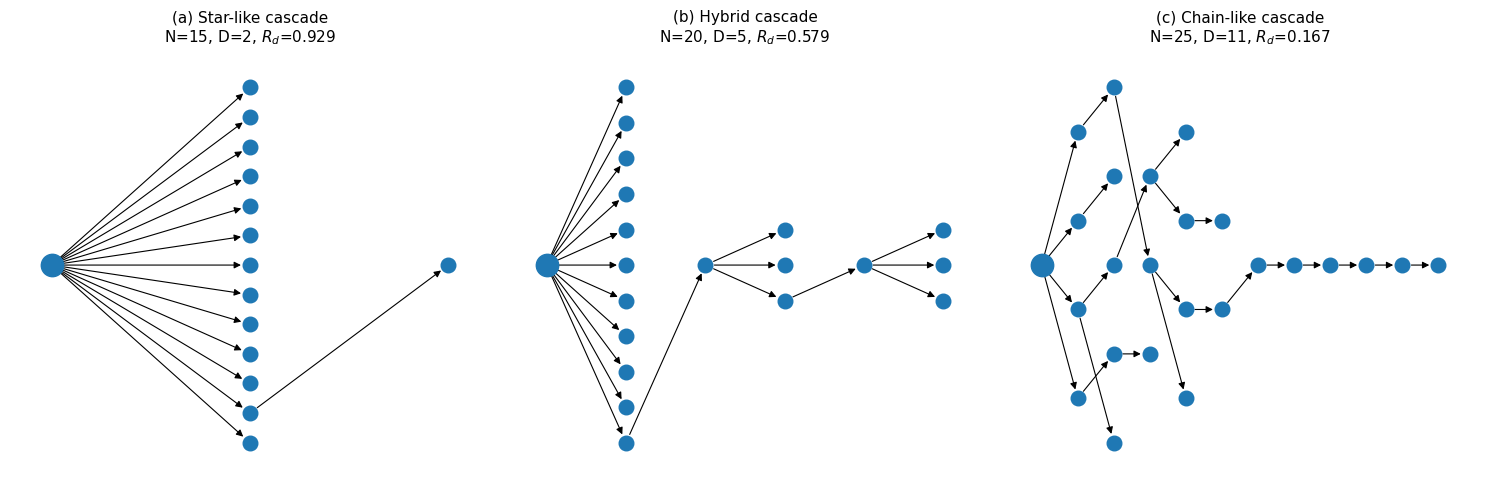

In [ ]:
# ============================================================
# CELL 54 — Preview revised Figure 3
# Actual PHEME cascades verified against frozen results
# NO MODEL TRAINING
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

panel_info = [
    ("star",   "(a) Star-like cascade"),
    ("hybrid", "(b) Hybrid cascade"),
    ("chain",  "(c) Chain-like cascade")
]

for ax, (topology, title) in zip(axes, panel_info):

    result = verified[topology]
    G = result["graph"]
    root = result["root"]

    # Hierarchical layout based on distance from root
    levels = nx.single_source_shortest_path_length(G, root)

    # Group nodes by depth
    level_nodes = {}
    for node, depth in levels.items():
        level_nodes.setdefault(depth, []).append(node)

    # Construct positions:
    # root on left, propagation moving left -> right
    pos = {}

    max_width = max(len(nodes) for nodes in level_nodes.values())

    for depth in sorted(level_nodes.keys()):

        nodes = level_nodes[depth]
        nodes = sorted(nodes)

        count = len(nodes)

        if count == 1:
            ys = [0]
        else:
            ys = [
                i - (count - 1) / 2
                for i in range(count)
            ]

        for node, y in zip(nodes, ys):
            pos[node] = (depth, y)

    # Draw edges
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        arrows=True,
        arrowsize=10,
        width=0.8,
        node_size=170
    )

    # Draw ordinary nodes
    normal_nodes = [
        node for node in G.nodes()
        if node != root
    ]

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=normal_nodes,
        node_size=110,
        ax=ax
    )

    # Make source/root node larger
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[root],
        node_size=260,
        ax=ax
    )

    ax.set_title(
        title +
        f"\nN={result['N']}, "
        f"D={result['D']}, "
        f"$R_d$={result['Rd']:.3f}",
        fontsize=11
    )

    ax.set_axis_off()

plt.tight_layout()
plt.show()

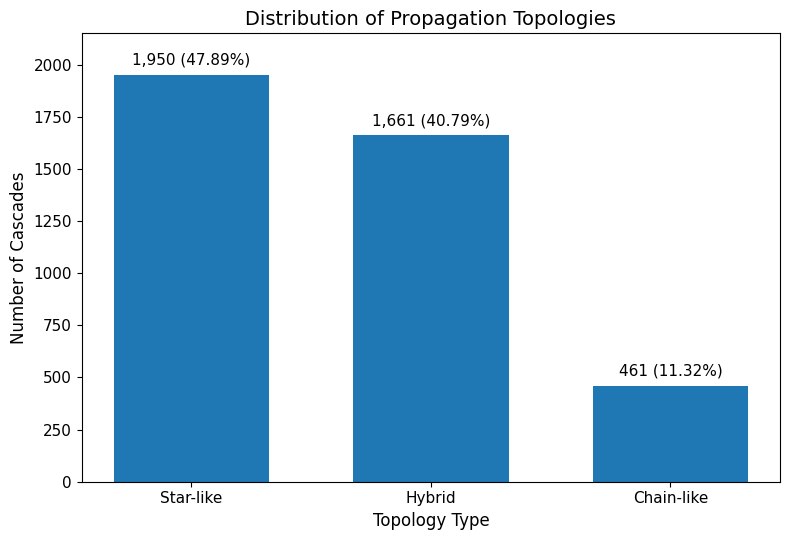

Saved successfully:
/content/drive/MyDrive/PHEME/Final_Revision_Results/Figure4_Topology_Distribution.png
/content/drive/MyDrive/PHEME/Final_Revision_Results/Figure4_Topology_Distribution.pdf

Verification:
Star-like   : 1,950 (47.89%)
Hybrid      : 1,661 (40.79%)
Chain-like  : 461 (11.32%)

Total: 4,072


In [ ]:
# ============================================================
# CELL 55 — Final Figure 4
# Distribution of Propagation Topologies
# ============================================================

import matplotlib.pyplot as plt

# Final verified topology counts
topologies = ["Star-like", "Hybrid", "Chain-like"]
counts = [1950, 1661, 461]

total = sum(counts)
percentages = [(c / total) * 100 for c in counts]

# Create figure
fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.bar(topologies, counts, width=0.65)

# Add count + percentage above each bar
for bar, count, pct in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 35,
        f"{count:,} ({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Labels
ax.set_xlabel("Topology Type", fontsize=12)
ax.set_ylabel("Number of Cascades", fontsize=12)
ax.set_title("Distribution of Propagation Topologies", fontsize=14)

# Give labels enough room above tallest bar
ax.set_ylim(0, 2150)

ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality versions
# ------------------------------------------------------------

output_png = (
    "/content/drive/MyDrive/PHEME/"
    "Final_Revision_Results/Figure4_Topology_Distribution.png"
)

output_pdf = (
    "/content/drive/MyDrive/PHEME/"
    "Final_Revision_Results/Figure4_Topology_Distribution.pdf"
)

plt.savefig(
    output_png,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    output_pdf,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print(output_png)
print(output_pdf)

print("\nVerification:")
for topology, count, pct in zip(topologies, counts, percentages):
    print(f"{topology:12s}: {count:,} ({pct:.2f}%)")

print(f"\nTotal: {total:,}")

In [ ]:
import os

FIG_DIR = "/content/drive/MyDrive/PHEME/Final_Revision_Results/final_manuscript_figures"

os.makedirs(FIG_DIR, exist_ok=True)

print("Figure folder ready:")
print(FIG_DIR)

Figure folder ready:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_manuscript_figures


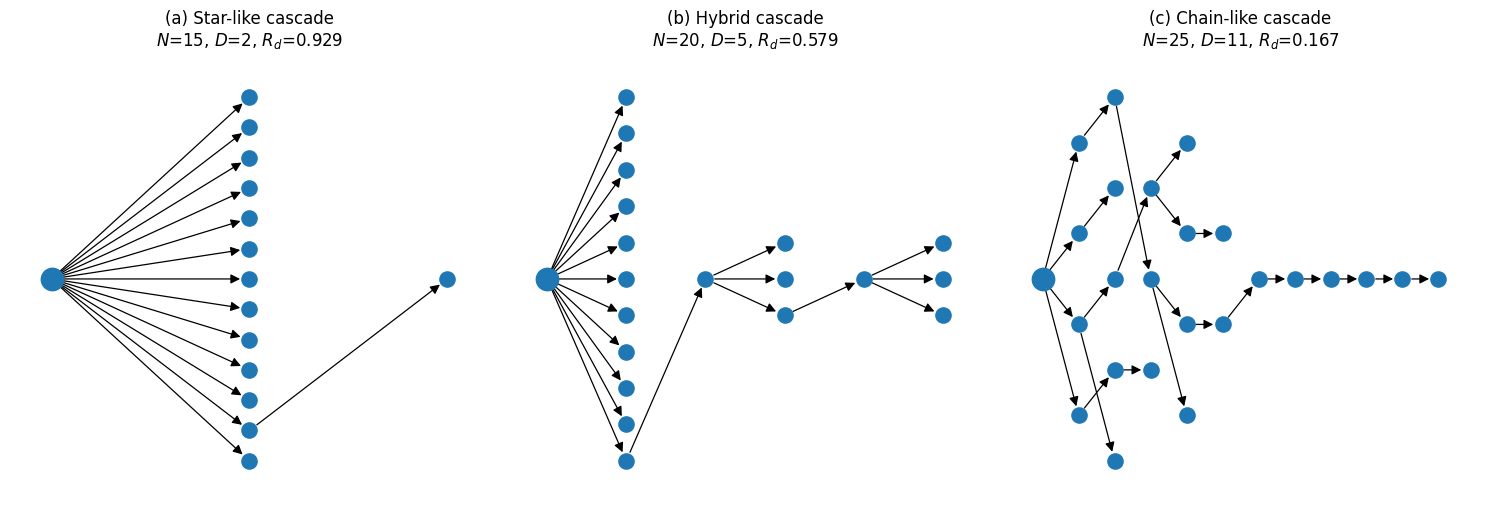


FINAL FIGURE 3 SAVED
PNG : /content/drive/MyDrive/PHEME/Final_Revision_Results/final_manuscript_figures/Figure3_Topology_Examples.png
PDF : /content/drive/MyDrive/PHEME/Final_Revision_Results/final_manuscript_figures/Figure3_Topology_Examples.pdf

Examples used:
Star-like : Sydney Siege | N=15 | D=2 | Rd=0.929
Hybrid    : Charlie Hebdo | N=20 | D=5 | Rd=0.579
Chain-like: Charlie Hebdo | N=25 | D=11 | Rd=0.167

All three graphs were previously verified against final_topology_labels.csv.


In [ ]:
# ============================================================
# CELL 55 — FINAL FIGURE 3
# Representative verified PHEME topology examples
# Saves PNG (600 dpi) + vector PDF
# ============================================================

import os
import matplotlib.pyplot as plt
import networkx as nx

FIG_DIR = (
    "/content/drive/MyDrive/PHEME/"
    "Final_Revision_Results/final_manuscript_figures"
)

os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))

panel_info = [
    ("star",   "(a) Star-like cascade"),
    ("hybrid", "(b) Hybrid cascade"),
    ("chain",  "(c) Chain-like cascade")
]

for ax, (topology, title) in zip(axes, panel_info):

    result = verified[topology]
    G = result["graph"]
    root = result["root"]

    # Distance of every node from the source tweet
    levels = nx.single_source_shortest_path_length(G, root)

    # Group nodes according to propagation depth
    level_nodes = {}

    for node, depth in levels.items():
        level_nodes.setdefault(depth, []).append(node)

    # --------------------------------------------------------
    # Hierarchical left-to-right layout
    # --------------------------------------------------------

    pos = {}

    for depth in sorted(level_nodes.keys()):

        nodes = sorted(level_nodes[depth])
        count = len(nodes)

        if count == 1:
            ys = [0]
        else:
            ys = [
                i - (count - 1) / 2
                for i in range(count)
            ]

        for node, y in zip(nodes, ys):
            pos[node] = (depth, y)

    # --------------------------------------------------------
    # Draw edges
    # --------------------------------------------------------

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        arrows=True,
        arrowsize=14,
        width=0.9,
        node_size=180,
        connectionstyle="arc3,rad=0.0"
    )

    # Ordinary nodes
    normal_nodes = [
        node for node in G.nodes()
        if node != root
    ]

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=normal_nodes,
        node_size=120,
        ax=ax
    )

    # Source/root node
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=[root],
        node_size=260,
        ax=ax
    )

    # --------------------------------------------------------
    # Panel title + verified structural values
    # --------------------------------------------------------

    ax.set_title(
        title +
        f"\n$N$={result['N']}, "
        f"$D$={result['D']}, "
        f"$R_d$={result['Rd']:.3f}",
        fontsize=12,
        pad=10
    )

    ax.set_axis_off()

# Reduce unnecessary white space
plt.tight_layout(w_pad=1.2)

# ------------------------------------------------------------
# Save files
# ------------------------------------------------------------

png_path = os.path.join(
    FIG_DIR,
    "Figure3_Topology_Examples.png"
)

pdf_path = os.path.join(
    FIG_DIR,
    "Figure3_Topology_Examples.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\nFINAL FIGURE 3 SAVED")
print("=" * 70)
print("PNG :", png_path)
print("PDF :", pdf_path)

print("\nExamples used:")
print(
    "Star-like : Sydney Siege | "
    "N=15 | D=2 | Rd=0.929"
)
print(
    "Hybrid    : Charlie Hebdo | "
    "N=20 | D=5 | Rd=0.579"
)
print(
    "Chain-like: Charlie Hebdo | "
    "N=25 | D=11 | Rd=0.167"
)

print("\nAll three graphs were previously verified against "
      "final_topology_labels.csv.")

In [ ]:
# ============================================================
# SECTION 3.5 CHECK — STEP 1
# Locate final structural-metric files and inspect columns
# NO MODEL TRAINING
# ============================================================

import os
import glob
import pandas as pd

BASE = "/content/drive/MyDrive/PHEME/Final_Revision_Results"

print("=" * 75)
print("SECTION 3.5 — FINAL STRUCTURAL DATA CHECK")
print("=" * 75)

# ------------------------------------------------------------
# 1. List CSV files that may contain structural metrics
# ------------------------------------------------------------

csv_files = glob.glob(os.path.join(BASE, "**", "*.csv"), recursive=True)

keywords = [
    "struct",
    "metric",
    "topology",
    "cascade",
    "feature",
    "final"
]

candidate_files = []

for f in csv_files:
    name = os.path.basename(f).lower()
    if any(k in name for k in keywords):
        candidate_files.append(f)

print("\nCandidate CSV files:")
print("-" * 75)

for i, f in enumerate(candidate_files, 1):
    print(f"{i:2d}. {f}")

# ------------------------------------------------------------
# 2. Inspect final_topology_labels.csv first
# ------------------------------------------------------------

topology_path = os.path.join(
    BASE,
    "final_topology_labels.csv"
)

print("\n" + "=" * 75)
print("CHECKING final_topology_labels.csv")
print("=" * 75)

if os.path.exists(topology_path):

    df_top = pd.read_csv(topology_path)

    print("Shape:", df_top.shape)

    print("\nColumns:")
    for col in df_top.columns:
        print(" -", col)

    print("\nFirst 5 rows:")
    display(df_top.head())

    print("\nMissing values:")
    print(df_top.isna().sum())

    print("\nEvent counts:")
    print(df_top["event"].value_counts())

    print("\nLabel counts:")
    print(df_top["label"].value_counts())

else:
    print("ERROR: final_topology_labels.csv not found.")

# ------------------------------------------------------------
# 3. Inspect columns of other candidate CSV files
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CANDIDATE FILE COLUMN CHECK")
print("=" * 75)

for f in candidate_files:

    try:
        temp = pd.read_csv(f, nrows=3)

        print("\nFILE:")
        print(f)

        print("COLUMNS:")
        print(list(temp.columns))

    except Exception as e:
        print("\nCould not read:", f)
        print("Reason:", e)

print("\n" + "=" * 75)
print("STEP 1 COMPLETE — NO STATISTICAL TEST HAS BEEN RUN YET")
print("=" * 75)

SECTION 3.5 — FINAL STRUCTURAL DATA CHECK

Candidate CSV files:
---------------------------------------------------------------------------

CHECKING final_topology_labels.csv
ERROR: final_topology_labels.csv not found.

CANDIDATE FILE COLUMN CHECK

STEP 1 COMPLETE — NO STATISTICAL TEST HAS BEEN RUN YET


In [ ]:
import os
import glob

print("1. Is Drive mounted?")
print(os.path.exists("/content/drive"))

print("\n2. Contents of /content/drive:")
if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive"))

print("\n3. Does MyDrive exist?")
print(os.path.exists("/content/drive/MyDrive"))

print("\n4. Searching Drive for final_topology_labels.csv ...")

matches = glob.glob(
    "/content/drive/**/final_topology_labels.csv",
    recursive=True
)

print("Number of matches:", len(matches))

for m in matches:
    print(m)

1. Is Drive mounted?
True

2. Contents of /content/drive:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

3. Does MyDrive exist?
True

4. Searching Drive for final_topology_labels.csv ...


In [ ]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION
# CELL 1 — Check Google Drive and required files
# ============================================================

import os

base_dir = "/content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1"

results_dir = "/content/drive/MyDrive/PHEME/Final_Revision_Results"

topology_file = os.path.join(
    results_dir,
    "final_topology_labels.csv"
)

figure_dir = os.path.join(
    results_dir,
    "final_manuscript_figures"
)

print("=" * 70)
print("SECTION 3.5 — PATH CHECK")
print("=" * 70)

print("\nPHEME dataset:")
print(base_dir)
print("Exists:", os.path.exists(base_dir))

print("\nFinal results folder:")
print(results_dir)
print("Exists:", os.path.exists(results_dir))

print("\nFrozen topology file:")
print(topology_file)
print("Exists:", os.path.exists(topology_file))

print("\nFinal manuscript figure folder:")
print(figure_dir)
print("Exists:", os.path.exists(figure_dir))

print("\n" + "=" * 70)

if (
    os.path.exists(base_dir)
    and os.path.exists(results_dir)
    and os.path.exists(topology_file)
):
    print("READY — required data locations are accessible.")
else:
    print("STOP — one or more required paths are not accessible.")

SECTION 3.5 — PATH CHECK

PHEME dataset:
/content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1
Exists: True

Final results folder:
/content/drive/MyDrive/PHEME/Final_Revision_Results
Exists: True

Frozen topology file:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_topology_labels.csv
Exists: True

Final manuscript figure folder:
/content/drive/MyDrive/PHEME/Final_Revision_Results/final_manuscript_figures
Exists: True

READY — required data locations are accessible.


In [ ]:
# ============================================================
# SECTION 3.5 FINAL VERIFICATION
# CELL 2 — Reconstruct reply edges from final four PHEME events
# NO MODEL TRAINING
# ============================================================

import os
import json
import pandas as pd

base_dir = "/content/drive/MyDrive/PHEME/all-rnr-annotated-threads_1"

# Final four retained events
RETAINED_EVENTS = {
    "charliehebdo-all-rnr-threads",
    "ferguson-all-rnr-threads",
    "germanwings-crash-all-rnr-threads",
    "sydneysiege-all-rnr-threads"
}


def iter_structure_edges(struct_obj):
    """
    Extract directed parent -> child reply edges
    from the nested PHEME structure.json format.
    """
    edges = []

    def dfs(parent, subtree):
        if isinstance(subtree, dict):
            for child, child_subtree in subtree.items():
                edges.append((str(parent), str(child)))
                dfs(child, child_subtree)

    if isinstance(struct_obj, dict):
        for root, subtree in struct_obj.items():
            dfs(root, subtree)

    return edges


rows = []
failed_files = []

event_folders = [
    f for f in os.listdir(base_dir)
    if os.path.isdir(os.path.join(base_dir, f))
    and not f.startswith("._")
    and f in RETAINED_EVENTS
]

print("Events found:")
for e in sorted(event_folders):
    print(" -", e)


# ------------------------------------------------------------
# Extract all reply edges
# ------------------------------------------------------------

for event in event_folders:

    for label_type in ["rumours", "non-rumours"]:

        label = 1 if label_type == "rumours" else 0

        label_path = os.path.join(
            base_dir,
            event,
            label_type
        )

        if not os.path.exists(label_path):
            continue

        for thread_id in os.listdir(label_path):

            thread_path = os.path.join(
                label_path,
                thread_id
            )

            if (
                not os.path.isdir(thread_path)
                or thread_id.startswith("._")
            ):
                continue

            struct_path = os.path.join(
                thread_path,
                "structure.json"
            )

            if not os.path.exists(struct_path):
                continue

            try:
                with open(
                    struct_path,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:
                    struct_obj = json.load(f)

            except Exception as e:
                failed_files.append(
                    (event, thread_id, str(e))
                )
                continue

            edges = iter_structure_edges(struct_obj)

            for parent, child in edges:

                rows.append({
                    "event": event,
                    "thread_id": str(thread_id),
                    "label": label,
                    "parent_id": str(parent),
                    "child_id": str(child)
                })


df_edges = pd.DataFrame(rows)


# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EDGE RECONSTRUCTION AUDIT")
print("=" * 70)

print("\nTotal edges extracted:",
      len(df_edges))

print(
    "Threads represented in df_edges:",
    df_edges[
        ["event", "thread_id", "label"]
    ].drop_duplicates().shape[0]
)

print(
    "Failed structure.json files:",
    len(failed_files)
)

print("\nEdges by event:")

print(
    df_edges["event"]
    .value_counts()
    .sort_index()
)

print("\nFirst five edges:")
display(df_edges.head())

print("\n" + "=" * 70)
print("CELL 2 COMPLETE")
print("=" * 70)

Events found:
 - charliehebdo-all-rnr-threads
 - ferguson-all-rnr-threads
 - germanwings-crash-all-rnr-threads
 - sydneysiege-all-rnr-threads


KeyboardInterrupt: 